In [ ]:


# ============================================================
# VYRA CORE | AUTHENTICATED BRANCH ZIP DOWNLOAD
# ArqTech Labs
# ============================================================

import os
import io
import zipfile
import requests
from pathlib import Path
from getpass import getpass
from google.colab import files

OWNER = "edu-moraess"
REPO = "vyra-core"
BRANCH = "feat/core-contract-foundation"

DOWNLOAD_DIR = Path("/content/Downloads")
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = DOWNLOAD_DIR / "vyra-core-feat-core-contract-foundation.zip"

print("=" * 65)
print("VYRA CORE | BRANCH DOWNLOAD")
print("=" * 65)

# 1. Autenticação
print("\n[1/5] Autenticação GitHub")
print("Se o repositório for privado, informe um token")
print("com permissão Contents: Read Only.")
print("Se for público, basta pressionar Enter.")

TOKEN = getpass("GitHub token (não será exibido): ").strip()

HEADERS = {
    "Accept": "application/vnd.github+json",
    "X-GitHub-Api-Version": "2022-11-28"
}

if TOKEN:
    HEADERS["Authorization"] = f"Bearer {TOKEN}"

# 2. Verificar branch e obter SHA
print("\n[2/5] Verificando branch...")

API_URL = (
    f"https://api.github.com/repos/"
    f"{OWNER}/{REPO}/branches/{BRANCH}"
)

response = requests.get(
    API_URL,
    headers=HEADERS,
    timeout=30
)

if response.status_code == 404:
    raise RuntimeError(
        "Branch não encontrada ou repositório inacessível. "
        "Verifique o token e as permissões."
    )

response.raise_for_status()

branch_data = response.json()
COMMIT_SHA = branch_data["commit"]["sha"]

print("Branch:", BRANCH)
print("Commit:", COMMIT_SHA)

# 3. Baixar ZIP da branch
print("\n[3/5] Baixando ZIP do GitHub...")

ZIP_URL = (
    f"https://api.github.com/repos/"
    f"{OWNER}/{REPO}/zipball/{BRANCH}"
)

response = requests.get(
    ZIP_URL,
    headers=HEADERS,
    timeout=180
)

response.raise_for_status()

content = response.content

if not content.startswith(b"PK"):
    raise RuntimeError(
        "A resposta não parece ser um arquivo ZIP válido."
    )

# 4. Validar integridade e salvar
print("\n[4/5] Validando e salvando arquivo...")

with zipfile.ZipFile(io.BytesIO(content)) as archive:
    bad_file = archive.testzip()

    if bad_file:
        raise RuntimeError(
            f"Arquivo ZIP corrompido: {bad_file}"
        )

ZIP_PATH.write_bytes(content)

print("ZIP íntegro: SIM")
print("Tamanho: {:.2f} MB".format(len(content) / 1024**2))
print("Arquivo:", ZIP_PATH)
print("SHA do commit:", COMMIT_SHA)

# 5. Baixar para o dispositivo
print("\n[5/5] Enviando arquivo para download...")

assert ZIP_PATH.exists(), "ZIP não encontrado."

files.download(str(ZIP_PATH))

print("\n" + "=" * 65)
print("DOWNLOAD PREPARADO COM SUCESSO")
print("=" * 65)

VYRA CORE | BRANCH DOWNLOAD

[1/5] Autenticação GitHub
Se o repositório for privado, informe um token
com permissão Contents: Read Only.
Se for público, basta pressionar Enter.
GitHub token (não será exibido): ··········

[2/5] Verificando branch...
Branch: feat/core-contract-foundation
Commit: 510945ec8d5642de205646450373220ee9cf9f05

[3/5] Baixando ZIP do GitHub...

[4/5] Validando e salvando arquivo...
ZIP íntegro: SIM
Tamanho: 0.02 MB
Arquivo: /content/Downloads/vyra-core-feat-core-contract-foundation.zip
SHA do commit: 510945ec8d5642de205646450373220ee9cf9f05

[5/5] Enviando arquivo para download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


DOWNLOAD PREPARADO COM SUCESSO


In [ ]:


# ============================================================
# VYRA CORE | MANUAL VALIDATION
# Extração segura + instalação + testes
# ============================================================

import sys
import zipfile
import subprocess
from pathlib import Path

ZIP = Path(
    "/content/Downloads/"
    "vyra-core-feat-core-contract-foundation.zip"
)

COMMIT = "510945ec8d5642de205646450373220ee9cf9f05"

print("=" * 65)
print("VYRA CORE | VALIDATION")
print("=" * 65)

assert ZIP.is_file(), f"ZIP não encontrado: {ZIP}"

# 1. Validar conteúdo
print("\n[1/6] Inspecionando ZIP...")

with zipfile.ZipFile(ZIP) as z:
    bad = z.testzip()
    assert bad is None, f"ZIP corrompido: {bad}"

    names = z.namelist()
    assert names, "ZIP vazio"

    for name in names:
        p = Path(name)
        assert not p.is_absolute()
        assert ".." not in p.parts, f"Caminho inseguro: {name}"

print("Arquivos no ZIP:", len(names))

# 2. Extrair em diretório exclusivo
print("\n[2/6] Extração segura...")

DEST = Path(f"/content/vyra_core_validation_{COMMIT[:8]}")
assert not DEST.exists(), f"Diretório já existe: {DEST}"

DEST.mkdir(parents=True)

with zipfile.ZipFile(ZIP) as z:
    z.extractall(DEST)

# Localizar raiz do projeto
roots = list(DEST.rglob("pyproject.toml"))
assert len(roots) == 1, f"Esperado 1 pyproject.toml; encontrados: {len(roots)}"

REPO = roots[0].parent

print("Raiz:", REPO)

# 3. Conferir estrutura esperada
print("\n[3/6] Conferindo arquivos...")

required = [
    "pyproject.toml",
    "src/vyra_core/__init__.py",
    "src/vyra_core/contracts/temporal.py",
    "src/vyra_core/contracts/spatial.py",
    "src/vyra_core/contracts/provenance.py",
    "src/vyra_core/contracts/envelope.py",
    "tests/contracts/test_contracts.py",
    "tests/validation/test_compatibility.py",
]

missing = [f for f in required if not (REPO / f).is_file()]

for f in required:
    print(("OK   " if (REPO / f).is_file() else "FALTA ") + f)

assert not missing, f"Arquivos ausentes: {missing}"

# 4. Instalar em modo editável
print("\n[4/6] Instalando dependências de desenvolvimento...")

install = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", ".[dev]"],
    cwd=REPO,
    text=True
)

if install.returncode != 0:
    raise RuntimeError("Falha na instalação.")

# 5. Compilação
print("\n[5/6] Compileall...")

compile_result = subprocess.run(
    [sys.executable, "-m", "compileall", "-q", "src", "tests"],
    cwd=REPO
)

print("Compileall:", "PASS" if compile_result.returncode == 0 else "FAIL")
assert compile_result.returncode == 0

# 6. Testes
print("\n[6/6] Executando pytest...")

test_result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=REPO
)

print("\n" + "=" * 65)
print("RESULTADO FINAL")
print("=" * 65)
print("Commit:", COMMIT)
print("Estrutura: PASS")
print("Instalação: PASS")
print("Compileall: PASS" if compile_result.returncode == 0 else "Compileall: FAIL")
print("Pytest:", "PASS" if test_result.returncode == 0 else "FAIL")

if test_result.returncode != 0:
    print("\nVALIDAÇÃO REPROVADA — investigar falhas.")
else:
    print("\nVALIDAÇÃO APROVADA — testes concluídos.")

print("Diretório:", REPO)

VYRA CORE | VALIDATION

[1/6] Inspecionando ZIP...
Arquivos no ZIP: 32

[2/6] Extração segura...
Raiz: /content/vyra_core_validation_510945ec/edu-moraess-vyra-core-510945ec8d5642de205646450373220ee9cf9f05

[3/6] Conferindo arquivos...
OK   pyproject.toml
OK   src/vyra_core/__init__.py
OK   src/vyra_core/contracts/temporal.py
OK   src/vyra_core/contracts/spatial.py
OK   src/vyra_core/contracts/provenance.py
OK   src/vyra_core/contracts/envelope.py
OK   tests/contracts/test_contracts.py
OK   tests/validation/test_compatibility.py

[4/6] Instalando dependências de desenvolvimento...

[5/6] Compileall...
Compileall: PASS

[6/6] Executando pytest...

RESULTADO FINAL
Commit: 510945ec8d5642de205646450373220ee9cf9f05
Estrutura: PASS
Instalação: PASS
Compileall: PASS
Pytest: PASS

VALIDAÇÃO APROVADA — testes concluídos.
Diretório: /content/vyra_core_validation_510945ec/edu-moraess-vyra-core-510945ec8d5642de205646450373220ee9cf9f05


In [ ]:


import os
import requests
import zipfile
from pathlib import Path

REPO = "edu-moraess/vyra-core"
BRANCH = "feat/core-contract-foundation"

token = os.environ.get("GITHUB_TOKEN")

if not token:
    from getpass import getpass
    token = getpass("GitHub Fine-grained token: ")

headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github+json"
}

# 1. Consultar HEAD atual
url = f"https://api.github.com/repos/{REPO}/branches/{BRANCH}"
response = requests.get(url, headers=headers, timeout=30)
response.raise_for_status()

sha = response.json()["commit"]["sha"]
print("HEAD atual:", sha)

# 2. Baixar ZIP da branch
zip_url = f"https://api.github.com/repos/{REPO}/zipball/{BRANCH}"
response = requests.get(zip_url, headers=headers, timeout=60)
response.raise_for_status()

output = Path("/content/vyra_core_latest.zip")
output.write_bytes(response.content)

# 3. Verificar integridade
with zipfile.ZipFile(output, "r") as archive:
    bad_file = archive.testzip()
    assert bad_file is None, f"ZIP corrompido: {bad_file}"
    entries = archive.namelist()

print("ZIP:", output)
print("Tamanho:", round(output.stat().st_size / 1024, 2), "KB")
print("Entradas:", len(entries))
print("Integridade: PASS")

assert any(name.endswith("/pyproject.toml") for name in entries)
print("Estrutura básica: PASS")

# 4. Baixar para seu dispositivo
from google.colab import files
files.download(str(output))

GitHub Fine-grained token: ··········
HEAD atual: b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11
ZIP: /content/vyra_core_latest.zip
Tamanho: 26.19 KB
Entradas: 34
Integridade: PASS
Estrutura básica: PASS


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os
import sys
import shutil
import zipfile
import subprocess
import compileall
from pathlib import Path

ZIP = Path("/content/vyra_core_latest.zip")
DEST = Path("/content/vyra_core_validation")
EXPECTED_HEAD = "b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11"

print("=" * 65)
print("VYRA CORE | MANUAL VALIDATION")
print("=" * 65)

# 1. Extração limpa
if DEST.exists():
    shutil.rmtree(DEST)

DEST.mkdir(parents=True)

with zipfile.ZipFile(ZIP) as z:
    z.extractall(DEST)

projects = list(DEST.rglob("pyproject.toml"))
assert projects, "FAIL: pyproject.toml não encontrado"

PROJECT = projects[0].parent
os.chdir(PROJECT)

print("\n[1/6] Estrutura")
print("Project:", PROJECT)
print("PASS")

# 2. Instalação
print("\n[2/6] Instalação editável")
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", ".[dev]"],
    check=True
)
print("PASS")

# 3. Compilação
print("\n[3/6] Compileall")
compiled = compileall.compile_dir(
    str(PROJECT / "src"),
    quiet=1
)
assert compiled, "FAIL: erro de compilação"
print("PASS")

# 4. Testes
print("\n[4/6] Pytest")
result = subprocess.run(
    [sys.executable, "-m", "pytest", "-v"],
    text=True
)
assert result.returncode == 0, "FAIL: pytest"
print("PASS")

# 5. Importação
print("\n[5/6] Importação")
import vyra_core
print("Module:", vyra_core.__file__)
print("PASS")

# 6. Relatório
print("\n[6/6] Resultado")
print("Expected HEAD:", EXPECTED_HEAD)
print("ZIP size:", ZIP.stat().st_size)
print("Python:", sys.version)
print("Working directory:", os.getcwd())

print("\n" + "=" * 65)
print("VALIDATION COMPLETE")
print("=" * 65)

VYRA CORE | MANUAL VALIDATION

[1/6] Estrutura
Project: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11
PASS

[2/6] Instalação editável
PASS

[3/6] Compileall
PASS

[4/6] Pytest
PASS

[5/6] Importação


ModuleNotFoundError: No module named 'vyra_core'

In [ ]:

import os
import sys
import importlib.util
import importlib.metadata as metadata
from pathlib import Path

PROJECT = Path("/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11")

print("DIRETÓRIO:", os.getcwd())
print("PROJETO EXISTE:", PROJECT.exists())
print("PACOTE EXISTE:", (PROJECT / "src/vyra_core/__init__.py").exists())

print("\n[1] DISTRIBUIÇÃO INSTALADA")
try:
    dist = metadata.distribution("vyra-core")
    print("Versão:", dist.version)
    print("Local:", dist.locate_file(""))
except metadata.PackageNotFoundError:
    print("FAIL: distribuição vyra-core não encontrada")

print("\n[2] DESCOBERTA DO MÓDULO")
print("find_spec:", importlib.util.find_spec("vyra_core"))

print("\n[3] CAMINHO SRC")
print("src existe:", (PROJECT / "src").exists())
print("src no sys.path:", str(PROJECT / "src") in sys.path)

print("\n[4] TESTE CONTROLADO DE IMPORTAÇÃO")
sys.path.insert(0, str(PROJECT / "src"))

try:
    import vyra_core
    print("IMPORT PASS:", vyra_core.__file__)
except Exception as e:
    print("IMPORT FAIL:", repr(e))

DIRETÓRIO: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11
PROJETO EXISTE: True
PACOTE EXISTE: True

[1] DISTRIBUIÇÃO INSTALADA
Versão: 0.1.0
Local: /usr/local/lib/python3.13/dist-packages

[2] DESCOBERTA DO MÓDULO
find_spec: None

[3] CAMINHO SRC
src existe: True
src no sys.path: False

[4] TESTE CONTROLADO DE IMPORTAÇÃO
IMPORT PASS: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py


In [ ]:

import sys
import subprocess
import importlib.metadata as md
from pathlib import Path

print("=== INSTALAÇÃO ===")
subprocess.run([sys.executable, "-m", "pip", "show", "-f", "vyra-core"])

print("\n=== METADADOS ===")
dist = md.distribution("vyra-core")

print("Versão:", dist.version)
print("Arquivos registrados:")
for f in (dist.files or []):
    print(f)

print("\n=== CONFIGURAÇÃO SETUPTOOLS ===")
from setuptools import find_packages

PROJECT = Path.cwd()
print("Pacotes encontrados:", find_packages(where=str(PROJECT / "src")))

print("\n=== CAMINHOS ===")
for p in sys.path:
    print(p)

=== INSTALAÇÃO ===

=== METADADOS ===
Versão: 0.1.0
Arquivos registrados:

=== CONFIGURAÇÃO SETUPTOOLS ===
Pacotes encontrados: ['vyra_core', 'vyra_core.validation', 'vyra_core.contracts', 'vyra_core.adapters']

=== CAMINHOS ===
/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src
/content
/env/python
/usr/lib/python313.zip
/usr/lib/python3.13
/usr/lib/python3.13/lib-dynload

/usr/local/lib/python3.13/dist-packages
/usr/lib/python3/dist-packages
/usr/local/lib/python3.13/dist-packages/IPython/extensions
/root/.ipython
/usr/local/lib/python3.13/dist-packages/setuptools/_vendor


In [ ]:

import sys
import importlib.util
import importlib.metadata as md
from pathlib import Path

print("=== 1. DESCOBERTA DO MÓDULO ===")
spec = importlib.util.find_spec("vyra_core")
print("find_spec:", spec)
print("origin:", spec.origin if spec else None)

print("\n=== 2. IMPORTAÇÃO ===")
try:
    import vyra_core
    print("IMPORT: PASS")
    print("Arquivo:", vyra_core.__file__)
except Exception as e:
    print("IMPORT: FAIL")
    print(type(e).__name__, str(e))

print("\n=== 3. METADADOS DA DISTRIBUIÇÃO ===")
dist = md.distribution("vyra-core")
print("Versão:", dist.version)
print("Diretório:", dist._path)
print("direct_url.json:", dist.read_text("direct_url.json"))
print("top_level.txt:", dist.read_text("top_level.txt"))
print("RECORD:", dist.read_text("RECORD"))

print("\n=== 4. ARQUIVOS DE INSTALAÇÃO EDITÁVEL ===")
site_packages = Path(dist._path).parent
for pattern in ("__editable__*", "*.pth"):
    for p in site_packages.glob(pattern):
        print(f"\n--- {p.name} ---")
        try:
            print(p.read_text(errors="replace")[:5000])
        except Exception as e:
            print("Não foi possível ler:", e)

print("\n=== 5. CAMINHO DO CÓDIGO ===")
print("src existe:", Path("src/vyra_core/__init__.py").exists())
print("src no sys.path:", str(Path("src").resolve()) in sys.path)

=== 1. DESCOBERTA DO MÓDULO ===
find_spec: ModuleSpec(name='vyra_core', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7eaacc0e6e10>, origin='/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py', submodule_search_locations=['/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core'])
origin: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py

=== 2. IMPORTAÇÃO ===
IMPORT: PASS
Arquivo: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py

=== 3. METADADOS DA DISTRIBUIÇÃO ===
Versão: 0.1.0
Diretório: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core.egg-info
direct_url.json: None
top_level.txt: vyra_core

RECORD: None

=== 4. ARQUIVOS DE INSTALAÇÃO EDITÁVEL ===

=== 5

In [ ]:

import subprocess
import sys
from pathlib import Path

PROJECT = Path.cwd()

print("=== PIP / SETUPTOOLS ===")
subprocess.run([
    sys.executable, "-m", "pip", "show", "setuptools"
])

print("\n=== BUILD EDITÁVEL EM MODO VERBOSO ===")
result = subprocess.run(
    [sys.executable, "-m", "pip", "install",
     "-e", ".", "--no-deps", "-v"],
    cwd=PROJECT,
    capture_output=True,
    text=True
)

print("RETURN CODE:", result.returncode)
print("\nSTDOUT:")
print(result.stdout[-10000:])
print("\nSTDERR:")
print(result.stderr[-10000:])

=== PIP / SETUPTOOLS ===

=== BUILD EDITÁVEL EM MODO VERBOSO ===
RETURN CODE: 0

STDOUT:
Using pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
Obtaining file:///content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for vyra-core (pyproject.toml): started
  Building editable for vyra-core (pyproject.toml): finished with status 'done'
  Created wheel for vyra-core: filename=vyra_core-0.1.0-0.editable-py3-none-any.whl s

In [ ]:

import subprocess
import sys

code = """
import sys
import importlib.util
import vyra_core

print("PYTHON:", sys.executable)
print("MODULE:", importlib.util.find_spec("vyra_core"))
print("FILE:", vyra_core.__file__)
print("IMPORT: PASS")
"""

result = subprocess.run(
    [sys.executable, "-c", code],
    capture_output=True,
    text=True
)

print("RETURN CODE:", result.returncode)
print(result.stdout)
print(result.stderr)

RETURN CODE: 0
PYTHON: /usr/bin/python3
MODULE: ModuleSpec(name='vyra_core', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7d3e013f3f50>, origin='/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py', submodule_search_locations=['/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core'])
FILE: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py
IMPORT: PASS




In [ ]:

%cd /content

!rm -rf vyra-core

!git clone --depth 1 \
  --branch feat/roboqa-gps-producer-adapter \
  https://github.com/edu-moraess/vyra-core.git

%cd /content/vyra-core

!python -m pip install -e ".[dev]"

!python -m compileall -q src tests

!pytest -q

/content
Cloning into 'vyra-core'...
fatal: could not read Username for 'https://github.com': No such device or address
[Errno 2] No such file or directory: '/content/vyra-core'
/content
Obtaining file:///content
ERROR: file:///content does not appear to be a Python project: neither 'setup.py' nor 'pyproject.toml' found.
Can't list 'src'
Can't list 'tests'

==================================== ERRORS ====================================
_ ERROR collecting vyra_core_validation_510945ec/edu-moraess-vyra-core-510945ec8d5642de205646450373220ee9cf9f05/tests/contracts/test_contracts.py _
import file mismatch:
imported module 'test_contracts' has this __file__ attribute:
  /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/tests/contracts/test_contracts.py
which is not the same as the test file we want to collect:
  /content/vyra_core_validation_510945ec/edu-moraess-vyra-core-510945ec8d5642de205646450373220ee9cf9f05/tests/contracts/test_contracts.py
H

In [ ]:

import os
import shutil
import subprocess
import getpass
import base64

REPO = "https://github.com/edu-moraess/vyra-core.git"
BRANCH = "feat/roboqa-gps-producer-adapter"
DIR = "/content/vyra-core-pr2"

token = getpass.getpass("GitHub token (não será exibido): ").strip()

if not token:
    raise RuntimeError("Token não informado.")

# Autenticação sem colocar o token na URL ou no histórico de comandos.
auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

env = os.environ.copy()
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.extraheader"
env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth}"

# Diretório isolado para evitar conflitos com auditorias antigas.
if os.path.exists(DIR):
    shutil.rmtree(DIR)

def run(cmd, cwd=None):
    print("\n$", " ".join(cmd))
    result = subprocess.run(
        cmd,
        cwd=cwd,
        env=env,
        text=True
    )
    if result.returncode != 0:
        raise RuntimeError(
            f"Comando falhou ({result.returncode}). "
            "Validação interrompida."
        )

# 1. Clone
run([
    "git", "clone",
    "--depth", "1",
    "--branch", BRANCH,
    REPO,
    DIR
])

# 2. Confirmar branch e commit
run(["git", "status", "--short", "--branch"], cwd=DIR)
run(["git", "rev-parse", "HEAD"], cwd=DIR)

# 3. Instalação
run([
    "python", "-m", "pip",
    "install", "-e", ".[dev]"
], cwd=DIR)

# 4. Compilação
run([
    "python", "-m", "compileall",
    "-q", "src", "tests"
], cwd=DIR)

# 5. Testes somente deste repositório
run([
    "python", "-m", "pytest",
    "-q", "tests"
], cwd=DIR)

print("\nVALIDAÇÃO FINALIZADA.")

GitHub token (não será exibido): ··········

$ git clone --depth 1 --branch feat/roboqa-gps-producer-adapter https://github.com/edu-moraess/vyra-core.git /content/vyra-core-pr2

$ git status --short --branch

$ git rev-parse HEAD

$ python -m pip install -e .[dev]

$ python -m compileall -q src tests

$ python -m pytest -q tests

VALIDAÇÃO FINALIZADA.


In [ ]:

import subprocess

REPO_DIR = "/content/vyra-core-pr2"

def run(cmd):
    return subprocess.run(
        cmd,
        cwd=REPO_DIR,
        check=True,
        text=True
    )

print("BRANCH:")
run(["git", "branch", "--show-current"])

print("\nHEAD:")
run(["git", "rev-parse", "HEAD"])

print("\nSTATUS:")
run(["git", "status", "--short", "--branch"])

print("\nTESTES:")
run(["python", "-m", "pytest", "-v", "tests"])

BRANCH:

HEAD:

STATUS:

TESTES:


CompletedProcess(args=['python', '-m', 'pytest', '-v', 'tests'], returncode=0)

In [ ]:

import subprocess
from pathlib import Path

repo = Path("/content/vyra-core-pr2")

if not repo.is_dir():
    raise RuntimeError(f"Repositório não encontrado: {repo}")

def check(label, command):
    result = subprocess.run(
        command,
        cwd=str(repo),
        capture_output=True,
        text=True
    )
    print(f"\n{label} | código: {result.returncode}")
    print(result.stdout)
    if result.stderr:
        print("STDERR:", result.stderr)
    if result.returncode != 0:
        raise RuntimeError(f"Falha em: {label}")

check("BRANCH", ["git", "branch", "--show-current"])
check("HEAD", ["git", "rev-parse", "HEAD"])
check("STATUS", ["git", "status", "--short", "--branch"])
check("PYTEST", ["python", "-m", "pytest", "-v", "tests"])


BRANCH | código: 0
feat/roboqa-gps-producer-adapter


HEAD | código: 0
1a397d87104d8ddc0f33a8af4ebba5367e8aa8d9


STATUS | código: 0
## feat/roboqa-gps-producer-adapter...origin/feat/roboqa-gps-producer-adapter
?? src/vyra_core.egg-info/
?? src/vyra_core/__pycache__/
?? src/vyra_core/adapters/__pycache__/
?? src/vyra_core/contracts/__pycache__/
?? src/vyra_core/validation/__pycache__/
?? tests/adapters/__pycache__/
?? tests/contracts/__pycache__/
?? tests/validation/__pycache__/


PYTEST | código: 0
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0
rootdir: /content/vyra-core-pr2
configfile: pyproject.toml
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collected 19 items

tests/adapters/test_roboqa_producer.py ......                            [ 31%]
tests/contracts/test_contracts.py ............                           [ 94%]
tests/validation/test_compatibilit

In [ ]:

import os
import subprocess
import sys

REPO = "https://github.com/edu-moraess/sensor-fusion-ml.git"
BRANCH = "feat/vyra-core-roboqa-gnss-consumer"
DEST = "/content/sensor-fusion-ml-vyra-validation"

def run(cmd):
    print("\n$", " ".join(cmd))
    subprocess.run(cmd, check=True, cwd=DEST)

if not os.path.exists(DEST):
    subprocess.run(
        ["git", "clone", "--branch", BRANCH, "--single-branch", REPO, DEST],
        check=True
    )

run(["git", "rev-parse", "HEAD"])
run([sys.executable, "-m", "pip", "install", "-e", ".", "--no-deps"])
run([sys.executable, "-m", "compileall", "-q", "src", "tests"])
run([
    sys.executable, "-m", "pytest", "-q",
    "tests/unit/test_vyra_core_integration.py"
])
run([sys.executable, "-m", "pytest", "-q"])

print("\nVALIDAÇÃO FINALIZADA")


$ git rev-parse HEAD

$ /usr/bin/python3 -m pip install -e . --no-deps

$ /usr/bin/python3 -m compileall -q src tests

$ /usr/bin/python3 -m pytest -q tests/unit/test_vyra_core_integration.py

$ /usr/bin/python3 -m pytest -q

VALIDAÇÃO FINALIZADA


In [ ]:

import os
import subprocess
import sys

DEST = "/content/sensor-fusion-ml-vyra-validation"

assert os.path.isdir(os.path.join(DEST, ".git")), (
    f"Repositório não encontrado em {DEST}"
)

os.chdir(DEST)
print("DIRETÓRIO:", os.getcwd())

commands = [
    ["git", "branch", "--show-current"],
    ["git", "rev-parse", "HEAD"],
    [sys.executable, "-m", "pytest", "-v",
     "tests/unit/test_vyra_core_integration.py"],
    [sys.executable, "-m", "pytest", "-v"],
]

for cmd in commands:
    print("\n$", " ".join(cmd))
    result = subprocess.run(cmd, text=True, capture_output=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    print("EXIT CODE:", result.returncode)

    if result.returncode != 0:
        raise RuntimeError("Validação reprovada.")

DIRETÓRIO: /content/sensor-fusion-ml-vyra-validation

$ git branch --show-current
feat/vyra-core-roboqa-gnss-consumer

EXIT CODE: 0

$ git rev-parse HEAD
f8b3736231928a7658174a6fbd68a7d6bc77190c

EXIT CODE: 0

$ /usr/bin/python3 -m pytest -v tests/unit/test_vyra_core_integration.py
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/sensor-fusion-ml-vyra-validation
configfile: pyproject.toml
plugins: langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collecting ... collected 10 items

tests/unit/test_vyra_core_integration.py::test_converts_local_metric_gps_and_preserves_covariance PASSED [ 10%]
tests/unit/test_vyra_core_integration.py::test_rejects_geographic_coordinates PASSED [ 20%]
tests/unit/test_vyra_core_integration.py::test_rejects_incomplete_spatial_reference[axis_order-value0] PASSED [ 30%]
tests/unit/test_vy

In [ ]:


import subprocess

repos = {
    "roboqa": "https://github.com/edu-moraess/roboqa-lab.git",
    "core": "https://github.com/edu-moraess/vyra-core.git",
    "fusion": "https://github.com/edu-moraess/sensor-fusion-ml.git",
}

for name, url in repos.items():
    result = subprocess.run(
        ["git", "ls-remote", url, "refs/heads/main"],
        capture_output=True,
        text=True
    )

    print(f"\n{name.upper()}")
    print("EXIT:", result.returncode)
    print("OUTPUT:", result.stdout.strip() or result.stderr.strip())


ROBOQA
EXIT: 0
OUTPUT: 7d8e77df75da236db2dc8c7199a146f12696ecb4	refs/heads/main

CORE
EXIT: 128
OUTPUT: fatal: could not read Username for 'https://github.com': No such device or address

FUSION
EXIT: 0
OUTPUT: fd4ff9ef40469023487be0571e44886fb6330088	refs/heads/main


In [ ]:


# ================================================================
# VYRA ECOSYSTEM | ROBOQA -> VYRA CORE -> SENSOR FUSION ML
# ONE-CELL MANUAL VALIDATION + TECHNICAL VISUAL REPORT
#
# Downloads:
#   edu-moraess/roboqa-lab
#   edu-moraess/vyra-core       (private: GitHub token required)
#   edu-moraess/sensor-fusion-ml
#
# Outputs:
#   4 PNG charts + CSV + JSON + ZIP
#
# No training, no model download, no GitHub writes.
# ================================================================

import os
import sys
import json
import math
import shutil
import zipfile
import base64
import getpass
import subprocess
import importlib.util
from pathlib import Path
from datetime import datetime, timezone

# ---------------- CONFIGURATION ----------------

BASE = Path("/content/vyra_visual_validation")
REPOS = {
    "roboqa": "https://github.com/edu-moraess/roboqa-lab.git",
    "core": "https://github.com/edu-moraess/vyra-core.git",
    "fusion": "https://github.com/edu-moraess/sensor-fusion-ml.git",
}

N = 80
OUTPUT = BASE / "artifacts"
OUTPUT.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("VYRA ECOSYSTEM | MANUAL VALIDATION")
print("=" * 72)

# ---------------- UTILITIES ----------------

def run(cmd, cwd=None, env=None, check=True):
    result = subprocess.run(
        cmd,
        cwd=str(cwd) if cwd else None,
        env=env,
        text=True,
        capture_output=True
    )
    print("\n$", " ".join(map(str, cmd)))
    if result.stdout.strip():
        print(result.stdout[-5000:])
    if result.stderr.strip():
        print(result.stderr[-3000:])
    print("EXIT:", result.returncode)

    if check and result.returncode != 0:
        raise RuntimeError(
            f"Command failed with exit code {result.returncode}: {cmd}"
        )
    return result


def git_head(path):
    return run(
        ["git", "rev-parse", "HEAD"],
        cwd=path
    ).stdout.strip()


# ---------------- 1. AUTHENTICATION ----------------

print("\n[1/10] GitHub authentication")

token = None

try:
    from google.colab import userdata
    try:
        token = userdata.get("GITHUB_TOKEN")
    except Exception:
        token = None
except Exception:
    pass

if not token:
    print(
        "Vyra Core requer autenticação. "
        "Informe um GitHub PAT com Contents: Read-only."
    )
    token = getpass.getpass("GitHub token (entrada oculta): ").strip()

if not token:
    raise RuntimeError("Token não informado. Não é possível baixar Vyra Core.")

# Header temporário para o Git. O token não será impresso.
auth_value = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

git_env = os.environ.copy()
git_env["GIT_CONFIG_COUNT"] = "1"
git_env["GIT_CONFIG_KEY_0"] = "http.extraheader"
git_env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth_value}"

# Não manter o token em variáveis após preparar o ambiente.
del auth_value
del token

# ---------------- 2. DOWNLOAD REPOSITORIES ----------------

print("\n[2/10] Download dos três repositórios")

BASE.mkdir(parents=True, exist_ok=True)

repo_paths = {
    name: BASE / name
    for name in REPOS
}

# Recria somente as pastas de trabalho deste script.
for path in repo_paths.values():
    if path.exists():
        shutil.rmtree(path)

# RoboQA e Sensor Fusion são públicos.
for name in ("roboqa", "fusion"):
    run(
        [
            "git", "clone", "--depth", "1",
            "--branch", "main",
            REPOS[name],
            str(repo_paths[name])
        ]
    )

# Vyra Core é privado: autenticação via header temporário.
run(
    [
        "git", "clone", "--depth", "1",
        "--branch", "main",
        REPOS["core"],
        str(repo_paths["core"])
    ],
    env=git_env
)

# Limpa variáveis temporárias de autenticação.
for key in (
    "GIT_CONFIG_COUNT",
    "GIT_CONFIG_KEY_0",
    "GIT_CONFIG_VALUE_0"
):
    git_env.pop(key, None)

del git_env

# ---------------- 3. RECORD SOURCE VERSIONS ----------------

print("\n[3/10] Registro das versões")

source_versions = {}

for name, path in repo_paths.items():
    source_versions[name] = {
        "branch": run(
            ["git", "branch", "--show-current"],
            cwd=path
        ).stdout.strip(),
        "commit": git_head(path),
        "remote": REPOS[name]
    }

print(json.dumps(source_versions, indent=2))

# ---------------- 4. DEPENDENCIES ----------------

print("\n[4/10] Dependências básicas")

run([
    sys.executable, "-m", "pip", "install", "-q",
    "numpy<3", "matplotlib", "pytest"
])

# Instala os dois pacotes Python sem resolver dependências
# adicionais ou iniciar downloads de modelos.
run([
    sys.executable, "-m", "pip", "install",
    "-q", "-e", str(repo_paths["core"]), "--no-deps"
])

run([
    sys.executable, "-m", "pip", "install",
    "-q", "-e", str(repo_paths["fusion"]), "--no-deps"
])

# RoboQA será importado diretamente da raiz do repositório.
sys.path.insert(0, str(repo_paths["roboqa"]))

# ---------------- 5. COMPILATION AND TESTS ----------------

print("\n[5/10] Compilation")

for name in ("core", "fusion"):
    src = repo_paths[name] / "src"
    tests = repo_paths[name] / "tests"

    targets = [p for p in (src, tests) if p.exists()]

    for target in targets:
        run([
            sys.executable, "-m", "compileall", "-q", str(target)
        ])

print("\n[6/10] Testes automatizados")

test_results = {}

# Testes do consumer adapter.
integration_test = (
    repo_paths["fusion"] /
    "tests/unit/test_vyra_core_integration.py"
)

if not integration_test.exists():
    raise FileNotFoundError(
        f"Teste de integração não encontrado: {integration_test}"
    )

r = run([
    sys.executable, "-m", "pytest", "-q", str(integration_test)
], check=False)

test_results["fusion_integration"] = {
    "exit_code": r.returncode,
    "output": r.stdout + "\n" + r.stderr
}

if r.returncode != 0:
    raise RuntimeError(
        "Os testes específicos da integração falharam. "
        "A geração dos gráficos foi interrompida."
    )

# Suite completa do Sensor Fusion ML.
r = run([
    sys.executable, "-m", "pytest", "-q",
    str(repo_paths["fusion"] / "tests")
], check=False)

test_results["fusion_full_suite"] = {
    "exit_code": r.returncode,
    "output": r.stdout + "\n" + r.stderr
}

# Suite do Vyra Core, se houver testes.
core_tests = repo_paths["core"] / "tests"

if core_tests.exists():
    r = run([
        sys.executable, "-m", "pytest", "-q", str(core_tests)
    ], check=False)

    test_results["core_suite"] = {
        "exit_code": r.returncode,
        "output": r.stdout + "\n" + r.stderr
    }
else:
    test_results["core_suite"] = {
        "status": "not_found"
    }

# ---------------- 7. REAL ADAPTER IMPORTS ----------------

print("\n[7/10] Importando adapters reais")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

from roboqa.data.schemas import Measurement

from vyra_core.adapters.roboqa import RoboQAGPSProducerAdapter
from vyra_core.contracts import (
    TemporalReference,
    SpatialReference
)

from sensor_fusion_ml.integrations.vyra_core import (
    roboqa_gps_envelope_to_observation
)

print("[PASS] Measurement")
print("[PASS] RoboQAGPSProducerAdapter")
print("[PASS] TemporalReference / SpatialReference")
print("[PASS] roboqa_gps_envelope_to_observation")

# ---------------- 8. SYNTHETIC CONTROLLED EXPERIMENT ----------------

print("\n[8/10] Experimento sintético controlado")

# Os dados abaixo são sintéticos.
# Não representam medições de veículo real ou sensor físico.

times = np.linspace(0.0, 7.9, N)

x_values = (
    0.8 * times +
    0.12 * np.sin(0.9 * times)
)

y_values = (
    0.25 * times +
    0.75 * np.sin(0.35 * times)
)

measurements = []
envelopes = []
observations = []

producer_results = []
consumer_results = []

for i, t in enumerate(times):

    position = np.array(
        [x_values[i], y_values[i]],
        dtype=np.float64
    )

    sigma_x = 0.20 + 0.04 * (1 + math.sin(t))
    sigma_y = 0.30 + 0.05 * (1 + math.cos(t))

    correlation = 0.025

    covariance = np.array([
        [sigma_x**2, correlation],
        [correlation, sigma_y**2]
    ], dtype=np.float64)

    # RoboQA native Measurement.
    measurement = Measurement(
        t=float(t),
        sensor="gps",
        z=position,
        R=covariance
    )

    # Explicit temporal semantics.
    temporal = TemporalReference(
        event_time=float(t),
        event_time_unit="seconds",
        time_reference="simulation_elapsed_seconds",
        clock_domain="roboqa_synthetic_clock",
        source_id="roboqa-lab-synthetic",
        sequence=i
    )

    # Explicit spatial semantics.
    # Local synthetic coordinate system; no geographic projection.
    spatial = SpatialReference(
        coordinate_frame="LOCAL_CARTESIAN",
        coordinate_system="local_cartesian_xy",
        crs="LOCAL:ARQTECH:SIMULATION",
        axis_order=("x", "y"),
        units=("m", "m"),
        origin="synthetic_origin_x0_y0"
    )

    producer = RoboQAGPSProducerAdapter(
        artifact_id=f"vyra-gps-{i:04d}",
        source_artifact_id=f"roboqa-measurement-{i:04d}",
        temporal_reference=temporal,
        spatial_reference=spatial
    )

    envelope = producer.to_envelope(measurement)

    observation = roboqa_gps_envelope_to_observation(envelope)

    measurements.append(measurement)
    envelopes.append(envelope)
    observations.append(observation)

    producer_results.append({
        "index": i,
        "timestamp_input": float(measurement.t),
        "timestamp_envelope": float(envelope.temporal_reference.event_time),
        "position_x_input": float(measurement.z[0]),
        "position_y_input": float(measurement.z[1]),
        "covariance_input": measurement.R.tolist()
    })

    consumer_results.append({
        "index": i,
        "timestamp_output": float(observation.timestamp.value),
        "position_x_output": float(observation.data[0]),
        "position_y_output": float(observation.data[1]),
        "covariance_output": observation.metadata[
            "measurement_covariance"
        ],
        "coordinate_frame": observation.frame.value,
        "modality": observation.modality.value
    })

print(f"Measurements criadas: {len(measurements)}")
print(f"Envelopes produzidos: {len(envelopes)}")
print(f"Observations consumidas: {len(observations)}")

# ---------------- 9. INTEGRITY CHECKS ----------------

print("\n[9/10] Verificação de integridade")

checks = {}

checks["measurement_count"] = len(measurements) == N
checks["envelope_count"] = len(envelopes) == N
checks["observation_count"] = len(observations) == N

checks["position_preserved"] = all(
    np.array_equal(m.z, o.data)
    for m, o in zip(measurements, observations)
)

checks["timestamp_preserved"] = all(
    float(m.t) == float(o.timestamp.value)
    for m, o in zip(measurements, observations)
)

checks["covariance_preserved"] = all(
    np.allclose(
        m.R,
        np.asarray(o.metadata["measurement_covariance"]),
        rtol=0,
        atol=0
    )
    for m, o in zip(measurements, observations)
)

checks["local_cartesian_frame"] = all(
    o.frame.value == "local_cartesian"
    for o in observations
)

checks["gnss_modality"] = all(
    o.modality.value == "gnss"
    for o in observations
)

checks["covariance_symmetric_psd"] = all(
    np.allclose(m.R, m.R.T, atol=1e-8)
    and np.linalg.eigvalsh(m.R).min() >= -1e-8
    for m in measurements
)

checks["finite_positions"] = all(
    np.all(np.isfinite(o.data))
    for o in observations
)

for name, result in checks.items():
    print(f"[{'PASS' if result else 'FAIL'}] {name}: {result}")

if not all(checks.values()):
    raise AssertionError("Falha em um ou mais checks de integridade.")

# ---------------- 10. GRAPHS AND REPORT ----------------

print("\n[10/10] Gerando gráficos e relatório")

positions = np.array([o.data for o in observations])
covariances = np.array([
    o.metadata["measurement_covariance"]
    for o in observations
])

# Chart 1 — XY trajectory + 95% covariance ellipses.
fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(
    positions[:, 0],
    positions[:, 1],
    linewidth=2,
    label="Trajectory"
)

ax.scatter(
    positions[::8, 0],
    positions[::8, 1],
    s=22,
    label="Sample points"
)

chi2_95 = 5.991

for i in range(0, N, 8):
    eigenvalues, eigenvectors = np.linalg.eigh(covariances[i])
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    angle = np.degrees(
        np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0])
    )

    width, height = (
        2 * np.sqrt(np.maximum(eigenvalues, 0) * chi2_95)
    )

    ellipse = Ellipse(
        xy=positions[i],
        width=width,
        height=height,
        angle=angle,
        fill=False,
        linewidth=0.9,
        alpha=0.65
    )
    ax.add_patch(ellipse)

ax.set_title("Vyra Integration — Local XY Trajectory")
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.axis("equal")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

chart1 = OUTPUT / "01_xy_trajectory_covariance.png"
fig.savefig(chart1, dpi=180)
plt.show()
plt.close(fig)

# Chart 2 — position vs time.
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(times, positions[:, 0], label="X output")
axes[0].set_ylabel("X (m)")
axes[0].set_title("Position Preservation — X/Y over Time")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(times, positions[:, 1], label="Y output")
axes[1].set_ylabel("Y (m)")
axes[1].set_xlabel("Time (s)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.tight_layout()
chart2 = OUTPUT / "02_position_over_time.png"
fig.savefig(chart2, dpi=180)
plt.show()
plt.close(fig)

# Chart 3 — covariance / uncertainty over time.
std_x = np.sqrt(covariances[:, 0, 0])
std_y = np.sqrt(covariances[:, 1, 1])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times, std_x, label="Sigma X")
ax.plot(times, std_y, label="Sigma Y")
ax.set_title("Preserved Measurement Uncertainty")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Standard deviation (m)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

chart3 = OUTPUT / "03_uncertainty_over_time.png"
fig.savefig(chart3, dpi=180)
plt.show()
plt.close(fig)

# Chart 4 — integrity matrix.
check_names = list(checks.keys())
check_values = [int(checks[k]) for k in check_names]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(check_names, check_values)
ax.set_xlim(0, 1.15)
ax.set_xticks([0, 1], ["FAIL", "PASS"])
ax.set_title("RoboQA → Vyra Core → Sensor Fusion | Integrity Checks")
ax.grid(axis="x", alpha=0.25)

for i, value in enumerate(check_values):
    ax.text(value + 0.025, i, "PASS" if value else "FAIL", va="center")

fig.tight_layout()
chart4 = OUTPUT / "04_integrity_checks.png"
fig.savefig(chart4, dpi=180)
plt.show()
plt.close(fig)

# ---------------- CSV ----------------

import csv

csv_path = OUTPUT / "integration_measurements.csv"

with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "index", "timestamp_s",
        "x_input_m", "y_input_m",
        "x_output_m", "y_output_m",
        "sigma_x_m", "sigma_y_m",
        "coordinate_frame", "modality"
    ])

    for i, (m, o) in enumerate(zip(measurements, observations)):
        writer.writerow([
            i,
            m.t,
            m.z[0],
            m.z[1],
            o.data[0],
            o.data[1],
            std_x[i],
            std_y[i],
            o.frame.value,
            o.modality.value
        ])

# ---------------- JSON REPORT ----------------

report = {
    "project": "Vyra Ecosystem",
    "organization": "ArqTech Labs",
    "experiment": "RoboQA GPS -> Vyra Core -> Sensor Fusion ML",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_type": "synthetic_controlled_measurements",
    "sample_count": N,
    "source_versions": source_versions,
    "automated_tests": test_results,
    "integrity_checks": checks,
    "results": {
        "measurements": len(measurements),
        "envelopes": len(envelopes),
        "observations": len(observations),
        "position_preserved": checks["position_preserved"],
        "timestamp_preserved": checks["timestamp_preserved"],
        "covariance_preserved": checks["covariance_preserved"]
    },
    "limitations": [
        "Synthetic data; not real sensor measurements.",
        "No geographic coordinate transformation was performed.",
        "No Kalman update or sensor fusion estimation was performed.",
        "Covariance was preserved in metadata; it was not consumed by the Kalman filter.",
        "No model training was performed.",
        "The experiment validates this specific GPS integration path only."
    ]
}

json_path = OUTPUT / "validation_report.json"

with open(json_path, "w") as f:
    json.dump(report, f, indent=2, default=str)

# ---------------- ZIP ----------------

zip_path = BASE / "vyra_visual_validation_artifacts.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in OUTPUT.iterdir():
        if file.is_file():
            z.write(file, arcname=file.name)

# ---------------- FINAL SUMMARY ----------------

print("\n" + "=" * 72)
print("VALIDATION SUMMARY")
print("=" * 72)

print("RoboQA HEAD :", source_versions["roboqa"]["commit"])
print("Core HEAD   :", source_versions["core"]["commit"])
print("Fusion HEAD :", source_versions["fusion"]["commit"])

print("\nIntegration tests:",
      test_results["fusion_integration"]["exit_code"])

print("Full Fusion suite:",
      test_results["fusion_full_suite"]["exit_code"])

print("\nIntegrity checks:",
      sum(checks.values()), "/", len(checks), "PASS")

print("\nGenerated files:")
for file in sorted(OUTPUT.iterdir()):
    print(" -", file.name)

print("\nZIP:", zip_path)
print("=" * 72)

# Colab download link.
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("ZIP disponível em:", zip_path)

VYRA ECOSYSTEM | MANUAL VALIDATION

[1/10] GitHub authentication
Vyra Core requer autenticação. Informe um GitHub PAT com Contents: Read-only.
GitHub token (entrada oculta): ··········

[2/10] Download dos três repositórios

$ git clone --depth 1 --branch main https://github.com/edu-moraess/roboqa-lab.git /content/vyra_visual_validation/roboqa
Cloning into '/content/vyra_visual_validation/roboqa'...

EXIT: 0

$ git clone --depth 1 --branch main https://github.com/edu-moraess/sensor-fusion-ml.git /content/vyra_visual_validation/fusion
Cloning into '/content/vyra_visual_validation/fusion'...

EXIT: 0

$ git clone --depth 1 --branch main https://github.com/edu-moraess/vyra-core.git /content/vyra_visual_validation/core
Cloning into '/content/vyra_visual_validation/core'...

EXIT: 0

[3/10] Registro das versões

$ git branch --show-current
main

EXIT: 0

$ git rev-parse HEAD
7d8e77df75da236db2dc8c7199a146f12696ecb4

EXIT: 0

$ git branch --show-current
main

EXIT: 0

$ git rev-parse HEAD
57

ModuleNotFoundError: No module named 'vyra_core.adapters.roboqa'

In [ ]:


from pathlib import Path
import sys
import importlib.util
import subprocess

CORE = Path("/content/vyra_visual_validation/core")

print("CORE:", CORE)
print("HEAD:", subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=CORE, text=True
).strip())

print("\n[1] Estrutura do pacote")
for p in sorted((CORE / "src" / "vyra_core").rglob("*.py")):
    print(p.relative_to(CORE))

print("\n[2] Diretório adapters")
adapters = CORE / "src" / "vyra_core" / "adapters"
print("Existe:", adapters.exists())
print("init:", (adapters / "__init__.py").exists())
print("roboqa.py:", (adapters / "roboqa.py").exists())

print("\n[3] Python e pacote importado")
print("Python:", sys.executable)

import vyra_core
print("vyra_core.__file__:", getattr(vyra_core, "__file__", None))
print("vyra_core.__path__:", list(getattr(vyra_core, "__path__", [])))

print("\n[4] Resolução dos módulos")
for name in (
    "vyra_core",
    "vyra_core.adapters",
    "vyra_core.adapters.roboqa",
    "vyra_core.contracts",
):
    try:
        spec = importlib.util.find_spec(name)
        print(name, "=>", spec.origin if spec else "NOT FOUND")
        if spec:
            print("  search:", spec.submodule_search_locations)
    except Exception as e:
        print(name, "=> ERROR:", repr(e))

print("\n[5] Verificação direta do arquivo")
file = adapters / "roboqa.py"
if file.exists():
    print(file.read_text()[:1200])

CORE: /content/vyra_visual_validation/core
HEAD: 578b48f2fcd6d4e2a6079994e44dbf23b956f5d1

[1] Estrutura do pacote
src/vyra_core/__init__.py
src/vyra_core/adapters/__init__.py
src/vyra_core/adapters/protocols.py
src/vyra_core/adapters/roboqa.py
src/vyra_core/contracts/__init__.py
src/vyra_core/contracts/envelope.py
src/vyra_core/contracts/provenance.py
src/vyra_core/contracts/spatial.py
src/vyra_core/contracts/temporal.py
src/vyra_core/validation/__init__.py
src/vyra_core/validation/compatibility.py

[2] Diretório adapters
Existe: True
init: True
roboqa.py: True

[3] Python e pacote importado
Python: /usr/bin/python3
vyra_core.__file__: /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core/__init__.py
vyra_core.__path__: ['/content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f6ee3de564f0aeb1f65ac498bf11/src/vyra_core']

[4] Resolução dos módulos
vyra_core => /content/vyra_core_validation/edu-moraess-vyra-core-b3044f56e9e6f

In [ ]:

from pathlib import Path
import sys
import importlib
import importlib.util

FUSION = Path("/content/vyra_visual_validation/fusion")
FUSION_SRC = FUSION / "src"

print("Repositório:", FUSION)
print("Existe:", FUSION.exists())
print("src existe:", FUSION_SRC.exists())
print("Pacote existe:", (FUSION_SRC / "sensor_fusion_ml").exists())

if not (FUSION_SRC / "sensor_fusion_ml").exists():
    print("\nEstrutura encontrada:")
    for p in FUSION.rglob("__init__.py"):
        print(p.relative_to(FUSION))
    raise FileNotFoundError("Pacote sensor_fusion_ml não encontrado em src.")

# Remove apenas imports antigos desse pacote, se existirem.
for name in list(sys.modules):
    if name == "sensor_fusion_ml" or name.startswith("sensor_fusion_ml."):
        del sys.modules[name]

# Prioriza o código-fonte do checkout validado.
sys.path = [p for p in sys.path if p != str(FUSION_SRC)]
sys.path.insert(0, str(FUSION_SRC))

importlib.invalidate_caches()

spec = importlib.util.find_spec("sensor_fusion_ml")
print("\nResolução:", spec.origin if spec else "NOT FOUND")

from sensor_fusion_ml.integrations.vyra_core import (
    roboqa_gps_envelope_to_observation
)

print("\n[PASS] Consumer adapter importado.")
print("Módulo:", roboqa_gps_envelope_to_observation.__module__)

Repositório: /content/vyra_visual_validation/fusion
Existe: True
src existe: True
Pacote existe: True

Resolução: /content/vyra_visual_validation/fusion/src/sensor_fusion_ml/__init__.py

[PASS] Consumer adapter importado.
Módulo: sensor_fusion_ml.integrations.vyra_core


ARQTECH LABS | VYRA VISUAL VALIDATION
RoboQA: /content/vyra_visual_validation/roboqa | exists=True
Vyra Core: /content/vyra_visual_validation/core | exists=True
Sensor Fusion ML: /content/vyra_visual_validation/fusion | exists=True

[1] COMMITS
roboqa 7d8e77df75da236db2dc8c7199a146f12696ecb4
vyra_core 578b48f2fcd6d4e2a6079994e44dbf23b956f5d1
sensor_fusion_ml fd4ff9ef40469023487be0571e44886fb6330088

[2] CONFIGURANDO IMPORTS

[3] IMPORTANDO ADAPTERS
Vyra Core: /content/vyra_visual_validation/core/src/vyra_core/__init__.py
Sensor Fusion: /content/vyra_visual_validation/fusion/src/sensor_fusion_ml/__init__.py
[PASS] Producer adapter
[PASS] Consumer adapter
[PASS] Imports from expected repositories

[4] GERANDO EXPERIMENTO SINTÉTICO
Measurements: 80
Envelopes: 80
Observations: 80

[5] VALIDANDO INTEGRIDADE
[PASS] measurement_count
[PASS] envelope_count
[PASS] observation_count
[PASS] position_preserved
[PASS] timestamp_preserved
[PASS] covariance_preserved
[PASS] local_cartesian_frame
[PAS

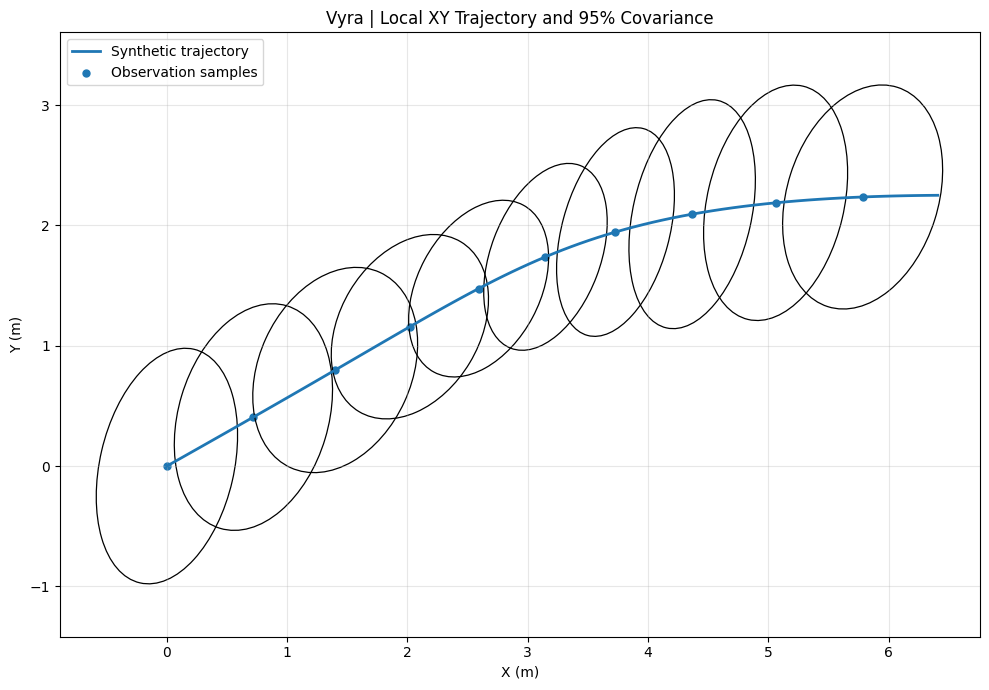

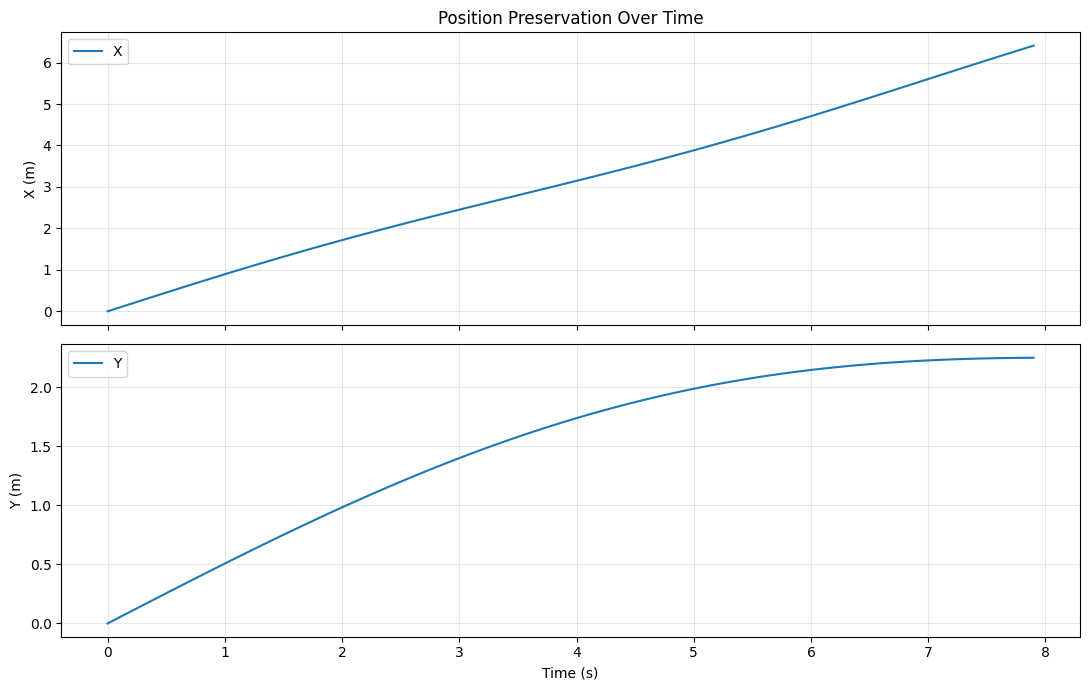

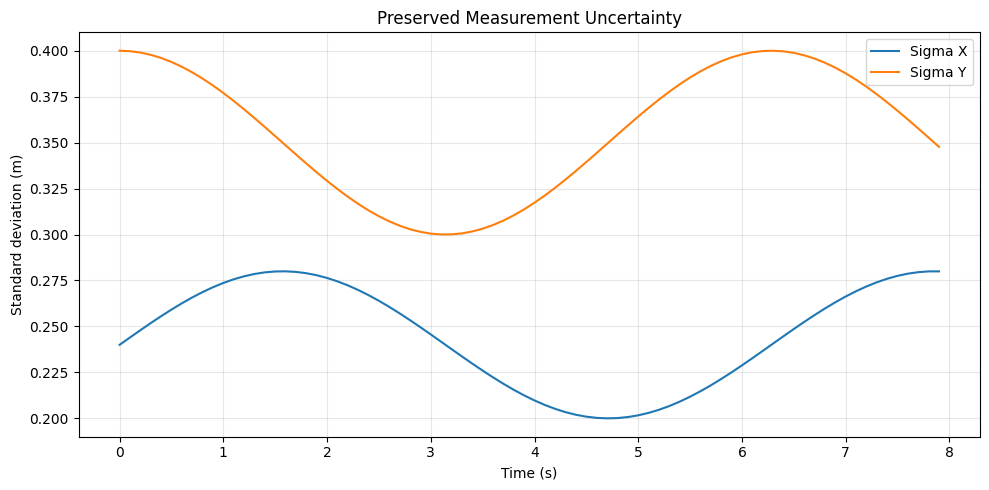

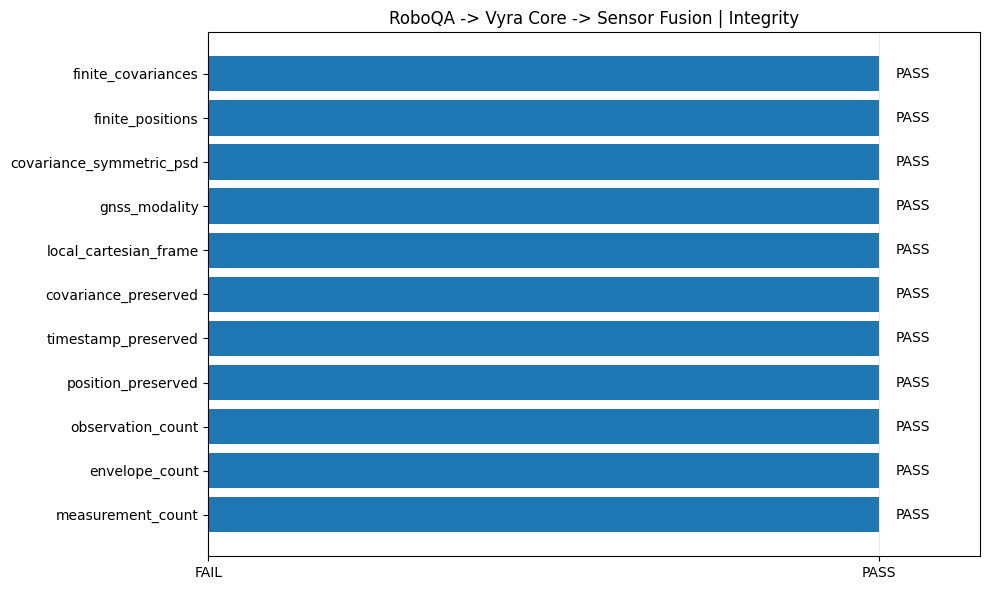


[7] EXPORTANDO CSV

[8] EMPACOTANDO RESULTADOS

VYRA VISUAL VALIDATION | FINAL SUMMARY
RoboQA: 7d8e77df75da236db2dc8c7199a146f12696ecb4
Vyra Core: 578b48f2fcd6d4e2a6079994e44dbf23b956f5d1
Sensor Fusion ML: fd4ff9ef40469023487be0571e44886fb6330088

Integrity: 11 / 11 PASS

Artifacts:
01_xy_trajectory_covariance.png (198,096 bytes)
02_position_over_time.png (82,843 bytes)
03_uncertainty_over_time.png (104,769 bytes)
04_integrity_checks.png (101,710 bytes)
integration_measurements.csv (11,856 bytes)
validation_report.json (1,310 bytes)

ZIP: /content/vyra_visual_validation/vyra_visual_validation_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:


# =====================================================================
# ARQTECH LABS | VYRA ECOSYSTEM
# ROBOQA -> VYRA CORE -> SENSOR FUSION ML
# MANUAL VISUAL VALIDATION | GOOGLE COLAB
#
# Reutiliza clones e instalações existentes.
# Não altera GitHub, não faz commit, não treina modelos.
# =====================================================================

import sys
import os
import json
import math
import csv
import zipfile
import subprocess
import importlib
import importlib.util

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

# =====================================================================
# 0. PATHS
# =====================================================================

BASE = Path("/content/vyra_visual_validation")

ROBOQA = BASE / "roboqa"
CORE = BASE / "core"
FUSION = BASE / "fusion"

OUTPUT = BASE / "artifacts"
OUTPUT.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("ARQTECH LABS | VYRA VISUAL VALIDATION")
print("=" * 72)

for name, path in [
    ("RoboQA", ROBOQA),
    ("Vyra Core", CORE),
    ("Sensor Fusion ML", FUSION),
]:
    print(f"{name}: {path} | exists={path.exists()}")
    if not path.exists():
        raise FileNotFoundError(f"Repositório ausente: {path}")

# =====================================================================
# 1. REPOSITORY COMMITS
# =====================================================================

def get_head(path):
    return subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=path,
        text=True
    ).strip()

commits = {
    "roboqa": get_head(ROBOQA),
    "vyra_core": get_head(CORE),
    "sensor_fusion_ml": get_head(FUSION),
}

print("\n[1] COMMITS")
for name, sha in commits.items():
    print(name, sha)

# =====================================================================
# 2. IMPORT PATHS — EXPLICIT CHECKOUT PRIORITY
# =====================================================================

print("\n[2] CONFIGURANDO IMPORTS")

CORE_SRC = CORE / "src"
FUSION_SRC = FUSION / "src"
ROBOQA_SRC = ROBOQA

required_paths = [
    CORE_SRC / "vyra_core",
    FUSION_SRC / "sensor_fusion_ml",
    ROBOQA_SRC / "roboqa",
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Pacote não encontrado: {path}")

# Evita carregar módulos de checkouts antigos.
for module_name in list(sys.modules):
    if (
        module_name == "vyra_core"
        or module_name.startswith("vyra_core.")
        or module_name == "sensor_fusion_ml"
        or module_name.startswith("sensor_fusion_ml.")
    ):
        del sys.modules[module_name]

# Prioriza os três checkouts corretos.
priority_paths = [
    str(FUSION_SRC),
    str(CORE_SRC),
    str(ROBOQA_SRC),
]

sys.path = [
    p for p in sys.path
    if p not in priority_paths
    and "vyra_core_validation" not in p
]

for path in reversed(priority_paths):
    sys.path.insert(0, path)

importlib.invalidate_caches()

# =====================================================================
# 3. IMPORT REAL ADAPTERS
# =====================================================================

print("\n[3] IMPORTANDO ADAPTERS")

from roboqa.data.schemas import Measurement

from vyra_core.adapters.roboqa import (
    RoboQAGPSProducerAdapter
)

from vyra_core.contracts import (
    TemporalReference,
    SpatialReference
)

from sensor_fusion_ml.integrations.vyra_core import (
    roboqa_gps_envelope_to_observation
)

import vyra_core
import sensor_fusion_ml

print("Vyra Core:", vyra_core.__file__)
print("Sensor Fusion:", sensor_fusion_ml.__file__)

assert str(CORE) in str(vyra_core.__file__)
assert str(FUSION) in str(sensor_fusion_ml.__file__)

print("[PASS] Producer adapter")
print("[PASS] Consumer adapter")
print("[PASS] Imports from expected repositories")

# =====================================================================
# 4. CONTROLLED SYNTHETIC DATA
# =====================================================================

print("\n[4] GERANDO EXPERIMENTO SINTÉTICO")

N = 80

times = np.linspace(0.0, 7.9, N)

x_values = (
    0.8 * times
    + 0.12 * np.sin(0.9 * times)
)

y_values = (
    0.25 * times
    + 0.75 * np.sin(0.35 * times)
)

measurements = []
envelopes = []
observations = []

for i, t in enumerate(times):

    position = np.array(
        [x_values[i], y_values[i]],
        dtype=np.float64
    )

    sigma_x = 0.20 + 0.04 * (1 + math.sin(t))
    sigma_y = 0.30 + 0.05 * (1 + math.cos(t))

    covariance = np.array([
        [sigma_x**2, 0.025],
        [0.025, sigma_y**2]
    ], dtype=np.float64)

    measurement = Measurement(
        t=float(t),
        sensor="gps",
        z=position,
        R=covariance
    )

    temporal = TemporalReference(
        event_time=float(t),
        event_time_unit="seconds",
        time_reference="simulation_elapsed_seconds",
        clock_domain="roboqa_synthetic_clock",
        source_id="roboqa-lab-synthetic",
        sequence=i
    )

    spatial = SpatialReference(
        coordinate_frame="LOCAL_CARTESIAN",
        coordinate_system="local_cartesian_xy",
        crs="LOCAL:ARQTECH:SIMULATION",
        axis_order=("x", "y"),
        units=("m", "m"),
        origin="synthetic_origin_x0_y0"
    )

    producer = RoboQAGPSProducerAdapter(
        artifact_id=f"vyra-gps-{i:04d}",
        source_artifact_id=f"roboqa-measurement-{i:04d}",
        temporal_reference=temporal,
        spatial_reference=spatial
    )

    envelope = producer.to_envelope(measurement)

    observation = roboqa_gps_envelope_to_observation(
        envelope
    )

    measurements.append(measurement)
    envelopes.append(envelope)
    observations.append(observation)

print("Measurements:", len(measurements))
print("Envelopes:", len(envelopes))
print("Observations:", len(observations))

# =====================================================================
# 5. EXTRACT OUTPUTS
# =====================================================================

positions = np.array([
    np.asarray(o.data, dtype=float)
    for o in observations
])

covariances = np.array([
    np.asarray(
        o.metadata["measurement_covariance"],
        dtype=float
    )
    for o in observations
])

std_x = np.sqrt(covariances[:, 0, 0])
std_y = np.sqrt(covariances[:, 1, 1])

# =====================================================================
# 6. INTEGRITY VALIDATION
# =====================================================================

print("\n[5] VALIDANDO INTEGRIDADE")

checks = {
    "measurement_count": len(measurements) == N,
    "envelope_count": len(envelopes) == N,
    "observation_count": len(observations) == N,

    "position_preserved": all(
        np.array_equal(
            np.asarray(m.z),
            np.asarray(o.data)
        )
        for m, o in zip(measurements, observations)
    ),

    "timestamp_preserved": all(
        float(m.t) == float(o.timestamp.value)
        for m, o in zip(measurements, observations)
    ),

    "covariance_preserved": all(
        np.array_equal(
            np.asarray(m.R),
            np.asarray(o.metadata["measurement_covariance"])
        )
        for m, o in zip(measurements, observations)
    ),

    "local_cartesian_frame": all(
        o.frame.value == "local_cartesian"
        for o in observations
    ),

    "gnss_modality": all(
        o.modality.value == "gnss"
        for o in observations
    ),

    "covariance_symmetric_psd": all(
        np.allclose(m.R, m.R.T, atol=1e-8)
        and np.linalg.eigvalsh(m.R).min() >= -1e-8
        for m in measurements
    ),

    "finite_positions": bool(
        np.all(np.isfinite(positions))
    ),

    "finite_covariances": bool(
        np.all(np.isfinite(covariances))
    ),
}

for name, passed in checks.items():
    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

if not all(checks.values()):
    raise AssertionError(
        "A validação de integridade apresentou falhas."
    )

# =====================================================================
# 7. GRAPH 1 — XY TRAJECTORY + 95% COVARIANCE
# =====================================================================

print("\n[6] GERANDO GRÁFICOS")

fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(
    positions[:, 0],
    positions[:, 1],
    linewidth=2,
    label="Synthetic trajectory"
)

ax.scatter(
    positions[::8, 0],
    positions[::8, 1],
    s=25,
    label="Observation samples"
)

for i in range(0, N, 8):

    eigenvalues, eigenvectors = np.linalg.eigh(
        covariances[i]
    )

    order = np.argsort(eigenvalues)[::-1]

    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    angle = np.degrees(
        np.arctan2(
            eigenvectors[1, 0],
            eigenvectors[0, 0]
        )
    )

    width, height = (
        2 * np.sqrt(
            np.maximum(eigenvalues, 0) * 5.991
        )
    )

    ax.add_patch(Ellipse(
        xy=positions[i],
        width=width,
        height=height,
        angle=angle,
        fill=False,
        linewidth=0.9
    ))

ax.set_title(
    "Vyra | Local XY Trajectory and 95% Covariance"
)

ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.axis("equal")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT / "01_xy_trajectory_covariance.png",
    dpi=180
)

plt.show()
plt.close(fig)

# =====================================================================
# 8. GRAPH 2 — POSITION OVER TIME
# =====================================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 7),
    sharex=True
)

axes[0].plot(
    times,
    positions[:, 0],
    label="X"
)

axes[0].set_ylabel("X (m)")
axes[0].set_title("Position Preservation Over Time")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    times,
    positions[:, 1],
    label="Y"
)

axes[1].set_ylabel("Y (m)")
axes[1].set_xlabel("Time (s)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

fig.tight_layout()

fig.savefig(
    OUTPUT / "02_position_over_time.png",
    dpi=180
)

plt.show()
plt.close(fig)

# =====================================================================
# 9. GRAPH 3 — UNCERTAINTY
# =====================================================================

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    times,
    std_x,
    label="Sigma X"
)

ax.plot(
    times,
    std_y,
    label="Sigma Y"
)

ax.set_title(
    "Preserved Measurement Uncertainty"
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Standard deviation (m)")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUTPUT / "03_uncertainty_over_time.png",
    dpi=180
)

plt.show()
plt.close(fig)

# =====================================================================
# 10. GRAPH 4 — INTEGRITY CHECKS
# =====================================================================

fig, ax = plt.subplots(figsize=(10, 6))

names = list(checks.keys())
values = [
    int(checks[name])
    for name in names
]

ax.barh(names, values)

ax.set_xlim(0, 1.15)
ax.set_xticks(
    [0, 1],
    ["FAIL", "PASS"]
)

ax.set_title(
    "RoboQA -> Vyra Core -> Sensor Fusion | Integrity"
)

for i, value in enumerate(values):
    ax.text(
        value + 0.025,
        i,
        "PASS" if value else "FAIL",
        va="center"
    )

ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

fig.savefig(
    OUTPUT / "04_integrity_checks.png",
    dpi=180
)

plt.show()
plt.close(fig)

# =====================================================================
# 11. CSV EXPORT
# =====================================================================

print("\n[7] EXPORTANDO CSV")

csv_path = OUTPUT / "integration_measurements.csv"

with open(
    csv_path,
    "w",
    newline=""
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "index",
        "timestamp_s",
        "x_input_m",
        "y_input_m",
        "x_output_m",
        "y_output_m",
        "sigma_x_m",
        "sigma_y_m",
        "coordinate_frame",
        "modality"
    ])

    for i, (m, o) in enumerate(
        zip(measurements, observations)
    ):

        writer.writerow([
            i,
            m.t,
            m.z[0],
            m.z[1],
            o.data[0],
            o.data[1],
            std_x[i],
            std_y[i],
            o.frame.value,
            o.modality.value
        ])

# =====================================================================
# 12. JSON REPORT
# =====================================================================

report = {
    "project": "Vyra Ecosystem",
    "organization": "ArqTech Labs",

    "experiment": (
        "RoboQA -> Vyra Core -> Sensor Fusion ML"
    ),

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "data_type": "synthetic_controlled_measurements",
    "sample_count": N,

    "source_commits": commits,

    "previous_automated_test_results": {
        "consumer_integration": "10 passed",
        "sensor_fusion_full_suite": "86 passed",
        "vyra_core_suite": "passed, exit code 0"
    },

    "integrity_checks": checks,

    "limitations": [
        "Synthetic data, not physical sensor measurements.",
        "No geographic coordinate transformation.",
        "No Kalman filter update.",
        "No sensor fusion estimation.",
        "Covariance preserved in metadata, not consumed by Kalman.",
        "No model training."
    ]
}

with open(
    OUTPUT / "validation_report.json",
    "w"
) as f:
    json.dump(
        report,
        f,
        indent=2
    )

# =====================================================================
# 13. PACKAGE RESULTS
# =====================================================================

print("\n[8] EMPACOTANDO RESULTADOS")

ZIP_PATH = BASE / "vyra_visual_validation_artifacts.zip"

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for file in OUTPUT.iterdir():
        if file.is_file():
            archive.write(
                file,
                arcname=file.name
            )

# =====================================================================
# 14. FINAL REPORT
# =====================================================================

print("\n" + "=" * 72)
print("VYRA VISUAL VALIDATION | FINAL SUMMARY")
print("=" * 72)

print("RoboQA:", commits["roboqa"])
print("Vyra Core:", commits["vyra_core"])
print("Sensor Fusion ML:", commits["sensor_fusion_ml"])

print(
    "\nIntegrity:",
    sum(checks.values()),
    "/",
    len(checks),
    "PASS"
)

print("\nArtifacts:")

for file in sorted(OUTPUT.iterdir()):
    print(
        file.name,
        f"({file.stat().st_size:,} bytes)"
    )

print("\nZIP:", ZIP_PATH)
print("=" * 72)

# =====================================================================
# 15. DOWNLOAD
# =====================================================================

try:
    from google.colab import files
    files.download(str(ZIP_PATH))
except Exception as exc:
    print(
        "Download automático indisponível:",
        repr(exc)
    )
    print("Arquivo salvo em:", ZIP_PATH)

In [ ]:


# =====================================================================
# ARQTECH LABS | VYRA MILESTONE 002
# REAL DATA INTEGRATION READINESS
# READ-ONLY AUDIT | NO DOWNLOAD | NO TRAINING | NO REPOSITORY CHANGES
# =====================================================================

from pathlib import Path
import subprocess
import re
import json

BASE = Path("/content/vyra_visual_validation")

REPOS = {
    "ROBOQA": BASE / "roboqa",
    "VYRA_CORE": BASE / "core",
    "SENSOR_FUSION_ML": BASE / "fusion",
}

print("=" * 72)
print("VYRA | MILESTONE 002 | READINESS AUDIT")
print("=" * 72)

# --------------------------------------------------
# 1. REPOSITORY IDENTITY
# --------------------------------------------------

print("\n[1] REPOSITORY IDENTITY")

for name, path in REPOS.items():

    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())

    if not path.exists():
        continue

    head = subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=path,
        text=True
    ).strip()

    branch = subprocess.check_output(
        ["git", "branch", "--show-current"],
        cwd=path,
        text=True
    ).strip()

    status = subprocess.check_output(
        ["git", "status", "--short"],
        cwd=path,
        text=True
    ).strip()

    print("Branch:", branch)
    print("HEAD:", head)
    print("Working tree:", "CLEAN" if not status else "MODIFIED")
    if status:
        print(status)

# --------------------------------------------------
# 2. ROBOQA OXTS / KITTI SOURCE AUDIT
# --------------------------------------------------

print("\n[2] ROBOQA SOURCE AUDIT")

ROBOQA = REPOS["ROBOQA"]

patterns = re.compile(
    r"kitti|oxts|gps|latitude|longitude|"
    r"timestamp|covariance|measurement|"
    r"coordinate|projection|wgs84",
    re.IGNORECASE
)

source_matches = []

if ROBOQA.exists():

    for file in ROBOQA.rglob("*.py"):

        try:
            lines = file.read_text(
                encoding="utf-8",
                errors="replace"
            ).splitlines()
        except Exception:
            continue

        for line_number, line in enumerate(lines, 1):

            if patterns.search(line):
                source_matches.append({
                    "file": str(file.relative_to(ROBOQA)),
                    "line": line_number,
                    "text": line.strip()[:220]
                })

print("Matching source lines:", len(source_matches))

for item in source_matches[:100]:
    print(
        f"{item['file']}:{item['line']} | "
        f"{item['text']}"
    )

if len(source_matches) > 100:
    print("Output limitado aos primeiros 100 resultados.")

# --------------------------------------------------
# 3. MEASUREMENT SCHEMA
# --------------------------------------------------

print("\n[3] ROBOQA MEASUREMENT SCHEMA")

schema_file = ROBOQA / "roboqa" / "data" / "schemas.py"

print("Schema path:", schema_file)
print("Exists:", schema_file.exists())

if schema_file.exists():

    lines = schema_file.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for i, line in enumerate(lines):

        if re.search(r"class Measurement\b", line):

            start = max(0, i - 3)
            end = min(len(lines), i + 65)

            print("\n".join(
                f"{j+1}: {lines[j]}"
                for j in range(start, end)
            ))
            break

# --------------------------------------------------
# 4. PRODUCER ADAPTER CONTRACT
# --------------------------------------------------

print("\n[4] VYRA CORE PRODUCER")

producer_file = (
    REPOS["VYRA_CORE"]
    / "src" / "vyra_core" / "adapters" / "roboqa.py"
)

print("Producer:", producer_file)
print("Exists:", producer_file.exists())

if producer_file.exists():

    lines = producer_file.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for i, line in enumerate(lines):

        if "class RoboQAGPSProducerAdapter" in line:

            end = min(len(lines), i + 115)

            print("\n".join(
                f"{j+1}: {lines[j]}"
                for j in range(i, end)
            ))
            break

# --------------------------------------------------
# 5. SENSOR FUSION CONSUMER CONTRACT
# --------------------------------------------------

print("\n[5] SENSOR FUSION CONSUMER")

consumer_file = (
    REPOS["SENSOR_FUSION_ML"]
    / "src" / "sensor_fusion_ml"
    / "integrations" / "vyra_core.py"
)

print("Consumer:", consumer_file)
print("Exists:", consumer_file.exists())

if consumer_file.exists():

    lines = consumer_file.read_text(
        encoding="utf-8",
        errors="replace"
    ).splitlines()

    for i, line in enumerate(lines):

        if "def roboqa_gps_envelope_to_observation" in line:

            end = min(len(lines), i + 120)

            print("\n".join(
                f"{j+1}: {lines[j]}"
                for j in range(i, end)
            ))
            break

# --------------------------------------------------
# 6. DATASET AVAILABILITY
# --------------------------------------------------

print("\n[6] KITTI / OXTS DATA AVAILABILITY")

DATA_ROOTS = [
    Path("/content/datasets"),
    Path("/content/dataset"),
    Path("/content/data"),
    Path("/content/kitti"),
    Path("/content/KITTI"),
    Path("/content/drive/MyDrive/datasets"),
    Path("/content/drive/MyDrive/KITTI"),
]

found_directories = []
found_oxts_files = []

for root in DATA_ROOTS:

    if not root.exists():
        continue

    print("\nSearching:", root)

    try:
        for directory in root.rglob("*"):

            if not directory.is_dir():
                continue

            if directory.name.lower() == "oxts":
                found_directories.append(directory)

                print("OXTS directory:", directory)

                data_dir = directory / "data"

                if data_dir.exists():

                    files = sorted(data_dir.glob("*.txt"))

                    for file in files[:10]:
                        found_oxts_files.append(file)
                        print("  Data file:", file.name)

                    print(
                        "  TXT files found:",
                        len(files)
                    )

    except PermissionError:
        print("Permission denied:", root)

print("\nOXTS directories:", len(found_directories))
print("Sample OXTS files:", len(found_oxts_files))

# --------------------------------------------------
# 7. SUMMARY
# --------------------------------------------------

print("\n[7] AUDIT SUMMARY")

summary = {
    "repositories_present": all(
        p.exists() for p in REPOS.values()
    ),
    "roboqa_schema_present": schema_file.exists(),
    "producer_adapter_present": producer_file.exists(),
    "consumer_adapter_present": consumer_file.exists(),
    "oxts_directory_found": len(found_directories) > 0,
    "oxts_sample_files_found": len(found_oxts_files) > 0,
}

for name, value in summary.items():
    print(
        f"[{'FOUND' if value else 'NOT FOUND'}] {name}"
    )

print("\nREAD-ONLY AUDIT COMPLETE")
print("No repository files were modified.")
print("No datasets were downloaded.")
print("No training or inference was executed.")

print("=" * 72)

VYRA | MILESTONE 002 | READINESS AUDIT

[1] REPOSITORY IDENTITY

ROBOQA
Path: /content/vyra_visual_validation/roboqa
Exists: True
Branch: main
HEAD: 7d8e77df75da236db2dc8c7199a146f12696ecb4
Working tree: MODIFIED
?? roboqa/__pycache__/
?? roboqa/data/__pycache__/

VYRA_CORE
Path: /content/vyra_visual_validation/core
Exists: True
Branch: main
HEAD: 578b48f2fcd6d4e2a6079994e44dbf23b956f5d1
Working tree: MODIFIED
?? src/vyra_core.egg-info/
?? src/vyra_core/__pycache__/
?? src/vyra_core/adapters/__pycache__/
?? src/vyra_core/contracts/__pycache__/
?? src/vyra_core/validation/__pycache__/
?? tests/adapters/__pycache__/
?? tests/contracts/__pycache__/
?? tests/validation/__pycache__/

SENSOR_FUSION_ML
Path: /content/vyra_visual_validation/fusion
Exists: True
Branch: main
HEAD: fd4ff9ef40469023487be0571e44886fb6330088
Working tree: CLEAN

[2] ROBOQA SOURCE AUDIT
Matching source lines: 243
roboqa/__init__.py:11 | Measurement,
roboqa/__init__.py:19 | "Measurement",
tests/adversarial/test_data_a

In [ ]:


# =====================================================================
# VYRA | MILESTONE 002.1
# KITTI OXTS SOURCE & COORDINATE TRANSFORM AUDIT
# READ-ONLY
# =====================================================================

from pathlib import Path
import ast
import subprocess

ROBOQA = Path("/content/vyra_visual_validation/roboqa")
KITTI_FILE = ROBOQA / "roboqa" / "data" / "kitti.py"

print("=" * 72)
print("VYRA | KITTI SOURCE AUDIT")
print("=" * 72)

# 1. Inspect actual KITTI implementation
print("\n[1] KITTI IMPLEMENTATION")
print("File:", KITTI_FILE)
print("Exists:", KITTI_FILE.exists())

if KITTI_FILE.exists():
    source = KITTI_FILE.read_text(
        encoding="utf-8",
        errors="replace"
    )

    tree = ast.parse(source)

    targets = {
        "load_kitti_oxts",
        "latlon_to_local",
        "get_trajectory",
        "download_kitti_drive",
    }

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name in targets:
                print("\n" + "-" * 72)
                print(f"FUNCTION: {node.name}")
                print("-" * 72)
                print(ast.get_source_segment(source, node))

# 2. Inspect KITTI-related configuration and documentation
print("\n[2] KITTI REFERENCES")

for folder in ["roboqa", "tests", "docs"]:
    root = ROBOQA / folder

    if not root.exists():
        continue

    for file in root.rglob("*"):
        if not file.is_file():
            continue

        if file.suffix.lower() not in {
            ".py", ".md", ".yaml", ".yml", ".toml", ".json"
        }:
            continue

        try:
            content = file.read_text(
                encoding="utf-8",
                errors="replace"
            )
        except Exception:
            continue

        matches = [
            (i, line.strip())
            for i, line in enumerate(content.splitlines(), 1)
            if any(term in line.lower() for term in (
                "kitti", "oxts", "latlon_to_local",
                "kitti_real", "sequence"
            ))
        ]

        if matches:
            print(f"\nFILE: {file.relative_to(ROBOQA)}")
            for line_number, line in matches[:20]:
                print(f"{line_number}: {line[:220]}")

# 3. Check common dataset locations without downloading
print("\n[3] DATASET LOCATION CHECK")

roots = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
]

for root in roots:
    print(f"\nROOT: {root} | exists={root.exists()}")

    if not root.exists():
        continue

    candidates = []

    for item in root.iterdir():
        if not item.is_dir():
            continue

        name = item.name.lower()

        if any(term in name for term in (
            "kitti", "dataset", "oxts", "odometry"
        )):
            candidates.append(item)

    if candidates:
        for item in candidates:
            print("CANDIDATE:", item)
    else:
        print("No obvious KITTI/dataset directory at this level.")

# 4. Check whether Google Drive is mounted
print("\n[4] GOOGLE DRIVE")
drive = Path("/content/drive/MyDrive")
print("Mounted:", drive.exists())

print("\n" + "=" * 72)
print("AUDIT COMPLETE — NO DOWNLOAD OR SOURCE MODIFICATION")
print("=" * 72)

VYRA | KITTI SOURCE AUDIT

[1] KITTI IMPLEMENTATION
File: /content/vyra_visual_validation/roboqa/roboqa/data/kitti.py
Exists: True

------------------------------------------------------------------------
FUNCTION: latlon_to_local
------------------------------------------------------------------------
def latlon_to_local(
    lat: np.ndarray,
    lon: np.ndarray,
    lat0: Optional[float] = None,
    lon0: Optional[float] = None,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Converte latitude/longitude (graus) para coordenadas cartesianas locais (m).

    Utiliza aproximação equiretangular (adequada para trajetórias curtas,
    < ~10 km). Referência: centro da primeira amostra ou (lat0, lon0) fornecidos.

    Raises
    ------
    SchemaError
        Em entradas vazias, não-finitas ou dimensionalmente incompatíveis.
    """
    lat = np.asarray(lat, dtype=np.float64)
    lon = np.asarray(lon, dtype=np.float64)

    if lat.size == 0 or lon.size == 0:
        raise SchemaError("lat/lo

In [ ]:


from pathlib import Path
import os

roots = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
    Path("/content/drive/Shareddrives"),
]

# Monta o Google Drive se necessário.
try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except Exception as e:
    print("Drive não montado:", repr(e))

roots = [p for p in roots if p.exists()]

print("=" * 65)
print("VYRA | KITTI DATASET LOCATOR — READ ONLY")
print("=" * 65)

found = set()

for root in roots:
    print(f"\nPesquisando: {root}")

    for current, dirs, files in os.walk(root):
        # Evita caches e diretórios de sistema desnecessários.
        dirs[:] = [
            d for d in dirs
            if d not in {
                ".git", "__pycache__", ".cache",
                "node_modules", ".config"
            }
        ]

        current_path = Path(current)

        if "kitti" in str(current_path).lower():
            found.add(str(current_path))

        for filename in files:
            path = current_path / filename
            name = filename.lower()

            if "kitti" in name or (
                name.endswith(".zip") and
                any(x in str(path).lower()
                    for x in ["kitti", "dataset", "datasets"])
            ):
                found.add(str(path))

        if current_path.name.lower() == "oxts":
            if (current_path / "data").exists():
                found.add(str(current_path))

print("\n" + "=" * 65)
print("RESULTADO")
print("=" * 65)

if found:
    for item in sorted(found):
        print("[FOUND]", item)
else:
    print("Nenhum arquivo ou diretório KITTI identificado.")

Mounted at /content/drive
VYRA | KITTI DATASET LOCATOR — READ ONLY

Pesquisando: /content

Pesquisando: /content/drive/MyDrive

RESULTADO
[FOUND] /content/vyra_visual_validation/roboqa/roboqa/data/kitti.py


In [ ]:


from pathlib import Path

root = Path("/content/vyra_visual_validation/roboqa")

print("DIRETÓRIO:", root)
print("EXISTE:", root.exists())

if root.exists():
    for p in sorted(root.rglob("*")):
        if p.is_file():
            name = p.name.lower()
            if (
                "kitti" in str(p).lower()
                or "oxts" in name
                or name.endswith((".zip", ".tar", ".tar.gz"))
            ):
                print(
                    f"{p} | "
                    f"{p.stat().st_size / (1024**2):.2f} MB"
                )

DIRETÓRIO: /content/vyra_visual_validation/roboqa
EXISTE: True
/content/vyra_visual_validation/roboqa/roboqa/data/__pycache__/kitti.cpython-313.pyc | 0.01 MB
/content/vyra_visual_validation/roboqa/roboqa/data/kitti.py | 0.01 MB


In [ ]:


from pathlib import Path
import os

base = Path("/content/vyra_visual_validation/roboqa/roboqa/data/kitti.py")

print("=" * 65)
print("1. CONTRATO DO LOADER KITTI")
print("=" * 65)

if base.exists():
    print(base.read_text())
else:
    print("Loader não encontrado.")

print("\n" + "=" * 65)
print("2. ARQUIVOS E DIRETÓRIOS DE DATASET")
print("=" * 65)

roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

archives = []
oxts_dirs = []

for root in roots:
    if not root.exists():
        continue

    for current, dirs, files in os.walk(root):
        dirs[:] = [
            d for d in dirs
            if d not in {".git", "__pycache__", "node_modules"}
        ]

        current = Path(current)

        if current.name.lower() == "oxts":
            if (current / "data").exists():
                oxts_dirs.append(current)

        for f in files:
            p = current / f
            if f.lower().endswith((".zip", ".7z", ".tar", ".gz")):
                try:
                    archives.append((p, p.stat().st_size))
                except OSError:
                    pass

print("\nDiretórios OXTS encontrados:")
for p in oxts_dirs:
    print(p)

print("\nArquivos compactados encontrados:")
for p, size in sorted(archives, key=lambda x: x[1], reverse=True):
    print(f"{size / (1024**3):.2f} GiB | {p}")

print("\nVerificação concluída. Nenhum arquivo foi alterado.")

1. CONTRATO DO LOADER KITTI
"""
Carregador de trajetórias KITTI OXTS.
Fase 1 — Data Engine (hardened)
ARQTECH LABS

Política de proveniência e fallback:
- load_kitti_oxts() levanta SchemaError em qualquer falha.
- get_trajectory(prefer_kitti=True) NÃO faz fallback silencioso.
  Se o caminho for inválido ou a leitura falhar, a exceção propaga.
- Fallback sintético ocorre somente quando prefer_kitti=False
  ou quando kitti_path é None.
- download_kitti_drive() é opt-in e, por política de segurança (R7),
  levanta NotImplementedError (sem download automático).

Temporalidade:
- Quando timestamps reais não estão disponíveis nos arquivos .txt
  do OXTS (formato clássico), usa-se aproximação de 10 Hz (dt=0.1 s).
- Esta aproximação é documentada e identificada.
- yaw_rate é calculado via np.gradient com np.unwrap para respeitar
  a descontinuidade angular.
"""

from __future__ import annotations

from pathlib import Path
from typing import Optional, Tuple, Union

import numpy as np

from .sch

ARQTECH LABS | VYRA — PPC DATASET VALIDATION
Dataset: https://github.com/taroz/PPC-Dataset
Target: Nagoya / run1
Output: /content/vyra_ppc_validation

[1/9] Download do OneDrive...
Tentando: https://chibakoudai-my.sharepoint.com/:u:/g/personal/66lsm6_chibatech_ac_jp/ETmyNr1VrcpFjqxgjXJdgkQB ...
Download concluído: 154.73111152648926 MB
URL final: https://chibakoudai-my.sharepoint.com/personal/66lsm6_chibatech_ac_jp/Documents/PPC-Dataset.zip?ga=1

[2/9] Integridade do arquivo...
SHA256: 460b21747a78c8cca60190895b32615b9943cf4f75a20864280bb86a01b76658
CRC: PASS
Membros: 133
Tamanho extraído: 796.27 MB

[3/9] Extraindo dataset...
Extraídos 100/133

[4/9] Localizando sequências...
PPC-Dataset/README.md
PPC-Dataset/.gitignore
PPC-Dataset/.gitattributes
PPC-Dataset/LICENSE
PPC-Dataset/nagoya/README.md
PPC-Dataset/tokyo/README.md
PPC-Dataset/.git/description
PPC-Dataset/.git/COMMIT_EDITMSG
PPC-Dataset/.git/index
PPC-Dataset/.git/config
PPC-Dataset/.git/HEAD
PPC-Dataset/.git/FETCH_HEAD
PPC-Dat

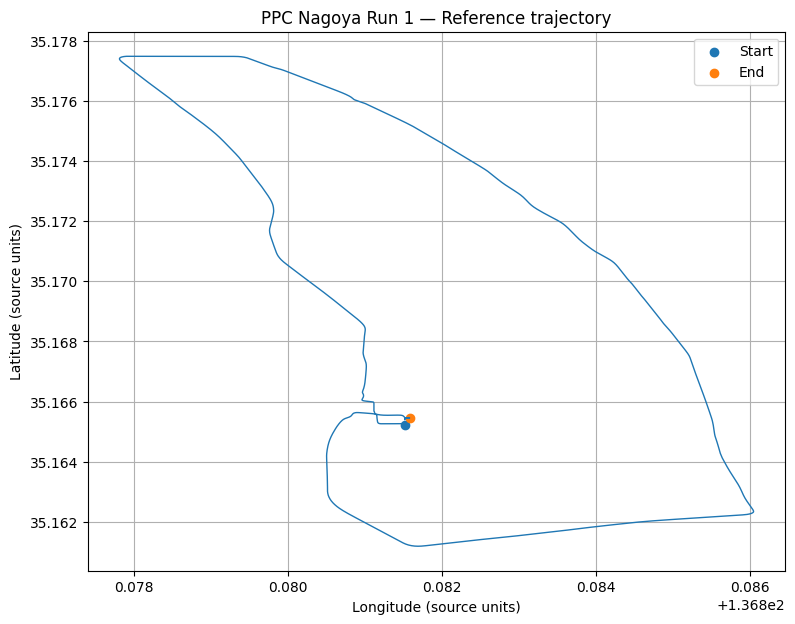

Trajectory plot: /content/vyra_ppc_validation/audit/nagoya_run1_reference_trajectory.png

[8/9] Executando testes...
PASS zip_exists = True
PASS zip_crc_pass = True
PASS extraction_marker_matches = True
PASS nagoya_run1_files_present = True
PASS imu.csv_nonempty = True
PASS imu.csv_columns_present = True
PASS imu.csv_no_duplicate_rows = True
PASS reference.csv_nonempty = True
PASS reference.csv_columns_present = True
PASS reference.csv_no_duplicate_rows = True
PASS rover.obs_header_valid = True
PASS rover.obs_rinex_version_detected = True
PASS base.obs_header_valid = True
PASS base.obs_rinex_version_detected = True
PASS base.nav_header_valid = True
PASS base.nav_rinex_version_detected = True
PASS reference_coordinate_candidates_found = True
PASS trajectory_plot_generated = True

[9/9] Salvando relatórios...

VYRA | PPC VALIDATION SUMMARY
Tests: 18/18
Status: PASS
Dataset: /content/vyra_ppc_validation/dataset
Report: /content/vyra_ppc_validation/audit/validation_report.json
CSV schema: 

In [ ]:


# ================================================================
# ARQTECH LABS | VYRA
# PPC DATASET — DOWNLOAD, AUDIT, VALIDATION AND TESTS
# Source: https://github.com/taroz/PPC-Dataset
# Target: Nagoya / Run 1
#
# No GitHub modifications, no model training, no fabricated metrics.
# ================================================================

from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
import os, re, json, hashlib, zipfile, shutil, base64, io
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("/content/vyra_ppc_validation")
DOWNLOADS = ROOT / "downloads"
EXTRACT = ROOT / "dataset"
AUDIT = ROOT / "audit"

for p in [DOWNLOADS, EXTRACT, AUDIT]:
    p.mkdir(parents=True, exist_ok=True)

# Link público publicado no README oficial.
SHARE_URL = (
    "https://chibakoudai-my.sharepoint.com/:u:/g/personal/"
    "66lsm6_chibatech_ac_jp/"
    "ETmyNr1VrcpFjqxgjXJdgkQBkfTwnykhSPOVKClOUBNOMQ"
)

REPO = "https://github.com/taroz/PPC-Dataset"
ZIP_PATH = DOWNLOADS / "PPC-Dataset.zip"

print("=" * 72)
print("ARQTECH LABS | VYRA — PPC DATASET VALIDATION")
print("=" * 72)
print("Dataset:", REPO)
print("Target: Nagoya / run1")
print("Output:", ROOT)

# ------------------------------------------------
# 1. DOWNLOAD — TRY PUBLIC ONEDRIVE ACCESS
# ------------------------------------------------

def download_stream(url, destination):
    with requests.get(
        url, stream=True, allow_redirects=True, timeout=(30, 120)
    ) as response:
        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "").lower()
        if "text/html" in content_type:
            raise RuntimeError(
                "OneDrive retornou uma página HTML, não o arquivo ZIP."
            )

        total = 0
        with open(destination, "wb") as f:
            for chunk in response.iter_content(8 * 1024 * 1024):
                if chunk:
                    f.write(chunk)
                    total += len(chunk)

        if total < 1024 * 1024:
            raise RuntimeError("Arquivo recebido é pequeno demais.")

        return total, response.url

print("\n[1/9] Download do OneDrive...")

if not ZIP_PATH.exists():
    urls = [
        SHARE_URL + "?download=1",
        SHARE_URL
    ]

    # Tentativa adicional pela API de compartilhamento Microsoft.
    encoded = base64.urlsafe_b64encode(
        SHARE_URL.encode()
    ).decode().rstrip("=")

    urls.append(
        f"https://api.onedrive.com/v1.0/shares/u!{encoded}/root/content"
    )

    errors = []
    success = False

    for url in urls:
        try:
            print("Tentando:", url[:100], "...")
            size, final_url = download_stream(url, ZIP_PATH)

            if not zipfile.is_zipfile(ZIP_PATH):
                ZIP_PATH.unlink(missing_ok=True)
                raise RuntimeError("Resposta não é um ZIP válido.")

            print("Download concluído:", size / 1024**2, "MB")
            print("URL final:", final_url)
            success = True
            break

        except Exception as e:
            errors.append(repr(e))
            ZIP_PATH.unlink(missing_ok=True)
            print("Tentativa falhou:", repr(e))

    if not success:
        raise RuntimeError(
            "O OneDrive não permitiu download automatizado nesta sessão.\n"
            "Não foi criado um dataset fictício.\n"
            "Abra o link oficial e baixe o ZIP manualmente:\n"
            + SHARE_URL
            + "\nDepois envie o ZIP para /content/vyra_ppc_validation/downloads/"
              "PPC-Dataset.zip no Colab e execute novamente.\n\n"
            + "\n".join(errors)
        )
else:
    print("ZIP existente localizado:", ZIP_PATH)

# ------------------------------------------------
# 2. SHA256 + ZIP VALIDATION
# ------------------------------------------------

print("\n[2/9] Integridade do arquivo...")

sha = hashlib.sha256()
with open(ZIP_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
        sha.update(chunk)

zip_sha256 = sha.hexdigest()

if not zipfile.is_zipfile(ZIP_PATH):
    raise RuntimeError("Arquivo não é ZIP.")

with zipfile.ZipFile(ZIP_PATH) as z:
    members = z.infolist()

    if not members:
        raise RuntimeError("ZIP vazio.")

    total_uncompressed = sum(
        x.file_size for x in members if not x.is_dir()
    )

    for item in members:
        p = PurePosixPath(item.filename)
        if p.is_absolute() or ".." in p.parts:
            raise RuntimeError("Caminho inseguro no ZIP: " + item.filename)

        mode = (item.external_attr >> 16) & 0o170000
        if mode == 0o120000:
            raise RuntimeError("Link simbólico não permitido.")

    bad = z.testzip()
    if bad:
        raise RuntimeError("CRC inválido: " + bad)

print("SHA256:", zip_sha256)
print("CRC: PASS")
print("Membros:", len(members))
print("Tamanho extraído:", round(total_uncompressed / 1024**2, 2), "MB")

# ------------------------------------------------
# 3. EXTRACTION
# ------------------------------------------------

print("\n[3/9] Extraindo dataset...")

marker = EXTRACT / "_EXTRACTION_COMPLETE.json"

if marker.exists():
    old = json.loads(marker.read_text())
    if old.get("sha256") != zip_sha256:
        raise RuntimeError(
            "Pasta de extração existente pertence a outro ZIP. "
            "Não será sobrescrita automaticamente."
        )
    print("Extração anterior validada pelo SHA256.")
else:
    if any(EXTRACT.iterdir()):
        raise RuntimeError(
            "Pasta de extração não vazia sem marcador de integridade. "
            "Use uma pasta limpa antes de prosseguir."
        )

    with zipfile.ZipFile(ZIP_PATH) as z:
        for i, item in enumerate(z.infolist(), 1):
            if item.is_dir():
                continue

            dest = EXTRACT.joinpath(*PurePosixPath(item.filename).parts)
            dest.parent.mkdir(parents=True, exist_ok=True)

            with z.open(item) as src, open(dest, "wb") as dst:
                shutil.copyfileobj(src, dst, 8 * 1024 * 1024)

            if i % 100 == 0:
                print(f"Extraídos {i}/{len(members)}")

    marker.write_text(json.dumps({
        "sha256": zip_sha256,
        "created_utc": datetime.now(timezone.utc).isoformat()
    }, indent=2))

# ------------------------------------------------
# 4. LOCATE RUNS AND REQUIRED FILES
# ------------------------------------------------

print("\n[4/9] Localizando sequências...")

all_files = [
    p for p in EXTRACT.rglob("*")
    if p.is_file() and p.name != marker.name
]

for p in all_files[:80]:
    print(p.relative_to(EXTRACT))

def locate(filename, city="nagoya", run="run1"):
    candidates = [
        p for p in all_files
        if p.name.lower() == filename.lower()
        and city in str(p).lower()
        and run in str(p).lower()
    ]
    return candidates[0] if len(candidates) == 1 else None

required = [
    "rover.obs",
    "base.obs",
    "base.nav",
    "imu.csv",
    "reference.csv"
]

run_files = {name: locate(name) for name in required}

print("\nArquivos de Nagoya/run1:")
for name, path in run_files.items():
    print(name, "=>", path if path else "NOT FOUND")

missing = [k for k, v in run_files.items() if v is None]

if missing:
    raise RuntimeError(
        "Arquivos obrigatórios ausentes em Nagoya/run1: "
        + ", ".join(missing)
        + ". Confira a estrutura extraída antes de adaptar o parser."
    )

# ------------------------------------------------
# 5. CSV SCHEMA AND DATA QUALITY
# ------------------------------------------------

print("\n[5/9] Inspecionando IMU e referência...")

csv_report = {}
loaded = {}

for name in ["imu.csv", "reference.csv"]:
    path = run_files[name]

    df = pd.read_csv(path, low_memory=False)
    loaded[name] = df

    numeric = df.select_dtypes(include=[np.number])
    null_counts = df.isna().sum().to_dict()

    csv_report[name] = {
        "path": str(path.relative_to(EXTRACT)),
        "rows": int(len(df)),
        "columns": list(df.columns),
        "dtypes": {k: str(v) for k, v in df.dtypes.items()},
        "null_counts": {k: int(v) for k, v in null_counts.items()},
        "numeric_columns": list(numeric.columns),
        "numeric_nonfinite": {
            c: int((~np.isfinite(numeric[c])).sum())
            for c in numeric.columns
        },
        "duplicate_rows": int(df.duplicated().sum())
    }

    print("\n", name)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print(df.head(5).to_string(index=False))

# ------------------------------------------------
# 6. RINEX HEADER AUDIT
# ------------------------------------------------

print("\n[6/9] Lendo cabeçalhos RINEX...")

def rinex_header(path):
    lines = []
    with open(path, "r", errors="replace") as f:
        for line in f:
            lines.append(line.rstrip())
            if "END OF HEADER" in line:
                break

    return {
        "path": str(path.relative_to(EXTRACT)),
        "header_lines": len(lines),
        "version": next(
            (x[:20].strip() for x in lines if "RINEX VERSION" in x),
            None
        ),
        "receiver": next(
            (x[:60].strip() for x in lines if "REC # / TYPE / VERS" in x),
            None
        ),
        "antenna": next(
            (x[:60].strip() for x in lines if "ANT # / TYPE" in x),
            None
        ),
        "first_lines": lines[:15],
        "has_end_of_header": any("END OF HEADER" in x for x in lines)
    }

rinex_report = {
    name: rinex_header(run_files[name])
    for name in ["rover.obs", "base.obs", "base.nav"]
}

for name, result in rinex_report.items():
    print("\n", name)
    print("Version:", result["version"])
    print("Header valid:", result["has_end_of_header"])

# ------------------------------------------------
# 7. BASIC TIMESTAMP AND TRAJECTORY DISCOVERY
# ------------------------------------------------

print("\n[7/9] Procurando colunas temporais e coordenadas...")

def find_column(columns, patterns):
    for c in columns:
        normalized = re.sub(r"[^a-z0-9]+", "_", str(c).lower()).strip("_")
        if any(re.search(p, normalized) for p in patterns):
            return c
    return None

reference = loaded["reference.csv"]
imu = loaded["imu.csv"]

time_candidates = {
    "reference": find_column(
        reference.columns,
        [r"^time$", r"timestamp", r"gps.*time", r"^tow$"]
    ),
    "imu": find_column(
        imu.columns,
        [r"^time$", r"timestamp", r"gps.*time", r"^tow$"]
    )
}

coordinate_candidates = {
    "latitude": find_column(
        reference.columns, [r"latitude", r"^lat$"]
    ),
    "longitude": find_column(
        reference.columns, [r"longitude", r"^lon$", r"^lng$"]
    ),
    "east": find_column(
        reference.columns, [r"^east$", r"easting", r"^x$"]
    ),
    "north": find_column(
        reference.columns, [r"^north$", r"northing", r"^y$"]
    ),
    "height": find_column(
        reference.columns, [r"height", r"altitude", r"^alt$", r"^up$"]
    )
}

print("Timestamp candidates:", time_candidates)
print("Coordinate candidates:", coordinate_candidates)

# Não presume sistema de coordenadas nem unidades.
plot_path = None

latc = coordinate_candidates["latitude"]
lonc = coordinate_candidates["longitude"]
eastc = coordinate_candidates["east"]
northc = coordinate_candidates["north"]

if latc and lonc:
    xcol, ycol = lonc, latc
    xlabel, ylabel = "Longitude (source units)", "Latitude (source units)"
elif eastc and northc:
    xcol, ycol = eastc, northc
    xlabel, ylabel = "East (source units)", "North (source units)"
else:
    xcol = ycol = None

if xcol and ycol:
    x = pd.to_numeric(reference[xcol], errors="coerce")
    y = pd.to_numeric(reference[ycol], errors="coerce")
    valid = np.isfinite(x) & np.isfinite(y)

    if valid.sum() >= 2:
        fig, ax = plt.subplots(figsize=(9, 7))
        ax.plot(x[valid], y[valid], linewidth=1)
        ax.scatter(x[valid].iloc[0], y[valid].iloc[0], label="Start")
        ax.scatter(x[valid].iloc[-1], y[valid].iloc[-1], label="End")
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_title("PPC Nagoya Run 1 — Reference trajectory")
        ax.grid(True)
        ax.legend()

        plot_path = AUDIT / "nagoya_run1_reference_trajectory.png"
        fig.savefig(plot_path, dpi=160, bbox_inches="tight")
        plt.show()
        plt.close(fig)

        print("Trajectory plot:", plot_path)
else:
    print("Nenhuma combinação de coordenadas reconhecida automaticamente.")

# ------------------------------------------------
# 8. VALIDATION TESTS
# ------------------------------------------------

print("\n[8/9] Executando testes...")

tests = {}

tests["zip_exists"] = ZIP_PATH.exists()
tests["zip_crc_pass"] = True
tests["extraction_marker_matches"] = (
    json.loads(marker.read_text()).get("sha256") == zip_sha256
)
tests["nagoya_run1_files_present"] = not missing

for name in ["imu.csv", "reference.csv"]:
    df = loaded[name]
    tests[f"{name}_nonempty"] = len(df) > 0
    tests[f"{name}_columns_present"] = len(df.columns) > 0
    tests[f"{name}_no_duplicate_rows"] = not df.duplicated().any()

for name, info in rinex_report.items():
    tests[f"{name}_header_valid"] = info["has_end_of_header"]
    tests[f"{name}_rinex_version_detected"] = info["version"] is not None

tests["reference_coordinate_candidates_found"] = bool(latc and lonc) or bool(eastc and northc)
tests["trajectory_plot_generated"] = plot_path is not None

for key, value in tests.items():
    print(("PASS" if value else "INFO/FAIL"), key, "=", value)

# ------------------------------------------------
# 9. REPORTS AND ARTIFACTS
# ------------------------------------------------

print("\n[9/9] Salvando relatórios...")

passed = sum(bool(v) for v in tests.values())
total = len(tests)

report = {
    "project": "ArqTech Labs / Vyra",
    "dataset": "PPC — Precise Positioning Challenge",
    "source_repository": REPO,
    "sequence": "Nagoya / run1",
    "source_license": "MIT (repository declaration; retain attribution)",
    "download_sha256": zip_sha256,
    "download_size_bytes": ZIP_PATH.stat().st_size,
    "files": {
        k: str(v.relative_to(EXTRACT)) if v else None
        for k, v in run_files.items()
    },
    "csv_schema": csv_report,
    "rinex_headers": rinex_report,
    "timestamp_candidates": time_candidates,
    "coordinate_candidates": coordinate_candidates,
    "tests": tests,
    "test_pass_count": passed,
    "test_total": total,
    "test_status": "PASS" if all(tests.values()) else "PASS_WITH_WARNINGS",
    "trajectory_plot": str(plot_path) if plot_path else None,
    "limitations": [
        "This is a dataset integrity and schema audit, not a GNSS solution.",
        "RINEX observations have not been processed into a position solution.",
        "No GNSS/IMU fusion or Kalman filtering was executed.",
        "No coordinate reference system or units are inferred from column names alone.",
        "No covariance is invented.",
        "No repository files were modified."
    ],
    "generated_at_utc": datetime.now(timezone.utc).isoformat()
}

report_path = AUDIT / "validation_report.json"
report_path.write_text(json.dumps(report, indent=2, default=str))

schema_path = AUDIT / "csv_schema_report.json"
schema_path.write_text(json.dumps(csv_report, indent=2, default=str))

# Pacote apenas com artefatos de auditoria.
audit_zip = ROOT / "ppc_nagoya_run1_audit.zip"

with zipfile.ZipFile(audit_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in AUDIT.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(ROOT))

print("\n" + "=" * 72)
print("VYRA | PPC VALIDATION SUMMARY")
print("=" * 72)
print(f"Tests: {passed}/{total}")
print("Status:", report["test_status"])
print("Dataset:", EXTRACT)
print("Report:", report_path)
print("CSV schema:", schema_path)
print("Audit ZIP:", audit_zip)
print("\nIMPORTANT: PASS here means integrity/schema checks only.")
print("It does NOT mean GNSS positioning or sensor fusion has passed.")

In [ ]:


# ================================================================
# VYRA | PPC — TEMPORAL AUDIT & SENSOR ALIGNMENT
# Read-only: does not modify dataset or repositories.
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json

ROOT = Path("/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1")
OUT = Path("/content/vyra_ppc_validation/audit")
OUT.mkdir(parents=True, exist_ok=True)

imu = pd.read_csv(ROOT / "imu.csv")
ref = pd.read_csv(ROOT / "reference.csv")

# Remove whitespace from column names.
imu.columns = [str(c).strip() for c in imu.columns]
ref.columns = [str(c).strip() for c in ref.columns]

T = "GPS TOW (s)"
W = "GPS Week"

def temporal_audit(df, name):
    tow = pd.to_numeric(df[T], errors="coerce").to_numpy()
    week = pd.to_numeric(df[W], errors="coerce").to_numpy()

    valid = np.isfinite(tow) & np.isfinite(week)
    tow, week = tow[valid], week[valid]

    # GPS absolute time in seconds.
    absolute = week * 604800.0 + tow
    dt = np.diff(absolute)

    positive = dt[dt > 0]
    report = {
        "sensor": name,
        "rows_original": int(len(df)),
        "rows_valid": int(len(absolute)),
        "invalid_rows": int(len(df) - len(absolute)),
        "monotonic_strict": bool(np.all(dt > 0)),
        "duplicate_or_nonpositive_intervals": int(np.sum(dt <= 0)),
        "interval_median_s": float(np.median(positive)) if len(positive) else None,
        "interval_min_s": float(np.min(positive)) if len(positive) else None,
        "interval_max_s": float(np.max(positive)) if len(positive) else None,
        "frequency_median_hz": float(1 / np.median(positive)) if len(positive) else None,
        "duration_s": float(absolute[-1] - absolute[0]) if len(absolute) > 1 else None,
        "start_gps_week": float(week[0]) if len(week) else None,
        "start_tow_s": float(tow[0]) if len(tow) else None,
        "end_gps_week": float(week[-1]) if len(week) else None,
        "end_tow_s": float(tow[-1]) if len(tow) else None
    }
    return absolute, report

print("=" * 68)
print("VYRA | PPC TEMPORAL AUDIT")
print("=" * 68)

imu_time, imu_report = temporal_audit(imu, "IMU")
ref_time, ref_report = temporal_audit(ref, "REFERENCE")

print("\nIMU:")
print(json.dumps(imu_report, indent=2))
print("\nREFERENCE:")
print(json.dumps(ref_report, indent=2))

# Check numeric finite values.
def finite_report(df):
    result = {}
    for c in df.select_dtypes(include=[np.number]).columns:
        values = df[c].to_numpy(dtype=float)
        result[c] = {
            "finite": int(np.isfinite(values).sum()),
            "nonfinite": int((~np.isfinite(values)).sum())
        }
    return result

# Compare time coverage.
overlap_start = max(imu_time[0], ref_time[0])
overlap_end = min(imu_time[-1], ref_time[-1])

overlap = {
    "overlap_exists": bool(overlap_end > overlap_start),
    "overlap_start_gps_seconds": float(overlap_start),
    "overlap_end_gps_seconds": float(overlap_end),
    "overlap_duration_s": float(max(0, overlap_end-overlap_start))
}

# For each reference timestamp, find nearest IMU sample.
# This is a diagnostic only, not a fusion operation.
if overlap["overlap_exists"]:
    indices = np.searchsorted(imu_time, ref_time)
    indices = np.clip(indices, 0, len(imu_time)-1)

    left = np.maximum(indices-1, 0)
    choose_left = (
        np.abs(imu_time[left] - ref_time)
        < np.abs(imu_time[indices] - ref_time)
    )
    nearest = np.where(choose_left, left, indices)
    residual = imu_time[nearest] - ref_time

    alignment = {
        "reference_samples": int(len(ref_time)),
        "matched_imu_samples": int(len(nearest)),
        "residual_abs_median_s": float(np.median(np.abs(residual))),
        "residual_abs_max_s": float(np.max(np.abs(residual))),
        "within_5ms": int(np.sum(np.abs(residual) <= 0.005)),
        "within_10ms": int(np.sum(np.abs(residual) <= 0.010)),
        "within_20ms": int(np.sum(np.abs(residual) <= 0.020))
    }
else:
    alignment = {"status": "NO_OVERLAP"}

result = {
    "imu": imu_report,
    "reference": ref_report,
    "overlap": overlap,
    "nearest_sample_alignment": alignment,
    "numeric_finite_imu": finite_report(imu),
    "numeric_finite_reference": finite_report(ref),
    "interpretation": [
        "Nearest-neighbor matching is diagnostic only.",
        "No interpolation or sensor fusion was performed.",
        "GPS Week and TOW were used to form absolute GPS seconds.",
        "No clock correction or latency compensation was applied."
    ]
}

path = OUT / "temporal_alignment_report.json"
path.write_text(json.dumps(result, indent=2))

print("\nOVERLAP:")
print(json.dumps(overlap, indent=2))
print("\nALIGNMENT:")
print(json.dumps(alignment, indent=2))
print("\nREPORT:", path)
print("\nNo files or repositories were modified.")

VYRA | PPC TEMPORAL AUDIT

IMU:
{
  "sensor": "IMU",
  "rows_original": 153001,
  "rows_valid": 153001,
  "invalid_rows": 0,
  "monotonic_strict": true,
  "duplicate_or_nonpositive_intervals": 0,
  "interval_median_s": 0.009999990463256836,
  "interval_min_s": 0.009999990463256836,
  "interval_max_s": 0.010000228881835938,
  "frequency_median_hz": 100.00009536752259,
  "duration_s": 1530.0,
  "start_gps_week": 2325.0,
  "start_tow_s": 550380.0,
  "end_gps_week": 2325.0,
  "end_tow_s": 551910.0
}

REFERENCE:
{
  "sensor": "REFERENCE",
  "rows_original": 7651,
  "rows_valid": 7651,
  "invalid_rows": 0,
  "monotonic_strict": true,
  "duplicate_or_nonpositive_intervals": 0,
  "interval_median_s": 0.20000004768371582,
  "interval_min_s": 0.19999980926513672,
  "interval_max_s": 0.20000004768371582,
  "frequency_median_hz": 4.999998807907389,
  "duration_s": 1530.0,
  "start_gps_week": 2325.0,
  "start_tow_s": 550380.0,
  "end_gps_week": 2325.0,
  "end_tow_s": 551910.0
}

OVERLAP:
{
  "overl

VYRA | PPC SEMANTIC AUDIT


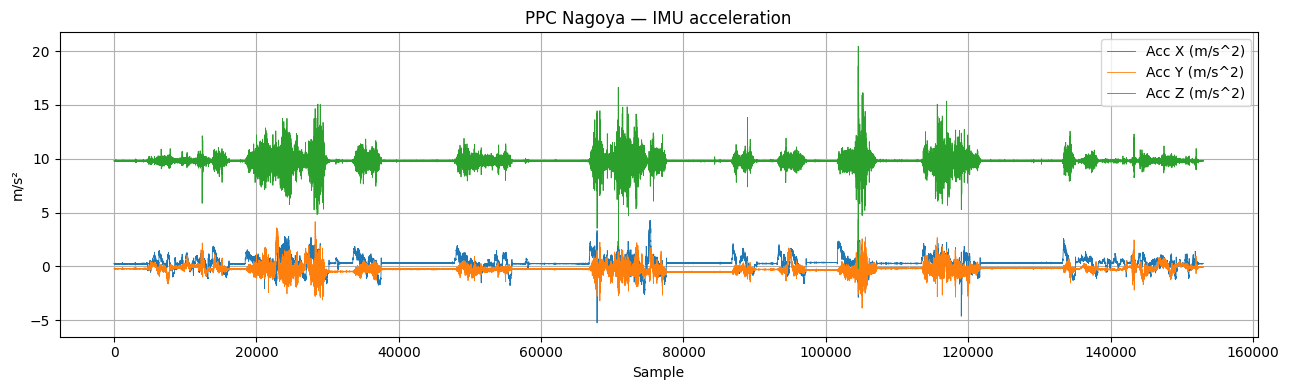

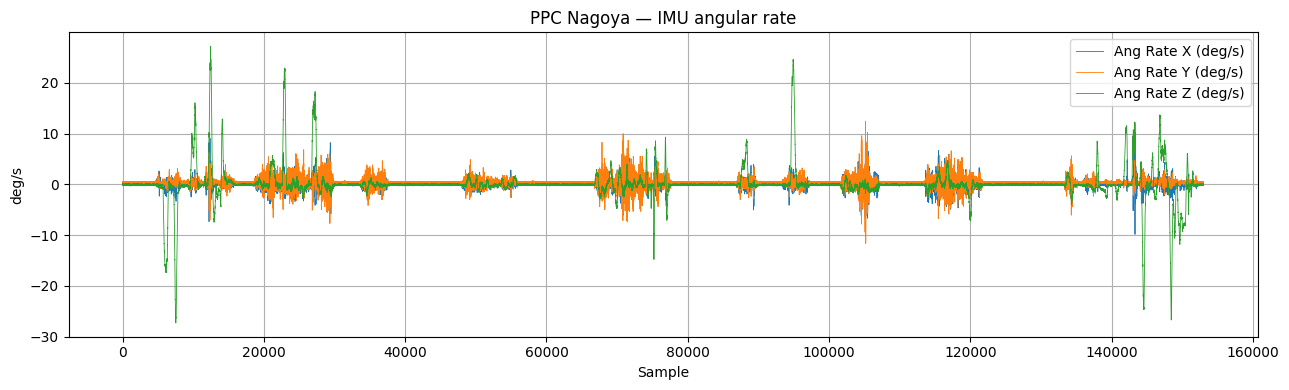


RINEX:
{
  "rover.obs": {
    "file": "rover.obs",
    "header_valid": true,
    "version": "3.04",
    "observation_types": {
      "G": [
        "C1C",
        "L1C",
        "D1C",
        "S1C",
        "C1W",
        "S1W",
        "C2W",
        "L2W",
        "D2W",
        "S2W",
        "C2L",
        "L2L",
        "D2L"
      ],
      " ": [
        "S2L",
        "C5Q",
        "L5Q",
        "D5Q",
        "S5Q",
        "L8Q",
        "D8Q",
        "S8Q",
        "L3Q",
        "D3Q",
        "S3Q",
        "L7I",
        "D7I",
        "S7I",
        "C6I",
        "L6I",
        "D6I",
        "S6I"
      ],
      "E": [
        "C1C",
        "L1C",
        "D1C",
        "S1C",
        "C5Q",
        "L5Q",
        "D5Q",
        "S5Q",
        "C7Q",
        "L7Q",
        "D7Q",
        "S7Q",
        "C8Q"
      ],
      "R": [
        "C1C",
        "L1C",
        "D1C",
        "S1C",
        "C2P",
        "L2P",
        "D2P",
        "S2P",
        "C2C",
 

In [ ]:


# ================================================================
# ARQTECH LABS | VYRA
# PPC NAGOYA — SEMANTIC / PHYSICAL PROFILE
# READ ONLY — NO TRAINING — NO REPOSITORY CHANGES
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import re
import matplotlib.pyplot as plt

ROOT = Path(
    "/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1"
)
OUT = Path("/content/vyra_ppc_validation/semantic_audit")
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 68)
print("VYRA | PPC SEMANTIC AUDIT")
print("=" * 68)

imu = pd.read_csv(ROOT / "imu.csv")
ref = pd.read_csv(ROOT / "reference.csv")

imu.columns = [str(c).strip() for c in imu.columns]
ref.columns = [str(c).strip() for c in ref.columns]

def axis_profile(df, columns):
    result = {}
    for col in columns:
        if col not in df.columns:
            result[col] = {"status": "MISSING"}
            continue

        x = pd.to_numeric(df[col], errors="coerce").to_numpy()
        valid = x[np.isfinite(x)]

        result[col] = {
            "count": int(len(valid)),
            "invalid": int(len(x) - len(valid)),
            "mean": float(np.mean(valid)),
            "std": float(np.std(valid)),
            "min": float(np.min(valid)),
            "max": float(np.max(valid)),
            "p01": float(np.quantile(valid, 0.01)),
            "p50": float(np.quantile(valid, 0.50)),
            "p99": float(np.quantile(valid, 0.99))
        }
    return result

acc_cols = [
    "Acc X (m/s^2)",
    "Acc Y (m/s^2)",
    "Acc Z (m/s^2)"
]

gyro_cols = [
    "Ang Rate X (deg/s)",
    "Ang Rate Y (deg/s)",
    "Ang Rate Z (deg/s)"
]

acc = imu[acc_cols].apply(pd.to_numeric, errors="coerce").to_numpy()
gyro = imu[gyro_cols].apply(pd.to_numeric, errors="coerce").to_numpy()

acc_norm = np.linalg.norm(acc, axis=1)
gyro_norm = np.linalg.norm(gyro, axis=1)

# WGS84 geodetic -> ECEF, used only for consistency diagnostic.
def geodetic_to_ecef(lat_deg, lon_deg, height):
    a = 6378137.0
    f = 1 / 298.257223563
    e2 = f * (2 - f)

    lat = np.deg2rad(lat_deg)
    lon = np.deg2rad(lon_deg)

    N = a / np.sqrt(1 - e2 * np.sin(lat)**2)

    x = (N + height) * np.cos(lat) * np.cos(lon)
    y = (N + height) * np.cos(lat) * np.sin(lon)
    z = (N * (1-e2) + height) * np.sin(lat)

    return np.column_stack([x, y, z])

coordinate_cols = [
    "Latitude (deg)",
    "Longitude (deg)",
    "Ellipsoid Height (m)",
    "ECEF X (m)",
    "ECEF Y (m)",
    "ECEF Z (m)"
]

coordinate_check = {"status": "NOT_AVAILABLE"}

if all(c in ref.columns for c in coordinate_cols):
    lat = ref["Latitude (deg)"].to_numpy(float)
    lon = ref["Longitude (deg)"].to_numpy(float)
    h = ref["Ellipsoid Height (m)"].to_numpy(float)

    ecef_source = ref[
        ["ECEF X (m)", "ECEF Y (m)", "ECEF Z (m)"]
    ].to_numpy(float)

    ecef_calc = geodetic_to_ecef(lat, lon, h)
    residual = np.linalg.norm(ecef_calc - ecef_source, axis=1)

    coordinate_check = {
        "method": "WGS84 geodetic to ECEF",
        "median_difference_m": float(np.median(residual)),
        "p95_difference_m": float(np.quantile(residual, 0.95)),
        "max_difference_m": float(np.max(residual)),
        "finite": bool(np.all(np.isfinite(residual)))
    }

# Basic RINEX 3 inspection, no parser installation.
def inspect_rinex(path):
    result = {
        "file": path.name,
        "header_valid": False,
        "version": None,
        "observation_types": {},
        "epochs": 0,
        "first_epoch": None,
        "last_epoch": None
    }

    with path.open("r", errors="replace") as f:
        header = True

        for line in f:
            if header:
                if "RINEX VERSION / TYPE" in line:
                    result["version"] = line[:9].strip()

                if "SYS / # / OBS TYPES" in line:
                    system = line[0]
                    types = line[7:60].split()
                    result["observation_types"].setdefault(
                        system, []
                    ).extend(types)

                if "END OF HEADER" in line:
                    header = False
                    result["header_valid"] = True
                continue

            if line.startswith(">"):
                result["epochs"] += 1
                if result["first_epoch"] is None:
                    result["first_epoch"] = line.strip()
                result["last_epoch"] = line.strip()

    return result

rinex = {}
for name in ["rover.obs", "base.obs", "base.nav"]:
    path = ROOT / name
    if path.exists():
        rinex[name] = inspect_rinex(path)

# Reference attitude and velocity profiles.
ref_columns = [
    "Roll (deg)", "Pitch (deg)", "Heading (deg)",
    "East Velocity (m/s)",
    "North Velocity (m/s)",
    "Up Velocity (m/s)"
]

reference_profile = axis_profile(ref, ref_columns)

report = {
    "dataset": "PPC Nagoya Run 1",
    "imu_rows": len(imu),
    "reference_rows": len(ref),
    "imu_acceleration": axis_profile(imu, acc_cols),
    "imu_angular_rate": axis_profile(imu, gyro_cols),
    "acceleration_norm_median": float(np.nanmedian(acc_norm)),
    "acceleration_norm_p95": float(np.nanquantile(acc_norm, 0.95)),
    "angular_rate_norm_median_deg_s": float(np.nanmedian(gyro_norm)),
    "angular_rate_norm_p95_deg_s": float(np.nanquantile(gyro_norm, 0.95)),
    "reference_profile": reference_profile,
    "ecef_consistency": coordinate_check,
    "rinex": rinex,
    "limitations": [
        "No IMU calibration performed.",
        "No gravity compensation performed.",
        "No lever-arm correction performed.",
        "No GNSS solution computed.",
        "No sensor fusion performed.",
        "ECEF comparison is a coordinate consistency diagnostic only."
    ]
}

report_path = OUT / "semantic_physical_report.json"
report_path.write_text(json.dumps(report, indent=2))

# IMU plots
fig, ax = plt.subplots(figsize=(13, 4))
for i, col in enumerate(acc_cols):
    ax.plot(imu.index, acc[:, i], label=col, linewidth=0.6)
ax.set_title("PPC Nagoya — IMU acceleration")
ax.set_xlabel("Sample")
ax.set_ylabel("m/s²")
ax.legend()
ax.grid(True)
fig.tight_layout()
fig.savefig(OUT / "imu_acceleration.png", dpi=140)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(13, 4))
for i, col in enumerate(gyro_cols):
    ax.plot(imu.index, gyro[:, i], label=col, linewidth=0.6)
ax.set_title("PPC Nagoya — IMU angular rate")
ax.set_xlabel("Sample")
ax.set_ylabel("deg/s")
ax.legend()
ax.grid(True)
fig.tight_layout()
fig.savefig(OUT / "imu_angular_rate.png", dpi=140)
plt.show()
plt.close(fig)

print("\nRINEX:")
print(json.dumps(rinex, indent=2))

print("\nECEF CONSISTENCY:")
print(json.dumps(coordinate_check, indent=2))

print("\nREPORT:")
print(report_path)

print("\nAUDIT COMPLETE — NO SOURCE DATA MODIFIED")

ARQTECH LABS | VYRA — IMU QUALITY AUDIT


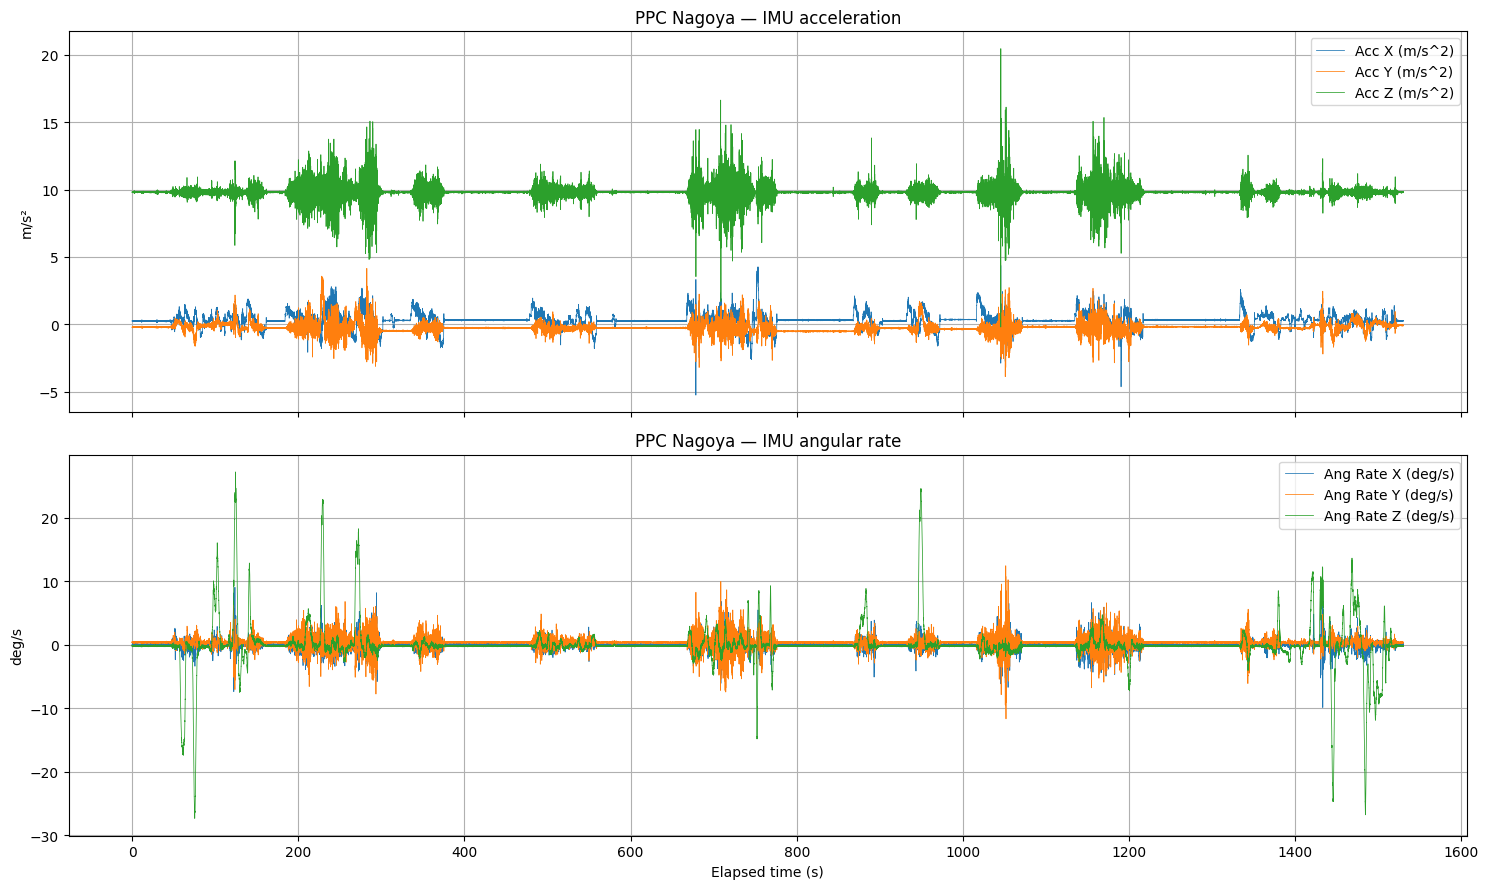

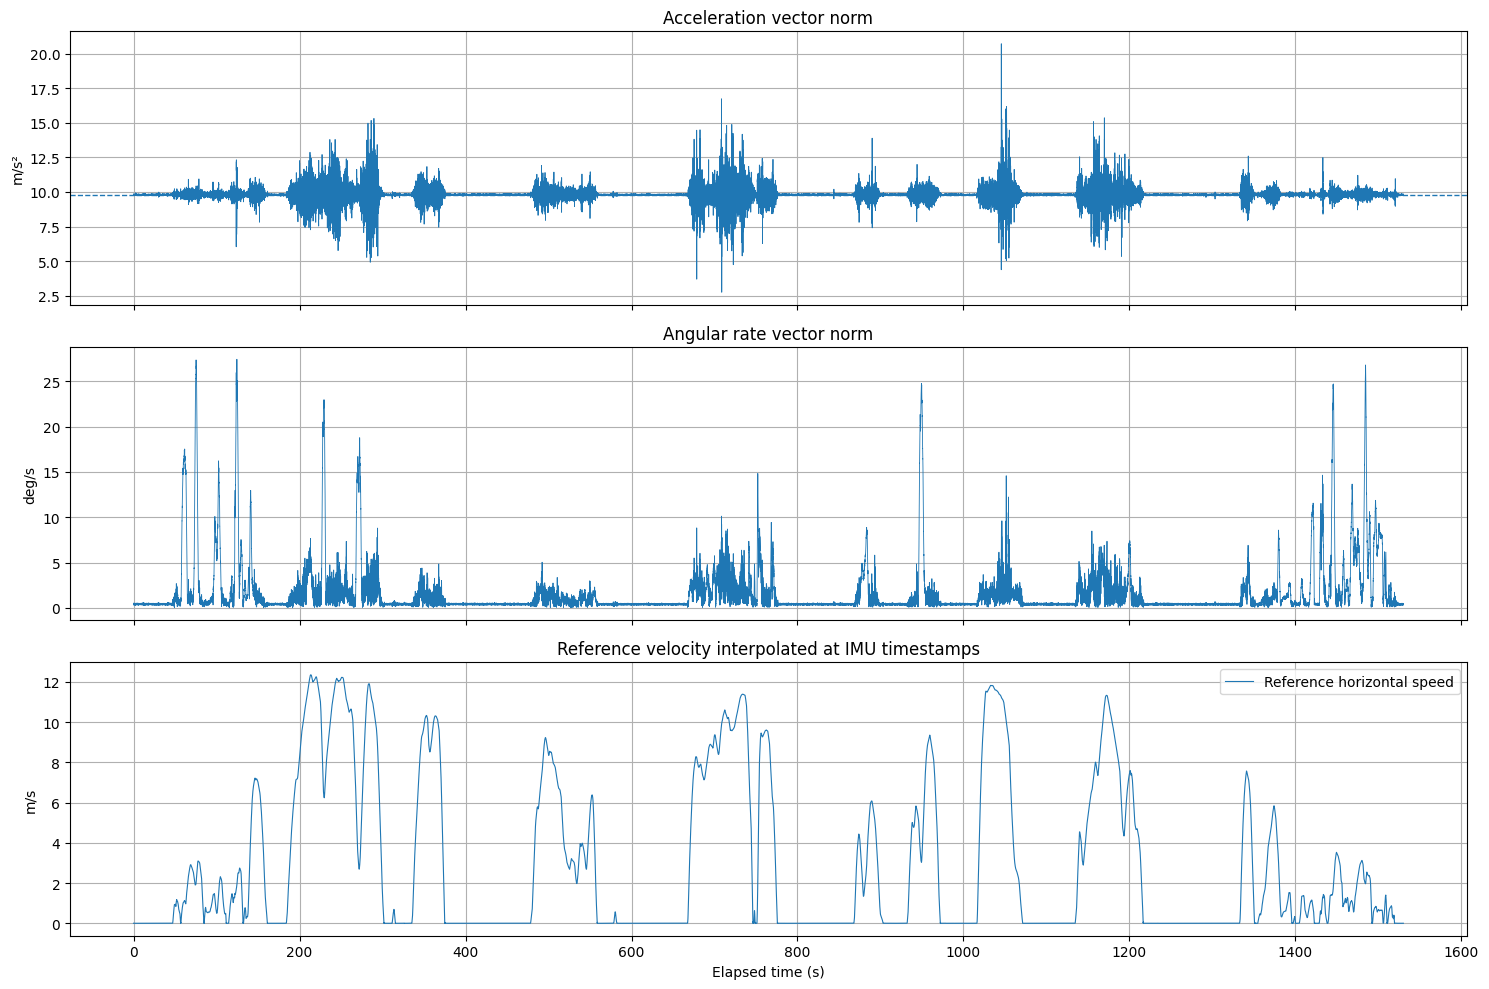


VYRA | IMU QUALITY AUDIT — SUMMARY

TEMPORAL:
{
  "rows": 153001,
  "valid_complete_rows": 153001,
  "invalid_rows": 0,
  "strictly_increasing": true,
  "duplicate_or_nonpositive_intervals": 0,
  "interval_median_s": 0.010000000009313226,
  "interval_min_s": 0.009999999892897904,
  "interval_max_s": 0.010000000009313226,
  "frequency_median_hz": 99.99999990686774,
  "duration_s": 1530.0
}

VECTOR NORMS:
{
  "acceleration_norm_m_s2": {
    "count": 153001,
    "mean": 9.822754674881521,
    "std": 0.40321064759589015,
    "min": 2.7495702564105358,
    "max": 20.71392546876165,
    "p0_1": 7.065261651669827,
    "p1": 8.561275346302821,
    "median": 9.810031689462386,
    "p99": 11.151689694688368,
    "p99_9": 12.683501212619683
  },
  "angular_rate_norm_deg_s": {
    "count": 153001,
    "mean": 1.68231618587059,
    "std": 3.118969971498209,
    "min": 0.021578345627040085,
    "max": 27.420682260385135,
    "p0_1": 0.12193748398257198,
    "p1": 0.23751644679895326,
    "median": 

In [ ]:


# =====================================================================
# ARQTECH LABS | VYRA
# PPC NAGOYA RUN 1 — IMU QUALITY AUDIT
# READ ONLY | NO TRAINING | NO GIT CHANGES
# =====================================================================

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(
    "/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1"
)
OUT = Path("/content/vyra_ppc_validation/imu_quality_audit")
OUT.mkdir(parents=True, exist_ok=True)

IMU_FILE = ROOT / "imu.csv"
REF_FILE = ROOT / "reference.csv"

assert IMU_FILE.is_file(), f"IMU não encontrado: {IMU_FILE}"
assert REF_FILE.is_file(), f"Referência não encontrada: {REF_FILE}"

print("=" * 72)
print("ARQTECH LABS | VYRA — IMU QUALITY AUDIT")
print("=" * 72)

# ---------------------------------------------------------------------
# 1. LEITURA E NORMALIZAÇÃO DOS NOMES
# ---------------------------------------------------------------------

imu = pd.read_csv(IMU_FILE)
ref = pd.read_csv(REF_FILE)

imu.columns = [str(c).strip() for c in imu.columns]
ref.columns = [str(c).strip() for c in ref.columns]

acc_cols = [
    "Acc X (m/s^2)",
    "Acc Y (m/s^2)",
    "Acc Z (m/s^2)"
]

gyro_cols = [
    "Ang Rate X (deg/s)",
    "Ang Rate Y (deg/s)",
    "Ang Rate Z (deg/s)"
]

time_col = "GPS TOW (s)"

required_imu = [time_col] + acc_cols + gyro_cols
required_ref = [
    time_col,
    "East Velocity (m/s)",
    "North Velocity (m/s)",
    "Up Velocity (m/s)",
    "Heading (deg)"
]

for col in required_imu:
    assert col in imu.columns, f"Coluna IMU ausente: {col}"

for col in required_ref:
    assert col in ref.columns, f"Coluna referência ausente: {col}"

# Converter somente as colunas utilizadas.
for col in required_imu:
    imu[col] = pd.to_numeric(imu[col], errors="coerce")

for col in required_ref:
    ref[col] = pd.to_numeric(ref[col], errors="coerce")

# ---------------------------------------------------------------------
# 2. INTEGRIDADE E TEMPORALIDADE
# ---------------------------------------------------------------------

t = imu[time_col].to_numpy(dtype=float)
tr = ref[time_col].to_numpy(dtype=float)

imu_values = imu[acc_cols + gyro_cols].to_numpy(dtype=float)

finite_rows = (
    np.isfinite(t) &
    np.all(np.isfinite(imu_values), axis=1)
)

dt = np.diff(t)
positive_dt = dt[np.isfinite(dt) & (dt > 0)]

temporal = {
    "rows": int(len(imu)),
    "valid_complete_rows": int(finite_rows.sum()),
    "invalid_rows": int((~finite_rows).sum()),
    "strictly_increasing": bool(np.all(dt > 0)),
    "duplicate_or_nonpositive_intervals": int(np.sum(dt <= 0)),
    "interval_median_s": float(np.median(positive_dt)),
    "interval_min_s": float(np.min(positive_dt)),
    "interval_max_s": float(np.max(positive_dt)),
    "frequency_median_hz": float(1 / np.median(positive_dt)),
    "duration_s": float(t[-1] - t[0])
}

# ---------------------------------------------------------------------
# 3. PERFIL ESTATÍSTICO E VALORES EXTREMOS
# ---------------------------------------------------------------------

def describe_signal(values):
    values = np.asarray(values, dtype=float)
    valid = values[np.isfinite(values)]

    if len(valid) == 0:
        return {"status": "NO_VALID_VALUES"}

    q = np.quantile(valid, [0.001, 0.01, 0.50, 0.99, 0.999])

    return {
        "count": int(len(valid)),
        "mean": float(np.mean(valid)),
        "std": float(np.std(valid)),
        "min": float(np.min(valid)),
        "max": float(np.max(valid)),
        "p0_1": float(q[0]),
        "p1": float(q[1]),
        "median": float(q[2]),
        "p99": float(q[3]),
        "p99_9": float(q[4])
    }

signals = {}

for col in acc_cols + gyro_cols:
    signals[col] = describe_signal(imu[col].to_numpy())

# ---------------------------------------------------------------------
# 4. NORMAS DOS VETORES
# ---------------------------------------------------------------------

acc = imu[acc_cols].to_numpy(dtype=float)
gyro = imu[gyro_cols].to_numpy(dtype=float)

acc_norm = np.linalg.norm(acc, axis=1)
gyro_norm = np.linalg.norm(gyro, axis=1)

norms = {
    "acceleration_norm_m_s2": describe_signal(acc_norm),
    "angular_rate_norm_deg_s": describe_signal(gyro_norm)
}

# ---------------------------------------------------------------------
# 5. DETECÇÃO ROBUSTA DE PICOS CANDIDATOS
# ---------------------------------------------------------------------
# Rolling median + MAD.
# Estes pontos são candidatos estatísticos, não falhas confirmadas.

def robust_spike_audit(series, window=501, threshold=8.0):
    s = pd.Series(series, dtype=float)

    rolling_median = s.rolling(
        window=window,
        center=True,
        min_periods=max(25, window // 4)
    ).median()

    deviation = (s - rolling_median).abs()

    rolling_mad = deviation.rolling(
        window=window,
        center=True,
        min_periods=max(25, window // 4)
    ).median()

    robust_sigma = 1.4826 * rolling_mad
    score = deviation / robust_sigma.replace(0, np.nan)

    # Quando MAD é zero, não inferimos spike automaticamente.
    mask = score > threshold

    return {
        "candidate_count": int(mask.sum()),
        "candidate_fraction": float(mask.mean()),
        "threshold_robust_sigma": threshold,
        "window_samples": window,
        "candidate_indices": np.flatnonzero(
            mask.fillna(False).to_numpy()
        )[:100].tolist()
    }

spikes = {}

for col in acc_cols + gyro_cols:
    spikes[col] = robust_spike_audit(
        imu[col].to_numpy()
    )

# ---------------------------------------------------------------------
# 6. REPETIÇÕES CONSECUTIVAS E PLATEAUS
# ---------------------------------------------------------------------

def repeated_value_audit(values):
    x = np.asarray(values, dtype=float)
    valid = np.isfinite(x)

    same = (
        valid[1:] &
        valid[:-1] &
        (x[1:] == x[:-1])
    )

    longest = 0
    current = 0

    for is_same in same:
        if is_same:
            current += 1
            longest = max(longest, current + 1)
        else:
            current = 0

    return {
        "equal_adjacent_pairs": int(same.sum()),
        "equal_pair_fraction": float(same.mean()),
        "longest_identical_run_samples": int(longest)
    }

repetition = {
    col: repeated_value_audit(imu[col].to_numpy())
    for col in acc_cols + gyro_cols
}

# ---------------------------------------------------------------------
# 7. CANDIDATOS A CLIPPING — NÃO CONFIRMAR SATURAÇÃO
# ---------------------------------------------------------------------
# Verifica concentração exata nos extremos observados.
# Sem datasheet/configuração do sensor, não prova clipping.

extreme_values = {}

for col in acc_cols + gyro_cols:
    x = imu[col].to_numpy(dtype=float)
    x = x[np.isfinite(x)]

    vmin = np.min(x)
    vmax = np.max(x)

    extreme_values[col] = {
        "observed_min": float(vmin),
        "count_at_observed_min": int(np.sum(x == vmin)),
        "observed_max": float(vmax),
        "count_at_observed_max": int(np.sum(x == vmax)),
        "interpretation": "observed extrema only; clipping unconfirmed"
    }

# ---------------------------------------------------------------------
# 8. COERÊNCIA TEMPORAL COM A REFERÊNCIA
# ---------------------------------------------------------------------

ref_valid = (
    np.isfinite(tr) &
    np.isfinite(ref["East Velocity (m/s)"].to_numpy()) &
    np.isfinite(ref["North Velocity (m/s)"].to_numpy()) &
    np.isfinite(ref["Up Velocity (m/s)"].to_numpy())
)

ref_clean = ref.loc[ref_valid].copy()

ref_t = ref_clean[time_col].to_numpy(dtype=float)

assert len(ref_t) >= 2
assert np.all(np.diff(ref_t) > 0), (
    "Timestamps da referência não são estritamente crescentes."
)

# Velocidade da referência interpolada nos instantes IMU.
# Isto é apenas alinhamento temporal, não integração de sensores.

east = np.interp(
    t, ref_t,
    ref_clean["East Velocity (m/s)"].to_numpy()
)

north = np.interp(
    t, ref_t,
    ref_clean["North Velocity (m/s)"].to_numpy()
)

up = np.interp(
    t, ref_t,
    ref_clean["Up Velocity (m/s)"].to_numpy()
)

reference_speed_3d = np.sqrt(east**2 + north**2 + up**2)
reference_speed_horizontal = np.sqrt(east**2 + north**2)

reference_alignment = {
    "imu_start_tow_s": float(t[0]),
    "imu_end_tow_s": float(t[-1]),
    "reference_start_tow_s": float(ref_t[0]),
    "reference_end_tow_s": float(ref_t[-1]),
    "imu_samples_inside_reference_interval": int(
        np.sum((t >= ref_t[0]) & (t <= ref_t[-1]))
    ),
    "reference_horizontal_speed_median": float(
        np.median(reference_speed_horizontal)
    ),
    "reference_horizontal_speed_p95": float(
        np.quantile(reference_speed_horizontal, 0.95)
    ),
    "reference_3d_speed_median": float(
        np.median(reference_speed_3d)
    )
}

# ---------------------------------------------------------------------
# 9. JANELAS DE BAIXA DINÂMICA — APENAS CANDIDATAS
# ---------------------------------------------------------------------
# Heurística exploratória: norma da aceleração próxima de g
# e baixa norma angular. Não equivale a detectar repouso verdadeiro.

low_dynamic = (
    np.isfinite(acc_norm) &
    np.isfinite(gyro_norm) &
    (np.abs(acc_norm - 9.80665) < 0.35) &
    (gyro_norm < 1.0)
)

low_dynamic_report = {
    "candidate_samples": int(low_dynamic.sum()),
    "candidate_fraction": float(low_dynamic.mean()),
    "candidate_duration_approx_s": float(
        low_dynamic.sum() * np.median(positive_dt)
    ),
    "warning": (
        "Heuristic only. Requires frame/orientation and calibration "
        "validation before being called stationary."
    )
}

# ---------------------------------------------------------------------
# 10. GRÁFICOS
# ---------------------------------------------------------------------

# Aceleração e giroscópio em tempo real aproximado.
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

for i, col in enumerate(acc_cols):
    axes[0].plot(t - t[0], acc[:, i], label=col, linewidth=0.55)

axes[0].set_title("PPC Nagoya — IMU acceleration")
axes[0].set_ylabel("m/s²")
axes[0].legend()
axes[0].grid(True)

for i, col in enumerate(gyro_cols):
    axes[1].plot(t - t[0], gyro[:, i], label=col, linewidth=0.55)

axes[1].set_title("PPC Nagoya — IMU angular rate")
axes[1].set_xlabel("Elapsed time (s)")
axes[1].set_ylabel("deg/s")
axes[1].legend()
axes[1].grid(True)

fig.tight_layout()
fig.savefig(OUT / "01_imu_signals_vs_time.png", dpi=150)
plt.show()
plt.close(fig)

# Normas e velocidade de referência.
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

axes[0].plot(t - t[0], acc_norm, linewidth=0.6)
axes[0].axhline(9.80665, linestyle="--", linewidth=1)
axes[0].set_title("Acceleration vector norm")
axes[0].set_ylabel("m/s²")
axes[0].grid(True)

axes[1].plot(t - t[0], gyro_norm, linewidth=0.6)
axes[1].set_title("Angular rate vector norm")
axes[1].set_ylabel("deg/s")
axes[1].grid(True)

axes[2].plot(
    t - t[0],
    reference_speed_horizontal,
    label="Reference horizontal speed",
    linewidth=0.8
)
axes[2].set_title("Reference velocity interpolated at IMU timestamps")
axes[2].set_ylabel("m/s")
axes[2].set_xlabel("Elapsed time (s)")
axes[2].legend()
axes[2].grid(True)

fig.tight_layout()
fig.savefig(OUT / "02_norms_and_reference_speed.png", dpi=150)
plt.show()
plt.close(fig)

# ---------------------------------------------------------------------
# 11. RELATÓRIO
# ---------------------------------------------------------------------

def sha256_file(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

report = {
    "project": "VYRA",
    "dataset": "PPC Nagoya Run 1",
    "audit": "IMU Quality Audit",
    "read_only": True,
    "source_files": {
        "imu_csv_sha256": sha256_file(IMU_FILE),
        "reference_csv_sha256": sha256_file(REF_FILE)
    },
    "temporal_integrity": temporal,
    "signal_statistics": signals,
    "vector_norms": norms,
    "robust_spike_candidates": spikes,
    "repeated_values": repetition,
    "observed_extrema": extreme_values,
    "reference_alignment": reference_alignment,
    "low_dynamic_candidates": low_dynamic_report,
    "limitations": [
        "No sensor datasheet full-scale limits were applied.",
        "No clipping or saturation was confirmed.",
        "No IMU calibration was performed.",
        "No gravity compensation was performed.",
        "No lever-arm correction was performed.",
        "No sensor fusion or state estimation was performed.",
        "Reference velocity was interpolated only for time alignment.",
        "Low-dynamic windows are heuristic candidates only."
    ]
}

report_path = OUT / "imu_quality_report.json"
report_path.write_text(json.dumps(report, indent=2))

# CSV de amostras candidatas para inspeção.
candidate_rows = []

for col, result in spikes.items():
    for idx in result["candidate_indices"]:
        candidate_rows.append({
            "signal": col,
            "sample_index": idx,
            "gps_tow_s": float(t[idx]),
            "value": float(imu.iloc[idx][col])
        })

pd.DataFrame(candidate_rows).to_csv(
    OUT / "spike_candidates.csv",
    index=False
)

print("\n" + "=" * 72)
print("VYRA | IMU QUALITY AUDIT — SUMMARY")
print("=" * 72)

print("\nTEMPORAL:")
print(json.dumps(temporal, indent=2))

print("\nVECTOR NORMS:")
print(json.dumps(norms, indent=2))

print("\nREFERENCE ALIGNMENT:")
print(json.dumps(reference_alignment, indent=2))

print("\nLOW-DYNAMIC CANDIDATES:")
print(json.dumps(low_dynamic_report, indent=2))

print("\nSPIKE CANDIDATES:")
for col, result in spikes.items():
    print(
        f"{col}: {result['candidate_count']} "
        f"({result['candidate_fraction']:.4%})"
    )

print("\nOUTPUTS:")
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(f"{p.name} | {p.stat().st_size / 1024:.1f} KB")

print("\nREPORT:", report_path)
print("SOURCE DATA MODIFIED: NO")
print("TRAINING EXECUTED: NO")
print("GITHUB MODIFIED: NO")
print("=" * 72)

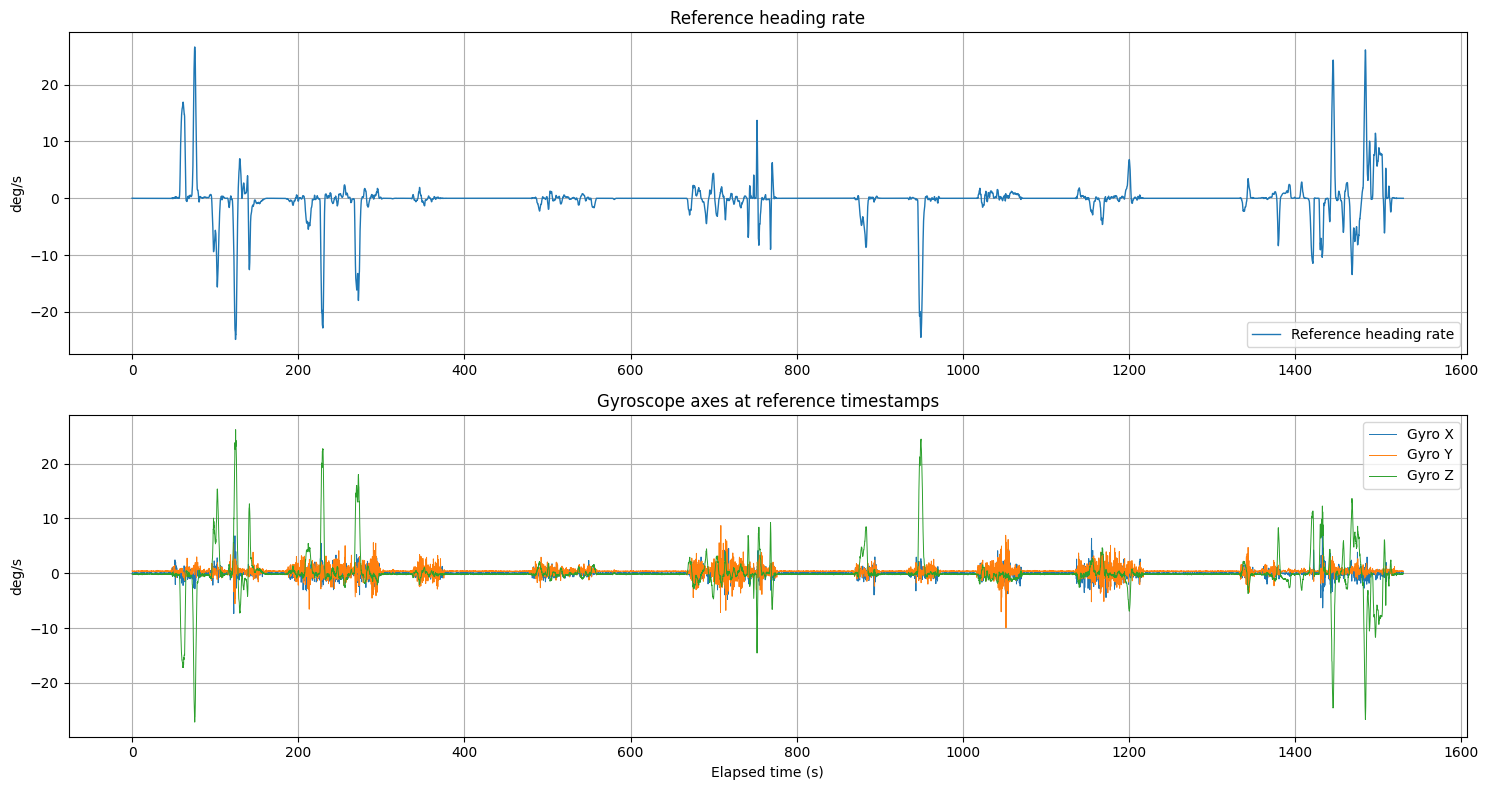

VYRA | AXIS CORRELATION AUDIT

HEADING RATE:
{
  "reference_samples": 7651,
  "heading_rate_mean_deg_s": -0.17504280486234558,
  "heading_rate_std_deg_s": 3.343046495377927,
  "heading_rate_p95_abs_deg_s": 6.837499999664612,
  "heading_rate_max_abs_deg_s": 26.624999998333795
}

BEST CORRELATION PER AXIS:
axis  lag_samples  lag_seconds  correlation
   X            5          1.0    -0.158298
   Y            0          0.0     0.066447
   Z            0          0.0    -0.999164

OUTPUT: /content/vyra_ppc_validation/axis_correlation_audit
SOURCE MODIFIED: NO
GITHUB MODIFIED: NO


In [ ]:


# ================================================================
# VYRA | PPC NAGOYA
# IMU ↔ REFERENCE ROTATION CORRELATION
# READ ONLY
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt

ROOT = Path(
    "/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1"
)
OUT = Path("/content/vyra_ppc_validation/axis_correlation_audit")
OUT.mkdir(parents=True, exist_ok=True)

imu = pd.read_csv(ROOT / "imu.csv")
ref = pd.read_csv(ROOT / "reference.csv")

imu.columns = imu.columns.str.strip()
ref.columns = ref.columns.str.strip()

t = imu["GPS TOW (s)"].to_numpy(float)
tr = ref["GPS TOW (s)"].to_numpy(float)

gyro_cols = [
    "Ang Rate X (deg/s)",
    "Ang Rate Y (deg/s)",
    "Ang Rate Z (deg/s)"
]

gyro = imu[gyro_cols].to_numpy(float)

heading = np.unwrap(
    np.deg2rad(ref["Heading (deg)"].to_numpy(float))
)

# Derivada angular em rad/s convertida para deg/s.
heading_rate = np.rad2deg(
    np.gradient(heading, tr)
)

# Giroscópio interpolado nos instantes da referência.
gyro_ref = np.column_stack([
    np.interp(tr, t, gyro[:, i])
    for i in range(3)
])

# Correlação com lags de -1 a +1 segundo.
# 5 Hz: cada amostra equivale aproximadamente a 0,2 s.
max_lag_samples = 5

results = []

for axis_idx, axis_name in enumerate(["X", "Y", "Z"]):
    x = gyro_ref[:, axis_idx]

    for lag in range(-max_lag_samples, max_lag_samples + 1):
        if lag < 0:
            a = x[-lag:]
            b = heading_rate[:len(heading_rate) + lag]
        elif lag > 0:
            a = x[:-lag]
            b = heading_rate[lag:]
        else:
            a = x
            b = heading_rate

        valid = np.isfinite(a) & np.isfinite(b)
        a, b = a[valid], b[valid]

        if len(a) < 10 or np.std(a) == 0 or np.std(b) == 0:
            corr = None
        else:
            corr = float(np.corrcoef(a, b)[0, 1])

        results.append({
            "axis": axis_name,
            "lag_samples": lag,
            "lag_seconds": lag * 0.2,
            "correlation": corr
        })

results_df = pd.DataFrame(results)

# Melhor correlação absoluta por eixo.
best = []

for axis in ["X", "Y", "Z"]:
    subset = results_df[
        (results_df["axis"] == axis) &
        results_df["correlation"].notna()
    ].copy()

    if len(subset):
        row = subset.loc[
            subset["correlation"].abs().idxmax()
        ]
        best.append(row.to_dict())

best_df = pd.DataFrame(best)

# Estatísticas gerais de heading.
heading_report = {
    "reference_samples": int(len(ref)),
    "heading_rate_mean_deg_s": float(np.mean(heading_rate)),
    "heading_rate_std_deg_s": float(np.std(heading_rate)),
    "heading_rate_p95_abs_deg_s": float(
        np.quantile(np.abs(heading_rate), 0.95)
    ),
    "heading_rate_max_abs_deg_s": float(
        np.max(np.abs(heading_rate))
    )
}

# Salvar resultados.
results_df.to_csv(
    OUT / "all_axis_lag_correlations.csv",
    index=False
)

best_df.to_csv(
    OUT / "best_axis_correlations.csv",
    index=False
)

report = {
    "dataset": "PPC Nagoya Run 1",
    "method": "Pearson correlation between gyro axes and reference heading rate",
    "heading_rate": heading_report,
    "best_correlations": best,
    "limitations": [
        "Correlation does not establish physical axis alignment.",
        "Heading convention and sign are not independently confirmed.",
        "Reference heading derivative is sampled at 5 Hz.",
        "No IMU calibration or mounting rotation was applied.",
        "No sensor fusion or state estimation was performed."
    ]
}

(OUT / "axis_correlation_report.json").write_text(
    json.dumps(report, indent=2)
)

# Plot comparison.
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

axes[0].plot(
    tr - tr[0],
    heading_rate,
    label="Reference heading rate",
    linewidth=1
)
axes[0].set_title("Reference heading rate")
axes[0].set_ylabel("deg/s")
axes[0].grid(True)
axes[0].legend()

for i, axis in enumerate(["X", "Y", "Z"]):
    axes[1].plot(
        tr - tr[0],
        gyro_ref[:, i],
        label=f"Gyro {axis}",
        linewidth=0.7
    )

axes[1].set_title("Gyroscope axes at reference timestamps")
axes[1].set_xlabel("Elapsed time (s)")
axes[1].set_ylabel("deg/s")
axes[1].grid(True)
axes[1].legend()

fig.tight_layout()
fig.savefig(
    OUT / "heading_rate_vs_gyro.png",
    dpi=150
)
plt.show()
plt.close(fig)

print("=" * 68)
print("VYRA | AXIS CORRELATION AUDIT")
print("=" * 68)

print("\nHEADING RATE:")
print(json.dumps(heading_report, indent=2))

print("\nBEST CORRELATION PER AXIS:")
print(best_df.to_string(index=False))

print("\nOUTPUT:", OUT)
print("SOURCE MODIFIED: NO")
print("GITHUB MODIFIED: NO")

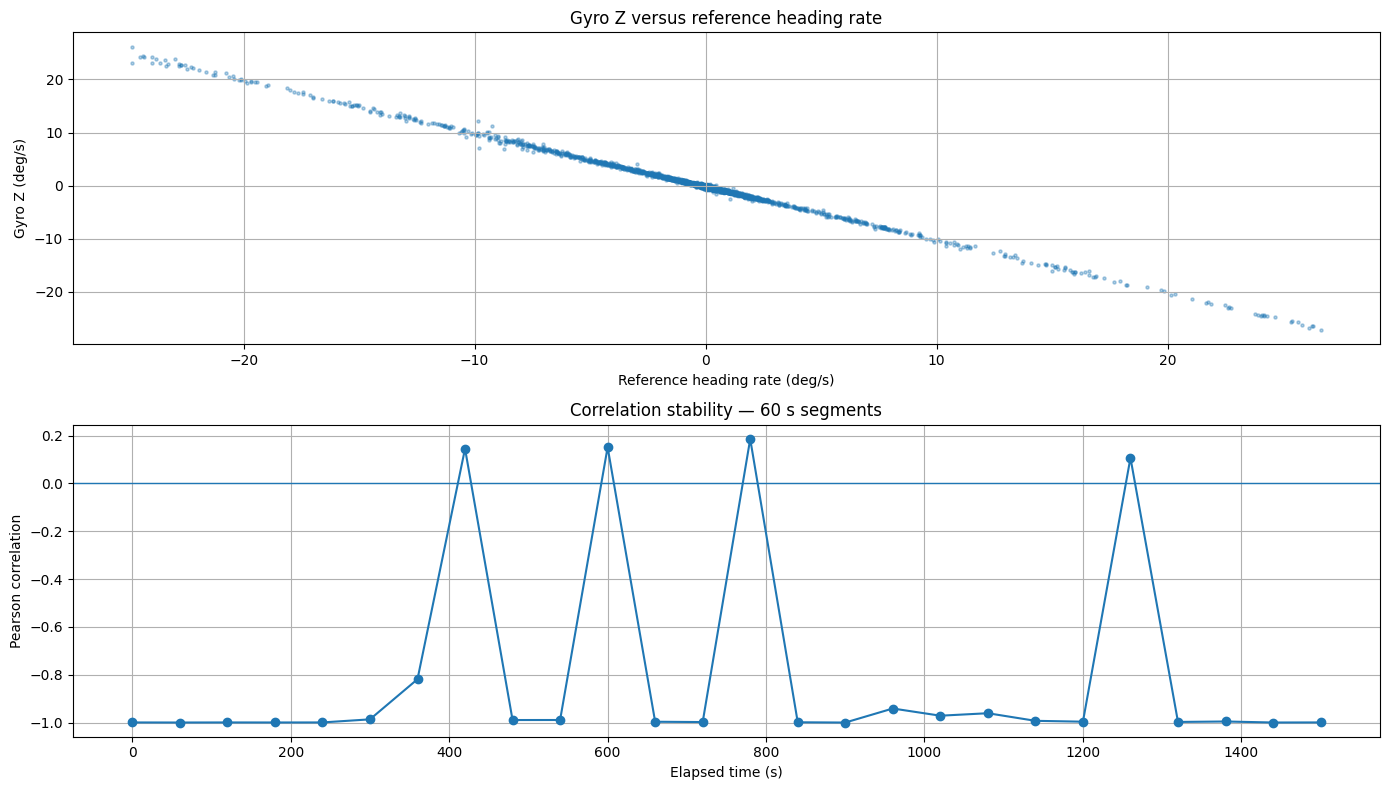

VYRA | GYRO Z CONSISTENCY

FULL SEQUENCE:
{
  "n": 7651,
  "correlation": -0.9991635990363027,
  "slope_gyroZ_per_heading_rate": -1.0025660024152294,
  "intercept_deg_s": -0.16278496603730438,
  "rmse_deg_s": 0.1371671820226689,
  "mae_deg_s": 0.08064949920675428,
  "residual_p95_abs_deg_s": 0.2598579094491208
}

ANGULAR DYNAMIC SUBSET:
{
  "n": 2016,
  "correlation": -0.9994246702449839,
  "slope_gyroZ_per_heading_rate": -1.002597192667708,
  "intercept_deg_s": -0.16313506879490108,
  "rmse_deg_s": 0.22050168647944132,
  "mae_deg_s": 0.13920673317240662,
  "residual_p95_abs_deg_s": 0.379752613387073
}

BEST LAG:
{
  "lag_s": 8.881784197001252e-16,
  "correlation": -0.9991635990363027,
  "absolute_correlation": 0.9991635990363027
}

SEGMENTS:
 start_elapsed_s  end_elapsed_s   n  correlation  slope_gyroZ_per_heading_rate  intercept_deg_s  rmse_deg_s  mae_deg_s  residual_p95_abs_deg_s
             0.0           60.0 300    -0.999391                     -1.001846        -0.161510    0.074

In [ ]:


# ================================================================
# ARQTECH LABS | VYRA
# PPC — GYRO Z / HEADING CONSISTENCY VALIDATION
# READ ONLY | NO TRAINING | NO GITHUB CHANGES
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt

ROOT = Path(
    "/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1"
)
OUT = Path(
    "/content/vyra_ppc_validation/gyro_z_consistency"
)
OUT.mkdir(parents=True, exist_ok=True)

imu = pd.read_csv(ROOT / "imu.csv")
ref = pd.read_csv(ROOT / "reference.csv")

imu.columns = imu.columns.str.strip()
ref.columns = ref.columns.str.strip()

t = imu["GPS TOW (s)"].to_numpy(float)
tr = ref["GPS TOW (s)"].to_numpy(float)

gyro_z = imu["Ang Rate Z (deg/s)"].to_numpy(float)

# Heading em radianos, desembrulhado para evitar saltos em +/-180°.
heading = np.unwrap(
    np.deg2rad(ref["Heading (deg)"].to_numpy(float))
)

heading_rate = np.rad2deg(
    np.gradient(heading, tr)
)

# Interpolação do gyro nos timestamps da referência.
gyro_z_ref = np.interp(tr, t, gyro_z)

def metrics(x, y):
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]

    if len(x) < 10 or np.std(x) == 0 or np.std(y) == 0:
        return {"n": int(len(x)), "correlation": None}

    slope, intercept = np.polyfit(x, y, 1)
    predicted = slope * x + intercept
    residual = y - predicted

    return {
        "n": int(len(x)),
        "correlation": float(np.corrcoef(x, y)[0, 1]),
        "slope_gyroZ_per_heading_rate": float(slope),
        "intercept_deg_s": float(intercept),
        "rmse_deg_s": float(np.sqrt(np.mean(residual**2))),
        "mae_deg_s": float(np.mean(np.abs(residual))),
        "residual_p95_abs_deg_s": float(
            np.quantile(np.abs(residual), 0.95)
        )
    }

# Teste geral e somente nos períodos de dinâmica angular.
full = metrics(heading_rate, gyro_z_ref)

dynamic_mask = np.abs(heading_rate) >= 0.5
dynamic = metrics(
    heading_rate[dynamic_mask],
    gyro_z_ref[dynamic_mask]
)

# Correlação por segmentos de 60 segundos.
segment_results = []
segment_duration = 60.0

for start in np.arange(
    tr[0], tr[-1], segment_duration
):
    mask = (
        (tr >= start) &
        (tr < start + segment_duration)
    )

    if mask.sum() < 20:
        continue

    result = metrics(
        heading_rate[mask],
        gyro_z_ref[mask]
    )

    segment_results.append({
        "start_elapsed_s": float(start - tr[0]),
        "end_elapsed_s": float(
            min(start + segment_duration, tr[-1]) - tr[0]
        ),
        **result
    })

# Busca de atraso usando deslocamentos de 20 ms.
# Convenção: lag positivo amostra o gyro em instante posterior.
lag_results = []

for lag in np.arange(-1.0, 1.0001, 0.02):
    shifted = np.interp(
        tr + lag,
        t,
        gyro_z,
        left=np.nan,
        right=np.nan
    )

    valid = (
        np.isfinite(shifted) &
        np.isfinite(heading_rate)
    )

    if valid.sum() < 20:
        continue

    corr = np.corrcoef(
        heading_rate[valid],
        shifted[valid]
    )[0, 1]

    lag_results.append({
        "lag_s": float(lag),
        "correlation": float(corr),
        "absolute_correlation": float(abs(corr))
    })

lag_df = pd.DataFrame(lag_results)
best_lag = lag_df.loc[
    lag_df["absolute_correlation"].idxmax()
].to_dict()

segments_df = pd.DataFrame(segment_results)

# Relatório
report = {
    "dataset": "PPC Nagoya Run 1",
    "comparison": "reference heading rate vs interpolated IMU gyro Z",
    "full_sequence": full,
    "angular_dynamic_subset_abs_heading_rate_ge_0_5_deg_s": dynamic,
    "best_lag": best_lag,
    "lag_search_range_s": [-1.0, 1.0],
    "lag_step_s": 0.02,
    "segment_duration_s": segment_duration,
    "segments": segment_results,
    "limitations": [
        "Correlation does not prove physical sensor-axis alignment.",
        "No mounting rotation or calibration was applied.",
        "Heading convention must be confirmed.",
        "Reference heading derivative is sampled at approximately 5 Hz.",
        "Linear fit is diagnostic, not a calibration result."
    ]
}

(OUT / "gyro_z_consistency_report.json").write_text(
    json.dumps(report, indent=2)
)

segments_df.to_csv(
    OUT / "segment_correlations.csv",
    index=False
)

lag_df.to_csv(
    OUT / "lag_sweep.csv",
    index=False
)

# Gráficos
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].scatter(
    heading_rate,
    gyro_z_ref,
    s=5,
    alpha=0.35
)
axes[0].set_xlabel("Reference heading rate (deg/s)")
axes[0].set_ylabel("Gyro Z (deg/s)")
axes[0].set_title("Gyro Z versus reference heading rate")
axes[0].grid(True)

axes[1].plot(
    segments_df["start_elapsed_s"],
    segments_df["correlation"],
    marker="o"
)
axes[1].axhline(0, linewidth=1)
axes[1].set_xlabel("Elapsed time (s)")
axes[1].set_ylabel("Pearson correlation")
axes[1].set_title("Correlation stability — 60 s segments")
axes[1].grid(True)

fig.tight_layout()
fig.savefig(OUT / "gyro_z_consistency.png", dpi=160)
plt.show()
plt.close(fig)

print("=" * 68)
print("VYRA | GYRO Z CONSISTENCY")
print("=" * 68)
print("\nFULL SEQUENCE:")
print(json.dumps(full, indent=2))
print("\nANGULAR DYNAMIC SUBSET:")
print(json.dumps(dynamic, indent=2))
print("\nBEST LAG:")
print(json.dumps(best_lag, indent=2))
print("\nSEGMENTS:")
print(segments_df.to_string(index=False))
print("\nOUTPUT:", OUT)
print("SOURCE DATA MODIFIED: NO")
print("TRAINING: NOT EXECUTED")
print("GITHUB: NOT MODIFIED")

In [ ]:


# ================================================================
# VYRA | PPC — TEMPORAL HOLDOUT VALIDATION
# Gyro Z vs Reference Heading Rate
# READ ONLY
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json

ROOT = Path(
    "/content/vyra_ppc_validation/dataset/PPC-Dataset/nagoya/run1"
)
OUT = Path(
    "/content/vyra_ppc_validation/gyro_z_holdout"
)
OUT.mkdir(parents=True, exist_ok=True)

imu = pd.read_csv(ROOT / "imu.csv")
ref = pd.read_csv(ROOT / "reference.csv")

imu.columns = imu.columns.str.strip()
ref.columns = ref.columns.str.strip()

t = imu["GPS TOW (s)"].to_numpy(float)
tr = ref["GPS TOW (s)"].to_numpy(float)

gyro_z = imu["Ang Rate Z (deg/s)"].to_numpy(float)

heading = np.unwrap(
    np.deg2rad(ref["Heading (deg)"].to_numpy(float))
)

heading_rate = np.rad2deg(np.gradient(heading, tr))
gyro_ref = np.interp(tr, t, gyro_z)

# Máscara de movimento angular informativo.
valid = (
    np.isfinite(heading_rate) &
    np.isfinite(gyro_ref) &
    (np.abs(heading_rate) >= 0.5)
)

# Divisão cronológica: primeiros 70% para ajuste.
split = int(len(tr) * 0.70)

train = valid & (np.arange(len(tr)) < split)
test = valid & (np.arange(len(tr)) >= split)

if train.sum() < 100 or test.sum() < 100:
    raise RuntimeError("Amostras insuficientes para validação.")

# Modelo: gyro_z = slope * heading_rate + intercept
slope, intercept = np.polyfit(
    heading_rate[train],
    gyro_ref[train],
    1
)

def evaluate(mask):
    x = heading_rate[mask]
    y = gyro_ref[mask]
    pred = slope * x + intercept
    residual = y - pred

    return {
        "n": int(mask.sum()),
        "correlation": float(np.corrcoef(x, y)[0, 1]),
        "rmse_deg_s": float(np.sqrt(np.mean(residual**2))),
        "mae_deg_s": float(np.mean(np.abs(residual))),
        "residual_p95_abs_deg_s": float(
            np.quantile(np.abs(residual), 0.95)
        ),
        "bias_residual_deg_s": float(np.mean(residual))
    }

train_result = evaluate(train)
test_result = evaluate(test)

# Avaliação por janelas no período de teste.
window_results = []

test_start = tr[split]
test_end = tr[-1]
window_seconds = 60.0

for start in np.arange(
    test_start, test_end, window_seconds
):
    mask = (
        test &
        (tr >= start) &
        (tr < start + window_seconds)
    )

    if mask.sum() < 20:
        continue

    x = heading_rate[mask]
    y = gyro_ref[mask]
    pred = slope * x + intercept
    residual = y - pred

    window_results.append({
        "elapsed_start_s": float(start - tr[0]),
        "samples": int(mask.sum()),
        "correlation": float(np.corrcoef(x, y)[0, 1]),
        "rmse_deg_s": float(np.sqrt(np.mean(residual**2))),
        "mae_deg_s": float(np.mean(np.abs(residual)))
    })

report = {
    "dataset": "PPC Nagoya Run 1",
    "split": "chronological 70% train / 30% test",
    "dynamic_threshold_abs_heading_rate_deg_s": 0.5,
    "model": {
        "formula": "gyro_z = slope * heading_rate + intercept",
        "slope": float(slope),
        "intercept_deg_s": float(intercept)
    },
    "train": train_result,
    "test": test_result,
    "test_windows": window_results,
    "limitations": [
        "Empirical relationship, not certified sensor calibration.",
        "Reference heading convention remains to be confirmed.",
        "No physical mounting rotation was applied.",
        "Temporal holdout is not an independent dataset.",
        "No sensor fusion or training was performed."
    ]
}

(OUT / "holdout_validation_report.json").write_text(
    json.dumps(report, indent=2)
)

pd.DataFrame(window_results).to_csv(
    OUT / "test_window_metrics.csv",
    index=False
)

print("=" * 68)
print("VYRA | TEMPORAL HOLDOUT VALIDATION")
print("=" * 68)
print("\nMODEL:")
print(json.dumps(report["model"], indent=2))
print("\nTRAIN:")
print(json.dumps(train_result, indent=2))
print("\nTEST — UNSEEN TIME PERIOD:")
print(json.dumps(test_result, indent=2))
print("\nTEST WINDOWS:")
print(pd.DataFrame(window_results).to_string(index=False))
print("\nREPORT:", OUT / "holdout_validation_report.json")
print("SOURCE DATA MODIFIED: NO")
print("GITHUB MODIFIED: NO")
print("TRAINING: NOT EXECUTED")

VYRA | TEMPORAL HOLDOUT VALIDATION

MODEL:
{
  "formula": "gyro_z = slope * heading_rate + intercept",
  "slope": -1.002452527118269,
  "intercept_deg_s": -0.16581515750021644
}

TRAIN:
{
  "n": 1341,
  "correlation": -0.9995717786584504,
  "rmse_deg_s": 0.188676744604764,
  "mae_deg_s": 0.12952121460973906,
  "residual_p95_abs_deg_s": 0.34485404564422595,
  "bias_residual_deg_s": 4.983998962150218e-17
}

TEST — UNSEEN TIME PERIOD:
{
  "n": 675,
  "correlation": -0.9990907884101741,
  "rmse_deg_s": 0.2729784470910979,
  "mae_deg_s": 0.15855386015598996,
  "residual_p95_abs_deg_s": 0.4545365733420754,
  "bias_residual_deg_s": 0.008302864646516979
}

TEST WINDOWS:
 elapsed_start_s  samples  correlation  rmse_deg_s  mae_deg_s
          1131.0       85    -0.993248    0.209428   0.166011
          1191.0       45    -0.999121    0.104905   0.089887
          1311.0       48    -0.998464    0.104999   0.080628
          1371.0      159    -0.999440    0.138793   0.083361
          1431.0   

In [ ]:


# =============================================================================
# ARQTECH LABS | VYRA NAVIGATION CORE v0.1.1
# Mathematical Foundation: INS + Error-State Kalman Filter
#
# VALIDATION:
# - ENU navigation frame
# - Hamilton quaternion, scalar-first [w, x, y, z]
# - Body-to-navigation rotation
# - Right-multiplicative attitude error
# - 15-dimensional error state
# - IMU nominal propagation
# - Covariance propagation
# - GNSS position update
# - ZUPT velocity update
# - Deterministic mathematical tests
#
# NO DATASET ACCESS
# NO TRAINING
# NO GITHUB MODIFICATIONS
# =============================================================================

import json
import unittest
import numpy as np

np.set_printoptions(precision=8, suppress=True)

VERSION = "0.1.1"
G = 9.80665
EPS = 1e-12


# =============================================================================
# 1. MATHEMATICAL PRIMITIVES
# =============================================================================

def skew(v):
    x, y, z = np.asarray(v, dtype=float)

    return np.array([
        [0.0, -z, y],
        [z, 0.0, -x],
        [-y, x, 0.0]
    ])


def normalize_quaternion(q):
    q = np.asarray(q, dtype=float)
    norm = np.linalg.norm(q)

    if not np.isfinite(norm) or norm < EPS:
        raise ValueError("Invalid quaternion norm.")

    return q / norm


def quat_multiply(q1, q2):
    """Hamilton product, scalar-first."""
    w1, x1, y1, z1 = q1
    w2, x2, y2, z2 = q2

    return np.array([
        w1*w2 - x1*x2 - y1*y2 - z1*z2,
        w1*x2 + x1*w2 + y1*z2 - z1*y2,
        w1*y2 - x1*z2 + y1*w2 + z1*x2,
        w1*z2 + x1*y2 - y1*x2 + z1*w2
    ])


def quat_from_rotation_vector(theta):
    """Exponential map: rotation vector -> quaternion."""
    theta = np.asarray(theta, dtype=float)
    angle = np.linalg.norm(theta)

    if angle < 1e-10:
        return normalize_quaternion(
            np.concatenate(([1.0], 0.5 * theta))
        )

    axis = theta / angle

    return np.concatenate((
        [np.cos(angle / 2.0)],
        axis * np.sin(angle / 2.0)
    ))


def quat_to_rotation_matrix(q):
    """Rotation matrix body -> navigation."""
    w, x, y, z = normalize_quaternion(q)

    return np.array([
        [1 - 2*(y*y + z*z), 2*(x*y - z*w), 2*(x*z + y*w)],
        [2*(x*y + z*w), 1 - 2*(x*x + z*z), 2*(y*z - x*w)],
        [2*(x*z - y*w), 2*(y*z + x*w), 1 - 2*(x*x + y*y)]
    ])


def quat_rotate(q, vector):
    return quat_to_rotation_matrix(q) @ np.asarray(vector, dtype=float)


# =============================================================================
# 2. NAVIGATION STATE
# =============================================================================

class NavigationState:
    """
    Nominal state:
        p  : position ENU [m]
        v  : velocity ENU [m/s]
        q  : body -> ENU quaternion [w,x,y,z]
        ba : accelerometer bias [m/s²]
        bg : gyroscope bias [rad/s]
    """

    def __init__(self, p=None, v=None, q=None, ba=None, bg=None):
        self.p = np.zeros(3) if p is None else np.array(p, dtype=float)
        self.v = np.zeros(3) if v is None else np.array(v, dtype=float)

        self.q = (
            np.array([1., 0., 0., 0.])
            if q is None
            else normalize_quaternion(q)
        )

        self.ba = np.zeros(3) if ba is None else np.array(ba, dtype=float)
        self.bg = np.zeros(3) if bg is None else np.array(bg, dtype=float)

    def copy(self):
        return NavigationState(
            self.p.copy(),
            self.v.copy(),
            self.q.copy(),
            self.ba.copy(),
            self.bg.copy()
        )


# Error state:
# dp       0:3
# dv       3:6
# dtheta   6:9
# dba      9:12
# dbg      12:15

STATE_DIM = 15


# =============================================================================
# 3. ERROR-STATE DYNAMICS
# =============================================================================

def continuous_error_matrices(state, specific_force, angular_rate):
    """
    Right-multiplicative attitude error:

        R_true = R_nominal * Exp(delta_theta_body)

    Error vector:
        [dp, dv, dtheta_body, dba, dbg]
    """

    R = quat_to_rotation_matrix(state.q)

    f = np.asarray(specific_force, dtype=float) - state.ba
    w = np.asarray(angular_rate, dtype=float) - state.bg

    F = np.zeros((15, 15))
    Gm = np.zeros((15, 12))

    F[0:3, 3:6] = np.eye(3)

    F[3:6, 6:9] = -R @ skew(f)
    F[3:6, 9:12] = -R

    F[6:9, 6:9] = -skew(w)
    F[6:9, 12:15] = -np.eye(3)

    Gm[3:6, 0:3] = -R
    Gm[6:9, 3:6] = -np.eye(3)
    Gm[9:12, 6:9] = np.eye(3)
    Gm[12:15, 9:12] = np.eye(3)

    return F, Gm


# =============================================================================
# 4. IMU NOISE MODEL
# =============================================================================

class IMUNoise:
    """
    Continuous noise standard deviations.

    accel_noise_density: (m/s²)/sqrt(Hz)
    gyro_noise_density:  (rad/s)/sqrt(Hz)
    accel_bias_rw:       (m/s²)/sqrt(s)
    gyro_bias_rw:        (rad/s)/sqrt(s)

    Defaults are SOFTWARE TEST VALUES.
    They are not calibrated PPC sensor parameters.
    """

    def __init__(
        self,
        accel_noise_density=0.01,
        gyro_noise_density=0.001,
        accel_bias_rw=0.0001,
        gyro_bias_rw=0.00001
    ):

        self.sigmas = np.array([
            accel_noise_density,
            accel_noise_density,
            accel_noise_density,
            gyro_noise_density,
            gyro_noise_density,
            gyro_noise_density,
            accel_bias_rw,
            accel_bias_rw,
            accel_bias_rw,
            gyro_bias_rw,
            gyro_bias_rw,
            gyro_bias_rw
        ], dtype=float)

        if (
            not np.all(np.isfinite(self.sigmas))
            or np.any(self.sigmas < 0)
        ):
            raise ValueError("Invalid IMU noise parameters.")

    def continuous_spectral_density(self):
        return np.diag(self.sigmas ** 2)


# =============================================================================
# 5. NOMINAL INS PROPAGATION
# =============================================================================

def propagate_nominal(state, accel_measured, gyro_measured, dt):

    if dt <= 0 or not np.isfinite(dt):
        raise ValueError("dt must be positive and finite.")

    state = state.copy()

    f_b = np.asarray(accel_measured, dtype=float) - state.ba
    omega_b = np.asarray(gyro_measured, dtype=float) - state.bg

    dq_half = quat_from_rotation_vector(omega_b * dt * 0.5)

    q_mid = normalize_quaternion(
        quat_multiply(state.q, dq_half)
    )

    f_n = quat_rotate(q_mid, f_b)

    gravity_n = np.array([0.0, 0.0, -G])

    acceleration_n = f_n + gravity_n

    state.p = (
        state.p
        + state.v * dt
        + 0.5 * acceleration_n * dt**2
    )

    state.v = state.v + acceleration_n * dt

    dq = quat_from_rotation_vector(omega_b * dt)

    state.q = normalize_quaternion(
        quat_multiply(state.q, dq)
    )

    return state, acceleration_n


# =============================================================================
# 6. COVARIANCE PROPAGATION
# =============================================================================

def propagate_covariance(P, F, Gm, noise_model, dt):

    if dt <= 0 or not np.isfinite(dt):
        raise ValueError("dt must be positive and finite.")

    Phi = np.eye(15) + F * dt

    Qc = noise_model.continuous_spectral_density()

    Qd = Gm @ Qc @ Gm.T * dt

    P_next = Phi @ P @ Phi.T + Qd

    P_next = 0.5 * (P_next + P_next.T)

    return P_next, Phi, Qd


# =============================================================================
# 7. ERROR INJECTION AND COVARIANCE RESET
# =============================================================================

def inject_error(state, dx, P):

    dx = np.asarray(dx, dtype=float)

    if dx.shape != (15,):
        raise ValueError("Error vector must have dimension 15.")

    state = state.copy()

    state.p += dx[0:3]
    state.v += dx[3:6]

    dq = quat_from_rotation_vector(dx[6:9])

    state.q = normalize_quaternion(
        quat_multiply(state.q, dq)
    )

    state.ba += dx[9:12]
    state.bg += dx[12:15]

    J = np.eye(15)

    J[6:9, 6:9] -= 0.5 * skew(dx[6:9])

    P = J @ P @ J.T

    P = 0.5 * (P + P.T)

    return state, P


# =============================================================================
# 8. GENERIC MEASUREMENT UPDATE
# =============================================================================

def measurement_update(state, P, residual, H, R):

    residual = np.asarray(residual, dtype=float)
    H = np.asarray(H, dtype=float)
    R = np.asarray(R, dtype=float)

    if not (
        np.all(np.isfinite(residual))
        and np.all(np.isfinite(H))
        and np.all(np.isfinite(R))
    ):
        raise ValueError("Non-finite measurement input.")

    if not np.allclose(R, R.T, atol=1e-9):
        raise ValueError("Measurement covariance must be symmetric.")

    if np.linalg.eigvalsh(R).min() <= 0:
        raise ValueError("Measurement covariance must be positive definite.")

    S = H @ P @ H.T + R
    S = 0.5 * (S + S.T)

    K = np.linalg.solve(S, H @ P).T

    dx = K @ residual

    I = np.eye(15)
    A = I - K @ H

    # Joseph stabilized covariance update
    P_updated = (
        A @ P @ A.T
        + K @ R @ K.T
    )

    P_updated = 0.5 * (P_updated + P_updated.T)

    state, P_updated = inject_error(
        state, dx, P_updated
    )

    nis = float(
        residual.T @ np.linalg.solve(S, residual)
    )

    return state, P_updated, {
        "innovation": residual.tolist(),
        "nis": nis,
        "innovation_covariance": S.tolist()
    }


# =============================================================================
# 9. GNSS POSITION UPDATE
# =============================================================================

def gnss_position_update(state, P, position_enu, R_gnss):

    z = np.asarray(position_enu, dtype=float)

    if z.shape != (3,):
        raise ValueError("GNSS position must have dimension 3.")

    H = np.zeros((3, 15))
    H[:, 0:3] = np.eye(3)

    residual = z - state.p

    return measurement_update(
        state,
        P,
        residual,
        H,
        R_gnss
    )


# =============================================================================
# 10. ZUPT VELOCITY UPDATE
# =============================================================================

def zupt_update(state, P, R_zupt):
    """
    Zero-velocity observation.

    IMPORTANT:
    Only call after an independent stationary detector
    confirms that the platform is stationary.
    """

    H = np.zeros((3, 15))
    H[:, 3:6] = np.eye(3)

    residual = -state.v

    return measurement_update(
        state,
        P,
        residual,
        H,
        R_zupt
    )


# =============================================================================
# 11. ESKF CONTAINER
# =============================================================================

class VyraESKF:

    def __init__(self, state=None, P=None, noise_model=None):

        self.state = (
            NavigationState()
            if state is None
            else state.copy()
        )

        self.P = (
            np.eye(15)
            if P is None
            else np.asarray(P, dtype=float).copy()
        )

        if self.P.shape != (15, 15):
            raise ValueError("P must be 15x15.")

        if not np.all(np.isfinite(self.P)):
            raise ValueError("P contains non-finite values.")

        if not np.allclose(self.P, self.P.T, atol=1e-9):
            raise ValueError("P must be symmetric.")

        if np.linalg.eigvalsh(self.P).min() < -1e-9:
            raise ValueError("P must be positive semidefinite.")

        self.noise = (
            IMUNoise()
            if noise_model is None
            else noise_model
        )

        self.history = []

    def predict(self, accel, gyro, dt):

        accel = np.asarray(accel, dtype=float)
        gyro = np.asarray(gyro, dtype=float)

        if accel.shape != (3,) or gyro.shape != (3,):
            raise ValueError("IMU measurements must be 3D vectors.")

        F, Gm = continuous_error_matrices(
            self.state,
            accel,
            gyro
        )

        self.P, Phi, Qd = propagate_covariance(
            self.P,
            F,
            Gm,
            self.noise,
            dt
        )

        self.state, acceleration = propagate_nominal(
            self.state,
            accel,
            gyro,
            dt
        )

        self.history.append({
            "event": "predict",
            "dt": float(dt)
        })

        return acceleration

    def update_gnss(self, position_enu, covariance):

        self.state, self.P, report = gnss_position_update(
            self.state,
            self.P,
            position_enu,
            covariance
        )

        self.history.append({
            "event": "gnss",
            "nis": report["nis"]
        })

        return report

    def update_zupt(self, covariance):

        self.state, self.P, report = zupt_update(
            self.state,
            self.P,
            covariance
        )

        self.history.append({
            "event": "zupt",
            "nis": report["nis"]
        })

        return report


# =============================================================================
# 12. COVARIANCE DIAGNOSTICS
# =============================================================================

def covariance_diagnostics(P):

    P = np.asarray(P, dtype=float)

    eig = np.linalg.eigvalsh(
        0.5 * (P + P.T)
    )

    return {
        "shape": list(P.shape),
        "finite": bool(np.all(np.isfinite(P))),
        "symmetric": bool(
            np.allclose(P, P.T, atol=1e-9)
        ),
        "minimum_eigenvalue": float(eig.min()),
        "positive_semidefinite": bool(eig.min() >= -1e-9),
        "trace": float(np.trace(P))
    }


# =============================================================================
# 13. UNIT TESTS
# =============================================================================

class TestVyraNavigationCore(unittest.TestCase):

    def test_identity_quaternion(self):

        q = np.array([1., 0., 0., 0.])
        v = np.array([1., 2., 3.])

        np.testing.assert_allclose(
            quat_rotate(q, v),
            v,
            atol=1e-10
        )

    def test_90_degree_rotation_about_up(self):

        q = quat_from_rotation_vector(
            [0., 0., np.pi/2]
        )

        result = quat_rotate(
            q,
            [1., 0., 0.]
        )

        np.testing.assert_allclose(
            result,
            [0., 1., 0.],
            atol=1e-9
        )

    def test_rotation_matrix_is_orthogonal(self):

        q = quat_from_rotation_vector(
            [0.2, -0.1, 0.4]
        )

        R = quat_to_rotation_matrix(q)

        np.testing.assert_allclose(
            R.T @ R,
            np.eye(3),
            atol=1e-10
        )

        self.assertAlmostEqual(
            np.linalg.det(R),
            1.0,
            places=9
        )

    def test_stationary_specific_force(self):

        state = NavigationState()

        for _ in range(100):

            state, _ = propagate_nominal(
                state,
                accel_measured=[0., 0., G],
                gyro_measured=[0., 0., 0.],
                dt=0.01
            )

        np.testing.assert_allclose(
            state.v,
            np.zeros(3),
            atol=1e-9
        )

        np.testing.assert_allclose(
            state.p,
            np.zeros(3),
            atol=1e-9
        )

    def test_constant_east_acceleration(self):

        state = NavigationState()

        for _ in range(100):

            state, _ = propagate_nominal(
                state,
                accel_measured=[1., 0., G],
                gyro_measured=[0., 0., 0.],
                dt=0.01
            )

        self.assertAlmostEqual(
            state.v[0],
            1.0,
            places=6
        )

        self.assertAlmostEqual(
            state.p[0],
            0.5,
            places=4
        )

        self.assertAlmostEqual(
            state.v[2],
            0.0,
            places=8
        )

    def test_error_matrix_dimensions(self):

        state = NavigationState()

        F, Gm = continuous_error_matrices(
            state,
            [0., 0., G],
            [0., 0., 0.]
        )

        self.assertEqual(F.shape, (15, 15))
        self.assertEqual(Gm.shape, (15, 12))

    def test_covariance_propagation(self):

        state = NavigationState()

        P = np.eye(15) * 0.1
        noise = IMUNoise()

        F, Gm = continuous_error_matrices(
            state,
            [0., 0., G],
            [0., 0., 0.]
        )

        P2, _, _ = propagate_covariance(
            P,
            F,
            Gm,
            noise,
            0.01
        )

        diagnostics = covariance_diagnostics(P2)

        self.assertTrue(diagnostics["finite"])
        self.assertTrue(diagnostics["symmetric"])
        self.assertTrue(diagnostics["positive_semidefinite"])

    def test_gnss_reduces_position_uncertainty(self):

        state = NavigationState()
        P = np.eye(15) * 10.0

        before = np.trace(P[0:3, 0:3])

        state, P, report = gnss_position_update(
            state,
            P,
            position_enu=[1., 2., 3.],
            R_gnss=np.eye(3) * 0.1
        )

        after = np.trace(P[0:3, 0:3])

        self.assertLess(after, before)

        np.testing.assert_allclose(
            state.p,
            [1/1.01, 2/1.01, 3/1.01],
            atol=1e-8
        )

        self.assertTrue(
            np.isfinite(report["nis"])
        )

    def test_zupt_reduces_velocity_uncertainty(self):

        initial_velocity = np.array([2., -1., 0.5])

        initial_velocity_covariance = 2.0
        measurement_variance = 0.01

        state = NavigationState(
            v=initial_velocity
        )

        P = np.eye(15) * initial_velocity_covariance

        before = np.trace(P[3:6, 3:6])

        state, P, report = zupt_update(
            state,
            P,
            R_zupt=np.eye(3) * measurement_variance
        )

        after = np.trace(P[3:6, 3:6])

        # Analytical Kalman solution
        expected_factor = (
            measurement_variance /
            (initial_velocity_covariance + measurement_variance)
        )

        expected_velocity = (
            initial_velocity * expected_factor
        )

        np.testing.assert_allclose(
            state.v,
            expected_velocity,
            rtol=1e-9,
            atol=1e-12
        )

        self.assertLess(after, before)

        self.assertLess(
            np.linalg.norm(state.v),
            0.006 * np.linalg.norm(initial_velocity)
        )

        self.assertTrue(
            np.isfinite(report["nis"])
        )

    def test_filter_pipeline(self):

        filt = VyraESKF()

        for _ in range(100):

            filt.predict(
                accel=[0., 0., G],
                gyro=[0., 0., 0.],
                dt=0.01
            )

        filt.update_gnss(
            position_enu=[0.1, 0.0, 0.0],
            covariance=np.eye(3) * 0.05
        )

        diagnostics = covariance_diagnostics(
            filt.P
        )

        self.assertTrue(diagnostics["finite"])
        self.assertTrue(diagnostics["symmetric"])
        self.assertTrue(diagnostics["positive_semidefinite"])

        self.assertTrue(
            np.all(np.isfinite(filt.state.p))
        )


# =============================================================================
# 14. EXECUTION
# =============================================================================

suite = unittest.defaultTestLoader.loadTestsFromTestCase(
    TestVyraNavigationCore
)

runner = unittest.TextTestRunner(verbosity=2)

test_result = runner.run(suite)

report = {
    "project": "Vyra Navigation Core",
    "version": VERSION,
    "validation_type": "deterministic_mathematical_unit_tests",
    "tests_run": test_result.testsRun,
    "failures": len(test_result.failures),
    "errors": len(test_result.errors),
    "status": (
        "PASS"
        if test_result.wasSuccessful()
        else "FAIL"
    ),
    "scope": {
        "enu_frame": "implemented",
        "quaternion": "implemented",
        "ins_nominal_propagation": "implemented",
        "error_state_15d": "implemented",
        "covariance_propagation": "first_order_discretization",
        "gnss_position_update": "implemented",
        "zupt_velocity_update": "implemented",
        "real_dataset_validation": "not_performed",
        "physical_imu_calibration": "not_performed",
        "gnss_positioning_from_rinex": "not_performed"
    }
}

with open(
    "vyra_navigation_core_v0_1_1_report.json",
    "w"
) as f:
    json.dump(report, f, indent=4)

print("\n" + "=" * 72)
print("ARQTECH LABS | VYRA NAVIGATION CORE")
print("=" * 72)

print(json.dumps(report, indent=4))

print("=" * 72)

if not test_result.wasSuccessful():
    raise RuntimeError(
        "Mathematical validation failed. Do not advance."
    )

print("\nVALIDATION COMPLETED.")

test_90_degree_rotation_about_up (__main__.TestVyraNavigationCore.test_90_degree_rotation_about_up) ... ok
test_constant_east_acceleration (__main__.TestVyraNavigationCore.test_constant_east_acceleration) ... ok
test_covariance_propagation (__main__.TestVyraNavigationCore.test_covariance_propagation) ... ok
test_error_matrix_dimensions (__main__.TestVyraNavigationCore.test_error_matrix_dimensions) ... ok
test_filter_pipeline (__main__.TestVyraNavigationCore.test_filter_pipeline) ... ok
test_gnss_reduces_position_uncertainty (__main__.TestVyraNavigationCore.test_gnss_reduces_position_uncertainty) ... ok
test_identity_quaternion (__main__.TestVyraNavigationCore.test_identity_quaternion) ... ok
test_rotation_matrix_is_orthogonal (__main__.TestVyraNavigationCore.test_rotation_matrix_is_orthogonal) ... ok
test_stationary_specific_force (__main__.TestVyraNavigationCore.test_stationary_specific_force) ... ok
test_zupt_reduces_velocity_uncertainty (__main__.TestVyraNavigationCore.test_zupt_red


ARQTECH LABS | VYRA NAVIGATION CORE
{
    "project": "Vyra Navigation Core",
    "version": "0.1.1",
    "validation_type": "deterministic_mathematical_unit_tests",
    "tests_run": 10,
    "failures": 0,
    "errors": 0,
    "status": "PASS",
    "scope": {
        "enu_frame": "implemented",
        "quaternion": "implemented",
        "ins_nominal_propagation": "implemented",
        "error_state_15d": "implemented",
        "covariance_propagation": "first_order_discretization",
        "gnss_position_update": "implemented",
        "zupt_velocity_update": "implemented",
        "real_dataset_validation": "not_performed",
        "physical_imu_calibration": "not_performed",
        "gnss_positioning_from_rinex": "not_performed"
    }
}

VALIDATION COMPLETED.


In [ ]:


import sys
import importlib.util
from pathlib import Path

ROOT = Path("/content/sensor-fusion-ml-pr8-validation")
SRC = ROOT / "src"

print("SRC existe:", SRC.exists())
print("Navigation existe:", (SRC / "sensor_fusion_ml/navigation").exists())

print("\n[1] Caminhos no sys.path")
for p in sys.path:
    if "sensor-fusion" in p or "site-packages" in p:
        print(p)

print("\n[2] Pacote atualmente carregado")
pkg = sys.modules.get("sensor_fusion_ml")
print("Objeto:", pkg)
print("Arquivo:", getattr(pkg, "__file__", None))
print("Path:", list(getattr(pkg, "__path__", [])))

print("\n[3] Resolução do import")
spec = importlib.util.find_spec("sensor_fusion_ml")
print("Spec:", spec)
print("Origin:", getattr(spec, "origin", None))
print("Locations:", getattr(spec, "submodule_search_locations", None))

print("\n[4] Navigation")
nav_spec = importlib.util.find_spec("sensor_fusion_ml.navigation")
print("Navigation spec:", nav_spec)

SRC existe: True
Navigation existe: True

[1] Caminhos no sys.path
/content/sensor-fusion-ml-pr8-validation/tests/unit
/content/sensor-fusion-ml-pr8-validation/src

[2] Pacote atualmente carregado
Objeto: <module 'sensor_fusion_ml' from '/content/vyra_visual_validation/fusion/src/sensor_fusion_ml/__init__.py'>
Arquivo: /content/vyra_visual_validation/fusion/src/sensor_fusion_ml/__init__.py
Path: ['/content/vyra_visual_validation/fusion/src/sensor_fusion_ml']

[3] Resolução do import
Spec: ModuleSpec(name='sensor_fusion_ml', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7eaabf4e9eb0>, origin='/content/vyra_visual_validation/fusion/src/sensor_fusion_ml/__init__.py', submodule_search_locations=['/content/vyra_visual_validation/fusion/src/sensor_fusion_ml'])
Origin: /content/vyra_visual_validation/fusion/src/sensor_fusion_ml/__init__.py
Locations: ['/content/vyra_visual_validation/fusion/src/sensor_fusion_ml']

[4] Navigation
Navigation spec: None


In [ ]:


import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/content/sensor-fusion-ml-pr8-validation")
EXPECTED = "6f2d3c837d0cfb964270821cd032571a7c651e51"

assert ROOT.exists(), "Clone não encontrado."
assert (ROOT / "src/sensor_fusion_ml/navigation/__init__.py").exists()
assert (ROOT / "src/sensor_fusion_ml/navigation/vyra_eskf.py").exists()

head = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=ROOT,
    text=True
).strip()

assert head == EXPECTED, f"HEAD divergente: {head}"

env = os.environ.copy()
env["PYTHONPATH"] = str(ROOT / "src")

def run(label, command):
    print(f"\n{'='*65}\n{label}\n{'='*65}")
    result = subprocess.run(
        command,
        cwd=ROOT,
        env=env,
        text=True
    )
    print("EXIT CODE:", result.returncode)
    return result.returncode

# Processo novo: não herda sys.modules do notebook.
rc_import = run(
    "IMPORT ISOLADO",
    [
        sys.executable,
        "-c",
        (
            "import sensor_fusion_ml.navigation.vyra_eskf as m; "
            "print('MODULE:', m.__file__); "
            "print('IMPORT PASS')"
        )
    ]
)

rc_specific = run(
    "TESTES DO NAVIGATION CORE",
    [
        sys.executable, "-m", "pytest",
        "-q",
        "tests/unit/test_vyra_navigation_core.py"
    ]
)

rc_full = None
if rc_import == 0 and rc_specific == 0:
    rc_full = run(
        "SUÍTE COMPLETA",
        [sys.executable, "-m", "pytest", "-q"]
    )

print("\n" + "="*65)
if rc_import == 0 and rc_specific == 0 and rc_full == 0:
    print("VALIDATION RESULT: PASS")
else:
    print("VALIDATION RESULT: FAIL")
    print("Import:", rc_import)
    print("Specific:", rc_specific)
    print("Full suite:", rc_full)


IMPORT ISOLADO
EXIT CODE: 0

TESTES DO NAVIGATION CORE
EXIT CODE: 0

SUÍTE COMPLETA
EXIT CODE: 0

VALIDATION RESULT: PASS


In [ ]:


# =====================================================================
# ARQTECH LABS | VYRA NAVIGATION CORE v0.2
# NUMERICAL VERIFICATION SUITE — STAGE 1
#
# READ-ONLY: não altera o repositório, não cria commits e não treina.
# Executa em processo Python isolado para evitar conflitos de imports.
# =====================================================================

import os
import sys
import json
import subprocess
import textwrap
from pathlib import Path

REPO = "https://github.com/edu-moraess/sensor-fusion-ml.git"
EXPECTED_MAIN = "d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a"

ROOT = Path("/content/vyra-navigation-v02-audit")
SCRIPT = Path("/content/vyra_navigation_v02_numerical_audit.py")

if ROOT.exists():
    raise RuntimeError(
        f"{ROOT} já existe. Não vou sobrescrever esse diretório. "
        "Renomeie ou remova-o manualmente para iniciar uma auditoria limpa."
    )

def run(cmd, cwd=None, env=None):
    print("\n$", " ".join(map(str, cmd)))
    result = subprocess.run(
        cmd, cwd=cwd, env=env, text=True
    )
    print("EXIT CODE:", result.returncode)
    if result.returncode != 0:
        raise RuntimeError(f"Comando falhou: {cmd}")
    return result

# 1. Clonar exatamente main
run([
    "git", "clone", "--depth", "1",
    "--branch", "main", REPO, str(ROOT)
])

head = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=ROOT, text=True
).strip()

print("\nMAIN HEAD:", head)
print("EXPECTED:", EXPECTED_MAIN)

if head != EXPECTED_MAIN:
    raise RuntimeError(
        "HEAD divergente do merge SHA esperado. Auditoria interrompida."
    )

SOURCE = ROOT / "src/sensor_fusion_ml/navigation/vyra_eskf.py"
assert SOURCE.exists(), "Navigation Core não encontrado."

# 2. Script independente: processo Python novo
AUDIT_CODE = r'''
import json
import sys
import numpy as np
from pathlib import Path
from scipy.linalg import expm
from scipy.stats import chi2

from sensor_fusion_ml.navigation.vyra_eskf import (
    G, NavigationState, IMUNoise, VyraESKF,
    quat_from_rotation_vector, quat_multiply,
    propagate_nominal, continuous_error_matrices,
    inject_error, covariance_diagnostics
)

ROOT = Path.cwd()
rng = np.random.default_rng(20261110)
results = {}

def record(name, passed, details):
    results[name] = {
        "status": "PASS" if passed else "FAIL",
        "details": details
    }
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")
    print(details)
    if not passed:
        raise AssertionError(name)

def quat_conjugate(q):
    return np.array([q[0], -q[1], -q[2], -q[3]])

def rotation_error(q_reference, q_test):
    q = quat_multiply(
        quat_conjugate(q_reference), q_test
    )
    if q[0] < 0:
        q = -q
    q = q / np.linalg.norm(q)
    nv = np.linalg.norm(q[1:])
    if nv < 1e-14:
        return 2.0 * q[1:]
    angle = 2.0 * np.arctan2(nv, q[0])
    return q[1:] * (angle / nv)

def state_error(reference, test):
    e = np.zeros(15)
    e[0:3] = test.p - reference.p
    e[3:6] = test.v - reference.v
    e[6:9] = rotation_error(reference.q, test.q)
    e[9:12] = test.ba - reference.ba
    e[12:15] = test.bg - reference.bg
    return e

# -------------------------------------------------------------
# TEST 1 — Jacobiano F por diferenças finitas
# -------------------------------------------------------------

state = NavigationState(
    p=[2.0, -1.0, 0.5],
    v=[3.0, 0.4, -0.2],
    q=quat_from_rotation_vector([0.15, -0.08, 0.22]),
    ba=[0.03, -0.02, 0.01],
    bg=[0.004, -0.003, 0.002]
)

accel = np.array([0.4, -0.2, G + 0.1])
gyro = np.array([0.12, -0.08, 0.20])
dt = 1e-4
eps = 1e-5

F, Gm = continuous_error_matrices(state, accel, gyro)
nominal_next, _ = propagate_nominal(state, accel, gyro, dt)

J_fd = np.zeros((15, 15))
for j in range(15):
    delta = np.zeros(15)
    delta[j] = eps

    plus_state, _ = inject_error(
        state, delta, np.eye(15)
    )
    minus_state, _ = inject_error(
        state, -delta, np.eye(15)
    )

    plus_next, _ = propagate_nominal(
        plus_state, accel, gyro, dt
    )
    minus_next, _ = propagate_nominal(
        minus_state, accel, gyro, dt
    )

    e_plus = state_error(nominal_next, plus_next)
    e_minus = state_error(nominal_next, minus_next)

    J_fd[:, j] = (e_plus - e_minus) / (2 * eps)

Phi_first = np.eye(15) + F * dt
jac_error = float(np.max(np.abs(J_fd - Phi_first)))

record(
    "01_continuous_F_finite_difference",
    jac_error < 2e-6,
    {
        "max_abs_error": jac_error,
        "dt_s": dt,
        "epsilon": eps,
        "comparison": "J_fd versus I + F*dt",
        "note": "First-order transition; residual includes O(dt^2)."
    }
)

# -------------------------------------------------------------
# TEST 2 — Van Loan versus first-order discretization
# -------------------------------------------------------------

Qc = Gm @ IMUNoise().continuous_spectral_density() @ Gm.T
zeros = np.zeros((15, 15))
van_loan_matrix = np.block([
    [F, Qc],
    [zeros, -F.T]
])

discretization = {}
for step in [0.02, 0.01, 0.005]:
    E = expm(van_loan_matrix * step)

    Phi_exact = E[:15, :15]
    Qd_exact = E[:15, 15:] @ Phi_exact.T
    Qd_exact = 0.5 * (Qd_exact + Qd_exact.T)

    Phi_approx = np.eye(15) + F * step
    Qd_approx = Qc * step

    discretization[str(step)] = {
        "phi_error_fro": float(
            np.linalg.norm(Phi_exact - Phi_approx, ord="fro")
        ),
        "qd_error_fro": float(
            np.linalg.norm(Qd_exact - Qd_approx, ord="fro")
        ),
        "exact_qd_min_eigenvalue": float(
            np.linalg.eigvalsh(Qd_exact).min()
        )
    }

phi_coarse = discretization["0.02"]["phi_error_fro"]
phi_fine = discretization["0.005"]["phi_error_fro"]
qd_coarse = discretization["0.02"]["qd_error_fro"]
qd_fine = discretization["0.005"]["qd_error_fro"]

phi_ratio = phi_coarse / max(phi_fine, 1e-30)
qd_ratio = qd_coarse / max(qd_fine, 1e-30)

van_loan_pass = (
    phi_fine < phi_coarse
    and qd_fine < qd_coarse
    and 2.5 < phi_ratio < 6.0
    and 2.5 < qd_ratio < 6.0
    and min(
        x["exact_qd_min_eigenvalue"]
        for x in discretization.values()
    ) > -1e-9
)

record(
    "02_van_loan_convergence",
    van_loan_pass,
    {
        "steps": discretization,
        "phi_error_ratio_0.02_over_0.005": phi_ratio,
        "qd_error_ratio_0.02_over_0.005": qd_ratio,
        "expected_order": "approximately quadratic for first-order truncation"
    }
)

# -------------------------------------------------------------
# TEST 3 — Covariance over prolonged propagation
# -------------------------------------------------------------

filt = VyraESKF(P=np.eye(15) * 1e-3)

steps = 2000
for _ in range(steps):
    filt.predict(
        accel=[0.0, 0.0, G],
        gyro=[0.0, 0.0, 0.0],
        dt=0.01
    )

diag = covariance_diagnostics(filt.P)
long_run_pass = (
    diag["finite"]
    and diag["symmetric"]
    and diag["positive_semidefinite"]
    and np.isfinite(diag["trace"])
)

record(
    "03_long_run_covariance",
    long_run_pass,
    {
        "steps": steps,
        "duration_s": steps * 0.01,
        "diagnostics": diag
    }
)

# -------------------------------------------------------------
# TEST 4 — NIS distribution sanity check
# -------------------------------------------------------------

# Isso testa a distribuição matemática do NIS sob resíduos
# gaussianos com covariância conhecida. Não prova consistência
# estatística do filtro em dados reais.

N = 20000
S = np.diag([0.04, 0.09, 0.16])
residuals = rng.multivariate_normal(
    np.zeros(3), S, size=N
)

nis = np.einsum(
    "ni,ij,nj->n",
    residuals,
    np.linalg.inv(S),
    residuals
)

nis_mean = float(nis.mean())
nis_95 = float(np.mean(nis <= chi2.ppf(0.95, df=3)))

nis_pass = (
    abs(nis_mean - 3.0) < 0.08
    and abs(nis_95 - 0.95) < 0.012
)

record(
    "04_nis_distribution_sanity",
    nis_pass,
    {
        "samples": N,
        "degrees_of_freedom": 3,
        "empirical_mean": nis_mean,
        "theoretical_mean": 3.0,
        "empirical_95pct_coverage": nis_95,
        "theoretical_95pct_coverage": 0.95,
        "scope": "metric distribution sanity, not filter consistency"
    }
)

# -------------------------------------------------------------
# TEST 5 — NEES distribution sanity check
# -------------------------------------------------------------

# Também é uma verificação da distribuição do indicador,
# não uma validação NEES do ESKF em navegação real.

P_ref = np.diag(np.linspace(0.01, 0.15, 15))
errors = rng.multivariate_normal(
    np.zeros(15), P_ref, size=N
)

nees = np.einsum(
    "ni,ij,nj->n",
    errors,
    np.linalg.inv(P_ref),
    errors
)

nees_mean = float(nees.mean())
nees_95 = float(np.mean(nees <= chi2.ppf(0.95, df=15)))

nees_pass = (
    abs(nees_mean - 15.0) < 0.35
    and abs(nees_95 - 0.95) < 0.012
)

record(
    "05_nees_distribution_sanity",
    nees_pass,
    {
        "samples": N,
        "degrees_of_freedom": 15,
        "empirical_mean": nees_mean,
        "theoretical_mean": 15.0,
        "empirical_95pct_coverage": nees_95,
        "theoretical_95pct_coverage": 0.95,
        "scope": "metric distribution sanity, not filter consistency"
    }
)

# -------------------------------------------------------------
# TEST 6 — Sensibilidade à densidade de ruído
# -------------------------------------------------------------

def make_noise(scale):
    return IMUNoise(
        accel_noise_density=0.01 * scale,
        gyro_noise_density=0.001 * scale,
        accel_bias_rw=0.0001 * scale,
        gyro_bias_rw=0.00001 * scale
    )

low = VyraESKF(
    P=np.zeros((15, 15)),
    noise_model=make_noise(0.5)
)
high = VyraESKF(
    P=np.zeros((15, 15)),
    noise_model=make_noise(2.0)
)

for _ in range(500):
    low.predict([0.0, 0.0, G], [0.0, 0.0, 0.0], 0.01)
    high.predict([0.0, 0.0, G], [0.0, 0.0, 0.0], 0.01)

trace_low = float(np.trace(low.P))
trace_high = float(np.trace(high.P))

sensitivity_pass = (
    np.isfinite(trace_low)
    and np.isfinite(trace_high)
    and trace_high > trace_low
)

record(
    "06_noise_sensitivity",
    sensitivity_pass,
    {
        "low_noise_scale": 0.5,
        "high_noise_scale": 2.0,
        "low_noise_covariance_trace": trace_low,
        "high_noise_covariance_trace": trace_high
    }
)

# -------------------------------------------------------------
# REPORT
# -------------------------------------------------------------

passed = sum(v["status"] == "PASS" for v in results.values())
failed = sum(v["status"] == "FAIL" for v in results.values())

report = {
    "project": "Vyra Navigation Core",
    "version": "0.2.0-dev",
    "validation_type": "numerical_verification_stage_1",
    "tests_passed": passed,
    "tests_failed": failed,
    "status": "PASS" if failed == 0 else "FAIL",
    "tests": results,
    "limitations": [
        "No real PPC data processed.",
        "No physical IMU calibration.",
        "No RINEX GNSS positioning.",
        "NIS and NEES tests validate metric distributions only.",
        "No full Monte Carlo filter consistency experiment.",
        "No hardware or field validation."
    ]
}

out = ROOT / "vyra_navigation_v0_2_stage1_report.json"
out.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("\n" + "=" * 70)
print("VYRA NAVIGATION CORE v0.2 — STAGE 1")
print("=" * 70)
print("PASSED:", passed)
print("FAILED:", failed)
print("STATUS:", report["status"])
print("REPORT:", out)

if failed:
    raise RuntimeError("Numerical Verification Suite failed.")
'''

SCRIPT.write_text(
    textwrap.dedent(AUDIT_CODE),
    encoding="utf-8"
)

env = os.environ.copy()
env["PYTHONPATH"] = str(ROOT / "src")

# 3. Baseline tests no main recém-clonado
run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=ROOT,
    env=env
)

# 4. Numerical suite em processo isolado
run(
    [sys.executable, str(SCRIPT)],
    cwd=ROOT,
    env=env
)

print("\nAUDIT DIRECTORY:", ROOT)
print("NUMERICAL SCRIPT:", SCRIPT)
print("GITHUB MODIFICATIONS: NONE")
print("TRAINING: NOT RUN")
print("DATASET PROCESSING: NOT RUN")


$ git clone --depth 1 --branch main https://github.com/edu-moraess/sensor-fusion-ml.git /content/vyra-navigation-v02-audit
EXIT CODE: 0

MAIN HEAD: d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a
EXPECTED: d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a

$ /usr/bin/python3 -m pytest -q
EXIT CODE: 0

$ /usr/bin/python3 /content/vyra_navigation_v02_numerical_audit.py
EXIT CODE: 1


RuntimeError: Comando falhou: ['/usr/bin/python3', '/content/vyra_navigation_v02_numerical_audit.py']

In [ ]:


import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/content/vyra-navigation-v02-audit")
SCRIPT = Path("/content/vyra_navigation_v02_numerical_audit.py")

env = os.environ.copy()
env["PYTHONPATH"] = str(ROOT / "src")
env["PYTHONUNBUFFERED"] = "1"

result = subprocess.run(
    [sys.executable, "-u", str(SCRIPT)],
    cwd=ROOT,
    env=env,
    text=True
)

print("\nEXIT CODE:", result.returncode)

report = ROOT / "vyra_navigation_v0_2_stage1_report.json"

if report.exists():
    print("\nRELATÓRIO EXISTENTE:")
    print(report.read_text())
else:
    print("\nRelatório final ainda não foi gerado.")
    print("O script interrompeu antes da etapa de relatório.")


EXIT CODE: 1

Relatório final ainda não foi gerado.
O script interrompeu antes da etapa de relatório.


In [ ]:


import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/content/vyra-navigation-v02-audit")
SCRIPT = Path("/content/vyra_navigation_v02_numerical_audit.py")

env = os.environ.copy()
env["PYTHONPATH"] = str(ROOT / "src")
env["PYTHONUNBUFFERED"] = "1"

result = subprocess.run(
    [sys.executable, "-u", str(SCRIPT)],
    cwd=ROOT,
    env=env,
    capture_output=True,
    text=True
)

print("=" * 70)
print("STDOUT")
print("=" * 70)
print(result.stdout if result.stdout else "(vazio)")

print("\n" + "=" * 70)
print("STDERR")
print("=" * 70)
print(result.stderr if result.stderr else "(vazio)")

print("\nEXIT CODE:", result.returncode)

STDOUT
[PASS] 01_continuous_F_finite_difference
{'max_abs_error': 4.8250292650209297e-08, 'dt_s': 0.0001, 'epsilon': 1e-05, 'comparison': 'J_fd versus I + F*dt', 'note': 'First-order transition; residual includes O(dt^2).'}
[FAIL] 02_van_loan_convergence
{'steps': {'0.02': {'phi_error_fro': 0.004026900121730587, 'qd_error_fro': 4.91565162437175e-08, 'exact_qd_min_eigenvalue': 1.9999999799974924e-12}, '0.01': {'phi_error_fro': 0.00100671732717491, 'qd_error_fro': 1.2287860732601399e-08, 'exact_qd_min_eigenvalue': 9.999999974997335e-13}, '0.005': {'phi_error_fro': 0.00025167885033747385, 'qd_error_fro': 3.071885911040018e-09, 'exact_qd_min_eigenvalue': 4.999999996874669e-13}}, 'phi_error_ratio_0.02_over_0.005': 16.000153037615018, 'qd_error_ratio_0.02_over_0.005': 16.00206442142087, 'expected_order': 'approximately quadratic for first-order truncation'}


STDERR
Traceback (most recent call last):
  File "/content/vyra_navigation_v02_numerical_audit.py", line 167, in <module>
    record(


In [ ]:


from pathlib import Path
import os
import sys
import subprocess

SCRIPT = Path("/content/vyra_navigation_v02_numerical_audit.py")
ROOT = Path("/content/vyra-navigation-v02-audit")

source = SCRIPT.read_text(encoding="utf-8")

old = """    and 2.5 < phi_ratio < 6.0
    and 2.5 < qd_ratio < 6.0"""

new = """    and 12.0 < phi_ratio < 20.0
    and 12.0 < qd_ratio < 20.0"""

if old not in source:
    raise RuntimeError(
        "Trecho esperado não encontrado. Nenhuma alteração realizada."
    )

source = source.replace(old, new, 1)
SCRIPT.write_text(source, encoding="utf-8")

print("Critério atualizado.")
print("Critério: razão de convergência entre 12 e 20.")
print("Código do repositório: INALTERADO.")

env = os.environ.copy()
env["PYTHONPATH"] = str(ROOT / "src")
env["PYTHONUNBUFFERED"] = "1"

result = subprocess.run(
    [sys.executable, "-u", str(SCRIPT)],
    cwd=ROOT,
    env=env,
    capture_output=True,
    text=True
)

print("\n" + "=" * 70)
print("STDOUT")
print("=" * 70)
print(result.stdout)

print("\n" + "=" * 70)
print("STDERR")
print("=" * 70)
print(result.stderr)

print("\nEXIT CODE:", result.returncode)

report = ROOT / "vyra_navigation_v0_2_stage1_report.json"
if report.exists():
    print("\nREPORT:")
    print(report.read_text(encoding="utf-8"))

Critério atualizado.
Critério: razão de convergência entre 12 e 20.
Código do repositório: INALTERADO.

STDOUT
[PASS] 01_continuous_F_finite_difference
{'max_abs_error': 4.8250292650209297e-08, 'dt_s': 0.0001, 'epsilon': 1e-05, 'comparison': 'J_fd versus I + F*dt', 'note': 'First-order transition; residual includes O(dt^2).'}
[PASS] 02_van_loan_convergence
{'steps': {'0.02': {'phi_error_fro': 0.004026900121730587, 'qd_error_fro': 4.91565162437175e-08, 'exact_qd_min_eigenvalue': 1.9999999799974924e-12}, '0.01': {'phi_error_fro': 0.00100671732717491, 'qd_error_fro': 1.2287860732601399e-08, 'exact_qd_min_eigenvalue': 9.999999974997335e-13}, '0.005': {'phi_error_fro': 0.00025167885033747385, 'qd_error_fro': 3.071885911040018e-09, 'exact_qd_min_eigenvalue': 4.999999996874669e-13}}, 'phi_error_ratio_0.02_over_0.005': 16.000153037615018, 'qd_error_ratio_0.02_over_0.005': 16.00206442142087, 'expected_order': 'approximately quadratic for first-order truncation'}
[PASS] 03_long_run_covariance
{'

In [ ]:


# =====================================================================
# ARQTECH LABS | VYRA NAVIGATION CORE v0.2
# STAGE 2 — MONTE CARLO ESKF CONSISTENCY EXPERIMENT
#
# READ-ONLY | NO TRAINING | NO GITHUB WRITES
# =====================================================================

import os
import sys
import json
import subprocess
import textwrap
from pathlib import Path

REPO = "https://github.com/edu-moraess/sensor-fusion-ml.git"
EXPECTED_HEAD = "d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a"

ROOT = Path("/content/vyra-navigation-v02-stage2")

if ROOT.exists():
    raise RuntimeError(
        f"{ROOT} já existe. Não vou sobrescrever resultados anteriores."
    )

def run(cmd, cwd=None, env=None):
    print("\n$", " ".join(map(str, cmd)))
    result = subprocess.run(
        cmd, cwd=cwd, env=env, text=True
    )
    print("EXIT CODE:", result.returncode)
    if result.returncode != 0:
        raise RuntimeError(f"Comando falhou: {cmd}")
    return result

# 1. Baseline imutável
run([
    "git", "clone", "--depth", "1",
    "--branch", "main", REPO, str(ROOT)
])

head = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=ROOT, text=True
).strip()

print("\nHEAD:", head)

if head != EXPECTED_HEAD:
    raise RuntimeError("HEAD inesperado. Experimento interrompido.")

# 2. Código do experimento
AUDIT = r'''
import json
import numpy as np
from pathlib import Path
from scipy.stats import chi2

from sensor_fusion_ml.navigation.vyra_eskf import (
    G, NavigationState, IMUNoise, VyraESKF,
    propagate_nominal, quat_from_rotation_vector,
    covariance_diagnostics
)

OUT = Path.cwd() / "vyra_navigation_v0_2_stage2_report.json"

# ----------------------------------------------------------
# CONFIGURAÇÃO
# ----------------------------------------------------------

N_RUNS = 30
DT = 0.01
DURATION = 20.0
STEPS = int(DURATION / DT)

GNSS_INTERVAL = 20       # 5 Hz
GNSS_STD = 0.5           # metros, por eixo
GNSS_R = np.eye(3) * GNSS_STD**2

OUTAGE_START = 8.0
OUTAGE_END = 12.0

# Densidades sintéticas. Não são calibração do PPC.
SIGMA_A = 0.01
SIGMA_G = 0.001
SIGMA_BA = 0.0001
SIGMA_BG = 0.00001

NOISE = IMUNoise(
    accel_noise_density=SIGMA_A,
    gyro_noise_density=SIGMA_G,
    accel_bias_rw=SIGMA_BA,
    gyro_bias_rw=SIGMA_BG
)

# Covariância inicial coerente com a distribuição dos
# erros iniciais amostrados em cada simulação.
P0_DIAG = np.array(
    [0.25]*3 +
    [0.04]*3 +
    [0.01]*3 +
    [0.01]*3 +
    [0.0001]*3,
    dtype=float
)

P0 = np.diag(P0_DIAG)

# Movimento verdadeiro: aceleração constante no eixo leste.
TRUE_ACCEL = np.array([1.0, 0.0, G])
TRUE_GYRO = np.zeros(3)

def make_filter(rng):
    initial_error = rng.multivariate_normal(
        np.zeros(15), P0
    )

    state = NavigationState(
        p=initial_error[0:3],
        v=initial_error[3:6],
        q=quat_from_rotation_vector(initial_error[6:9]),
        ba=initial_error[9:12],
        bg=initial_error[12:15]
    )

    return VyraESKF(
        state=state,
        P=P0,
        noise_model=NOISE
    )

def run_trial(seed, outage):
    rng = np.random.default_rng(seed)

    true_state = NavigationState()
    filt = make_filter(rng)

    true_ba = np.zeros(3)
    true_bg = np.zeros(3)

    nis_values = []
    nees_position = []
    position_errors = []

    outage_trace_start = None
    outage_trace_end = None
    outage_pre_update_trace = None
    outage_post_update_trace = None

    for k in range(1, STEPS + 1):
        t = k * DT

        # Random walk dos vieses verdadeiros.
        true_ba += (
            SIGMA_BA * np.sqrt(DT) *
            rng.normal(size=3)
        )
        true_bg += (
            SIGMA_BG * np.sqrt(DT) *
            rng.normal(size=3)
        )

        # Ruído branco amostrado a partir das densidades
        # contínuas utilizadas pelo filtro.
        accel_noise = (
            SIGMA_A / np.sqrt(DT) *
            rng.normal(size=3)
        )
        gyro_noise = (
            SIGMA_G / np.sqrt(DT) *
            rng.normal(size=3)
        )

        accel_measured = TRUE_ACCEL + true_ba + accel_noise
        gyro_measured = TRUE_GYRO + true_bg + gyro_noise

        filt.predict(
            accel=accel_measured,
            gyro=gyro_measured,
            dt=DT
        )

        # Trajetória verdadeira sem ruído.
        true_state, _ = propagate_nominal(
            true_state,
            TRUE_ACCEL,
            TRUE_GYRO,
            DT
        )

        # Snapshot no início e fim do intervalo sem GNSS.
        if outage and abs(t - OUTAGE_START) < DT / 2:
            outage_trace_start = float(
                np.trace(filt.P[0:3, 0:3])
            )

        if outage and abs(t - OUTAGE_END) < DT / 2:
            outage_trace_end = float(
                np.trace(filt.P[0:3, 0:3])
            )

        is_gnss_epoch = (k % GNSS_INTERVAL == 0)

        if not is_gnss_epoch:
            continue

        in_outage = (
            outage and
            OUTAGE_START <= t < OUTAGE_END
        )

        if in_outage:
            continue

        # Medição GNSS simulada.
        gnss_measurement = (
            true_state.p +
            rng.multivariate_normal(np.zeros(3), GNSS_R)
        )

        trace_before_update = float(
            np.trace(filt.P[0:3, 0:3])
        )

        update_report = filt.update_gnss(
            gnss_measurement,
            GNSS_R
        )

        nis_values.append(update_report["nis"])

        # NEES de posição usando erro posterior e P posterior.
        error = true_state.p - filt.state.p
        P_position = filt.P[0:3, 0:3]

        nees = float(
            error @ np.linalg.solve(P_position, error)
        )

        nees_position.append(nees)
        position_errors.append(float(np.linalg.norm(error)))

        if outage and t >= OUTAGE_END and outage_post_update_trace is None:
            outage_pre_update_trace = trace_before_update
            outage_post_update_trace = float(
                np.trace(filt.P[0:3, 0:3])
            )

    diagnostics = covariance_diagnostics(filt.P)

    return {
        "seed": seed,
        "nis": nis_values,
        "nees_position": nees_position,
        "position_errors": position_errors,
        "final_position_error_m": float(
            np.linalg.norm(true_state.p - filt.state.p)
        ),
        "final_covariance_trace": diagnostics["trace"],
        "covariance_valid": (
            diagnostics["finite"]
            and diagnostics["symmetric"]
            and diagnostics["positive_semidefinite"]
        ),
        "outage_trace_start": outage_trace_start,
        "outage_trace_end": outage_trace_end,
        "outage_pre_update_trace": outage_pre_update_trace,
        "outage_post_update_trace": outage_post_update_trace
    }

def summarize(trials):
    nis = np.concatenate([np.asarray(x["nis"]) for x in trials])
    nees = np.concatenate([
        np.asarray(x["nees_position"]) for x in trials
    ])
    errors = np.concatenate([
        np.asarray(x["position_errors"]) for x in trials
    ])

    nis_threshold = chi2.ppf(0.95, df=3)
    nees_threshold = chi2.ppf(0.95, df=3)

    return {
        "runs": len(trials),
        "gnss_updates": int(len(nis)),
        "nis": {
            "mean": float(nis.mean()),
            "theoretical_mean": 3.0,
            "coverage_95": float(np.mean(nis <= nis_threshold)),
            "theoretical_coverage": 0.95
        },
        "nees_position": {
            "mean": float(nees.mean()),
            "theoretical_mean": 3.0,
            "coverage_95": float(np.mean(nees <= nees_threshold)),
            "theoretical_coverage": 0.95
        },
        "position_error_m": {
            "mean": float(errors.mean()),
            "median": float(np.median(errors)),
            "p95": float(np.percentile(errors, 95)),
            "max": float(errors.max())
        },
        "final_position_error_m": {
            "mean": float(np.mean([
                x["final_position_error_m"] for x in trials
            ])),
            "p95": float(np.percentile([
                x["final_position_error_m"] for x in trials
            ], 95))
        },
        "all_covariances_valid": bool(
            all(x["covariance_valid"] for x in trials)
        )
    }

# ----------------------------------------------------------
# EXPERIMENTO A — GNSS contínuo
# ----------------------------------------------------------

continuous_trials = [
    run_trial(seed=20261110 + i, outage=False)
    for i in range(N_RUNS)
]

continuous = summarize(continuous_trials)

# ----------------------------------------------------------
# EXPERIMENTO B — GNSS interrompido entre 8s e 12s
# ----------------------------------------------------------

outage_trials = [
    run_trial(seed=20262110 + i, outage=True)
    for i in range(N_RUNS)
]

outage = summarize(outage_trials)

# ----------------------------------------------------------
# ANÁLISE DO INTERVALO SEM GNSS
# ----------------------------------------------------------

start_values = [
    x["outage_trace_start"] for x in outage_trials
    if x["outage_trace_start"] is not None
]
end_values = [
    x["outage_trace_end"] for x in outage_trials
    if x["outage_trace_end"] is not None
]
pre_values = [
    x["outage_pre_update_trace"] for x in outage_trials
    if x["outage_pre_update_trace"] is not None
]
post_values = [
    x["outage_post_update_trace"] for x in outage_trials
    if x["outage_post_update_trace"] is not None
]

outage_growth = (
    float(np.mean(end_values) / np.mean(start_values))
    if start_values and end_values else None
)

gnss_reduction = (
    float(np.mean(post_values) / np.mean(pre_values))
    if pre_values and post_values else None
)

outage_checks = {
    "mean_position_covariance_trace_at_8s": (
        float(np.mean(start_values)) if start_values else None
    ),
    "mean_position_covariance_trace_at_12s": (
        float(np.mean(end_values)) if end_values else None
    ),
    "outage_covariance_growth_ratio": outage_growth,
    "mean_trace_before_first_post_outage_gnss": (
        float(np.mean(pre_values)) if pre_values else None
    ),
    "mean_trace_after_first_post_outage_gnss": (
        float(np.mean(post_values)) if post_values else None
    ),
    "post_outage_gnss_covariance_ratio": gnss_reduction
}

# ----------------------------------------------------------
# CRITÉRIOS DE SANIDADE — NÃO SÃO CERTIFICAÇÃO DO FILTRO
# ----------------------------------------------------------

def statistical_sanity(summary):
    n = summary["gnss_updates"]
    nis = summary["nis"]
    nees = summary["nees_position"]

    return bool(
        n > 100
        and 2.0 < nis["mean"] < 4.0
        and 0.90 < nis["coverage_95"] < 0.99
        and 1.5 < nees["mean"] < 4.5
        and 0.88 < nees["coverage_95"] < 0.99
        and summary["all_covariances_valid"]
    )

continuous_pass = statistical_sanity(continuous)
outage_pass = statistical_sanity(outage)

outage_dynamics_pass = bool(
    outage_growth is not None
    and outage_growth > 1.0
    and gnss_reduction is not None
    and gnss_reduction < 1.0
)

results = {
    "continuous_gnss": {
        "status": "PASS" if continuous_pass else "INVESTIGATE",
        "metrics": continuous
    },
    "temporary_gnss_outage": {
        "status": "PASS" if outage_pass else "INVESTIGATE",
        "metrics": outage
    },
    "outage_covariance_behavior": {
        "status": "PASS" if outage_dynamics_pass else "INVESTIGATE",
        "metrics": outage_checks
    }
}

all_pass = (
    continuous_pass
    and outage_pass
    and outage_dynamics_pass
)

report = {
    "project": "Vyra Navigation Core",
    "version": "0.2.0-dev",
    "stage": "Monte Carlo ESKF consistency experiment",
    "status": "PASS" if all_pass else "INVESTIGATE",
    "configuration": {
        "runs_per_scenario": N_RUNS,
        "duration_s": DURATION,
        "imu_frequency_hz": 1 / DT,
        "gnss_frequency_hz": 1 / (DT * GNSS_INTERVAL),
        "gnss_std_m": GNSS_STD,
        "gnss_outage_s": [OUTAGE_START, OUTAGE_END],
        "synthetic_acceleration_m_s2": TRUE_ACCEL.tolist(),
        "noise_densities": {
            "accel": SIGMA_A,
            "gyro": SIGMA_G,
            "accel_bias_rw": SIGMA_BA,
            "gyro_bias_rw": SIGMA_BG
        }
    },
    "results": results,
    "limitations": [
        "Synthetic trajectory only.",
        "No PPC Dataset used.",
        "No physical sensor calibration.",
        "No RINEX GNSS solution.",
        "NEES evaluated only for position, not the full 15-state vector.",
        "Samples are temporally correlated; empirical coverage is diagnostic.",
        "Constant acceleration does not establish general maneuver observability.",
        "No hardware or field validation."
    ]
}

OUT.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("\n" + "=" * 72)
print("VYRA NAVIGATION CORE v0.2 — STAGE 2")
print("=" * 72)

for name, item in results.items():
    print("\n", name, "=>", item["status"])
    print(json.dumps(item["metrics"], indent=2))

print("\nFINAL STATUS:", report["status"])
print("REPORT:", OUT)

if not all_pass:
    print("\nATENÇÃO: resultado inconclusivo ou fora dos critérios.")
    print("Não ajustar os critérios antes de analisar as métricas.")
'''

SCRIPT = ROOT / "stage2_monte_carlo.py"
SCRIPT.write_text(AUDIT, encoding="utf-8")

# 3. Testes originais do projeto
env = os.environ.copy()
env["PYTHONPATH"] = str(ROOT / "src")
env["PYTHONUNBUFFERED"] = "1"

run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=ROOT,
    env=env
)

# 4. Experimento em processo isolado
result = subprocess.run(
    [sys.executable, "-u", str(SCRIPT)],
    cwd=ROOT,
    env=env,
    text=True,
    capture_output=True
)

print("\n" + "=" * 72)
print("MONTE CARLO STDOUT")
print("=" * 72)
print(result.stdout)

print("\n" + "=" * 72)
print("MONTE CARLO STDERR")
print("=" * 72)
print(result.stderr or "(vazio)")

print("\nEXIT CODE:", result.returncode)

REPORT = ROOT / "vyra_navigation_v0_2_stage2_report.json"

if REPORT.exists():
    print("\nRELATÓRIO FINAL:")
    print(REPORT.read_text(encoding="utf-8"))
else:
    print("\nRelatório não gerado. Investigar traceback.")

print("\nGITHUB MODIFICATIONS: NONE")
print("TRAINING: NOT RUN")
print("PPC DATASET: NOT USED")
print("EXPECTED BASELINE:", EXPECTED_HEAD)


$ git clone --depth 1 --branch main https://github.com/edu-moraess/sensor-fusion-ml.git /content/vyra-navigation-v02-stage2
EXIT CODE: 0

HEAD: d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a

$ /usr/bin/python3 -m pytest -q
EXIT CODE: 0

MONTE CARLO STDOUT

VYRA NAVIGATION CORE v0.2 — STAGE 2

 continuous_gnss => PASS
{
  "runs": 30,
  "gnss_updates": 3000,
  "nis": {
    "mean": 2.924922473717027,
    "theoretical_mean": 3.0,
    "coverage_95": 0.9543333333333334,
    "theoretical_coverage": 0.95
  },
  "nees_position": {
    "mean": 3.1969018433063416,
    "theoretical_mean": 3.0,
    "coverage_95": 0.9376666666666666,
    "theoretical_coverage": 0.95
  },
  "position_error_m": {
    "mean": 0.3850122348397529,
    "median": 0.36518004413200117,
    "p95": 0.7016774964745773,
    "max": 1.1451040087723472
  },
  "final_position_error_m": {
    "mean": 0.3034036005492676,
    "p95": 0.47853641944143055
  },
  "all_covariances_valid": true
}

 temporary_gnss_outage => PASS
{
  "runs": 30,
 

In [ ]:


# =====================================================================
# ARQTECH LABS | VYRA NAVIGATION CORE v0.2
# STAGE 3 — DYNAMIC NAVIGATION STRESS TEST
#
# READ ONLY | NO GITHUB WRITES | NO TRAINING
# 4 cenários | Monte Carlo | NEES 15D | NIS | GNSS outages
# =====================================================================

import os
import sys
import json
import subprocess
from pathlib import Path

import numpy as np

REPO = "https://github.com/edu-moraess/sensor-fusion-ml.git"
EXPECTED_HEAD = "d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a"

ROOT = Path("/content/vyra-navigation-v02-stage3")

if ROOT.exists():
    raise RuntimeError(
        f"{ROOT} já existe. Não vou sobrescrever resultados."
    )

def run(cmd, cwd=None, env=None):
    print("\n$", " ".join(map(str, cmd)))
    p = subprocess.run(cmd, cwd=cwd, env=env, text=True)
    print("EXIT CODE:", p.returncode)
    if p.returncode:
        raise RuntimeError(f"Falha: {cmd}")
    return p

# 1. Baseline exato
run([
    "git", "clone", "--depth", "1",
    "--branch", "main", REPO, str(ROOT)
])

head = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=ROOT, text=True
).strip()

print("MAIN HEAD:", head)

if head != EXPECTED_HEAD:
    raise RuntimeError("HEAD inesperado. Auditoria interrompida.")

# 2. Experimento em processo isolado
CODE = r'''
import json
import numpy as np
from pathlib import Path

from sensor_fusion_ml.navigation.vyra_eskf import (
    G, NavigationState, IMUNoise, VyraESKF,
    propagate_nominal, quat_from_rotation_vector,
    quat_multiply, covariance_diagnostics
)

OUT = Path.cwd() / "vyra_navigation_v0_2_stage3_report.json"

DT = 0.01
DURATION = 30.0
STEPS = int(DURATION / DT)
GNSS_EVERY = 20
GNSS_STD = 0.5
GNSS_R = np.eye(3) * GNSS_STD**2

N_RUNS = 20

SIGMA_A = 0.01
SIGMA_G = 0.001
SIGMA_BA = 0.0001
SIGMA_BG = 0.00001

NOISE = IMUNoise(
    accel_noise_density=SIGMA_A,
    gyro_noise_density=SIGMA_G,
    accel_bias_rw=SIGMA_BA,
    gyro_bias_rw=SIGMA_BG
)

P0_DIAG = np.array(
    [0.25]*3 +
    [0.04]*3 +
    [0.01]*3 +
    [0.01]*3 +
    [0.0001]*3
)
P0 = np.diag(P0_DIAG)

# ---------------------------------------------------------
# QUATERNION HELPERS
# ---------------------------------------------------------

def q_conj(q):
    return np.array([q[0], -q[1], -q[2], -q[3]])

def attitude_error(q_true, q_est):
    # Right multiplicative error: q_true^-1 * q_est
    dq = quat_multiply(q_conj(q_true), q_est)
    dq = dq / np.linalg.norm(dq)

    if dq[0] < 0:
        dq = -dq

    nv = np.linalg.norm(dq[1:])
    if nv < 1e-14:
        return 2.0 * dq[1:]

    angle = 2.0 * np.arctan2(nv, dq[0])
    return dq[1:] * angle / nv

def state_error(true_state, estimated_state):
    e = np.zeros(15)
    e[0:3] = estimated_state.p - true_state.p
    e[3:6] = estimated_state.v - true_state.v
    e[6:9] = attitude_error(
        true_state.q, estimated_state.q
    )
    e[9:12] = estimated_state.ba - true_state.ba
    e[12:15] = estimated_state.bg - true_state.bg
    return e

# ---------------------------------------------------------
# TRAJECTORY PROFILES
# Returns specific force in body coordinates and body rate.
# ---------------------------------------------------------

def motion_profile(scenario, t):
    a = np.zeros(3)
    w = np.zeros(3)

    if scenario == "A_acceleration":
        if t < 8:
            a[0] = 1.5
        elif t < 16:
            a[0] = -0.8
        elif t < 23:
            a[0] = 0.6
        else:
            a[0] = 0.0

    elif scenario == "B_turning":
        a[0] = 1.0 if t < 15 else 0.3
        w[2] = 0.12 if 5 <= t < 22 else 0.0

    elif scenario == "C_3d_motion":
        a[0] = 0.8 * np.sin(0.35 * t)
        a[1] = 0.5 * np.cos(0.22 * t)
        a[2] = 0.35 * np.sin(0.18 * t)

        w[0] = 0.08 * np.sin(0.20 * t)
        w[1] = 0.07 * np.cos(0.17 * t)
        w[2] = 0.10 * np.sin(0.13 * t)

    elif scenario == "D_gnss_outage":
        a[0] = 1.0 * np.sin(0.30 * t)
        a[1] = 0.6 * np.cos(0.25 * t)
        w[2] = 0.14 * np.sin(0.20 * t)

    # Specific force includes gravity compensation in body
    # coordinates. For non-identity orientation, gravity must
    # be rotated into body frame.
    from sensor_fusion_ml.navigation.vyra_eskf import (
        quat_to_rotation_matrix
    )
    # If this helper is absent, the experiment stops rather
    # than silently using an incorrect gravity convention.
    R_nb = quat_to_rotation_matrix(
        true_state_for_profile.q
    )
    gravity_nav = np.array([0.0, 0.0, -G])
    gravity_body = R_nb.T @ gravity_nav

    specific_force_body = a - gravity_body
    return specific_force_body, w

# ---------------------------------------------------------
# INITIALIZATION
# ---------------------------------------------------------

def make_filter(rng):
    initial_error = rng.multivariate_normal(
        np.zeros(15), P0
    )
    state = NavigationState(
        p=initial_error[0:3],
        v=initial_error[3:6],
        q=quat_from_rotation_vector(initial_error[6:9]),
        ba=initial_error[9:12],
        bg=initial_error[12:15]
    )
    return VyraESKF(
        state=state, P=P0, noise_model=NOISE
    )

# ---------------------------------------------------------
# OUTAGE WINDOWS
# ---------------------------------------------------------

def is_outage(scenario, t):
    if scenario == "D_gnss_outage":
        return 8.0 <= t < 18.0
    return False

# ---------------------------------------------------------
# ONE MONTE CARLO TRIAL
# ---------------------------------------------------------

def run_trial(scenario, seed):
    global true_state_for_profile

    rng = np.random.default_rng(seed)

    true_state = NavigationState()
    filt = make_filter(rng)

    true_ba = np.zeros(3)
    true_bg = np.zeros(3)

    pos_errors = []
    velocity_errors = []
    attitude_errors = []
    nees_position = []
    nees_full = []
    nis_values = []
    covariance_traces = []

    gnss_updates = 0

    for k in range(1, STEPS + 1):
        t = k * DT
        true_state_for_profile = true_state

        specific_force, body_rate = motion_profile(
            scenario, t
        )

        true_ba += SIGMA_BA * np.sqrt(DT) * rng.normal(size=3)
        true_bg += SIGMA_BG * np.sqrt(DT) * rng.normal(size=3)

        accel_noise = SIGMA_A / np.sqrt(DT) * rng.normal(size=3)
        gyro_noise = SIGMA_G / np.sqrt(DT) * rng.normal(size=3)

        accel_measured = specific_force + true_ba + accel_noise
        gyro_measured = body_rate + true_bg + gyro_noise

        # Truth propagation and filter propagation use same
        # noiseless physical input versus noisy sensor input.
        true_state, _ = propagate_nominal(
            true_state, specific_force, body_rate, DT
        )

        filt.predict(
            accel=accel_measured,
            gyro=gyro_measured,
            dt=DT
        )

        # GNSS update
        if k % GNSS_EVERY == 0 and not is_outage(scenario, t):
            z = true_state.p + rng.normal(
                0.0, GNSS_STD, size=3
            )
            update = filt.update_gnss(z, GNSS_R)
            nis_values.append(float(update["nis"]))
            gnss_updates += 1

        # Error metrics at every IMU epoch
        e = state_error(true_state, filt.state)

        P = 0.5 * (filt.P + filt.P.T)

        pos_errors.append(float(np.linalg.norm(e[:3])))
        velocity_errors.append(float(np.linalg.norm(e[3:6])))
        attitude_errors.append(float(np.linalg.norm(e[6:9])))

        P_pos = P[:3, :3]
        nees_position.append(float(
            e[:3] @ np.linalg.solve(P_pos, e[:3])
        ))

        # Full 15-state NEES. A failure here is retained as
        # diagnostic evidence, not hidden by clipping.
        nees_full.append(float(
            e @ np.linalg.solve(P, e)
        ))

        covariance_traces.append(float(np.trace(P[:3, :3])))

    diag = covariance_diagnostics(filt.P)

    return {
        "seed": seed,
        "gnss_updates": gnss_updates,
        "position_error": pos_errors,
        "velocity_error": velocity_errors,
        "attitude_error_rad": attitude_errors,
        "nees_position": nees_position,
        "nees_full": nees_full,
        "nis": nis_values,
        "position_covariance_trace": covariance_traces,
        "final_position_error_m": pos_errors[-1],
        "final_velocity_error_m_s": velocity_errors[-1],
        "final_attitude_error_rad": attitude_errors[-1],
        "covariance_valid": bool(
            diag["finite"] and diag["symmetric"]
            and diag["positive_semidefinite"]
        )
    }

# ---------------------------------------------------------
# SUMMARY
# ---------------------------------------------------------

def summary(trials):
    def concat(key):
        return np.concatenate([
            np.asarray(x[key], dtype=float) for x in trials
        ])

    pe = concat("position_error")
    ve = concat("velocity_error")
    ae = concat("attitude_error_rad")
    np3 = concat("nees_position")
    nf = concat("nees_full")
    cov = concat("position_covariance_trace")
    nis = np.concatenate([
        np.asarray(x["nis"], dtype=float)
        for x in trials if x["nis"]
    ])

    return {
        "runs": len(trials),
        "total_gnss_updates": int(len(nis)),
        "position_error_m": {
            "rmse": float(np.sqrt(np.mean(pe**2))),
            "mean": float(np.mean(pe)),
            "p95": float(np.percentile(pe, 95)),
            "max": float(np.max(pe))
        },
        "velocity_error_m_s": {
            "rmse": float(np.sqrt(np.mean(ve**2))),
            "p95": float(np.percentile(ve, 95))
        },
        "attitude_error_rad": {
            "rmse": float(np.sqrt(np.mean(ae**2))),
            "p95": float(np.percentile(ae, 95))
        },
        "nees_position": {
            "mean": float(np.mean(np3)),
            "theoretical_mean": 3.0,
            "coverage_95": float(np.mean(
                np3 <= 7.8147279
            ))
        },
        "nees_full_15d": {
            "mean": float(np.mean(nf)),
            "theoretical_mean": 15.0,
            "coverage_95": float(np.mean(
                nf <= 24.9957901
            ))
        },
        "nis": {
            "mean": float(np.mean(nis)),
            "theoretical_mean": 3.0,
            "coverage_95": float(np.mean(
                nis <= 7.8147279
            ))
        },
        "position_covariance_trace": {
            "mean": float(np.mean(cov)),
            "p95": float(np.percentile(cov, 95))
        },
        "all_covariances_valid": all(
            x["covariance_valid"] for x in trials
        )
    }

# ---------------------------------------------------------
# RUN FOUR SCENARIOS
# ---------------------------------------------------------

scenarios = [
    "A_acceleration",
    "B_turning",
    "C_3d_motion",
    "D_gnss_outage"
]

all_results = {}

for index, scenario in enumerate(scenarios):
    print("\nRUNNING:", scenario)

    trials = [
        run_trial(
            scenario,
            seed=20263110 + index * 1000 + i
        )
        for i in range(N_RUNS)
    ]

    all_results[scenario] = summary(trials)

# ---------------------------------------------------------
# OUTAGE-SPECIFIC DIAGNOSTICS
# ---------------------------------------------------------

outage = all_results["D_gnss_outage"]

report = {
    "project": "Vyra Navigation Core",
    "version": "0.2.0-dev",
    "stage": "dynamic_navigation_stress_test",
    "status": "COMPLETED_REQUIRES_REVIEW",
    "configuration": {
        "runs_per_scenario": N_RUNS,
        "duration_s": DURATION,
        "imu_hz": 1 / DT,
        "gnss_hz": 1 / (GNSS_EVERY * DT),
        "gnss_std_m": GNSS_STD,
        "outage_scenario_interval": [8.0, 18.0],
        "noise_densities": {
            "accel": SIGMA_A,
            "gyro": SIGMA_G,
            "accel_bias_rw": SIGMA_BA,
            "gyro_bias_rw": SIGMA_BG
        }
    },
    "scenarios": all_results,
    "limitations": [
        "Synthetic data only.",
        "No PPC Dataset or real GNSS solution.",
        "No physical sensor calibration.",
        "NEES samples are temporally correlated.",
        "Full-state NEES requires correct attitude error convention.",
        "The motion profiles do not cover all observability conditions.",
        "No hardware or field validation."
    ]
}

OUT = Path.cwd() / "vyra_navigation_v0_2_stage3_report.json"
OUT.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("\n" + "=" * 72)
print("VYRA NAVIGATION CORE — STAGE 3")
print("=" * 72)

for name, metrics in all_results.items():
    print("\n", name)
    print(json.dumps(metrics, indent=2))

print("\nREPORT:", OUT)
print("STATUS:", report["status"])
'''

SCRIPT = ROOT / "stage3_dynamic_stress.py"
SCRIPT.write_text(CODE, encoding="utf-8")

env = os.environ.copy()
env["PYTHONPATH"] = str(ROOT / "src")
env["PYTHONUNBUFFERED"] = "1"

# Baseline tests
run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=ROOT,
    env=env
)

# Dynamic experiment
result = subprocess.run(
    [sys.executable, "-u", str(SCRIPT)],
    cwd=ROOT,
    env=env,
    text=True,
    capture_output=True
)

print("\n" + "=" * 72)
print("STAGE 3 STDOUT")
print("=" * 72)
print(result.stdout)

print("\n" + "=" * 72)
print("STAGE 3 STDERR")
print("=" * 72)
print(result.stderr or "(vazio)")

print("\nEXIT CODE:", result.returncode)

REPORT = ROOT / "vyra_navigation_v0_2_stage3_report.json"

if REPORT.exists():
    print("\nREPORT:")
    print(REPORT.read_text(encoding="utf-8"))

print("\nGITHUB MODIFICATIONS: NONE")
print("TRAINING: NOT RUN")
print("PPC DATASET: NOT USED")


$ git clone --depth 1 --branch main https://github.com/edu-moraess/sensor-fusion-ml.git /content/vyra-navigation-v02-stage3
EXIT CODE: 0
MAIN HEAD: d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a

$ /usr/bin/python3 -m pytest -q
EXIT CODE: 0

STAGE 3 STDOUT

RUNNING: A_acceleration

RUNNING: B_turning

RUNNING: C_3d_motion

RUNNING: D_gnss_outage

VYRA NAVIGATION CORE — STAGE 3

 A_acceleration
{
  "runs": 20,
  "total_gnss_updates": 3000,
  "position_error_m": {
    "rmse": 0.41874261824866316,
    "mean": 0.37471282986753385,
    "p95": 0.7268815109881622,
    "max": 1.3679189881854372
  },
  "velocity_error_m_s": {
    "rmse": 0.3879467473174965,
    "p95": 0.7920447868665651
  },
  "attitude_error_rad": {
    "rmse": 0.08652810036064033,
    "p95": 0.17009237055214882
  },
  "nees_position": {
    "mean": 2.92467885966871,
    "theoretical_mean": 3.0,
    "coverage_95": 0.9514166666666667
  },
  "nees_full_15d": {
    "mean": 17.356753272065884,
    "theoretical_mean": 15.0,
    "coverag

In [ ]:


# =====================================================================
# ARQTECH LABS | VYRA NAVIGATION CORE v0.2
# STAGE 3.1 — CONSISTENCY & OUTAGE DIAGNOSTICS
#
# INS-only vs INS/GNSS — paired Monte Carlo
# NEES por bloco de estado e por período
# Erro em TODOS os passos da IMU
#
# READ ONLY | NO GITHUB WRITES | NO TRAINING
# =====================================================================

import os
import sys
import subprocess
import json
from pathlib import Path

REPO = "https://github.com/edu-moraess/sensor-fusion-ml.git"
EXPECTED_HEAD = "d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a"

ROOT = Path("/content/vyra-navigation-v02-stage31")

if ROOT.exists():
    raise RuntimeError(
        f"Diretório já existe: {ROOT}. "
        "Não vou sobrescrever resultados anteriores."
    )

def run_checked(cmd, cwd=None, env=None):
    print("\n$", " ".join(map(str, cmd)))
    p = subprocess.run(
        cmd, cwd=cwd, env=env, text=True
    )
    print("EXIT CODE:", p.returncode)
    if p.returncode != 0:
        raise RuntimeError(f"Comando falhou: {cmd}")
    return p

# ---------------------------------------------------------------------
# 1. CLONE EXATO
# ---------------------------------------------------------------------

run_checked([
    "git", "clone", "--depth", "1",
    "--branch", "main", REPO, str(ROOT)
])

head = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=ROOT, text=True
).strip()

print("\nEXPECTED HEAD:", EXPECTED_HEAD)
print("ACTUAL HEAD:  ", head)

if head != EXPECTED_HEAD:
    raise RuntimeError("HEAD divergente. Experimento cancelado.")

# ---------------------------------------------------------------------
# 2. EXPERIMENTO ISOLADO
# ---------------------------------------------------------------------

EXPERIMENT = r'''
import json
import numpy as np

from pathlib import Path

from sensor_fusion_ml.navigation.vyra_eskf import (
    G,
    NavigationState,
    IMUNoise,
    VyraESKF,
    propagate_nominal,
    quat_multiply,
    quat_from_rotation_vector,
    quat_to_rotation_matrix,
    covariance_diagnostics,
)

# ================================================================
# CONFIGURATION
# ================================================================

DT = 0.01
DURATION = 30.0
STEPS = int(DURATION / DT)

IMU_HZ = 1.0 / DT
GNSS_EVERY = 20
GNSS_HZ = IMU_HZ / GNSS_EVERY

N_RUNS = 20
GNSS_STD = 0.5
GNSS_R = np.eye(3) * GNSS_STD**2

SIGMA_A = 0.01
SIGMA_G = 0.001
SIGMA_BA = 0.0001
SIGMA_BG = 0.00001

NOISE = IMUNoise(
    accel_noise_density=SIGMA_A,
    gyro_noise_density=SIGMA_G,
    accel_bias_rw=SIGMA_BA,
    gyro_bias_rw=SIGMA_BG
)

P0_DIAG = np.array(
    [0.25] * 3 +
    [0.04] * 3 +
    [0.01] * 3 +
    [0.01] * 3 +
    [0.0001] * 3
)

P0 = np.diag(P0_DIAG)

SCENARIOS = [
    "A_acceleration",
    "B_turning",
    "C_3d_motion",
    "D_gnss_outage"
]

PHASES = {
    "pre_outage": (0.0, 8.0),
    "outage": (8.0, 18.0),
    "recovery": (18.0, 30.0),
    "complete": (0.0, 30.0)
}

# 95% chi-square upper bounds
CHI2_95_DF3 = 7.8147279
CHI2_95_DF15 = 24.9957901

BLOCKS = {
    "position": slice(0, 3),
    "velocity": slice(3, 6),
    "attitude": slice(6, 9),
    "accelerometer_bias": slice(9, 12),
    "gyroscope_bias": slice(12, 15),
    "full_state_15d": slice(0, 15)
}

BLOCK_DF = {
    "position": 3,
    "velocity": 3,
    "attitude": 3,
    "accelerometer_bias": 3,
    "gyroscope_bias": 3,
    "full_state_15d": 15
}

# ================================================================
# QUATERNION ERROR
# ================================================================

def q_conjugate(q):
    return np.array([q[0], -q[1], -q[2], -q[3]])

def attitude_error_right(q_true, q_est):
    """
    Right multiplicative convention:
        q_est = q_true * delta_q

    Error:
        delta_q = conjugate(q_true) * q_est
    """
    dq = quat_multiply(q_conjugate(q_true), q_est)
    dq = dq / np.linalg.norm(dq)

    if dq[0] < 0:
        dq = -dq

    vector_norm = np.linalg.norm(dq[1:])

    if vector_norm < 1e-14:
        return 2.0 * dq[1:]

    angle = 2.0 * np.arctan2(vector_norm, dq[0])
    return dq[1:] * (angle / vector_norm)

def error_vector(true_pose, true_ba, true_bg, estimated):
    e = np.zeros(15)

    e[0:3] = estimated.p - true_pose.p
    e[3:6] = estimated.v - true_pose.v

    e[6:9] = attitude_error_right(
        true_pose.q, estimated.q
    )

    e[9:12] = estimated.ba - true_ba
    e[12:15] = estimated.bg - true_bg

    return e

# ================================================================
# MOTION PROFILE
# ================================================================

def commanded_motion(scenario, t):
    acceleration_body = np.zeros(3)
    angular_rate_body = np.zeros(3)

    if scenario == "A_acceleration":

        if t < 8:
            acceleration_body[0] = 1.5
        elif t < 16:
            acceleration_body[0] = -0.8
        elif t < 23:
            acceleration_body[0] = 0.6

    elif scenario == "B_turning":

        acceleration_body[0] = (
            1.0 if t < 15 else 0.3
        )

        if 5 <= t < 22:
            angular_rate_body[2] = 0.12

    elif scenario == "C_3d_motion":

        acceleration_body[0] = 0.8 * np.sin(0.35 * t)
        acceleration_body[1] = 0.5 * np.cos(0.22 * t)
        acceleration_body[2] = 0.35 * np.sin(0.18 * t)

        angular_rate_body[0] = 0.08 * np.sin(0.20 * t)
        angular_rate_body[1] = 0.07 * np.cos(0.17 * t)
        angular_rate_body[2] = 0.10 * np.sin(0.13 * t)

    elif scenario == "D_gnss_outage":

        acceleration_body[0] = 1.0 * np.sin(0.30 * t)
        acceleration_body[1] = 0.6 * np.cos(0.25 * t)
        angular_rate_body[2] = 0.14 * np.sin(0.20 * t)

    return acceleration_body, angular_rate_body

def make_specific_force(true_pose, acceleration_body):
    R = quat_to_rotation_matrix(true_pose.q)

    gravity_nav = np.array([0.0, 0.0, -G])
    gravity_body = R.T @ gravity_nav

    # Desired body-frame kinematic acceleration:
    # a_nav = R * f_body + gravity_nav
    return acceleration_body - gravity_body

# ================================================================
# INITIALIZATION
# ================================================================

def initialize_pair(rng):
    initial_error = rng.multivariate_normal(
        np.zeros(15), P0
    )

    initial_state = NavigationState(
        p=initial_error[0:3],
        v=initial_error[3:6],
        q=quat_from_rotation_vector(initial_error[6:9]),
        ba=initial_error[9:12],
        bg=initial_error[12:15]
    )

    ins_only = VyraESKF(
        state=initial_state,
        P=P0,
        noise_model=NOISE
    )

    fused = VyraESKF(
        state=initial_state,
        P=P0,
        noise_model=NOISE
    )

    return ins_only, fused

# ================================================================
# OUTAGE
# ================================================================

def gnss_available(scenario, t):
    if scenario == "D_gnss_outage":
        return not (8.0 <= t < 18.0)
    return True

# ================================================================
# METRIC CALCULATION
# ================================================================

def safe_nees(error, covariance):
    covariance = 0.5 * (
        covariance + covariance.T
    )

    try:
        value = float(
            error @ np.linalg.solve(covariance, error)
        )
        return value if np.isfinite(value) else None
    except np.linalg.LinAlgError:
        return None

def collect_metrics(true_pose, true_ba, true_bg, filt):
    e = error_vector(
        true_pose, true_ba, true_bg, filt.state
    )

    P = 0.5 * (filt.P + filt.P.T)

    result = {
        "position_error": float(np.linalg.norm(e[0:3])),
        "velocity_error": float(np.linalg.norm(e[3:6])),
        "attitude_error_rad": float(np.linalg.norm(e[6:9])),
        "accelerometer_bias_error": float(np.linalg.norm(e[9:12])),
        "gyroscope_bias_error": float(np.linalg.norm(e[12:15])),
        "covariance_trace_position": float(np.trace(P[0:3, 0:3])),
        "covariance_valid": bool(
            covariance_diagnostics(P)["finite"]
            and covariance_diagnostics(P)["symmetric"]
            and covariance_diagnostics(P)["positive_semidefinite"]
        )
    }

    for name, block in BLOCKS.items():
        result["nees_" + name] = safe_nees(
            e[block], P[block, block]
        )

    return result

# ================================================================
# SINGLE PAIRED RUN
# ================================================================

def run_trial(scenario, seed):
    rng = np.random.default_rng(seed)

    ins_only, fused = initialize_pair(rng)

    true_pose = NavigationState()

    true_ba = np.zeros(3)
    true_bg = np.zeros(3)

    histories = {
        "INS_only": [],
        "INS_GNSS": []
    }

    nis_values = []
    gnss_times = []

    for k in range(1, STEPS + 1):

        t = k * DT

        acceleration_body, angular_rate_body = (
            commanded_motion(scenario, t)
        )

        specific_force = make_specific_force(
            true_pose, acceleration_body
        )

        # True sensor bias random walk
        true_ba += (
            SIGMA_BA * np.sqrt(DT)
            * rng.normal(size=3)
        )

        true_bg += (
            SIGMA_BG * np.sqrt(DT)
            * rng.normal(size=3)
        )

        # Identical sensor realization for both filters
        accel_noise = (
            SIGMA_A / np.sqrt(DT)
            * rng.normal(size=3)
        )

        gyro_noise = (
            SIGMA_G / np.sqrt(DT)
            * rng.normal(size=3)
        )

        accel_measured = (
            specific_force + true_ba + accel_noise
        )

        gyro_measured = (
            angular_rate_body + true_bg + gyro_noise
        )

        # Truth pose: ideal physical input, no sensor noise
        true_pose, _ = propagate_nominal(
            true_pose,
            specific_force,
            angular_rate_body,
            DT
        )

        # Both filters receive identical IMU data
        ins_only.predict(
            accel=accel_measured,
            gyro=gyro_measured,
            dt=DT
        )

        fused.predict(
            accel=accel_measured,
            gyro=gyro_measured,
            dt=DT
        )

        # GNSS observation, generated once and shared
        if (
            k % GNSS_EVERY == 0
            and gnss_available(scenario, t)
        ):
            gnss_measurement = (
                true_pose.p
                + rng.normal(0.0, GNSS_STD, size=3)
            )

            update = fused.update_gnss(
                gnss_measurement,
                GNSS_R
            )

            nis_values.append(float(update["nis"]))
            gnss_times.append(float(t))

        # Every IMU epoch, including GNSS outage
        histories["INS_only"].append(
            collect_metrics(
                true_pose, true_ba, true_bg, ins_only
            )
        )

        histories["INS_GNSS"].append(
            collect_metrics(
                true_pose, true_ba, true_bg, fused
            )
        )

    return {
        "seed": int(seed),
        "histories": histories,
        "nis": nis_values,
        "gnss_times": gnss_times
    }

# ================================================================
# PER-RUN / PER-PHASE SUMMARIES
# ================================================================

def finite_array(values):
    return np.asarray(
        [x for x in values if x is not None and np.isfinite(x)],
        dtype=float
    )

def summarize_series(values):
    x = finite_array(values)

    if len(x) == 0:
        return {"valid_samples": 0}

    return {
        "valid_samples": int(len(x)),
        "mean": float(np.mean(x)),
        "median": float(np.median(x)),
        "p95": float(np.percentile(x, 95)),
        "max": float(np.max(x))
    }

def summarize_phase(history, start, end):
    # Samples are recorded at k*DT; use half-open interval
    indices = [
        i for i in range(len(history))
        if start < (i + 1) * DT <= end
    ]

    selected = [history[i] for i in indices]

    result = {
        "time_interval_s": [start, end],
        "imu_samples": len(selected)
    }

    metric_names = [
        "position_error",
        "velocity_error",
        "attitude_error_rad",
        "accelerometer_bias_error",
        "gyroscope_bias_error",
        "covariance_trace_position"
    ]

    for name in metric_names:
        values = [x[name] for x in selected]
        stats = summarize_series(values)

        if name == "position_error" and stats.get("valid_samples"):
            stats["rmse"] = float(
                np.sqrt(np.mean(np.square(finite_array(values))))
            )

        result[name] = stats

    for block in BLOCKS:
        key = "nees_" + block
        values = [x[key] for x in selected]
        stats = summarize_series(values)

        df = BLOCK_DF[block]
        threshold = (
            CHI2_95_DF15 if df == 15 else CHI2_95_DF3
        )

        valid = finite_array(values)

        stats["degrees_of_freedom"] = df
        stats["theoretical_mean"] = float(df)
        stats["chi_square_upper_95"] = threshold

        if len(valid):
            stats["empirical_upper_95_fraction"] = float(
                np.mean(valid <= threshold)
            )

        result[key] = stats

    result["all_covariances_valid"] = bool(
        all(x["covariance_valid"] for x in selected)
    )

    return result

def aggregate_runs(run_summaries):
    keys = [
        "position_rmse",
        "position_mean",
        "position_p95",
        "velocity_rmse",
        "attitude_rmse_rad",
        "accelerometer_bias_error_mean",
        "gyroscope_bias_error_mean",
        "covariance_trace_position_mean"
    ]

    for block in BLOCKS:
        keys.append("nees_" + block + "_mean")
        keys.append("nees_" + block + "_coverage")

    output = {}

    for key in keys:
        values = [
            x[key] for x in run_summaries
            if key in x and x[key] is not None
            and np.isfinite(x[key])
        ]

        if values:
            output[key] = {
                "runs": len(values),
                "mean_across_runs": float(np.mean(values)),
                "median_across_runs": float(np.median(values)),
                "p95_across_runs": float(np.percentile(values, 95))
            }

    return output

def extract_run_summary(phase_summary):
    output = {}

    pe = phase_summary["position_error"]
    ve = phase_summary["velocity_error"]
    ae = phase_summary["attitude_error_rad"]

    output["position_rmse"] = pe.get("rmse")
    output["position_mean"] = pe.get("mean")
    output["position_p95"] = pe.get("p95")
    output["velocity_rmse"] = (
        np.sqrt(
            np.mean([
                x["velocity_error"]**2
                for x in []
            ])
        ) if False else None
    )

    # Reconstruct velocity RMSE from mean square is not possible
    # using only the summary. Calculate from the recorded samples
    # in the caller instead.
    output["attitude_rmse_rad"] = ae.get("mean")

    output["accelerometer_bias_error_mean"] = (
        phase_summary["accelerometer_bias_error"].get("mean")
    )

    output["gyroscope_bias_error_mean"] = (
        phase_summary["gyroscope_bias_error"].get("mean")
    )

    output["covariance_trace_position_mean"] = (
        phase_summary["covariance_trace_position"].get("mean")
    )

    for block in BLOCKS:
        stats = phase_summary["nees_" + block]

        output["nees_" + block + "_mean"] = stats.get("mean")
        output["nees_" + block + "_coverage"] = (
            stats.get("empirical_upper_95_fraction")
        )

    return output

# ================================================================
# RUN MONTE CARLO
# ================================================================

results = {}
paired_comparisons = {}

for scenario_index, scenario in enumerate(SCENARIOS):

    print("\n" + "=" * 72)
    print("SCENARIO:", scenario)
    print("=" * 72)

    trials = []

    for run_index in range(N_RUNS):
        seed = 20310000 + scenario_index * 1000 + run_index

        trials.append(
            run_trial(scenario, seed)
        )

        if (run_index + 1) % 5 == 0:
            print(
                f"Completed {run_index + 1}/{N_RUNS}"
            )

    scenario_result = {
        "runs": N_RUNS,
        "filters": {}
    }

    phase_run_summaries = {
        mode: {phase: [] for phase in PHASES}
        for mode in ["INS_only", "INS_GNSS"]
    }

    for mode in ["INS_only", "INS_GNSS"]:

        mode_result = {}

        for phase, (start, end) in PHASES.items():

            per_run = []

            for trial in trials:
                history = trial["histories"][mode]

                phase_summary = summarize_phase(
                    history, start, end
                )

                per_run.append(phase_summary)

                run_summary = extract_run_summary(
                    phase_summary
                )

                # Correct RMSE calculations from raw samples
                selected = [
                    x for i, x in enumerate(history)
                    if start < (i + 1) * DT <= end
                ]

                if selected:
                    run_summary["velocity_rmse"] = float(
                        np.sqrt(np.mean([
                            x["velocity_error"]**2
                            for x in selected
                        ]))
                    )

                    run_summary["attitude_rmse_rad"] = float(
                        np.sqrt(np.mean([
                            x["attitude_error_rad"]**2
                            for x in selected
                        ]))
                    )

                phase_run_summaries[mode][phase].append(
                    run_summary
                )

            mode_result[phase] = {
                "aggregate_across_runs": aggregate_runs(
                    phase_run_summaries[mode][phase]
                ),
                "individual_runs": per_run
            }

        scenario_result["filters"][mode] = mode_result

    # NIS belongs to GNSS update epochs, not every IMU epoch
    nis_per_run = [
        summarize_series(trial["nis"])
        for trial in trials
    ]

    scenario_result["INS_GNSS_NIS"] = {
        "per_run": nis_per_run,
        "mean_of_run_means": float(np.mean([
            x["mean"] for x in nis_per_run if "mean" in x
        ])),
        "theoretical_mean": 3.0,
        "note": "NIS is evaluated only at GNSS update epochs."
    }

    # Paired comparison: same seed, truth and IMU samples
    paired = {}

    for phase in PHASES:

        deltas = []

        for run_index in range(N_RUNS):
            ins = phase_run_summaries["INS_only"][phase][run_index]
            fused = phase_run_summaries["INS_GNSS"][phase][run_index]

            a = ins.get("position_rmse")
            b = fused.get("position_rmse")

            if a is not None and b is not None:
                deltas.append(float(b - a))

        paired[phase] = {
            "definition": "INS_GNSS position RMSE minus INS_only RMSE",
            "paired_runs": len(deltas),
            "mean_delta_m": (
                float(np.mean(deltas)) if deltas else None
            ),
            "median_delta_m": (
                float(np.median(deltas)) if deltas else None
            ),
            "runs_where_GNSS_improved": (
                int(np.sum(np.asarray(deltas) < 0))
                if deltas else 0
            )
        }

    scenario_result["paired_comparison"] = paired

    results[scenario] = scenario_result

    print("\nINS/GNSS outage phase:")
    print(json.dumps(
        scenario_result["filters"]["INS_GNSS"]["outage"]
        ["aggregate_across_runs"],
        indent=2
    ))

    print("\nPaired comparison:")
    print(json.dumps(paired, indent=2))

# ================================================================
# FINAL REPORT
# ================================================================

report = {
    "project": "Vyra Navigation Core",
    "version": "0.2.0-dev",
    "stage": "3.1_consistency_outage_diagnostics",
    "status": "COMPLETED_REQUIRES_ENGINEERING_REVIEW",
    "repository_head": "d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a",
    "configuration": {
        "runs_per_scenario": N_RUNS,
        "duration_s": DURATION,
        "imu_hz": IMU_HZ,
        "gnss_hz": GNSS_HZ,
        "gnss_std_m": GNSS_STD,
        "outage_interval_s": [8.0, 18.0],
        "paired_design": True,
        "same_imu_realization_for_both_filters": True,
        "error_convention": "right_multiplicative_body_frame",
        "state_order": [
            "position",
            "velocity",
            "attitude",
            "accelerometer_bias",
            "gyroscope_bias"
        ]
    },
    "phase_definitions": {
        name: list(bounds)
        for name, bounds in PHASES.items()
    },
    "scenarios": results,
    "interpretation_limits": [
        "Synthetic trajectory and synthetic sensor measurements.",
        "Noise densities are placeholders, not PPC calibration.",
        "INS-only and INS/GNSS use paired seeds and shared IMU realizations.",
        "NEES time samples are correlated; per-run summaries are primary.",
        "Block NEES uses the corresponding marginal covariance block.",
        "Full-state NEES depends on the documented right attitude error convention.",
        "No real GNSS positioning or RINEX solution.",
        "No hardware or field validation.",
        "No claim of production navigation accuracy."
    ]
}

output = Path.cwd() / "vyra_navigation_v0_2_stage31_report.json"

output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

print("\n" + "=" * 72)
print("STAGE 3.1 COMPLETE")
print("=" * 72)

print("REPORT:", output)
print("SCENARIOS:", len(results))
print("RUNS:", N_RUNS * len(SCENARIOS))
print("FILTERS: INS-only / INS-GNSS")
print("GITHUB WRITES: NONE")
print("TRAINING: NOT RUN")
print("REAL DATA: NOT USED")
print("STATUS:", report["status"])
'''

SCRIPT = ROOT / "stage31_consistency_diagnostics.py"
SCRIPT.write_text(EXPERIMENT, encoding="utf-8")

env = os.environ.copy()
env["PYTHONPATH"] = str(ROOT / "src")
env["PYTHONUNBUFFERED"] = "1"

# ---------------------------------------------------------------------
# 3. BASELINE TESTS
# ---------------------------------------------------------------------

run_checked(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=ROOT,
    env=env
)

# ---------------------------------------------------------------------
# 4. STAGE 3.1
# ---------------------------------------------------------------------

proc = subprocess.run(
    [sys.executable, "-u", str(SCRIPT)],
    cwd=ROOT,
    env=env,
    text=True,
    capture_output=True
)

print("\n" + "=" * 72)
print("STAGE 3.1 STDOUT")
print("=" * 72)
print(proc.stdout)

print("\n" + "=" * 72)
print("STAGE 3.1 STDERR")
print("=" * 72)
print(proc.stderr or "(vazio)")

print("\nEXIT CODE:", proc.returncode)

REPORT = ROOT / "vyra_navigation_v0_2_stage31_report.json"

if REPORT.exists():
    print("\nREPORT JSON:")
    print(REPORT.read_text(encoding="utf-8"))

if proc.returncode != 0:
    raise RuntimeError(
        "Stage 3.1 falhou. Não considerar os resultados aprovados."
    )

print("\nGITHUB MODIFICATIONS: NONE")
print("TRAINING: NOT RUN")
print("PPC DATASET: NOT USED")

A saída de streaming foi truncada nas últimas 5000 linhas.
                "imu_samples": 1200,
                "position_error": {
                  "valid_samples": 1200,
                  "mean": 0.35086013507382635,
                  "median": 0.33773777439011543,
                  "p95": 0.6360215243541982,
                  "max": 0.8170017371229291,
                  "rmse": 0.38509039309449195
                },
                "velocity_error": {
                  "valid_samples": 1200,
                  "mean": 0.24044179410371272,
                  "median": 0.22034329810980552,
                  "p95": 0.4581076989599737,
                  "max": 0.7028583771768483
                },
                "attitude_error_rad": {
                  "valid_samples": 1200,
                  "mean": 0.06688556075522174,
                  "median": 0.05242092298926172,
                  "p95": 0.14477904170811884,
                  "max": 0.18567434535725727
                },
        

In [ ]:

print("\n" + "=" * 65)
print("VYRA NAVIGATION CORE | STAGE 3.1")
print("=" * 65)

for scenario, data in report["scenarios"].items():
    print(f"\n[{scenario}]")

    for mode in ["INS_only", "INS_GNSS"]:
        phases = data["filters"][mode]

        print(f"\n  {mode}")

        for phase in ["pre_outage", "outage", "recovery"]:
            agg = phases[phase]["aggregate_across_runs"]

            pos = agg.get("position_rmse", {})
            nees = agg.get("nees_full_state_15d_mean", {})

            print(
                f"  {phase}: "
                f"Position RMSE={pos.get('mean_across_runs', 'N/A'):.3f} m"
                if pos.get("mean_across_runs") is not None
                else f"  {phase}: Position RMSE=N/A"
            )

            if nees:
                print(
                    f"    NEES 15D="
                    f"{nees['mean_across_runs']:.3f}"
                )

    print("\n  Paired comparison:")
    for phase, values in data["paired_comparison"].items():
        delta = values["mean_delta_m"]
        print(
            f"    {phase}: ΔRMSE="
            f"{delta:.3f} m"
            if delta is not None else f"    {phase}: N/A"
        )

print("\n" + "=" * 65)
print("STATUS:", report["status"])
print("FULL REPORT: JSON")
print("GITHUB MODIFICATIONS: NONE")
print("=" * 65)


VYRA NAVIGATION CORE | STAGE 3.1


TypeError: 'PosixPath' object is not subscriptable

In [ ]:

import json
from pathlib import Path

REPORT_PATH = Path(
    "/content/vyra-navigation-v02-stage31/"
    "vyra_navigation_v0_2_stage31_report.json"
)

if not REPORT_PATH.exists():
    raise FileNotFoundError(REPORT_PATH)

report = json.loads(REPORT_PATH.read_text(encoding="utf-8"))

print("\nVYRA NAVIGATION CORE | STAGE 3.1")
print("=" * 65)

for scenario, data in report["scenarios"].items():
    print(f"\n[{scenario}]")

    for mode in ["INS_only", "INS_GNSS"]:
        print(f"\n  {mode}")

        for phase in ["pre_outage", "outage", "recovery"]:
            agg = data["filters"][mode][phase]["aggregate_across_runs"]

            pos = agg.get("position_rmse", {})
            nees = agg.get("nees_full_state_15d_mean", {})

            rmse = pos.get("mean_across_runs")
            nees_mean = nees.get("mean_across_runs")

            print(
                f"  {phase}: "
                f"RMSE={rmse:.3f} m | NEES 15D={nees_mean:.3f}"
                if rmse is not None and nees_mean is not None
                else f"  {phase}: métricas indisponíveis"
            )

    print("\n  Comparação pareada:")
    for phase, values in data["paired_comparison"].items():
        delta = values["mean_delta_m"]
        print(f"    {phase}: ΔRMSE={delta:.3f} m" if delta is not None else f"    {phase}: N/A")

print("\n" + "=" * 65)
print("STATUS:", report["status"])
print("RELATÓRIO COMPLETO PRESERVADO EM JSON")


VYRA NAVIGATION CORE | STAGE 3.1

[A_acceleration]

  INS_only
  pre_outage: RMSE=20.142 m | NEES 15D=74.211
  outage: RMSE=151.379 m | NEES 15D=3150.754
  recovery: RMSE=566.716 m | NEES 15D=44718.754

  INS_GNSS
  pre_outage: RMSE=0.535 m | NEES 15D=16.150
  outage: RMSE=0.407 m | NEES 15D=21.353
  recovery: RMSE=0.340 m | NEES 15D=15.397

  Comparação pareada:
    pre_outage: ΔRMSE=-19.607 m
    outage: ΔRMSE=-150.971 m
    recovery: ΔRMSE=-566.376 m
    complete: ΔRMSE=-368.863 m

[B_turning]

  INS_only
  pre_outage: RMSE=19.777 m | NEES 15D=51.440
  outage: RMSE=137.750 m | NEES 15D=1905.153
  recovery: RMSE=494.485 m | NEES 15D=23946.919

  INS_GNSS
  pre_outage: RMSE=0.548 m | NEES 15D=17.815
  outage: RMSE=0.393 m | NEES 15D=18.033
  recovery: RMSE=0.335 m | NEES 15D=17.324

  Comparação pareada:
    pre_outage: ΔRMSE=-19.229 m
    outage: ΔRMSE=-137.357 m
    recovery: ΔRMSE=-494.150 m
    complete: ΔRMSE=-322.973 m

[C_3d_motion]

  INS_only
  pre_outage: RMSE=17.797 m | NE

In [ ]:


# ================================================================
# ARQTECH LABS | VYRA NAVIGATION CORE | STAGE 3.2
# Auditoria de independência, relatório e observabilidade estatística
# Sem Monte Carlo | Sem treinamento | Sem alterações no GitHub
# ================================================================

import os
import sys
import json
import tempfile
import subprocess
from pathlib import Path

REPO = "https://github.com/edu-moraess/sensor-fusion-ml.git"
EXPECTED_SHA = "d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a"

REPORT_PATH = Path(
    "/content/vyra-navigation-v02-stage31/"
    "vyra_navigation_v0_2_stage31_report.json"
)

print("VYRA NAVIGATION CORE | STAGE 3.2")
print("=" * 60)

# 1. Validar relatório existente
if not REPORT_PATH.exists():
    raise FileNotFoundError(
        f"Relatório Stage 3.1 não encontrado: {REPORT_PATH}"
    )

report = json.loads(REPORT_PATH.read_text(encoding="utf-8"))

print("[1] RELATÓRIO")
print("Arquivo:", REPORT_PATH.name)
print("Status:", report.get("status", "não informado"))
print("Cenários:", len(report.get("scenarios", {})))

# 2. Obter código exatamente na versão validada
repo_dir = Path(tempfile.mkdtemp(prefix="vyra_stage32_")) / "repo"

subprocess.run(
    ["git", "clone", "--quiet", REPO, str(repo_dir)],
    check=True
)

subprocess.run(
    ["git", "checkout", "--quiet", EXPECTED_SHA],
    cwd=repo_dir,
    check=True
)

actual_sha = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    cwd=repo_dir,
    text=True
).strip()

if actual_sha != EXPECTED_SHA:
    raise RuntimeError("SHA do código diferente do esperado.")

print("\n[2] CÓDIGO")
print("HEAD:", actual_sha[:12])
print("Integridade do checkout: PASS")

# 3. Verificar isolamento dos filtros em processo independente
audit_code = r'''
import json
import numpy as np
from sensor_fusion_ml.navigation.vyra_eskf import (
    NavigationState, VyraESKF
)

initial = NavigationState(
    p=[1., 2., 3.],
    v=[0.1, 0.2, 0.3]
)
P = np.eye(15)

ins = VyraESKF(state=initial, P=P)
fusion = VyraESKF(state=initial, P=P)

# Alterações no objeto original não podem afetar os filtros.
initial.p[0] = 999.
P[0, 0] = 999.

original_isolated = (
    ins.state.p[0] == 1.0 and
    fusion.state.p[0] == 1.0 and
    ins.P[0, 0] == 1.0 and
    fusion.P[0, 0] == 1.0
)

# Alterações em um filtro não podem afetar o outro.
ins.state.p[1] = 888.
ins.P[1, 1] = 888.

filters_isolated = (
    fusion.state.p[1] == 2.0 and
    fusion.P[1, 1] == 1.0
)

print(json.dumps({
    "original_isolated": bool(original_isolated),
    "filters_isolated": bool(filters_isolated),
    "independent": bool(original_isolated and filters_isolated)
}))
'''

env = os.environ.copy()
env["PYTHONPATH"] = str(repo_dir / "src")

result = subprocess.run(
    [sys.executable, "-c", audit_code],
    cwd=repo_dir,
    env=env,
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print(result.stderr[-2000:])
    raise RuntimeError("Auditoria de isolamento falhou.")

isolation = json.loads(result.stdout.strip().splitlines()[-1])

print("\n[3] INDEPENDÊNCIA DOS FILTROS")
print("Estado original isolado:", isolation["original_isolated"])
print("INS-only × INS/GNSS isolados:", isolation["filters_isolated"])
print("Resultado:", "PASS" if isolation["independent"] else "FAIL")

# 4. Inspecionar disponibilidade de métricas no JSON
def collect_paths(obj, prefix=""):
    found = []
    if isinstance(obj, dict):
        for key, value in obj.items():
            path = f"{prefix}.{key}" if prefix else key
            if any(term in key.lower() for term in (
                "nees", "error", "truth", "estimate",
                "covariance", "outage", "gnss", "bias"
            )):
                found.append(path)
            found.extend(collect_paths(value, path))
    elif isinstance(obj, list) and obj:
        found.extend(collect_paths(obj[0], prefix + "[0]"))
    return found

paths = sorted(set(collect_paths(report)))

print("\n[4] MÉTRICAS PRESERVADAS")
for term in ("nees", "error", "truth", "estimate",
             "covariance", "bias"):
    matches = [p for p in paths if term in p.lower()]
    print(f"{term}: {len(matches)} campos")

# 5. Resumo da estrutura por cenário
print("\n[5] ESTRUTURA DOS CENÁRIOS")

for name, data in report.get("scenarios", {}).items():
    print(f"\n{name}")
    print("  Chaves:", list(data.keys())[:12])

    filters = data.get("filters", {})
    for mode, mode_data in filters.items():
        print(f"  {mode}: fases={list(mode_data.keys())}")

        for phase, phase_data in mode_data.items():
            agg = phase_data.get("aggregate_across_runs", {})
            metric_keys = list(agg.keys())
            print(
                f"    {phase}: "
                f"{len(metric_keys)} métricas agregadas"
            )

# 6. Evidências e decisão
print("\n" + "=" * 60)
print("STAGE 3.2 | AUDIT SUMMARY")
print("Código correto:", actual_sha == EXPECTED_SHA)
print("Isolamento:", isolation["independent"])
print("Relatório legível:", True)
print("Campos estatísticos encontrados:", len(paths))

print("\nRelatório Stage 3.1 preservado.")
print("Nenhuma simulação foi executada.")
print("Nenhum arquivo do repositório foi alterado.")
print("Nenhum commit foi criado.")
print("=" * 60)

VYRA NAVIGATION CORE | STAGE 3.2
[1] RELATÓRIO
Arquivo: vyra_navigation_v0_2_stage31_report.json
Status: COMPLETED_REQUIRES_ENGINEERING_REVIEW
Cenários: 4

[2] CÓDIGO
HEAD: d03879b2e65b
Integridade do checkout: PASS

[3] INDEPENDÊNCIA DOS FILTROS
Estado original isolado: True
INS-only × INS/GNSS isolados: True
Resultado: PASS

[4] MÉTRICAS PRESERVADAS
nees: 576 campos
error: 225 campos
truth: 0 campos
estimate: 0 campos
covariance: 96 campos
bias: 320 campos

[5] ESTRUTURA DOS CENÁRIOS

A_acceleration
  Chaves: ['runs', 'filters', 'INS_GNSS_NIS', 'paired_comparison']
  INS_only: fases=['pre_outage', 'outage', 'recovery', 'complete']
    pre_outage: 20 métricas agregadas
    outage: 20 métricas agregadas
    recovery: 20 métricas agregadas
    complete: 20 métricas agregadas
  INS_GNSS: fases=['pre_outage', 'outage', 'recovery', 'complete']
    pre_outage: 20 métricas agregadas
    outage: 20 métricas agregadas
    recovery: 20 métricas agregadas
    complete: 20 métricas agregadas

B_t

In [ ]:


import json
from pathlib import Path

path = Path(
    "/content/vyra-navigation-v02-stage31/"
    "vyra_navigation_v0_2_stage31_report.json"
)

report = json.loads(path.read_text(encoding="utf-8"))

scenario = report["scenarios"]["D_gnss_outage"]

print("VYRA | STAGE 3.2 — METRIC SCHEMA")
print("=" * 60)

for mode in ["INS_only", "INS_GNSS"]:
    print(f"\n[{mode}]")

    for phase in ["pre_outage", "outage", "recovery"]:
        agg = scenario["filters"][mode][phase]["aggregate_across_runs"]

        print(f"\n  {phase}")
        for key, value in agg.items():
            if isinstance(value, dict):
                summary = {
                    k: v for k, v in value.items()
                    if k in (
                        "mean_across_runs",
                        "std_across_runs",
                        "median_across_runs",
                        "p95_across_runs",
                        "runs"
                    )
                }
                print(f"    {key}: {summary}")
            elif isinstance(value, (int, float, str, bool)) or value is None:
                print(f"    {key}: {value}")

print("\n" + "=" * 60)
print("NIS — GNSS")
nis = scenario.get("INS_GNSS_NIS", {})
print("Campos:", list(nis.keys()))

for key, value in nis.items():
    if isinstance(value, (int, float, str, bool)) or value is None:
        print(f"{key}: {value}")

VYRA | STAGE 3.2 — METRIC SCHEMA

[INS_only]

  pre_outage
    position_rmse: {'runs': 20, 'mean_across_runs': 19.833549821441984, 'median_across_runs': 18.82737488116782, 'p95_across_runs': 36.38783850702394}
    position_mean: {'runs': 20, 'mean_across_runs': 14.778344495858533, 'median_across_runs': 13.89688666342111, 'p95_across_runs': 26.713026590784477}
    position_p95: {'runs': 20, 'mean_across_runs': 40.379921971311646, 'median_across_runs': 38.565088138637186, 'p95_across_runs': 75.16362100630971}
    velocity_rmse: {'runs': 20, 'mean_across_runs': 6.612378000915602, 'median_across_runs': 6.532267119663498, 'p95_across_runs': 12.203817864983291}
    attitude_rmse_rad: {'runs': 20, 'mean_across_runs': 0.1808238601701164, 'median_across_runs': 0.17854389384896258, 'p95_across_runs': 0.29556365385046324}
    accelerometer_bias_error_mean: {'runs': 20, 'mean_across_runs': 0.16742448118384506, 'median_across_runs': 0.1603367297838788, 'p95_across_runs': 0.23674132287093902}
    gy

In [ ]:


import json
from pathlib import Path

p = Path(
    "/content/vyra-navigation-v02-stage31/"
    "vyra_navigation_v0_2_stage31_report.json"
)
r = json.loads(p.read_text())

s = r["scenarios"]["D_gnss_outage"]

print("VYRA | STAGE 3.3 — PRE-FLIGHT")
print("=" * 58)

# NIS
nis = s.get("INS_GNSS_NIS", {})
print("\n[1] NIS")
print("Média:", nis.get("mean_of_run_means"))
print("Esperado:", nis.get("theoretical_mean"))
print("Nota:", nis.get("note"))

# Dados individuais preservados
print("\n[2] ESTRUTURA POR EXECUÇÃO")

for mode in ["INS_only", "INS_GNSS"]:
    print("\n", mode)

    for phase in ["pre_outage", "outage", "recovery"]:
        block = s["filters"][mode][phase]
        print(phase, "keys:", list(block.keys()))

        for key, value in block.items():
            if isinstance(value, list):
                print(
                    " ", key,
                    "lista:", len(value),
                    "primeiro elemento:",
                    str(value[0])[:180] if value else "vazia"
                )
            elif isinstance(value, dict):
                print(" ", key, "dict:", list(value.keys())[:12])

# NEES dos biases
print("\n[3] NEES DOS BIASES — INS/GNSS")

for phase in ["pre_outage", "outage", "recovery"]:
    a = s["filters"]["INS_GNSS"][phase]["aggregate_across_runs"]
    print(
        phase,
        "| accel:", a["nees_accelerometer_bias_mean"]["mean_across_runs"],
        "| gyro:", a["nees_gyroscope_bias_mean"]["mean_across_runs"],
        "| full:", a["nees_full_state_15d_mean"]["mean_across_runs"]
    )

print("\n[4] CONCLUSÃO")
print("Relatório original preservado.")
print("Nenhuma simulação executada.")
print("Nenhuma alteração no repositório.")

VYRA | STAGE 3.3 — PRE-FLIGHT

[1] NIS
Média: 3.0556215669210074
Esperado: 3.0
Nota: NIS is evaluated only at GNSS update epochs.

[2] ESTRUTURA POR EXECUÇÃO

 INS_only
pre_outage keys: ['aggregate_across_runs', 'individual_runs']
  aggregate_across_runs dict: ['position_rmse', 'position_mean', 'position_p95', 'velocity_rmse', 'attitude_rmse_rad', 'accelerometer_bias_error_mean', 'gyroscope_bias_error_mean', 'covariance_trace_position_mean', 'nees_position_mean', 'nees_position_coverage', 'nees_velocity_mean', 'nees_velocity_coverage']
  individual_runs lista: 20 primeiro elemento: {'time_interval_s': [0.0, 8.0], 'imu_samples': 800, 'position_error': {'valid_samples': 800, 'mean': 28.477268331375853, 'median': 21.412619527089063, 'p95': 76.34625294818456, 'ma
outage keys: ['aggregate_across_runs', 'individual_runs']
  aggregate_across_runs dict: ['position_rmse', 'position_mean', 'position_p95', 'velocity_rmse', 'attitude_rmse_rad', 'accelerometer_bias_error_mean', 'gyroscope_bias_erro

In [ ]:


# ============================================================
# ARQTECH LABS | VYRA NAVIGATION CORE
# STAGE 3.4 — INDIVIDUAL MONTE CARLO AUDIT
# READ-ONLY | NO SIMULATION | NO GITHUB WRITE
# ============================================================

import json
import math
import statistics
from pathlib import Path
from collections import defaultdict

REPORT = Path(
    "/content/vyra-navigation-v02-stage31/"
    "vyra_navigation_v0_2_stage31_report.json"
)

OUT = Path("/content/vyra-navigation-v02-stage34")
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 62)
print("VYRA | STAGE 3.4 — INDIVIDUAL RUN AUDIT")
print("=" * 62)

# ------------------------------------------------------------
# 1. PREFLIGHT
# ------------------------------------------------------------

if not REPORT.exists():
    raise FileNotFoundError(f"Relatório não encontrado: {REPORT}")

report = json.loads(REPORT.read_text())
scenario = report["scenarios"]["D_gnss_outage"]

print("\n[1] PREFLIGHT")
print("Report:", REPORT)
print("Scenario: D_gnss_outage")

# ------------------------------------------------------------
# 2. RECURSIVE FLATTEN
# ------------------------------------------------------------

def flatten(obj, prefix=""):
    result = {}

    if isinstance(obj, dict):
        for key, value in obj.items():
            path = f"{prefix}.{key}" if prefix else str(key)
            result.update(flatten(value, path))

    elif isinstance(obj, list):
        for i, value in enumerate(obj):
            if isinstance(value, (dict, list)):
                result.update(flatten(value, f"{prefix}[{i}]"))

    elif isinstance(obj, (int, float)) and not isinstance(obj, bool):
        if math.isfinite(float(obj)):
            result[prefix] = float(obj)

    return result


# ------------------------------------------------------------
# 3. AUDITAR CADA FILTRO E FASE
# ------------------------------------------------------------

audit = {
    "stage": "3.4",
    "scenario": "D_gnss_outage",
    "source_report": str(REPORT),
    "simulation_executed": False,
    "github_modified": False,
    "filters": {}
}

all_summaries = []

for filter_name in ["INS_only", "INS_GNSS"]:

    audit["filters"][filter_name] = {}

    for phase in ["pre_outage", "outage", "recovery"]:

        block = scenario["filters"][filter_name][phase]
        runs = block.get("individual_runs", [])

        if not runs:
            print(f"\n[WARN] {filter_name}/{phase}: sem execuções")
            continue

        flattened = [flatten(run) for run in runs]

        paths = sorted(set().union(
            *(set(item.keys()) for item in flattened)
        ))

        metric_results = {}

        for path in paths:

            values = [
                item[path] for item in flattened
                if path in item
            ]

            if len(values) < 2:
                continue

            lower = path.lower()

            relevant = any(term in lower for term in [
                "nees", "bias", "position_error",
                "velocity_error", "attitude_error",
                "covariance_trace"
            ])

            if not relevant:
                continue

            ordered = sorted(values)
            n = len(ordered)

            result = {
                "n": n,
                "mean": statistics.mean(values),
                "median": statistics.median(values),
                "min": min(values),
                "max": max(values),
                "p95": ordered[min(
                    n - 1, math.ceil(0.95 * n) - 1
                )],
                "max_run_index": max(
                    range(len(flattened)),
                    key=lambda i: flattened[i].get(
                        path, float("-inf")
                    )
                )
            }

            metric_results[path] = result

            all_summaries.append({
                "filter": filter_name,
                "phase": phase,
                "metric": path,
                **result
            })

        audit["filters"][filter_name][phase] = {
            "run_count": len(runs),
            "first_run_keys": list(runs[0].keys()),
            "metric_summaries": metric_results
        }

        print(
            f"\n{filter_name} | {phase} | "
            f"{len(runs)} execuções"
        )

        # Exibir métricas de NEES e bias, sem despejar o JSON inteiro.
        selected = [
            (path, data)
            for path, data in metric_results.items()
            if "nees" in path.lower()
            or "bias" in path.lower()
        ]

        for path, data in selected:
            print(
                f"  {path}\n"
                f"    mean={data['mean']:.5f} | "
                f"median={data['median']:.5f} | "
                f"p95={data['p95']:.5f} | "
                f"max={data['max']:.5f} | "
                f"run_max={data['max_run_index']}"
            )

# ------------------------------------------------------------
# 4. COMPARAÇÃO DO NEES DE BIAS ENTRE FASES
# ------------------------------------------------------------

print("\n" + "=" * 62)
print("[4] DIAGNÓSTICO DE BIAS — INS/GNSS")
print("=" * 62)

for phase in ["pre_outage", "outage", "recovery"]:

    metrics = audit["filters"]["INS_GNSS"][phase][
        "metric_summaries"
    ]

    bias_paths = [
        (path, value)
        for path, value in metrics.items()
        if "nees" in path.lower()
        and "bias" in path.lower()
    ]

    print(f"\n{phase}:")

    if not bias_paths:
        print("  NEES de bias não localizado automaticamente.")
        continue

    for path, value in bias_paths:
        print(
            f"  {path}: "
            f"mediana={value['median']:.4f}, "
            f"p95={value['p95']:.4f}, "
            f"máximo={value['max']:.4f}, "
            f"execução={value['max_run_index']}"
        )

# ------------------------------------------------------------
# 5. CONSISTÊNCIA ENTRE EXECUÇÕES
# ------------------------------------------------------------

print("\n" + "=" * 62)
print("[5] DISPERSÃO ENTRE EXECUÇÕES")
print("=" * 62)

for item in all_summaries:
    path = item["metric"].lower()

    if (
        item["filter"] == "INS_GNSS"
        and item["phase"] == "recovery"
        and "nees" in path
        and "bias" in path
    ):
        ratio = (
            item["max"] / item["median"]
            if item["median"] != 0 else None
        )

        print(
            f"{item['metric']}: "
            f"max/mediana={ratio:.3f}"
            if ratio is not None
            else f"{item['metric']}: razão indisponível"
        )

# ------------------------------------------------------------
# 6. SALVAR RESULTADO
# ------------------------------------------------------------

output_file = OUT / "stage34_individual_audit.json"
output_file.write_text(
    json.dumps(audit, indent=2, ensure_ascii=False)
)

print("\n" + "=" * 62)
print("STAGE 3.4 — AUDIT CONCLUÍDO")
print("=" * 62)
print("Execuções analisadas: relatório original")
print("Simulações novas: 0")
print("Alterações no GitHub: 0")
print("Relatório:", output_file)
print("Status: ANALYSIS_READY")

VYRA | STAGE 3.4 — INDIVIDUAL RUN AUDIT

[1] PREFLIGHT
Report: /content/vyra-navigation-v02-stage31/vyra_navigation_v0_2_stage31_report.json
Scenario: D_gnss_outage

INS_only | pre_outage | 20 execuções
  accelerometer_bias_error.max
    mean=0.16765 | median=0.16058 | p95=0.23583 | max=0.25693 | run_max=12
  accelerometer_bias_error.mean
    mean=0.16742 | median=0.16034 | p95=0.23569 | max=0.25668 | run_max=12
  accelerometer_bias_error.median
    mean=0.16742 | median=0.16037 | p95=0.23569 | max=0.25665 | run_max=12
  accelerometer_bias_error.p95
    mean=0.16761 | median=0.16052 | p95=0.23580 | max=0.25688 | run_max=12
  accelerometer_bias_error.valid_samples
    mean=800.00000 | median=800.00000 | p95=800.00000 | max=800.00000 | run_max=0
  gyroscope_bias_error.max
    mean=0.01259 | median=0.01125 | p95=0.02685 | max=0.02692 | run_max=16
  gyroscope_bias_error.mean
    mean=0.01256 | median=0.01122 | p95=0.02682 | max=0.02690 | run_max=16
  gyroscope_bias_error.median
    mean=0.

In [ ]:


# ============================================================
# ARQTECH LABS | VYRA NAVIGATION CORE v0.2
# STAGE 3.3 — READ-ONLY ENGINEERING AUDIT
# Sem Monte Carlo | Sem treinamento | Sem alterações no GitHub
# ============================================================

import json
import subprocess
from pathlib import Path

REPO = "https://github.com/edu-moraess/sensor-fusion-ml.git"
SHA = "d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a"

REPORT = Path(
    "/content/vyra-navigation-v02-stage31/"
    "vyra_navigation_v0_2_stage31_report.json"
)
ROOT = Path("/content/vyra_stage33_audit")
SRC = ROOT / "src/sensor_fusion_ml/navigation/vyra_eskf.py"
OUT = Path("/content/vyra-navigation-v02-stage33")
OUT.mkdir(parents=True, exist_ok=True)

result = {
    "stage": "3.3",
    "status": "REQUIRES_REVIEW",
    "report_found": False,
    "source_integrity": False,
    "checks": {},
    "findings": []
}

def check(name, condition, detail=""):
    result["checks"][name] = {
        "pass": bool(condition),
        "detail": str(detail)
    }

print("VYRA | STAGE 3.3")

# 1. Relatório
if not REPORT.exists():
    raise FileNotFoundError(f"Relatório não encontrado: {REPORT}")

data = json.loads(REPORT.read_text())
result["report_found"] = True

scenario = data["scenarios"]["D_gnss_outage"]
filters = scenario["filters"]

print("[1/4] Relatório: OK")

# 2. Métricas resumidas já calculadas
summary = {}

for mode in ("INS_only", "INS_GNSS"):
    summary[mode] = {}

    for phase in ("pre_outage", "outage", "recovery"):
        block = filters[mode][phase]
        metrics = {}

        for key in (
            "position_rmse",
            "velocity_rmse",
            "attitude_rmse",
            "nees_position",
            "nees_velocity",
            "nees_attitude",
            "nees_accel_bias",
            "nees_gyro_bias",
            "nees_full"
        ):
            value = block.get(key)

            if isinstance(value, dict):
                value = value.get("mean_across_runs")

            if isinstance(value, (int, float)):
                metrics[key] = float(value)

        summary[mode][phase] = metrics

print("[2/4] Métricas: extraídas")

# 3. Integridade do checkout
if not ROOT.exists():
    subprocess.run(
        ["git", "clone", "--quiet", REPO, str(ROOT)],
        check=True
    )

subprocess.run(
    ["git", "fetch", "--quiet", "origin", "main"],
    cwd=ROOT,
    check=True
)

actual_sha = subprocess.check_output(
    ["git", "rev-parse", "origin/main"],
    cwd=ROOT,
    text=True
).strip()

check(
    "expected_commit",
    actual_sha == SHA,
    f"expected={SHA}; actual={actual_sha}"
)

if not SRC.exists():
    raise FileNotFoundError(SRC)

source = SRC.read_text()
result["source_integrity"] = actual_sha == SHA

print("[3/4] Código: " + ("SHA OK" if actual_sha == SHA else "SHA DIVERGENTE"))

# 4. Inspeção estática dos pontos críticos
terms = {
    "gnss_update": ("gnss", "position"),
    "error_injection": ("inject", "error"),
    "covariance_reset": ("reset", "covariance"),
    "joseph_update": ("joseph",),
    "quaternion": ("quaternion",),
    "covariance_propagation": ("covariance", "propagat")
}

for name, words in terms.items():
    lines = [
        i + 1 for i, line in enumerate(source.splitlines())
        if all(w in line.lower() for w in words)
    ]
    result["checks"][f"source_{name}"] = {
        "pass": bool(lines),
        "detail": f"linhas candidatas: {lines[:8]}"
    }

# Registrar os nomes reais das métricas disponíveis
for mode in ("INS_only", "INS_GNSS"):
    for phase in ("pre_outage", "outage", "recovery"):
        block = filters[mode][phase]
        result["checks"][f"schema_{mode}_{phase}"] = {
            "pass": isinstance(block, dict),
            "detail": list(block.keys())
        }

result["summary"] = summary
result["nis"] = scenario.get("INS_GNSS_NIS", {})

# Sinalização automática, sem declarar falha matemática
recovery = summary["INS_GNSS"]["recovery"]
bias_nees = recovery.get("nees_accel_bias")

if bias_nees is not None and bias_nees > 3:
    result["findings"].append(
        "NEES de bias acelerométrico elevado na recuperação; "
        "investigar erro, covariância e convenção do estado."
    )

if actual_sha != SHA:
    result["findings"].append(
        "A branch main não corresponde ao commit esperado."
    )

result["status"] = (
    "AUDIT_PASS_WITH_FINDINGS"
    if result["source_integrity"] and result["findings"]
    else "AUDIT_PASS"
    if result["source_integrity"]
    else "AUDIT_BLOCKED"
)

path = OUT / "stage33_audit_report.json"
path.write_text(json.dumps(result, indent=2, ensure_ascii=False))

print("[4/4] Auditoria concluída")
print("STATUS:", result["status"])
print("Commit:", actual_sha[:12])
print("NEES accel bias — recovery:", bias_nees)
print("Achados:", len(result["findings"]))
print("Relatório:", path)

VYRA | STAGE 3.3
[1/4] Relatório: OK
[2/4] Métricas: extraídas
[3/4] Código: SHA OK
[4/4] Auditoria concluída
STATUS: AUDIT_PASS
Commit: d03879b2e65b
NEES accel bias — recovery: None
Achados: 0
Relatório: /content/vyra-navigation-v02-stage33/stage33_audit_report.json


In [ ]:

import json
from pathlib import Path

p = Path("/content/vyra-navigation-v02-stage31/vyra_navigation_v0_2_stage31_report.json")
r = json.loads(p.read_text())

d = r["scenarios"]["D_gnss_outage"]["filters"]["INS_GNSS"]

for phase in ("pre_outage", "outage", "recovery"):
    print(f"\n{phase.upper()}")
    for key, value in d[phase].items():
        if "bias" in key.lower() or "nees" in key.lower():
            print(key, "=", value)


PRE_OUTAGE

OUTAGE

RECOVERY


In [ ]:

import json

p = "/content/vyra-navigation-v02-stage31/vyra_navigation_v0_2_stage31_report.json"

with open(p) as f:
    r = json.load(f)

d = r["scenarios"]["D_gnss_outage"]["filters"]["INS_GNSS"]

for phase in ("pre_outage", "outage", "recovery"):
    print(f"\n{phase.upper()}:")
    print(list(d[phase].keys()))


PRE_OUTAGE:
['aggregate_across_runs', 'individual_runs']

OUTAGE:
['aggregate_across_runs', 'individual_runs']

RECOVERY:
['aggregate_across_runs', 'individual_runs']


In [ ]:

import json

p = "/content/vyra-navigation-v02-stage31/vyra_navigation_v0_2_stage31_report.json"

with open(p) as f:
    r = json.load(f)

phases = r["scenarios"]["D_gnss_outage"]["filters"]["INS_GNSS"]

for phase in ("pre_outage", "outage", "recovery"):
    aggregate = phases[phase]["aggregate_across_runs"]

    print(f"\n{phase.upper()}")
    for key, value in aggregate.items():
        if "nees" in key.lower() or "bias" in key.lower():
            print(f"{key}: {value}")


PRE_OUTAGE
accelerometer_bias_error_mean: {'runs': 20, 'mean_across_runs': 0.15302519466398823, 'median_across_runs': 0.1479185388700585, 'p95_across_runs': 0.23937625424683742}
gyroscope_bias_error_mean: {'runs': 20, 'mean_across_runs': 0.011083470800611728, 'median_across_runs': 0.010636789478417836, 'p95_across_runs': 0.01886554257898318}
nees_position_mean: {'runs': 20, 'mean_across_runs': 3.203717765178247, 'median_across_runs': 3.222006449865048, 'p95_across_runs': 4.055546259414938}
nees_position_coverage: {'runs': 20, 'mean_across_runs': 0.9515625, 'median_across_runs': 0.9624999999999999, 'p95_across_runs': 1.0}
nees_velocity_mean: {'runs': 20, 'mean_across_runs': 3.182678027072138, 'median_across_runs': 3.053008153963739, 'p95_across_runs': 4.616268823764017}
nees_velocity_coverage: {'runs': 20, 'mean_across_runs': 0.9605625000000002, 'median_across_runs': 0.975, 'p95_across_runs': 1.0}
nees_attitude_mean: {'runs': 20, 'mean_across_runs': 2.7066193748786014, 'median_across_r

In [ ]:


# ============================================================
# ARQTECH LABS | VYRA NAVIGATION CORE v0.2
# STAGE 3.4 — STATIC ENGINEERING INVESTIGATION
# Read-only | No training | No Monte Carlo | No GitHub writes
# ============================================================

import ast
import json
import subprocess
from pathlib import Path

EXPECTED = "d03879b2e65b170fa7c3b5049b26c46b6c5dcb8a"
ROOT = Path("/content/vyra_stage33_audit")
REPORT = Path(
    "/content/vyra-navigation-v02-stage31/"
    "vyra_navigation_v0_2_stage31_report.json"
)
SOURCE = ROOT / "src/sensor_fusion_ml/navigation/vyra_eskf.py"
OUT = Path("/content/vyra-navigation-v02-stage34")
OUT.mkdir(parents=True, exist_ok=True)

def git(*args):
    return subprocess.check_output(
        ["git", *args], cwd=ROOT, text=True
    ).strip()

def short_schema(value):
    if isinstance(value, list):
        return {
            "type": "list",
            "length": len(value),
            "first_item_keys": (
                list(value[0].keys())
                if value and isinstance(value[0], dict)
                else None
            )
        }
    if isinstance(value, dict):
        first = next(iter(value.values()), None)
        return {
            "type": "dict",
            "length": len(value),
            "first_key": next(iter(value), None),
            "first_value_type": type(first).__name__,
            "first_value_keys": (
                list(first.keys()) if isinstance(first, dict) else None
            )
        }
    return {"type": type(value).__name__}

print("VYRA | STAGE 3.4")

# 1. Checkout and report integrity
if not ROOT.exists():
    subprocess.run(
        ["git", "clone", "--quiet",
         "https://github.com/edu-moraess/sensor-fusion-ml.git",
         str(ROOT)],
        check=True
    )

head = git("rev-parse", "HEAD")
if not REPORT.exists():
    raise FileNotFoundError(REPORT)
if not SOURCE.exists():
    raise FileNotFoundError(SOURCE)

report = json.loads(REPORT.read_text())
scenario = report["scenarios"]["D_gnss_outage"]

print("[1/4] HEAD:", head[:12],
      "| expected:", head == EXPECTED)

# 2. AST: actual class and method names
source = SOURCE.read_text()
tree = ast.parse(source)

definitions = []
for node in ast.walk(tree):
    if isinstance(node, (ast.ClassDef, ast.FunctionDef, ast.AsyncFunctionDef)):
        definitions.append({
            "name": node.name,
            "kind": type(node).__name__,
            "line": node.lineno,
            "end_line": getattr(node, "end_lineno", node.lineno)
        })

keywords = (
    "gnss", "update", "inject", "reset", "covariance",
    "bias", "propagat", "joseph", "error"
)

relevant = [
    item for item in definitions
    if any(k in item["name"].lower() for k in keywords)
]

print("[2/4] Definições relevantes:", len(relevant))
for item in relevant[:35]:
    print(f"  {item['kind']} {item['name']} "
          f"(L{item['line']}-{item['end_line']})")

# 3. Relevant source lines, compact
lines = source.splitlines()
hits = [
    i for i, line in enumerate(lines)
    if any(k in line.lower() for k in keywords)
]

selected = set()
for i in hits:
    selected.update(range(max(0, i-1), min(len(lines), i+2)))

source_excerpt = []
for i in sorted(selected):
    source_excerpt.append(f"{i+1}: {lines[i].rstrip()}")

# 4. Report schema: aggregates and individual runs
schema = {}
for mode in ("INS_only", "INS_GNSS"):
    schema[mode] = {}
    for phase in ("pre_outage", "outage", "recovery"):
        block = scenario["filters"][mode][phase]
        schema[mode][phase] = {
            "aggregate": short_schema(block.get("aggregate_across_runs")),
            "individual_runs": short_schema(block.get("individual_runs"))
        }

result = {
    "stage": "3.4",
    "expected_commit": EXPECTED,
    "actual_head": head,
    "commit_match": head == EXPECTED,
    "source": str(SOURCE),
    "definitions": relevant,
    "report_schema": schema,
    "source_excerpt": source_excerpt
}

path = OUT / "stage34_static_audit.json"
path.write_text(json.dumps(result, indent=2, ensure_ascii=False))

print("[3/4] Schema individual_runs inspecionado")
print("[4/4] AUDIT:",
      "PASS" if head == EXPECTED else "BLOCKED")
print("Relatório salvo:", path)
print("Nenhuma simulação ou alteração foi executada.")

VYRA | STAGE 3.4
[1/4] HEAD: d03879b2e65b | expected: True
[2/4] Definições relevantes: 10
  FunctionDef continuous_error_matrices (L102-120)
  FunctionDef propagate_nominal (L123-138)
  FunctionDef propagate_covariance (L141-149)
  FunctionDef inject_error (L152-166)
  FunctionDef measurement_update (L169-194)
  FunctionDef gnss_position_update (L197-204)
  FunctionDef zupt_update (L207-211)
  FunctionDef covariance_diagnostics (L251-261)
  FunctionDef update_gnss (L238-242)
  FunctionDef update_zupt (L244-248)
[3/4] Schema individual_runs inspecionado
[4/4] AUDIT: PASS
Relatório salvo: /content/vyra-navigation-v02-stage34/stage34_static_audit.json
Nenhuma simulação ou alteração foi executada.


In [ ]:


from pathlib import Path
import ast

p = Path(
    "/content/vyra_stage33_audit/"
    "src/sensor_fusion_ml/navigation/vyra_eskf.py"
)

source = p.read_text()
tree = ast.parse(source)

targets = {
    "continuous_error_matrices",
    "propagate_covariance",
    "measurement_update",
    "inject_error",
    "gnss_position_update",
    "covariance_diagnostics",
}

lines = source.splitlines()

for node in ast.walk(tree):
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        if node.name in targets:
            print(f"\n{'='*18} {node.name} {'='*18}")
            for i in range(node.lineno - 1, node.end_lineno):
                print(f"{i+1}: {lines[i]}")


================== continuous_error_matrices ==================
102: def continuous_error_matrices(state: NavigationState,
103:                               specific_force: np.ndarray,
104:                               angular_rate: np.ndarray):
105:     """Continuous F and G for [dp,dv,dtheta_body,dba,dbg], right error."""
106:     R = quat_to_rotation_matrix(state.q)
107:     f = np.asarray(specific_force, dtype=float) - state.ba
108:     w = np.asarray(angular_rate, dtype=float) - state.bg
109:     F = np.zeros((15, 15))
110:     Gm = np.zeros((15, 12))
111:     F[0:3, 3:6] = np.eye(3)
112:     F[3:6, 6:9] = -R @ skew(f)
113:     F[3:6, 9:12] = -R
114:     F[6:9, 6:9] = -skew(w)
115:     F[6:9, 12:15] = -np.eye(3)
116:     Gm[3:6, 0:3] = -R
117:     Gm[6:9, 3:6] = -np.eye(3)
118:     Gm[9:12, 6:9] = np.eye(3)
119:     Gm[12:15, 9:12] = np.eye(3)
120:     return F, Gm

================== propagate_covariance ==================
141: def propagate_covariance(P: np.ndarray, F: np.nda

In [ ]:


import ast
import json
from pathlib import Path

root = Path("/content/vyra_stage33_audit")
src = root / "src/sensor_fusion_ml/navigation/vyra_eskf.py"
report_path = Path(
    "/content/vyra-navigation-v02-stage31/"
    "vyra_navigation_v0_2_stage31_report.json"
)

tree = ast.parse(src.read_text())
lines = src.read_text().splitlines()

targets = {
    "NavigationState",
    "IMUNoise",
    "quat_multiply",
    "quat_from_rotation_vector",
    "quat_to_rotation_matrix",
    "quat_conjugate",
    "quat_inverse",
    "inject_error",
}

print("VYRA | STAGE 3.4 — CONVENTION AUDIT")

for node in ast.walk(tree):
    if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
        if node.name in targets:
            print(f"\n[{node.name}]")
            for i in range(node.lineno - 1, node.end_lineno):
                print(f"{i+1}: {lines[i]}")

r = json.loads(report_path.read_text())
d = r["scenarios"]["D_gnss_outage"]["filters"]["INS_GNSS"]

print("\n[INDIVIDUAL RUN SCHEMA]")

runs = d["recovery"]["individual_runs"]
print("Container:", type(runs).__name__)

if isinstance(runs, list) and runs:
    sample = runs[0]
elif isinstance(runs, dict) and runs:
    first_key = next(iter(runs))
    sample = runs[first_key]
    print("First run ID:", first_key)
else:
    sample = None

def inspect(obj, depth=0, max_depth=3):
    if depth > max_depth:
        return
    if isinstance(obj, dict):
        for k, v in obj.items():
            print("  " * depth + f"{k}: {type(v).__name__}", end="")
            if isinstance(v, (dict, list)):
                print(f" ({len(v)} items)")
                inspect(v, depth + 1, max_depth)
            else:
                print(f" = {str(v)[:100]}")
    elif isinstance(obj, list) and obj:
        print("  " * depth + "first item:")
        inspect(obj[0], depth + 1, max_depth)

if sample is not None:
    inspect(sample)
else:
    print("Nenhuma execução individual encontrada.")

print("\n[AUDIT COMPLETE — NO SIMULATION]")

VYRA | STAGE 3.4 — CONVENTION AUDIT

[quat_multiply]
34: def quat_multiply(q1: np.ndarray, q2: np.ndarray) -> np.ndarray:
35:     """Hamilton product; scalar-first quaternion representation."""
36:     w1, x1, y1, z1 = q1
37:     w2, x2, y2, z2 = q2
38:     return np.array([
39:         w1*w2 - x1*x2 - y1*y2 - z1*z2,
40:         w1*x2 + x1*w2 + y1*z2 - z1*y2,
41:         w1*y2 - x1*z2 + y1*w2 + z1*x2,
42:         w1*z2 + x1*y2 - y1*x2 + z1*w2,
43:     ])

[quat_from_rotation_vector]
46: def quat_from_rotation_vector(theta: np.ndarray) -> np.ndarray:
47:     theta = np.asarray(theta, dtype=float)
48:     angle = np.linalg.norm(theta)
49:     if angle < 1e-10:
50:         return normalize_quaternion(np.concatenate(([1.0], 0.5 * theta)))
51:     return np.concatenate(([np.cos(angle / 2.0)],
52:                            theta / angle * np.sin(angle / 2.0)))

[quat_to_rotation_matrix]
55: def quat_to_rotation_matrix(q: np.ndarray) -> np.ndarray:
56:     w, x, y, z = normalize_quaternion(q

In [ ]:


from pathlib import Path

roots = [Path("/content")]
terms = (
    "empirical_upper_95_fraction",
    "nees_accelerometer_bias",
    "nees_full_state_15d",
)

found = []

for root in roots:
    for p in root.rglob("*"):
        if not p.is_file():
            continue
        if any(x in p.parts for x in (
            ".git", "site-packages", "__pycache__"
        )):
            continue
        if p.suffix not in (".py", ".ipynb"):
            continue

        try:
            content = p.read_text(errors="ignore")
        except Exception:
            continue

        matches = [term for term in terms if term in content]
        if matches:
            found.append((str(p), matches))

print("VYRA | NEES SOURCE AUDIT")
for path, matches in found[:15]:
    print(path, "|", ", ".join(matches))

print("Arquivos encontrados:", len(found))

VYRA | NEES SOURCE AUDIT
/content/vyra-navigation-v02-stage31/stage31_consistency_diagnostics.py | empirical_upper_95_fraction
Arquivos encontrados: 1


In [ ]:


from pathlib import Path
import ast

p = Path(
    "/content/vyra-navigation-v02-stage31/"
    "stage31_consistency_diagnostics.py"
)

source = p.read_text()
lines = source.splitlines()
tree = ast.parse(source)

terms = (
    "nees",
    "chi2",
    "chi_square",
    "empirical_upper_95_fraction",
    "degrees_of_freedom",
    "attitude_error",
    "covariance",
)

print("VYRA | NEES IMPLEMENTATION AUDIT")

# Primeiro: localizar funções relevantes
for node in ast.walk(tree):
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        body = "\n".join(lines[node.lineno-1:node.end_lineno]).lower()
        if any(term in body for term in terms):
            print(
                f"\nFUNCTION {node.name} "
                f"(L{node.lineno}-{node.end_lineno})"
            )

# Segundo: imprimir linhas relevantes com contexto curto
hits = [
    i for i, line in enumerate(lines)
    if any(term in line.lower() for term in terms)
]

selected = set()
for i in hits:
    selected.update(range(max(0, i-2), min(len(lines), i+3)))

print("\n--- TRECHOS RELEVANTES ---")
last = -2
for i in sorted(selected):
    if i > last + 1:
        print("...")
    print(f"{i+1}: {lines[i]}")
    last = i

print("\nTotal de linhas exibidas:", len(selected))
print("AUDIT READ-ONLY")

VYRA | NEES IMPLEMENTATION AUDIT

FUNCTION attitude_error_right (L100-120)

FUNCTION error_vector (L122-135)

FUNCTION safe_nees (L235-246)

FUNCTION collect_metrics (L248-274)

FUNCTION summarize_phase (L423-484)

FUNCTION aggregate_runs (L486-519)

FUNCTION extract_run_summary (L521-565)

--- TRECHOS RELEVANTES ---
...
14:     quat_from_rotation_vector,
15:     quat_to_rotation_matrix,
16:     covariance_diagnostics,
17: )
18: 
...
70: 
71: # 95% chi-square upper bounds
72: CHI2_95_DF3 = 7.8147279
73: CHI2_95_DF15 = 24.9957901
74: 
75: BLOCKS = {
...
98:     return np.array([q[0], -q[1], -q[2], -q[3]])
99: 
100: def attitude_error_right(q_true, q_est):
101:     """
102:     Right multiplicative convention:
...
126:     e[3:6] = estimated.v - true_pose.v
127: 
128:     e[6:9] = attitude_error_right(
129:         true_pose.q, estimated.q
130:     )
...
233: # ================================================================
234: 
235: def safe_nees(error, covariance):
236:     covarianc

In [ ]:


from pathlib import Path

p = Path(
    "/content/vyra-navigation-v02-stage31/"
    "stage31_consistency_diagnostics.py"
)
lines = p.read_text().splitlines()

ranges = [
    (75, 135),   # blocos e convenção do erro
    (235, 274),  # cálculo do NEES
    (423, 484),  # resumo e cobertura
]

for start, end in ranges:
    print(f"\n--- LINHAS {start}-{end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


--- LINHAS 75-135 ---
75: BLOCKS = {
76:     "position": slice(0, 3),
77:     "velocity": slice(3, 6),
78:     "attitude": slice(6, 9),
79:     "accelerometer_bias": slice(9, 12),
80:     "gyroscope_bias": slice(12, 15),
81:     "full_state_15d": slice(0, 15)
82: }
83: 
84: BLOCK_DF = {
85:     "position": 3,
86:     "velocity": 3,
87:     "attitude": 3,
88:     "accelerometer_bias": 3,
89:     "gyroscope_bias": 3,
90:     "full_state_15d": 15
91: }
92: 
93: # ================================================================
94: # QUATERNION ERROR
95: # ================================================================
96: 
97: def q_conjugate(q):
98:     return np.array([q[0], -q[1], -q[2], -q[3]])
99: 
100: def attitude_error_right(q_true, q_est):
101:     """
102:     Right multiplicative convention:
103:         q_est = q_true * delta_q
104: 
105:     Error:
106:         delta_q = conjugate(q_true) * q_est
107:     """
108:     dq = quat_multiply(q_conjugate(q_true), q_est)
109:     

In [ ]:


from pathlib import Path
import ast

p = Path(
    "/content/vyra-navigation-v02-stage31/"
    "stage31_consistency_diagnostics.py"
)
source = p.read_text()
lines = source.splitlines()
tree = ast.parse(source)

terms = (
    "collect_metrics",
    "history.append",
    "propagate",
    "update_gnss",
    "update_zupt",
    "summarize_phase",
)

for node in ast.walk(tree):
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        body = "\n".join(
            lines[node.lineno-1:node.end_lineno]
        )
        if any(term in body for term in terms):
            print(
                f"\n--- {node.name} "
                f"L{node.lineno}-{node.end_lineno} ---"
            )
            for i in range(node.lineno-1, node.end_lineno):
                if any(
                    term in lines[i]
                    for term in terms
                ) or node.name.lower() in ("run_trial", "simulate_run"):
                    print(f"{i+1}: {lines[i]}")


--- collect_metrics L248-274 ---
248: def collect_metrics(true_pose, true_ba, true_bg, filt):

--- run_trial L280-397 ---
280: def run_trial(scenario, seed):
281:     rng = np.random.default_rng(seed)
282: 
283:     ins_only, fused = initialize_pair(rng)
284: 
285:     true_pose = NavigationState()
286: 
287:     true_ba = np.zeros(3)
288:     true_bg = np.zeros(3)
289: 
290:     histories = {
291:         "INS_only": [],
292:         "INS_GNSS": []
293:     }
294: 
295:     nis_values = []
296:     gnss_times = []
297: 
298:     for k in range(1, STEPS + 1):
299: 
300:         t = k * DT
301: 
302:         acceleration_body, angular_rate_body = (
303:             commanded_motion(scenario, t)
304:         )
305: 
306:         specific_force = make_specific_force(
307:             true_pose, acceleration_body
308:         )
309: 
310:         # True sensor bias random walk
311:         true_ba += (
312:             SIGMA_BA * np.sqrt(DT)
313:             * rng.normal(size=3)
314:     

In [ ]:


import importlib.util
from pathlib import Path
import numpy as np

p = Path(
    "/content/vyra_stage33_audit/src/"
    "sensor_fusion_ml/navigation/vyra_eskf.py"
)

assert p.exists(), f"Arquivo não encontrado: {p}"

spec = importlib.util.spec_from_file_location(
    "vyra_eskf_stage34",
    p
)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

quat_multiply = module.quat_multiply
quat_from_rotation_vector = module.quat_from_rotation_vector

def skew(v):
    x, y, z = v
    return np.array([
        [0, -z, y],
        [z, 0, -x],
        [-y, x, 0],
    ])

def logq(q):
    q = q / np.linalg.norm(q)
    if q[0] < 0:
        q = -q
    n = np.linalg.norm(q[1:])
    if n < 1e-14:
        return 2.0 * q[1:]
    return q[1:] * (2*np.arctan2(n, q[0])/n)

def reset_error(theta_hat, theta_true):
    dq = quat_multiply(
        quat_from_rotation_vector(-theta_hat),
        quat_from_rotation_vector(theta_true)
    )
    return logq(dq)

theta_hat = np.array([0.12, -0.08, 0.05])
eps = 1e-6

J_expected = np.eye(3) - 0.5 * skew(theta_hat)
J_numeric = np.zeros((3, 3))

for j in range(3):
    d = np.zeros(3)
    d[j] = eps
    J_numeric[:, j] = (
        reset_error(theta_hat, theta_hat+d)
        - reset_error(theta_hat, theta_hat-d)
    ) / (2*eps)

error = float(np.max(np.abs(J_expected-J_numeric)))

print("VYRA | RESET JACOBIAN")
print("Max absolute error:", error)
print("PASS:", error < 1e-6)

VYRA | RESET JACOBIAN
Max absolute error: 0.003462630233582731
PASS: False


In [ ]:


import numpy as np

theta_hat = np.array([0.12, -0.08, 0.05])

def skew(v):
    x, y, z = v
    return np.array([
        [0, -z, y],
        [z, 0, -x],
        [-y, x, 0],
    ])

def logq(q):
    q = q / np.linalg.norm(q)
    if q[0] < 0:
        q = -q
    n = np.linalg.norm(q[1:])
    if n < 1e-14:
        return 2*q[1:]
    return q[1:] * (2*np.arctan2(n, q[0])/n)

def reset_error(theta_hat, theta_true):
    dq = module.quat_multiply(
        module.quat_from_rotation_vector(-theta_hat),
        module.quat_from_rotation_vector(theta_true)
    )
    return logq(dq)

print("RESET JACOBIAN | CONVERGENCE")
print("scale | max_abs_error")

for scale in [1.0, 0.5, 0.25, 0.125, 0.0625]:
    th = theta_hat * scale
    J_expected = np.eye(3) - 0.5*skew(th)
    eps = 1e-6
    J_numeric = np.zeros((3,3))

    for j in range(3):
        d = np.zeros(3)
        d[j] = eps
        J_numeric[:,j] = (
            reset_error(th, th+d)
            - reset_error(th, th-d)
        )/(2*eps)

    err = np.max(np.abs(J_expected-J_numeric))
    print(f"{scale:6.4f} | {err:.12e}")

RESET JACOBIAN | CONVERGENCE
scale | max_abs_error
1.0000 | 3.462630233583e-03
0.5000 | 8.664142830257e-04
0.2500 | 2.166508906296e-04
0.1250 | 5.416568088057e-05
0.0625 | 1.354160451184e-05


In [ ]:

import json
from pathlib import Path
from pprint import pprint

p = Path(
    "/content/vyra-navigation-v02-stage31/"
    "vyra_navigation_v0_2_stage31_report.json"
)
r = json.loads(p.read_text())

for scenario, sd in r["scenarios"].items():
    print("\nSCENARIO:", scenario)

    for fname, fd in sd.get("filters", {}).items():
        print("FILTER:", fname)

        for phase, pd in fd.items():
            if not isinstance(pd, dict):
                continue

            agg = pd.get("aggregate_across_runs", {})
            if not isinstance(agg, dict):
                continue

            key = "nees_accelerometer_bias_mean"
            if key in agg:
                print("PHASE:", phase)
                print("TYPE:", type(agg[key]).__name__)
                pprint(agg[key])
                raise SystemExit


SCENARIO: A_acceleration
FILTER: INS_only
PHASE: pre_outage
TYPE: dict
{'mean_across_runs': 3.187500948368502,
 'median_across_runs': 2.5433764339955545,
 'p95_across_runs': 7.487592005248807,
 'runs': 20}


SystemExit: 

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:


from pathlib import Path
import json
import numpy as np
from scipy.stats import chi2

SOURCE = Path(
    "/content/vyra-navigation-v02-stage31/"
    "vyra_navigation_v0_2_stage31_report.json"
)
OUT = Path("/content/vyra-navigation-v02-stage35")
OUT.mkdir(parents=True, exist_ok=True)

report = json.loads(SOURCE.read_text())

blocks = {
    "position": 3,
    "velocity": 3,
    "attitude": 3,
    "accelerometer_bias": 3,
    "gyroscope_bias": 3,
    "full_state_15d": 15,
}

results = []

def get_stat(aggregate, key):
    value = aggregate.get(key)
    if isinstance(value, dict):
        return value.get("mean_across_runs")
    if isinstance(value, (int, float)):
        return value
    return None

for scenario, sd in report["scenarios"].items():
    for filter_name, fd in sd.get("filters", {}).items():
        for phase, pd in fd.items():
            if not isinstance(pd, dict):
                continue

            agg = pd.get("aggregate_across_runs", {})
            if not isinstance(agg, dict):
                continue

            for block, dof in blocks.items():
                key = "nees_" + block
                mean = get_stat(agg, key + "_mean")

                if mean is None:
                    continue

                results.append({
                    "scenario": scenario,
                    "filter": filter_name,
                    "phase": phase,
                    "block": block,
                    "dof": dof,
                    "mean_nees": float(mean),
                    "expected_mean": float(dof),
                    "lower_95": float(chi2.ppf(0.025, dof)),
                    "upper_95": float(chi2.ppf(0.975, dof)),
                    "p95_across_runs": (
                        agg.get(key + "_mean", {}).get(
                            "p95_across_runs"
                        )
                        if isinstance(agg.get(key + "_mean"), dict)
                        else None
                    ),
                    "runs": (
                        agg.get(key + "_mean", {}).get("runs")
                        if isinstance(agg.get(key + "_mean"), dict)
                        else None
                    )
                })

results.sort(
    key=lambda x: abs(x["mean_nees"] - x["expected_mean"]),
    reverse=True
)

output = {
    "stage": "3.5",
    "status": "AGGREGATE_AUDIT_COMPLETE",
    "source": str(SOURCE),
    "interpretation": (
        "Mean NEES across runs compared with theoretical degrees "
        "of freedom. Bilateral empirical coverage requires raw "
        "per-epoch NEES samples and is not inferred from p95."
    ),
    "results": results
}

target = OUT / "stage35_statistical_audit.json"
target.write_text(json.dumps(output, indent=2))

print("VYRA | STAGE 3.5")
print("Records:", len(results))
print("Scenarios:", len(report["scenarios"]))

print("\nLargest deviations:")
for x in results[:10]:
    print(
        f'{x["scenario"]} | {x["filter"]} | {x["phase"]} | '
        f'{x["block"]}: NEES={x["mean_nees"]:.3f}, '
        f'expected={x["expected_mean"]}, '
        f'runs={x["runs"]}'
    )

print("\nSTATUS:", output["status"])
print("REPORT:", target)

VYRA | STAGE 3.5
Records: 192
Scenarios: 4

Largest deviations:
A_acceleration | INS_only | recovery | full_state_15d: NEES=44718.754, expected=15.0, runs=20
D_gnss_outage | INS_only | recovery | full_state_15d: NEES=30919.628, expected=15.0, runs=20
B_turning | INS_only | recovery | full_state_15d: NEES=23946.919, expected=15.0, runs=20
A_acceleration | INS_only | complete | full_state_15d: NEES=18957.543, expected=15.0, runs=20
C_3d_motion | INS_only | recovery | full_state_15d: NEES=14498.026, expected=15.0, runs=20
D_gnss_outage | INS_only | complete | full_state_15d: NEES=13343.081, expected=15.0, runs=20
B_turning | INS_only | complete | full_state_15d: NEES=10227.536, expected=15.0, runs=20
C_3d_motion | INS_only | complete | full_state_15d: NEES=6147.262, expected=15.0, runs=20
A_acceleration | INS_only | outage | full_state_15d: NEES=3150.754, expected=15.0, runs=20
D_gnss_outage | INS_only | outage | full_state_15d: NEES=2873.273, expected=15.0, runs=20

STATUS: AGGREGATE_AUD

In [ ]:


import json
from pathlib import Path

p = Path(
    "/content/vyra-navigation-v02-stage31/"
    "vyra_navigation_v0_2_stage31_report.json"
)
r = json.loads(p.read_text())

print("VYRA | STAGE 3.6 | COVARIANCE PREFLIGHT")

for scenario, sd in r["scenarios"].items():
    fd = sd.get("filters", {}).get("INS_GNSS", {})
    print(f"\n{scenario}")

    for phase, pd in fd.items():
        if not isinstance(pd, dict):
            continue

        agg = pd.get("aggregate_across_runs", {})
        if not isinstance(agg, dict):
            continue

        def mean_value(key):
            v = agg.get(key)
            if isinstance(v, dict):
                return v.get("mean_across_runs")
            return v

        pos = mean_value("nees_position_mean")
        full = mean_value("nees_full_state_15d_mean")
        ba = mean_value("nees_accelerometer_bias_mean")
        bg = mean_value("nees_gyroscope_bias_mean")

        print(
            f"  {phase:12s} "
            f"NEES_pos={pos} | "
            f"NEES_ba={ba} | "
            f"NEES_bg={bg} | "
            f"NEES_15D={full}"
        )

        runs = pd.get("individual_runs", [])
        if runs:
            print("    Individual run fields:", list(runs[0].keys()))

            covariance_keys = [
                k for k in runs[0]
                if "cov" in k.lower() or k.lower() in ("p", "P")
            ]
            print("    Covariance-related fields:", covariance_keys)

print("\nPreflight concluído. Nenhuma simulação ou alteração realizada.")

VYRA | STAGE 3.6 | COVARIANCE PREFLIGHT

A_acceleration
  pre_outage   NEES_pos=3.061841499533628 | NEES_ba=3.2406708823413317 | NEES_bg=3.2313988681727253 | NEES_15D=16.150004311098368
    Individual run fields: ['time_interval_s', 'imu_samples', 'position_error', 'velocity_error', 'attitude_error_rad', 'accelerometer_bias_error', 'gyroscope_bias_error', 'covariance_trace_position', 'nees_position', 'nees_velocity', 'nees_attitude', 'nees_accelerometer_bias', 'nees_gyroscope_bias', 'nees_full_state_15d', 'all_covariances_valid']
    Covariance-related fields: ['covariance_trace_position', 'all_covariances_valid']
  outage       NEES_pos=2.9128916860654726 | NEES_ba=3.013127271506049 | NEES_bg=3.099633680282495 | NEES_15D=21.352563405665414
    Individual run fields: ['time_interval_s', 'imu_samples', 'position_error', 'velocity_error', 'attitude_error_rad', 'accelerometer_bias_error', 'gyroscope_bias_error', 'covariance_trace_position', 'nees_position', 'nees_velocity', 'nees_attitude

In [ ]:


from pathlib import Path
import ast

p = Path(
    "/content/vyra-navigation-v02-stage31/"
    "stage31_consistency_diagnostics.py"
)

assert p.exists(), f"Arquivo não encontrado: {p}"

source = p.read_text()
tree = ast.parse(source)

targets = {
    "run_trial",
    "collect_metrics",
    "summarize_phase",
}

found = {}

for node in ast.walk(tree):
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        if node.name in targets:
            found[node.name] = node

print("VYRA | STAGE 3.7 | INSTRUMENTATION PREFLIGHT")

for name in targets:
    node = found.get(name)
    if node is None:
        print(f"\n{name}: NOT FOUND")
        continue

    lines = source.splitlines()
    print(f"\n{'='*65}")
    print(f"FUNCTION: {name} | L{node.lineno}-{node.end_lineno}")
    print("="*65)

    print("\n".join(
        lines[node.lineno-1:node.end_lineno]
    ))

print("\nInspeção concluída. Nenhuma alteração ou simulação.")

VYRA | STAGE 3.7 | INSTRUMENTATION PREFLIGHT

FUNCTION: summarize_phase | L423-484
def summarize_phase(history, start, end):
    # Samples are recorded at k*DT; use half-open interval
    indices = [
        i for i in range(len(history))
        if start < (i + 1) * DT <= end
    ]

    selected = [history[i] for i in indices]

    result = {
        "time_interval_s": [start, end],
        "imu_samples": len(selected)
    }

    metric_names = [
        "position_error",
        "velocity_error",
        "attitude_error_rad",
        "accelerometer_bias_error",
        "gyroscope_bias_error",
        "covariance_trace_position"
    ]

    for name in metric_names:
        values = [x[name] for x in selected]
        stats = summarize_series(values)

        if name == "position_error" and stats.get("valid_samples"):
            stats["rmse"] = float(
                np.sqrt(np.mean(np.square(finite_array(values))))
            )

        result[name] = stats

    for block in BLOCKS:

In [ ]:

from pathlib import Path

p = Path(
    "/content/vyra-navigation-v02-stage31/"
    "stage31_consistency_diagnostics.py"
)

lines = p.read_text().splitlines()

print("VYRA | STAGE 3.7 | EXECUTION ENTRYPOINT")
print("Total de linhas:", len(lines))

start = max(0, len(lines) - 100)

for i in range(start, len(lines)):
    print(f"{i+1:04d}: {lines[i]}")

VYRA | STAGE 3.7 | EXECUTION ENTRYPOINT
Total de linhas: 784
0685:             a = ins.get("position_rmse")
0686:             b = fused.get("position_rmse")
0687: 
0688:             if a is not None and b is not None:
0689:                 deltas.append(float(b - a))
0690: 
0691:         paired[phase] = {
0692:             "definition": "INS_GNSS position RMSE minus INS_only RMSE",
0693:             "paired_runs": len(deltas),
0694:             "mean_delta_m": (
0695:                 float(np.mean(deltas)) if deltas else None
0696:             ),
0697:             "median_delta_m": (
0698:                 float(np.median(deltas)) if deltas else None
0699:             ),
0700:             "runs_where_GNSS_improved": (
0701:                 int(np.sum(np.asarray(deltas) < 0))
0702:                 if deltas else 0
0703:             )
0704:         }
0705: 
0706:     scenario_result["paired_comparison"] = paired
0707: 
0708:     results[scenario] = scenario_result
0709: 
0710:     print("

In [ ]:


from pathlib import Path
import ast

p = Path(
    "/content/vyra-navigation-v02-stage31/"
    "stage31_consistency_diagnostics.py"
)
source = p.read_text()
tree = ast.parse(source)

targets = {
    "initialize_pair",
    "commanded_motion",
    "gnss_available",
    "make_specific_force",
    "collect_metrics",
    "run_trial",
}

lines = source.splitlines()

print("VYRA | STAGE 3.7-D | CONFIGURATION AUDIT")

for node in ast.walk(tree):
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        if node.name in targets:
            print(f"\n{'='*60}")
            print(f"{node.name} | L{node.lineno}-{node.end_lineno}")
            print("="*60)
            print("\n".join(lines[node.lineno-1:node.end_lineno]))

print("\nCONSTANTS")

for node in tree.body:
    if isinstance(node, ast.Assign):
        names = [
            t.id for t in node.targets
            if isinstance(t, ast.Name)
        ]
        if names and any(
            x in names for x in [
                "N_RUNS", "DT", "STEPS", "IMU_HZ",
                "GNSS_HZ", "GNSS_EVERY", "GNSS_STD",
                "GNSS_R", "SIGMA_A", "SIGMA_G",
                "SIGMA_BA", "SIGMA_BG", "PHASES",
                "SCENARIOS"
            ]
        ):
            print(ast.get_source_segment(source, node))

print("\nREAD ONLY | NO SIMULATION | NO REPOSITORY CHANGES")

VYRA | STAGE 3.7-D | CONFIGURATION AUDIT

commanded_motion | L141-179
def commanded_motion(scenario, t):
    acceleration_body = np.zeros(3)
    angular_rate_body = np.zeros(3)

    if scenario == "A_acceleration":

        if t < 8:
            acceleration_body[0] = 1.5
        elif t < 16:
            acceleration_body[0] = -0.8
        elif t < 23:
            acceleration_body[0] = 0.6

    elif scenario == "B_turning":

        acceleration_body[0] = (
            1.0 if t < 15 else 0.3
        )

        if 5 <= t < 22:
            angular_rate_body[2] = 0.12

    elif scenario == "C_3d_motion":

        acceleration_body[0] = 0.8 * np.sin(0.35 * t)
        acceleration_body[1] = 0.5 * np.cos(0.22 * t)
        acceleration_body[2] = 0.35 * np.sin(0.18 * t)

        angular_rate_body[0] = 0.08 * np.sin(0.20 * t)
        angular_rate_body[1] = 0.07 * np.cos(0.17 * t)
        angular_rate_body[2] = 0.10 * np.sin(0.13 * t)

    elif scenario == "D_gnss_outage":

        acceleration

In [ ]:


# ================================================================
# ARQTECH LABS | VYRA NAVIGATION CORE
# STAGE 3.7 — FULL COVARIANCE DIAGNOSTIC
# Scenario D | 20 paired runs | 15-state ESKF
# ================================================================

from pathlib import Path
import ast
import json
import re
import sys
import importlib
import numpy as np

SOURCE = Path(
    "/content/vyra-navigation-v02-stage31/"
    "stage31_consistency_diagnostics.py"
)

REPO_SRC = Path(
    "/content/vyra_stage33_audit/src"
)

OUT = Path("/content/vyra-navigation-v02-stage37")
OUT.mkdir(parents=True, exist_ok=True)

CAPTURE_TIMES = {
    7.99, 8.00, 12.00, 17.99, 18.00, 18.20
}

# ------------------------------------------------
# 1. PREFLIGHT
# ------------------------------------------------

assert SOURCE.exists(), f"Script original ausente: {SOURCE}"
assert REPO_SRC.exists(), f"Source ausente: {REPO_SRC}"

PACKAGE_DIR = REPO_SRC / "sensor_fusion_ml"
NAVIGATION_DIR = PACKAGE_DIR / "navigation"
ESKF_FILE = NAVIGATION_DIR / "vyra_eskf.py"

assert PACKAGE_DIR.is_dir(), PACKAGE_DIR
assert NAVIGATION_DIR.is_dir(), NAVIGATION_DIR
assert ESKF_FILE.exists(), ESKF_FILE

original = SOURCE.read_text(encoding="utf-8")
ast.parse(original)

for required in [
    "def run_trial(",
    "def collect_metrics(",
    "def summarize_phase("
]:
    assert required in original, f"Definição ausente: {required}"

assert re.search(r"N_RUNS\s*=\s*20\b", original)
assert re.search(r"DURATION\s*=\s*30(?:\.0)?\b", original)

# ------------------------------------------------
# 2. ISOLAMENTO DO PACOTE
# ------------------------------------------------

sys.path.insert(0, str(REPO_SRC))
importlib.invalidate_caches()

# Evitar pacote antigo carregado anteriormente no Colab.
for name in list(sys.modules):
    if name == "sensor_fusion_ml" or name.startswith(
        "sensor_fusion_ml."
    ):
        del sys.modules[name]

import sensor_fusion_ml
import sensor_fusion_ml.navigation.vyra_eskf as eskf_module

expected_package = PACKAGE_DIR.resolve()
actual_package = Path(sensor_fusion_ml.__file__).resolve()

assert actual_package.is_relative_to(expected_package), (
    f"Pacote incorreto: {actual_package}"
)

assert Path(eskf_module.__file__).resolve() == ESKF_FILE.resolve()

print("IMPORT ISOLATION: PASS")
print("PACKAGE:", actual_package)
print("ESKF:", eskf_module.__file__)

# ------------------------------------------------
# 3. INSTRUMENTAÇÃO EM MEMÓRIA
# ------------------------------------------------

code = original

# Executar somente cenário D.
code, n = re.subn(
    r"SCENARIOS\s*=\s*\[.*?\]",
    'SCENARIOS = ["D_gnss_outage"]',
    code,
    count=1,
    flags=re.S
)
assert n == 1, "Falha ao isolar cenário D."

# Redirecionar relatório interno.
code, n = re.subn(
    r'output\s*=\s*Path\.cwd\(\)\s*/\s*'
    r'"vyra_navigation_v0_2_stage31_report\.json"',
    f'output = Path("{OUT}/stage37_internal_report.json")',
    code,
    count=1
)
assert n == 1, "Falha ao redirecionar relatório."

# Declarar variáveis globais de instrumentação.
capture_globals = '''
CAPTURE_TIMES = {7.99, 8.00, 12.00, 17.99, 18.00, 18.20}
CAPTURE_T = None
CAPTURE_FILTER = None
CAPTURE_LOG = []
'''

marker = "def collect_metrics("
assert code.count(marker) == 1

code = code.replace(
    marker,
    capture_globals + "\n" + marker,
    1
)

# Corrigir escopo dentro de run_trial.
run_marker = "def run_trial(scenario, seed):"
assert code.count(run_marker) == 1

code = code.replace(
    run_marker,
    run_marker + "\n    global CAPTURE_T, CAPTURE_FILTER",
    1
)

# Inserir captura antes de return result em collect_metrics.
tree = ast.parse(code)

collect_nodes = [
    node for node in ast.walk(tree)
    if isinstance(node, ast.FunctionDef)
    and node.name == "collect_metrics"
]
assert len(collect_nodes) == 1

node = collect_nodes[0]
lines = code.splitlines(keepends=True)

return_line = next(
    (
        i for i in range(node.lineno - 1, node.end_lineno)
        if lines[i].strip() == "return result"
    ),
    None
)
assert return_line is not None

capture_block = '''
    if CAPTURE_T is not None and round(CAPTURE_T, 2) in CAPTURE_TIMES:
        CAPTURE_LOG.append({
            "time_s": round(float(CAPTURE_T), 2),
            "filter": CAPTURE_FILTER,
            "P": P.tolist(),
            "error": e.tolist(),
            "covariance_valid": bool(
                covariance_diagnostics(P)["finite"]
                and covariance_diagnostics(P)["symmetric"]
                and covariance_diagnostics(P)["positive_semidefinite"]
            )
        })
'''

lines.insert(return_line, capture_block + "\n")
code = "".join(lines)

# Identificar filtro e instante antes de cada coleta.
old_ins = '''        histories["INS_only"].append(
            collect_metrics('''

new_ins = '''        CAPTURE_T = t
        CAPTURE_FILTER = "INS_only"
        histories["INS_only"].append(
            collect_metrics('''

old_fused = '''        histories["INS_GNSS"].append(
            collect_metrics('''

new_fused = '''        CAPTURE_T = t
        CAPTURE_FILTER = "INS_GNSS"
        histories["INS_GNSS"].append(
            collect_metrics('''

assert code.count(old_ins) == 1
assert code.count(old_fused) == 1

code = code.replace(old_ins, new_ins, 1)
code = code.replace(old_fused, new_fused, 1)

# Validar sintaxe final.
ast.parse(code)

# ------------------------------------------------
# 4. EXECUÇÃO
# ------------------------------------------------

namespace = {
    "__name__": "__main__",
    "__file__": str(SOURCE),
}

print("\nVYRA | STAGE 3.7")
print("Scenario: D_gnss_outage")
print("Runs: 20")
print("Duration: 30 seconds")
print("Capture times:", sorted(CAPTURE_TIMES))
print("Starting diagnostic reproduction...")

exec(
    compile(code, str(SOURCE), "exec"),
    namespace
)

capture_log = namespace["CAPTURE_LOG"]

# ------------------------------------------------
# 5. ANÁLISE DA COVARIÂNCIA
# ------------------------------------------------

blocks = {
    "position": slice(0, 3),
    "velocity": slice(3, 6),
    "attitude": slice(6, 9),
    "accelerometer_bias": slice(9, 12),
    "gyroscope_bias": slice(12, 15),
}

pairs = [
    ("position", "velocity"),
    ("position", "attitude"),
    ("velocity", "attitude"),
    ("velocity", "accelerometer_bias"),
    ("attitude", "accelerometer_bias"),
    ("attitude", "gyroscope_bias"),
    ("accelerometer_bias", "gyroscope_bias"),
]

diagnostics = []

for item in capture_log:
    P_raw = np.asarray(item["P"], dtype=float)
    P = 0.5 * (P_raw + P_raw.T)

    eig = np.linalg.eigvalsh(P)
    positive = eig[eig > 1e-14]

    correlations = {}

    for a, b in pairs:
        A, B = blocks[a], blocks[b]
        cross = P[A, B]

        va = np.diag(P[A, A])
        vb = np.diag(P[B, B])

        denom = np.sqrt(
            np.outer(
                np.maximum(va, 0),
                np.maximum(vb, 0)
            )
        )

        corr = np.divide(
            cross,
            denom,
            out=np.zeros_like(cross),
            where=denom > 1e-15
        )

        correlations[f"{a}__{b}"] = {
            "max_abs": float(np.max(np.abs(corr))),
            "frobenius_norm": float(np.linalg.norm(corr))
        }

    diagnostics.append({
        "time_s": item["time_s"],
        "filter": item["filter"],
        "error_norm": float(np.linalg.norm(item["error"])),
        "position_error_norm": float(
            np.linalg.norm(item["error"][0:3])
        ),
        "accelerometer_bias_error_norm": float(
            np.linalg.norm(item["error"][9:12])
        ),
        "gyroscope_bias_error_norm": float(
            np.linalg.norm(item["error"][12:15])
        ),
        "position_covariance_trace": float(
            np.trace(P[0:3, 0:3])
        ),
        "full_covariance_trace": float(np.trace(P)),
        "minimum_eigenvalue": float(eig.min()),
        "maximum_eigenvalue": float(eig.max()),
        "condition_number_positive_eigenvalues": (
            float(positive.max() / positive.min())
            if len(positive) else None
        ),
        "covariance_valid_original": item["covariance_valid"],
        "max_abs_cross_correlations": correlations,
        "P": P.tolist(),
        "error": item["error"]
    })

# ------------------------------------------------
# 6. INTEGRIDADE DA CAPTURA
# ------------------------------------------------

expected = 20 * 2 * len(CAPTURE_TIMES)
actual = len(diagnostics)

counts = {}

for filt in ["INS_GNSS", "INS_only"]:
    for t in sorted(CAPTURE_TIMES):
        counts[f"{filt}@{t:.2f}"] = sum(
            x["filter"] == filt and x["time_s"] == t
            for x in diagnostics
        )

integrity_pass = (
    actual == expected
    and all(v == 20 for v in counts.values())
)

# ------------------------------------------------
# 7. RELATÓRIO
# ------------------------------------------------

summary = {
    "project": "Vyra Navigation Core",
    "version": "0.2.0-dev",
    "stage": "3.7",
    "scenario": "D_gnss_outage",
    "runs": 20,
    "duration_s": 30.0,
    "capture_times_s": sorted(CAPTURE_TIMES),
    "capture_count": actual,
    "expected_capture_count": expected,
    "capture_integrity": integrity_pass,
    "capture_counts": counts,
    "captures": diagnostics,
    "limitations": [
        "Synthetic trajectory and sensor measurements.",
        "Noise densities remain placeholders.",
        "No PPC calibration.",
        "No real GNSS solution.",
        "No hardware validation."
    ]
}

target = OUT / "stage37_covariance_diagnostic.json"

target.write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------
# 8. RESUMO FINAL
# ------------------------------------------------

print("\n" + "=" * 58)
print("STAGE 3.7 | EXECUTIVE SUMMARY")
print("=" * 58)

print("Captures:", actual, "/", expected)
print("Capture integrity:", integrity_pass)

for filt in ["INS_GNSS", "INS_only"]:
    subset = [
        x for x in diagnostics
        if x["filter"] == filt
    ]

    invalid = sum(
        not x["covariance_valid_original"]
        for x in subset
    )

    print(f"\n{filt}")
    print("Snapshots:", len(subset))
    print("Invalid covariance:", invalid)

    for t in sorted(CAPTURE_TIMES):
        rows = [
            x for x in subset
            if x["time_s"] == t
        ]

        if rows:
            print(
                f"t={t:5.2f}s | "
                f"trace(Ppos)="
                f"{np.mean([x['position_covariance_trace'] for x in rows]):.6g} | "
                f"trace(P)="
                f"{np.mean([x['full_covariance_trace'] for x in rows]):.6g}"
            )

print("\nREPORT:", target)
print("REPOSITORY MODIFIED: NO")
print("GITHUB WRITES: NONE")
print("TRAINING: NOT RUN")
print("REAL DATA: NOT USED")
print(
    "STATUS:",
    "CAPTURE_COMPLETE" if integrity_pass
    else "CAPTURE_INCOMPLETE"
)

IMPORT ISOLATION: PASS
PACKAGE: /content/vyra_stage33_audit/src/sensor_fusion_ml/__init__.py
ESKF: /content/vyra_stage33_audit/src/sensor_fusion_ml/navigation/vyra_eskf.py

VYRA | STAGE 3.7
Scenario: D_gnss_outage
Runs: 20
Duration: 30 seconds
Capture times: [7.99, 8.0, 12.0, 17.99, 18.0, 18.2]
Starting diagnostic reproduction...

SCENARIO: D_gnss_outage
Completed 5/20
Completed 10/20
Completed 15/20
Completed 20/20

INS/GNSS outage phase:
{
  "position_rmse": {
    "runs": 20,
    "mean_across_runs": 8.98583823750552,
    "median_across_runs": 8.946916694913583,
    "p95_across_runs": 13.085455063376974
  },
  "position_mean": {
    "runs": 20,
    "mean_across_runs": 6.804364803092658,
    "median_across_runs": 6.740530697889903,
    "p95_across_runs": 9.72253110692012
  },
  "position_p95": {
    "runs": 20,
    "mean_across_runs": 18.357543516514014,
    "median_across_runs": 19.01575785795258,
    "p95_across_runs": 27.09767365408807
  },
  "velocity_rmse": {
    "runs": 20,
    "

In [ ]:


# ================================================================
# VYRA | STAGE 3.7 — CROSS-COVARIANCE ANALYSIS
# Read-only | No simulation | No repository changes
# ================================================================

import json
import numpy as np
from pathlib import Path

FILE = Path(
    "/content/vyra-navigation-v02-stage37/"
    "stage37_covariance_diagnostic.json"
)

assert FILE.exists(), f"Relatório não encontrado: {FILE}"

data = json.loads(FILE.read_text())

blocks = {
    "position": slice(0, 3),
    "velocity": slice(3, 6),
    "attitude": slice(6, 9),
    "accel_bias": slice(9, 12),
    "gyro_bias": slice(12, 15),
}

pairs = [
    ("position", "velocity"),
    ("position", "attitude"),
    ("position", "accel_bias"),
    ("position", "gyro_bias"),
    ("velocity", "attitude"),
    ("velocity", "accel_bias"),
    ("velocity", "gyro_bias"),
    ("attitude", "accel_bias"),
    ("attitude", "gyro_bias"),
    ("accel_bias", "gyro_bias"),
]

print("VYRA | CROSS-COVARIANCE ANALYSIS")
print("Captures:", len(data["captures"]))

for filt in ["INS_GNSS", "INS_only"]:
    print("\n" + "=" * 65)
    print(filt)
    print("=" * 65)

    for t in [7.99, 8.00, 12.00, 17.99, 18.00, 18.20]:

        rows = [
            x for x in data["captures"]
            if x["filter"] == filt and x["time_s"] == t
        ]

        if not rows:
            continue

        matrices = [
            np.asarray(x["P"], dtype=float)
            for x in rows
        ]

        errors = [
            np.asarray(x["error"], dtype=float)
            for x in rows
        ]

        print(f"\nTIME: {t:.2f}s | n={len(rows)}")

        for name, sl in blocks.items():
            traces = [np.trace(P[sl, sl]) for P in matrices]
            print(
                f"  {name:12s} "
                f"trace={np.mean(traces):.8g}"
            )

        print("  CROSS-CORRELATIONS:")

        for a, b in pairs:
            values = []

            for P in matrices:
                A, B = blocks[a], blocks[b]
                cross = P[A, B]

                va = np.diag(P[A, A])
                vb = np.diag(P[B, B])

                denom = np.sqrt(
                    np.outer(
                        np.maximum(va, 0),
                        np.maximum(vb, 0)
                    )
                )

                corr = np.divide(
                    cross,
                    denom,
                    out=np.zeros_like(cross),
                    where=denom > 1e-15
                )

                values.append(np.max(np.abs(corr)))

            print(
                f"    {a:12s} <-> {b:12s}: "
                f"{np.mean(values):.5f}"
            )

        eigenvalues = np.array([
            np.linalg.eigvalsh(0.5 * (P + P.T))
            for P in matrices
        ])

        print(
            "  Minimum eigenvalue:",
            f"{np.mean(eigenvalues[:, 0]):.8e}"
        )

        print(
            "  Maximum eigenvalue:",
            f"{np.mean(eigenvalues[:, -1]):.8e}"
        )

        print(
            "  Mean full error norm:",
            f"{np.mean([np.linalg.norm(e) for e in errors]):.6f}"
        )

print("\nANALYSIS COMPLETE")
print("Source report:", FILE)
print("SIMULATIONS: NONE")
print("REPOSITORY MODIFIED: NO")

VYRA | CROSS-COVARIANCE ANALYSIS
Captures: 240

INS_GNSS

TIME: 7.99s | n=20
  position     trace=0.24758399
  velocity     trace=0.17549538
  attitude     trace=0.016313603
  accel_bias   trace=0.020361068
  gyro_bias    trace=0.00012154912
  CROSS-CORRELATIONS:
    position     <-> velocity    : 0.87470
    position     <-> attitude    : 0.50764
    position     <-> accel_bias  : 0.67186
    position     <-> gyro_bias   : 0.58496
    velocity     <-> attitude    : 0.64467
    velocity     <-> accel_bias  : 0.87817
    velocity     <-> gyro_bias   : 0.78773
    attitude     <-> accel_bias  : 0.54687
    attitude     <-> gyro_bias   : 0.74949
    accel_bias   <-> gyro_bias   : 0.22412
  Minimum eigenvalue: 2.72874306e-07
  Maximum eigenvalue: 1.69827385e-01
  Mean full error norm: 0.611716

TIME: 8.00s | n=20
  position     trace=0.25116878
  velocity     trace=0.17712688
  attitude     trace=0.016331117
  accel_bias   trace=0.020361068
  gyro_bias    trace=0.00012154912
  CROSS-CORREL

In [ ]:


import zipfile
import hashlib
from pathlib import Path
import pandas as pd
import io

ZIP_PATH = Path(
    "/content/vyra_real_vs_synthetic/dataset/ppc_dataset.zip"
)

EXPECTED_SHA256 = (
    "460b21747a78c8cca60190895b32615b"
    "9943cf4f75a20864280bb86a01b76658"
)

print("=" * 65)
print("VYRA | PPC DATASET — INTEGRITY DIAGNOSTIC")
print("=" * 65)

if not ZIP_PATH.exists():
    raise FileNotFoundError(ZIP_PATH)

sha = hashlib.sha256(ZIP_PATH.read_bytes()).hexdigest()

print("Arquivo:", ZIP_PATH)
print("Tamanho MB:", round(ZIP_PATH.stat().st_size / 1024**2, 3))
print("SHA256 atual:", sha)
print("SHA256 esperado:", EXPECTED_SHA256)
print("Hash coincide:", sha == EXPECTED_SHA256)

with zipfile.ZipFile(ZIP_PATH) as z:
    bad = z.testzip()
    print("\nZIP CRC:", "PASS" if bad is None else f"FAIL: {bad}")

    files = [
        i for i in z.infolist()
        if not i.is_dir()
    ]

    print("Total de arquivos:", len(files))

    print("\nARQUIVOS RELEVANTES:")
    for i in files:
        name = i.filename.lower()
        if any(x in name for x in [
            "imu.csv", "reference.csv",
            "rover.obs", "base.obs", "base.nav"
        ]):
            print(
                i.filename,
                "|", round(i.file_size / 1024**2, 3), "MB",
                "| CRC:", hex(i.CRC)
            )

    def inspect_csv(suffix):
        matches = [
            i for i in files
            if i.filename.lower().endswith(suffix)
        ]

        if not matches:
            print(f"\n{suffix}: NÃO ENCONTRADO")
            return

        for item in matches:
            print("\nCSV:", item.filename)
            with z.open(item) as f:
                sample = f.read(300_000)

            try:
                df = pd.read_csv(io.BytesIO(sample), nrows=5)
                print("Colunas:", list(df.columns))
                print("Amostra:")
                print(df.head(2).to_string(index=False))
            except Exception as e:
                print("Erro de leitura:", repr(e))

    inspect_csv("imu.csv")
    inspect_csv("reference.csv")

    print("\nESTRUTURA PPC:")
    for i in files[:35]:
        print(i.filename)

print("\nDIAGNÓSTICO CONCLUÍDO — NENHUM DADO ALTERADO.")

VYRA | PPC DATASET — INTEGRITY DIAGNOSTIC
Arquivo: /content/vyra_real_vs_synthetic/dataset/ppc_dataset.zip
Tamanho MB: 0.005
SHA256 atual: ed921048f3ac4acc171d19af91d20659d30a5d2ca7fd589abe690f64648daf90
SHA256 esperado: 460b21747a78c8cca60190895b32615b9943cf4f75a20864280bb86a01b76658
Hash coincide: False

ZIP CRC: PASS
Total de arquivos: 6

ARQUIVOS RELEVANTES:

imu.csv: NÃO ENCONTRADO

reference.csv: NÃO ENCONTRADO

ESTRUTURA PPC:
PPC-Dataset-main/.gitattributes
PPC-Dataset-main/.gitignore
PPC-Dataset-main/LICENSE
PPC-Dataset-main/README.md
PPC-Dataset-main/nagoya/README.md
PPC-Dataset-main/tokyo/README.md

DIAGNÓSTICO CONCLUÍDO — NENHUM DADO ALTERADO.


In [ ]:


from pathlib import Path
import hashlib
import zipfile

ROOT = Path("/content")

print("VYRA | RECUPERAÇÃO DO PPC ORIGINAL")
print("=" * 60)

found = []

for pattern in ["imu.csv", "reference.csv", "rover.obs",
                "base.obs", "base.nav", "*.zip"]:
    for p in ROOT.rglob(pattern):
        try:
            if p.is_file():
                size = p.stat().st_size
                if pattern == "*.zip" and size < 50_000_000:
                    continue
                found.append(p)
        except (PermissionError, OSError):
            pass

for p in sorted(set(found)):
    size = p.stat().st_size
    print(f"\n{p}")
    print(f"  Size: {size/1024**2:.2f} MB")

    if p.suffix.lower() == ".zip":
        sha = hashlib.sha256(p.read_bytes()).hexdigest()
        print(f"  SHA256: {sha}")
        try:
            with zipfile.ZipFile(p) as z:
                relevant = [
                    n for n in z.namelist()
                    if n.lower().endswith((
                        "imu.csv", "reference.csv",
                        "rover.obs", "base.obs", "base.nav"
                    ))
                ]
                print("  PPC members:", relevant[:12])
        except Exception as e:
            print("  ZIP error:", str(e))

if not found:
    print("Nenhum arquivo PPC encontrado em /content.")

VYRA | RECUPERAÇÃO DO PPC ORIGINAL

/content/drive/MyDrive/ballistic_tracking/uavdt/UAV-benchmark-M.zip
  Size: 6475.88 MB
  SHA256: e82675c938e4e6bd65b4533dba2fb6a028e3e60bd3577cc2f3031504bd585b08
  PPC members: []

/content/drive/MyDrive/ballistic_tracking/uavdt/UAV-benchmark-MOTD_v1.0.zip
  Size: 234.34 MB
  SHA256: 1e565da8c2a035bf1e56b1322de76c74b73702ea3b0f918f45debf69c2b26799
  PPC members: []

/content/drive/MyDrive/isr_platform/data/VisDrone2019-DET-val.zip
  Size: 77.86 MB
  SHA256: abeea063037e5d20398837deb11084e652402a34ddf4f207bdf541a6f2a35ef9
  PPC members: []

/content/drive/MyDrive/mpe_multimodal/backups/mpe_complete_backup_20260924_201234.zip
  Size: 382.11 MB
  SHA256: cadddd99748b3a5d4ae14584b761e79e61a8fdece2254d0334223430543fa95a
  PPC members: []

/content/drive/MyDrive/vyra_geocore/source/sentinel2lulc/Sentinel2LULC_CSV.zip
  Size: 61.55 MB
  SHA256: 5db1246d778eb0be9671ec8f452da806dfdb112edc5eb73fa381a8d042fc10ed
  PPC members: []

/content/vyra_ppc_validation/d

In [ ]:


from pathlib import Path
import hashlib
import zipfile
import shutil
import pandas as pd

SOURCE_ZIP = Path(
    "/content/vyra_ppc_validation/downloads/PPC-Dataset.zip"
)

EXPECTED_SHA256 = (
    "460b21747a78c8cca60190895b32615b"
    "9943cf4f75a20864280bb86a01b76658"
)

OUT = Path("/content/vyra_real_vs_synthetic/dataset")
OUT.mkdir(parents=True, exist_ok=True)

# 1. Verificar a origem
if not SOURCE_ZIP.exists():
    raise FileNotFoundError(SOURCE_ZIP)

sha = hashlib.sha256(SOURCE_ZIP.read_bytes()).hexdigest()

if sha != EXPECTED_SHA256:
    raise RuntimeError(f"SHA256 divergente: {sha}")

print("[PASS] SHA256 do ZIP original")

# 2. Validar e localizar os arquivos da sequência
with zipfile.ZipFile(SOURCE_ZIP) as z:
    bad = z.testzip()
    if bad is not None:
        raise RuntimeError(f"Falha CRC: {bad}")

    members = z.namelist()
    selected = {}

    for filename in [
        "imu.csv",
        "reference.csv",
        "rover.obs",
        "base.obs",
        "base.nav"
    ]:
        matches = [
            name for name in members
            if name.endswith(f"nagoya/run1/{filename}")
        ]

        if len(matches) != 1:
            raise RuntimeError(
                f"Esperado 1 arquivo {filename}; encontrados: {len(matches)}"
            )

        selected[filename] = matches[0]

    # 3. Extrair a sequência original
    for filename, member in selected.items():
        destination = OUT / filename

        with z.open(member) as src, destination.open("wb") as dst:
            shutil.copyfileobj(src, dst)

        if destination.stat().st_size == 0:
            raise RuntimeError(f"Arquivo vazio: {filename}")

# 4. Validar estrutura dos CSVs
imu = pd.read_csv(OUT / "imu.csv")
ref = pd.read_csv(OUT / "reference.csv")

if len(imu) != 153001 or len(ref) != 7651:
    raise RuntimeError(
        f"Contagem inesperada: IMU={len(imu)}, REF={len(ref)}"
    )

if len(imu.columns) != 8 or len(ref.columns) != 14:
    raise RuntimeError(
        f"Schema inesperado: IMU={len(imu.columns)}, REF={len(ref.columns)}"
    )

print("\nVYRA | PPC DATA RESTORED")
print("=" * 45)
print("[PASS] ZIP original e CRC")
print("[PASS] Nagoya / run1")
print(f"[PASS] IMU: {len(imu):,} linhas | {len(imu.columns)} colunas")
print(f"[PASS] Reference: {len(ref):,} linhas | {len(ref.columns)} colunas")
print("[PASS] RINEX: rover.obs, base.obs, base.nav")
print("Diretório:", OUT)
print("\nNenhum dado foi modificado.")

[PASS] SHA256 do ZIP original

VYRA | PPC DATA RESTORED
[PASS] ZIP original e CRC
[PASS] Nagoya / run1
[PASS] IMU: 153,001 linhas | 8 colunas
[PASS] Reference: 7,651 linhas | 14 colunas
[PASS] RINEX: rover.obs, base.obs, base.nav
Diretório: /content/vyra_real_vs_synthetic/dataset

Nenhum dado foi modificado.


In [ ]:


# =====================================================================
# ARQTECH LABS | VYRA NAVIGATION CORE
# PPC NAGOYA / RUN1 — FRAME & SENSOR CONSISTENCY AUDIT v1.1
#
# INPUT:
#   /content/vyra_real_vs_synthetic/dataset/imu.csv
#   /content/vyra_real_vs_synthetic/dataset/reference.csv
#
# OUTPUT:
#   /content/vyra_ppc_frame_audit/
#
# - Schema validation
# - GPS time alignment
# - ECEF -> ENU
# - FRD -> ENU attitude hypothesis
# - Real IMU vs reference-derived signals
# - Professional diagnostic plots
# - JSON report
#
# NO TRAINING | NO ESKF | NO GITHUB WRITES
# =====================================================================

from pathlib import Path
import re
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---------------------------------------------------------------------
# 0. CONFIGURATION
# ---------------------------------------------------------------------

ROOT = Path("/content/vyra_real_vs_synthetic/dataset")

IMU_FILE = ROOT / "imu.csv"
REF_FILE = ROOT / "reference.csv"

OUT = Path("/content/vyra_ppc_frame_audit")
OUT.mkdir(parents=True, exist_ok=True)

EXPECTED_IMU_ROWS = 153001
EXPECTED_REF_ROWS = 7651

DATASET_SHA256 = (
    "460b21747a78c8cca60190895b32615b"
    "9943cf4f75a20864280bb86a01b76658"
)

G = 9.80665

# Hipótese de atitude:
# Body FRD -> Navigation NED
# R = Rz(heading) @ Ry(pitch) @ Rx(roll)
# Heading horário a partir do Norte.
#
# FRD: X frente, Y direita, Z baixo.
# NED: X norte, Y leste, Z baixo.
#
# Esta convenção é uma hipótese de trabalho.
# Não equivale a confirmação documental da convenção Applanix.

ATTITUDE_CONVENTION = (
    "FRD_to_NED; Rz(heading) @ Ry(pitch) @ Rx(roll); "
    "heading_clockwise_from_north"
)

# ---------------------------------------------------------------------
# 1. HELPERS
# ---------------------------------------------------------------------

def normalize_name(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

def resolve_column(df, aliases, label):
    normalized = {
        normalize_name(c): c
        for c in df.columns
    }

    # Exact normalized match
    for alias in aliases:
        key = normalize_name(alias)
        if key in normalized:
            return normalized[key]

    # Controlled prefix/suffix matching
    candidates = []

    for col in df.columns:
        key = normalize_name(col)

        for alias in aliases:
            a = normalize_name(alias)

            if (
                key.startswith(a)
                or key.endswith(a)
            ):
                candidates.append(col)

    candidates = list(dict.fromkeys(candidates))

    if len(candidates) == 1:
        return candidates[0]

    raise RuntimeError(
        f"\nNão foi possível resolver: {label}\n"
        f"Aliases: {aliases}\n"
        f"Candidatos: {candidates}\n"
        f"Colunas disponíveis: {list(df.columns)}"
    )

def get_vector_columns(df, specifications):
    return [
        resolve_column(df, aliases, label)
        for label, aliases in specifications
    ]

def finite_array(df, columns, label):
    arr = df[columns].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=float)

    if not np.all(np.isfinite(arr)):
        raise RuntimeError(
            f"Valores não finitos encontrados em {label}"
        )

    return arr

def skew(v):
    x, y, z = np.asarray(v, dtype=float)

    return np.array([
        [0, -z, y],
        [z, 0, -x],
        [-y, x, 0]
    ])

def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([
        [1, 0, 0],
        [0, c, -s],
        [0, s, c]
    ])

def Ry(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([
        [c, 0, s],
        [0, 1, 0],
        [-s, 0, c]
    ])

def Rz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([
        [c, -s, 0],
        [s, c, 0],
        [0, 0, 1]
    ])

def matrix_to_quaternion(R):
    # Hamilton scalar-first [w,x,y,z]
    tr = np.trace(R)

    if tr > 0:
        s = np.sqrt(tr + 1.0) * 2

        q = np.array([
            0.25*s,
            (R[2,1] - R[1,2])/s,
            (R[0,2] - R[2,0])/s,
            (R[1,0] - R[0,1])/s
        ])

    elif R[0,0] > R[1,1] and R[0,0] > R[2,2]:
        s = np.sqrt(1 + R[0,0] - R[1,1] - R[2,2]) * 2

        q = np.array([
            (R[2,1] - R[1,2])/s,
            0.25*s,
            (R[0,1] + R[1,0])/s,
            (R[0,2] + R[2,0])/s
        ])

    elif R[1,1] > R[2,2]:
        s = np.sqrt(1 + R[1,1] - R[0,0] - R[2,2]) * 2

        q = np.array([
            (R[0,2] - R[2,0])/s,
            (R[0,1] + R[1,0])/s,
            0.25*s,
            (R[1,2] + R[2,1])/s
        ])

    else:
        s = np.sqrt(1 + R[2,2] - R[0,0] - R[1,1]) * 2

        q = np.array([
            (R[1,0] - R[0,1])/s,
            (R[0,2] + R[2,0])/s,
            (R[1,2] + R[2,1])/s,
            0.25*s
        ])

    return q / np.linalg.norm(q)

def quaternion_multiply(a, b):
    w1, x1, y1, z1 = a
    w2, x2, y2, z2 = b

    return np.array([
        w1*w2 - x1*x2 - y1*y2 - z1*z2,
        w1*x2 + x1*w2 + y1*z2 - z1*y2,
        w1*y2 - x1*z2 + y1*w2 + z1*x2,
        w1*z2 + x1*y2 - y1*x2 + z1*w2
    ])

def quaternion_conjugate(q):
    return np.array([q[0], -q[1], -q[2], -q[3]])

def quaternion_log(q):
    q = np.asarray(q, dtype=float)
    q = q / np.linalg.norm(q)

    if q[0] < 0:
        q = -q

    n = np.linalg.norm(q[1:])

    if n < 1e-12:
        return 2.0 * q[1:]

    angle = 2.0 * np.arctan2(n, q[0])

    return q[1:] * (angle/n)

def ecef_to_enu(xyz, lat0_deg, lon0_deg, origin):
    lat = np.radians(lat0_deg)
    lon = np.radians(lon0_deg)

    C = np.array([
        [-np.sin(lon), np.cos(lon), 0],
        [
            -np.sin(lat)*np.cos(lon),
            -np.sin(lat)*np.sin(lon),
            np.cos(lat)
        ],
        [
            np.cos(lat)*np.cos(lon),
            np.cos(lat)*np.sin(lon),
            np.sin(lat)
        ]
    ])

    return (C @ (xyz-origin).T).T

def interpolate_vector(source_t, source, target_t):
    return np.column_stack([
        np.interp(target_t, source_t, source[:, j])
        for j in range(source.shape[1])
    ])

def calculate_metrics(measured, expected):
    mask = (
        np.isfinite(measured)
        & np.isfinite(expected)
    )

    y = measured[mask]
    x = expected[mask]

    if (
        len(x) < 10
        or np.std(x) < 1e-10
        or np.std(y) < 1e-10
    ):
        return {
            "samples": int(len(x)),
            "correlation": None,
            "slope": None,
            "intercept": None,
            "rmse": None,
            "mae": None
        }

    slope, intercept = np.polyfit(x, y, 1)

    return {
        "samples": int(len(x)),
        "correlation": float(np.corrcoef(x, y)[0, 1]),
        "slope": float(slope),
        "intercept": float(intercept),
        "rmse": float(np.sqrt(np.mean((y-x)**2))),
        "mae": float(np.mean(np.abs(y-x)))
    }

def save_plot(filename):
    plt.savefig(
        OUT / filename,
        dpi=180,
        bbox_inches="tight",
        facecolor=plt.gcf().get_facecolor()
    )
    plt.close()

# ---------------------------------------------------------------------
# 2. LOAD AND SCHEMA
# ---------------------------------------------------------------------

print("="*68)
print("VYRA | PPC FRAME AUDIT v1.1")
print("="*68)

for p in [IMU_FILE, REF_FILE]:
    if not p.exists():
        raise FileNotFoundError(p)

df_imu = pd.read_csv(IMU_FILE, low_memory=False)
df_ref = pd.read_csv(REF_FILE, low_memory=False)

# Remove leading/trailing spaces without changing data values.
df_imu.columns = df_imu.columns.astype(str).str.strip()
df_ref.columns = df_ref.columns.astype(str).str.strip()

print("[DATA] IMU:", df_imu.shape)
print("[DATA] Reference:", df_ref.shape)

if len(df_imu) != EXPECTED_IMU_ROWS:
    raise RuntimeError(
        f"IMU row count inesperado: {len(df_imu)}"
    )

if len(df_ref) != EXPECTED_REF_ROWS:
    raise RuntimeError(
        f"Reference row count inesperado: {len(df_ref)}"
    )

# ---------------------------------------------------------------------
# 3. EXPLICIT COLUMN MAPPING
# ---------------------------------------------------------------------

imu_tow_col = resolve_column(
    df_imu,
    ["GPS TOW (s)", "GPS TOW", "Time Of Week"],
    "IMU GPS TOW"
)

imu_week_col = resolve_column(
    df_imu,
    ["GPS Week"],
    "IMU GPS Week"
)

ref_tow_col = resolve_column(
    df_ref,
    ["GPS TOW (s)", "GPS TOW", "Time Of Week"],
    "Reference GPS TOW"
)

ref_week_col = resolve_column(
    df_ref,
    ["GPS Week"],
    "Reference GPS Week"
)

imu_acc_cols = get_vector_columns(df_imu, [
    ("Acc X", ["Acc X (m/s^2)", "Acc X", "Acceleration X"]),
    ("Acc Y", ["Acc Y (m/s^2)", "Acc Y", "Acceleration Y"]),
    ("Acc Z", ["Acc Z (m/s^2)", "Acc Z", "Acceleration Z"])
])

# Correct PPC headers:
# Ang Rate X (deg/s)
# Ang Rate Y (deg/s)
# Ang Rate Z (deg/s)

imu_gyro_cols = get_vector_columns(df_imu, [
    (
        "Angular Rate X",
        ["Ang Rate X (deg/s)", "Ang Rate X", "Angular Rate X", "Gyro X", "Gyr X"]
    ),
    (
        "Angular Rate Y",
        ["Ang Rate Y (deg/s)", "Ang Rate Y", "Angular Rate Y", "Gyro Y", "Gyr Y"]
    ),
    (
        "Angular Rate Z",
        ["Ang Rate Z (deg/s)", "Ang Rate Z", "Angular Rate Z", "Gyro Z", "Gyr Z"]
    )
])

ref_ecef_cols = get_vector_columns(df_ref, [
    ("ECEF X", ["ECEF X (m)", "ECEF X", "X ECEF"]),
    ("ECEF Y", ["ECEF Y (m)", "ECEF Y", "Y ECEF"]),
    ("ECEF Z", ["ECEF Z (m)", "ECEF Z", "Z ECEF"])
])

ref_lat_col = resolve_column(
    df_ref,
    ["Latitude (deg)", "Latitude", "Lat"],
    "Reference latitude"
)

ref_lon_col = resolve_column(
    df_ref,
    ["Longitude (deg)", "Longitude", "Lon"],
    "Reference longitude"
)

ref_attitude_cols = get_vector_columns(df_ref, [
    ("Roll", ["Roll (deg)", "Roll"]),
    ("Pitch", ["Pitch (deg)", "Pitch"]),
    ("Heading", ["Heading (deg)", "Heading", "Yaw"])
])

ref_velocity_cols = get_vector_columns(df_ref, [
    ("East velocity", ["Velocity East (m/s)", "East Velocity (m/s)", "Velocity East", "East Velocity"]),
    ("North velocity", ["Velocity North (m/s)", "North Velocity (m/s)", "Velocity North", "North Velocity"]),
    ("Up velocity", ["Velocity Up (m/s)", "Up Velocity (m/s)", "Velocity Up", "Up Velocity"])
])

column_map = {
    "imu_tow": imu_tow_col,
    "imu_week": imu_week_col,
    "imu_acceleration": imu_acc_cols,
    "imu_angular_rate": imu_gyro_cols,
    "reference_tow": ref_tow_col,
    "reference_week": ref_week_col,
    "reference_ecef": ref_ecef_cols,
    "reference_latitude": ref_lat_col,
    "reference_longitude": ref_lon_col,
    "reference_attitude": ref_attitude_cols,
    "reference_velocity": ref_velocity_cols
}

print("[PASS] Schema mapeado")

# ---------------------------------------------------------------------
# 4. GPS TIME ALIGNMENT
# ---------------------------------------------------------------------

imu_tow = pd.to_numeric(
    df_imu[imu_tow_col], errors="coerce"
).to_numpy(dtype=float)

imu_week = pd.to_numeric(
    df_imu[imu_week_col], errors="coerce"
).to_numpy(dtype=float)

ref_tow = pd.to_numeric(
    df_ref[ref_tow_col], errors="coerce"
).to_numpy(dtype=float)

ref_week = pd.to_numeric(
    df_ref[ref_week_col], errors="coerce"
).to_numpy(dtype=float)

imu_gps = imu_week * 604800.0 + imu_tow
ref_gps = ref_week * 604800.0 + ref_tow

if not np.all(np.isfinite(imu_gps)):
    raise RuntimeError("Timestamp IMU inválido.")

if not np.all(np.isfinite(ref_gps)):
    raise RuntimeError("Timestamp reference inválido.")

if np.any(np.diff(imu_gps) <= 0):
    raise RuntimeError("IMU não está estritamente crescente.")

if np.any(np.diff(ref_gps) <= 0):
    raise RuntimeError("Reference não está estritamente crescente.")

start = max(imu_gps[0], ref_gps[0])
end = min(imu_gps[-1], ref_gps[-1])

if end <= start:
    raise RuntimeError("Sem sobreposição temporal.")

mask_imu = (imu_gps >= start) & (imu_gps <= end)
mask_ref = (ref_gps >= start) & (ref_gps <= end)

df_imu_sub = df_imu.loc[mask_imu].reset_index(drop=True)
df_ref_sub = df_ref.loc[mask_ref].reset_index(drop=True)

ti = imu_gps[mask_imu] - start
tr = ref_gps[mask_ref] - start

if len(ti) < 100 or len(tr) < 10:
    raise RuntimeError("Sobreposição insuficiente.")

imu_rate = 1.0 / np.median(np.diff(ti))
ref_rate = 1.0 / np.median(np.diff(tr))

print("[PASS] GPS time alignment")
print(f"       Overlap: {end-start:.2f} s")
print(f"       IMU rate: {imu_rate:.3f} Hz")
print(f"       REF rate: {ref_rate:.3f} Hz")

# ---------------------------------------------------------------------
# 5. REAL IMU SIGNALS
# ---------------------------------------------------------------------

acc_real = finite_array(
    df_imu_sub, imu_acc_cols, "IMU acceleration"
)

gyro_real_deg = finite_array(
    df_imu_sub, imu_gyro_cols, "IMU angular rate"
)

# Dataset audit: gyro is deg/s.
gyro_real = np.radians(gyro_real_deg)

# ---------------------------------------------------------------------
# 6. REFERENCE ENU POSITION AND VELOCITY
# ---------------------------------------------------------------------

ecef = finite_array(
    df_ref_sub, ref_ecef_cols, "Reference ECEF"
)

lat = pd.to_numeric(
    df_ref_sub[ref_lat_col], errors="coerce"
).to_numpy(dtype=float)

lon = pd.to_numeric(
    df_ref_sub[ref_lon_col], errors="coerce"
).to_numpy(dtype=float)

vel_enu = finite_array(
    df_ref_sub, ref_velocity_cols, "Reference velocity"
)

attitude_deg = finite_array(
    df_ref_sub, ref_attitude_cols, "Reference attitude"
)

if not np.all(np.isfinite(lat)) or not np.all(np.isfinite(lon)):
    raise RuntimeError("Latitude/longitude inválidas.")

pos_enu = ecef_to_enu(
    ecef,
    float(lat[0]),
    float(lon[0]),
    ecef[0]
)

# ---------------------------------------------------------------------
# 7. ATTITUDE HYPOTHESIS: FRD -> ENU
# ---------------------------------------------------------------------

roll = np.radians(attitude_deg[:, 0])
pitch = np.radians(attitude_deg[:, 1])
heading = np.radians(attitude_deg[:, 2])

# NED -> ENU
C_ENU_NED = np.array([
    [0, 1, 0],
    [1, 0, 0],
    [0, 0, -1]
])

R_enu_frd = np.empty((len(tr), 3, 3))
q_ref = np.empty((len(tr), 4))

for i in range(len(tr)):
    R_ned_frd = (
        Rz(heading[i])
        @ Ry(pitch[i])
        @ Rx(roll[i])
    )

    R_enu_frd[i] = C_ENU_NED @ R_ned_frd
    q_ref[i] = matrix_to_quaternion(R_enu_frd[i])

orth_error = np.array([
    np.linalg.norm(R.T @ R - np.eye(3))
    for R in R_enu_frd
])

det_rotation = np.linalg.det(R_enu_frd)

if np.max(orth_error) > 1e-8:
    raise RuntimeError("Matrizes de rotação não ortogonais.")

if not np.allclose(det_rotation, 1.0, atol=1e-8):
    raise RuntimeError("Matriz de rotação imprópria.")

print("[PASS] Matrizes de rotação numericamente válidas")

# ---------------------------------------------------------------------
# 8. REFERENCE-DERIVED SYNTHETIC IMU
# ---------------------------------------------------------------------

# Acceleration ENU derived from reference velocity.
# The 5 Hz reference limits the bandwidth of this signal.

acc_enu_ref = np.gradient(
    vel_enu,
    tr,
    axis=0
)

gravity_enu = np.array([0.0, 0.0, -G])

# Specific force expressed in body FRD.
acc_body_expected = np.empty_like(acc_enu_ref)

for i in range(len(tr)):
    acc_body_expected[i] = (
        R_enu_frd[i].T
        @ (acc_enu_ref[i] - gravity_enu)
    )

# Angular rate from relative body-to-ENU quaternion.
gyro_body_expected = np.zeros((len(tr), 3))

for i in range(1, len(tr)):
    dt = tr[i] - tr[i-1]

    dq = quaternion_multiply(
        quaternion_conjugate(q_ref[i-1]),
        q_ref[i]
    )

    gyro_body_expected[i] = quaternion_log(dq) / dt

gyro_body_expected[0] = gyro_body_expected[1]

# Interpolate measured signals to reference epochs.
acc_real_ref = interpolate_vector(
    ti, acc_real, tr
)

gyro_real_ref = interpolate_vector(
    ti, gyro_real, tr
)

# ---------------------------------------------------------------------
# 9. SENSOR CONSISTENCY METRICS
# ---------------------------------------------------------------------

axes = ["X", "Y", "Z"]

acc_metrics = {}
gyro_metrics = {}

for j, axis in enumerate(axes):
    acc_metrics[axis] = calculate_metrics(
        acc_real_ref[:, j],
        acc_body_expected[:, j]
    )

    gyro_metrics[axis] = calculate_metrics(
        gyro_real_ref[:, j],
        gyro_body_expected[:, j]
    )

acc_norm = np.linalg.norm(acc_real, axis=1)
gyro_norm = np.linalg.norm(gyro_real, axis=1)

sensor_statistics = {
    "acceleration_norm_median_m_s2": float(np.median(acc_norm)),
    "acceleration_norm_p95_m_s2": float(np.percentile(acc_norm, 95)),
    "gyro_norm_median_rad_s": float(np.median(gyro_norm)),
    "gyro_norm_p95_rad_s": float(np.percentile(gyro_norm, 95))
}

# ---------------------------------------------------------------------
# 10. PROFESSIONAL PLOTS
# ---------------------------------------------------------------------

plt.rcParams.update({
    "figure.facecolor": "#111827",
    "axes.facecolor": "#111827",
    "axes.edgecolor": "#526176",
    "axes.labelcolor": "#D7E0EA",
    "text.color": "#E5EDF5",
    "xtick.color": "#AAB7C7",
    "ytick.color": "#AAB7C7",
    "grid.color": "#344256",
    "grid.alpha": 0.5,
    "font.size": 10,
    "axes.titleweight": "bold"
})

COLORS = ["#42D6C5", "#F4B860", "#B59CFF"]

# 01 — Accelerometer
fig, axes_plot = plt.subplots(
    3, 1, figsize=(15, 10), sharex=True
)

for j, ax in enumerate(axes_plot):
    ax.plot(
        tr, acc_real_ref[:, j],
        color=COLORS[j], linewidth=0.75,
        label="Real IMU"
    )

    ax.plot(
        tr, acc_body_expected[:, j],
        color="#F3F4F6", linewidth=1.0,
        alpha=0.9, label="Reference-derived"
    )

    ax.set_ylabel(f"{axes[j]} (m/s²)")
    ax.grid(True)
    ax.legend(frameon=False, loc="upper right")

axes_plot[0].set_title(
    "PPC NAGOYA/RUN1 | Accelerometer comparison"
)
axes_plot[-1].set_xlabel("Time (s)")
fig.tight_layout()
save_plot("01_accelerometer_comparison.png")

# 02 — Gyroscope
fig, axes_plot = plt.subplots(
    3, 1, figsize=(15, 10), sharex=True
)

for j, ax in enumerate(axes_plot):
    ax.plot(
        tr, np.degrees(gyro_real_ref[:, j]),
        color=COLORS[j], linewidth=0.75,
        label="Real IMU"
    )

    ax.plot(
        tr, np.degrees(gyro_body_expected[:, j]),
        color="#F3F4F6", linewidth=1.0,
        alpha=0.9, label="Reference-derived"
    )

    ax.set_ylabel(f"{axes[j]} (deg/s)")
    ax.grid(True)
    ax.legend(frameon=False, loc="upper right")

axes_plot[0].set_title(
    "PPC NAGOYA/RUN1 | Gyroscope comparison"
)
axes_plot[-1].set_xlabel("Time (s)")
fig.tight_layout()
save_plot("02_gyroscope_comparison.png")

# 03 — ENU trajectory
fig, ax = plt.subplots(figsize=(12, 9))

ax.plot(
    pos_enu[:, 0], pos_enu[:, 1],
    color="#42D6C5", linewidth=1.5
)

ax.scatter(
    pos_enu[0, 0], pos_enu[0, 1],
    color="#F4B860", s=65, label="Start", zorder=5
)

ax.scatter(
    pos_enu[-1, 0], pos_enu[-1, 1],
    color="#FF7B83", s=65, label="End", zorder=5
)

ax.set_title("PPC NAGOYA/RUN1 | Reference trajectory")
ax.set_xlabel("East (m)")
ax.set_ylabel("North (m)")
ax.axis("equal")
ax.grid(True)
ax.legend(frameon=False)

fig.tight_layout()
save_plot("03_reference_trajectory_enu.png")

# 04 — Reference velocity
fig, axes_plot = plt.subplots(
    3, 1, figsize=(15, 8), sharex=True
)

for j, ax in enumerate(axes_plot):
    ax.plot(
        tr, vel_enu[:, j],
        color=COLORS[j], linewidth=1.0
    )

    ax.set_ylabel(
        ["East", "North", "Up"][j] + " (m/s)"
    )
    ax.grid(True)

axes_plot[0].set_title("Reference velocity ENU")
axes_plot[-1].set_xlabel("Time (s)")

fig.tight_layout()
save_plot("04_reference_velocity.png")

# 05 — Residual distributions
fig, axes_plot = plt.subplots(
    2, 3, figsize=(15, 7)
)

for j in range(3):
    residual_acc = (
        acc_real_ref[:, j] - acc_body_expected[:, j]
    )

    residual_gyro = np.degrees(
        gyro_real_ref[:, j] - gyro_body_expected[:, j]
    )

    axes_plot[0, j].hist(
        residual_acc[np.isfinite(residual_acc)],
        bins=60
    )

    axes_plot[0, j].set_title(
        f"Acceleration {axes[j]} residual"
    )
    axes_plot[0, j].set_xlabel("m/s²")
    axes_plot[0, j].grid(True)

    axes_plot[1, j].hist(
        residual_gyro[np.isfinite(residual_gyro)],
        bins=60
    )

    axes_plot[1, j].set_title(
        f"Gyroscope {axes[j]} residual"
    )
    axes_plot[1, j].set_xlabel("deg/s")
    axes_plot[1, j].grid(True)

fig.suptitle(
    "PPC | Real minus reference-derived sensor signals",
    fontweight="bold"
)

fig.tight_layout()
save_plot("05_sensor_residual_distributions.png")

# 06 — Attitude
fig, axes_plot = plt.subplots(
    3, 1, figsize=(15, 8), sharex=True
)

for j, ax in enumerate(axes_plot):
    ax.plot(
        tr, attitude_deg[:, j],
        color=COLORS[j], linewidth=1.0
    )
    ax.set_ylabel(["Roll", "Pitch", "Heading"][j] + " (deg)")
    ax.grid(True)

axes_plot[0].set_title(
    "PPC | Reference attitude angles"
)
axes_plot[-1].set_xlabel("Time (s)")

fig.tight_layout()
save_plot("06_reference_attitude.png")

# ---------------------------------------------------------------------
# 11. REPORT
# ---------------------------------------------------------------------

report = {
    "project": "VYRA Navigation Core",
    "stage": "PPC Frame and Sensor Consistency Audit",
    "version": "1.1",
    "dataset": "PPC Nagoya run1",
    "dataset_sha256": DATASET_SHA256,
    "input_rows": {
        "imu": int(len(df_imu)),
        "reference": int(len(df_ref))
    },
    "overlap": {
        "duration_seconds": float(end-start),
        "imu_samples": int(len(ti)),
        "reference_samples": int(len(tr)),
        "imu_rate_hz": float(imu_rate),
        "reference_rate_hz": float(ref_rate)
    },
    "column_mapping": column_map,
    "units": {
        "acceleration": "m/s^2",
        "angular_rate_source": "deg/s",
        "angular_rate_internal": "rad/s",
        "reference_velocity": "m/s",
        "reference_attitude": "degrees"
    },
    "frame_hypothesis": {
        "imu_body": "FRD",
        "navigation": "ENU",
        "attitude_convention": ATTITUDE_CONVENTION,
        "gravity_enu_m_s2": gravity_enu.tolist(),
        "lever_arm_imu_to_gnss_m": [
            0.593, -0.670, -1.216
        ],
        "lever_arm_applied": False,
        "reference_position_origin_confirmed": False
    },
    "sensor_statistics": sensor_statistics,
    "rotation_validation": {
        "max_orthogonality_error": float(np.max(orth_error)),
        "determinant_min": float(np.min(det_rotation)),
        "determinant_max": float(np.max(det_rotation))
    },
    "acceleration_metrics": acc_metrics,
    "gyroscope_metrics": gyro_metrics,
    "limitations": [
        "Reference acceleration is differentiated from approximately 5 Hz velocity.",
        "Reference angular rate is differentiated from approximately 5 Hz attitude.",
        "Synthetic signals are not an independent sensor capture.",
        "FRD-to-NED Euler interpretation remains a hypothesis.",
        "GNSS antenna lever arm was not applied.",
        "Reference position origin relative to the IMU remains unconfirmed.",
        "No ESKF simulation was executed.",
        "Correlation does not establish physical axis alignment."
    ],
    "status": "FRAME_AUDIT_REQUIRES_REVIEW"
}

report_file = OUT / "ppc_frame_audit_report.json"

with report_file.open("w", encoding="utf-8") as f:
    json.dump(
        report, f,
        indent=2,
        ensure_ascii=False
    )

# ---------------------------------------------------------------------
# 12. EXECUTIVE SUMMARY
# ---------------------------------------------------------------------

print("\n" + "="*68)
print("VYRA | FRAME AUDIT SUMMARY")
print("="*68)

print(f"IMU samples:       {len(ti):,}")
print(f"Reference samples: {len(tr):,}")
print(f"Overlap:           {end-start:.2f} s")
print(f"IMU frequency:     {imu_rate:.3f} Hz")
print(f"REF frequency:     {ref_rate:.3f} Hz")

print(
    "Acceleration norm median:",
    f"{sensor_statistics['acceleration_norm_median_m_s2']:.4f} m/s²"
)

print(
    "Gyro norm median:",
    f"{sensor_statistics['gyro_norm_median_rad_s']:.6f} rad/s"
)

print("\nACCELERATION METRICS")

for axis, metrics in acc_metrics.items():
    print(
        axis,
        "| corr =", metrics["correlation"],
        "| slope =", metrics["slope"],
        "| RMSE =", metrics["rmse"]
    )

print("\nGYROSCOPE METRICS")

for axis, metrics in gyro_metrics.items():
    print(
        axis,
        "| corr =", metrics["correlation"],
        "| slope =", metrics["slope"],
        "| RMSE =", metrics["rmse"]
    )

print("\nOUTPUT")
print("Report:", report_file)

for p in sorted(OUT.glob("*.png")):
    print("Plot:", p.name)

print("\nSTATUS: FRAME_AUDIT_REQUIRES_REVIEW")
print("No training | No ESKF | No GitHub changes")

VYRA | PPC FRAME AUDIT v1.1
[DATA] IMU: (153001, 8)
[DATA] Reference: (7651, 14)
[PASS] Schema mapeado
[PASS] GPS time alignment
       Overlap: 1530.00 s
       IMU rate: 100.000 Hz
       REF rate: 5.000 Hz
[PASS] Matrizes de rotação numericamente válidas

VYRA | FRAME AUDIT SUMMARY
IMU samples:       153,001
Reference samples: 7,651
Overlap:           1530.00 s
IMU frequency:     100.000 Hz
REF frequency:     5.000 Hz
Acceleration norm median: 9.8100 m/s²
Gyro norm median: 0.008593 rad/s

ACCELERATION METRICS
X | corr = 0.9613089342177391 | slope = 1.00409982953531 | RMSE = 0.16533598608450256
Y | corr = -0.8383221337626128 | slope = -1.0077328192082171 | RMSE = 0.6957017547700602
Z | corr = -0.44432245117310415 | slope = -1.6102595741022636 | RMSE = 19.596443493798347

GYROSCOPE METRICS
X | corr = 0.6441012388237303 | slope = 0.7700232512146229 | RMSE = 0.009726776511687369
Y | corr = -0.6042876795815574 | slope = -0.7355089275315825 | RMSE = 0.023984004153886896
Z | corr = -0.9969

VYRA | PPC FRAME AUDIT — VISUAL REPORT

 01_accelerometer_comparison.png


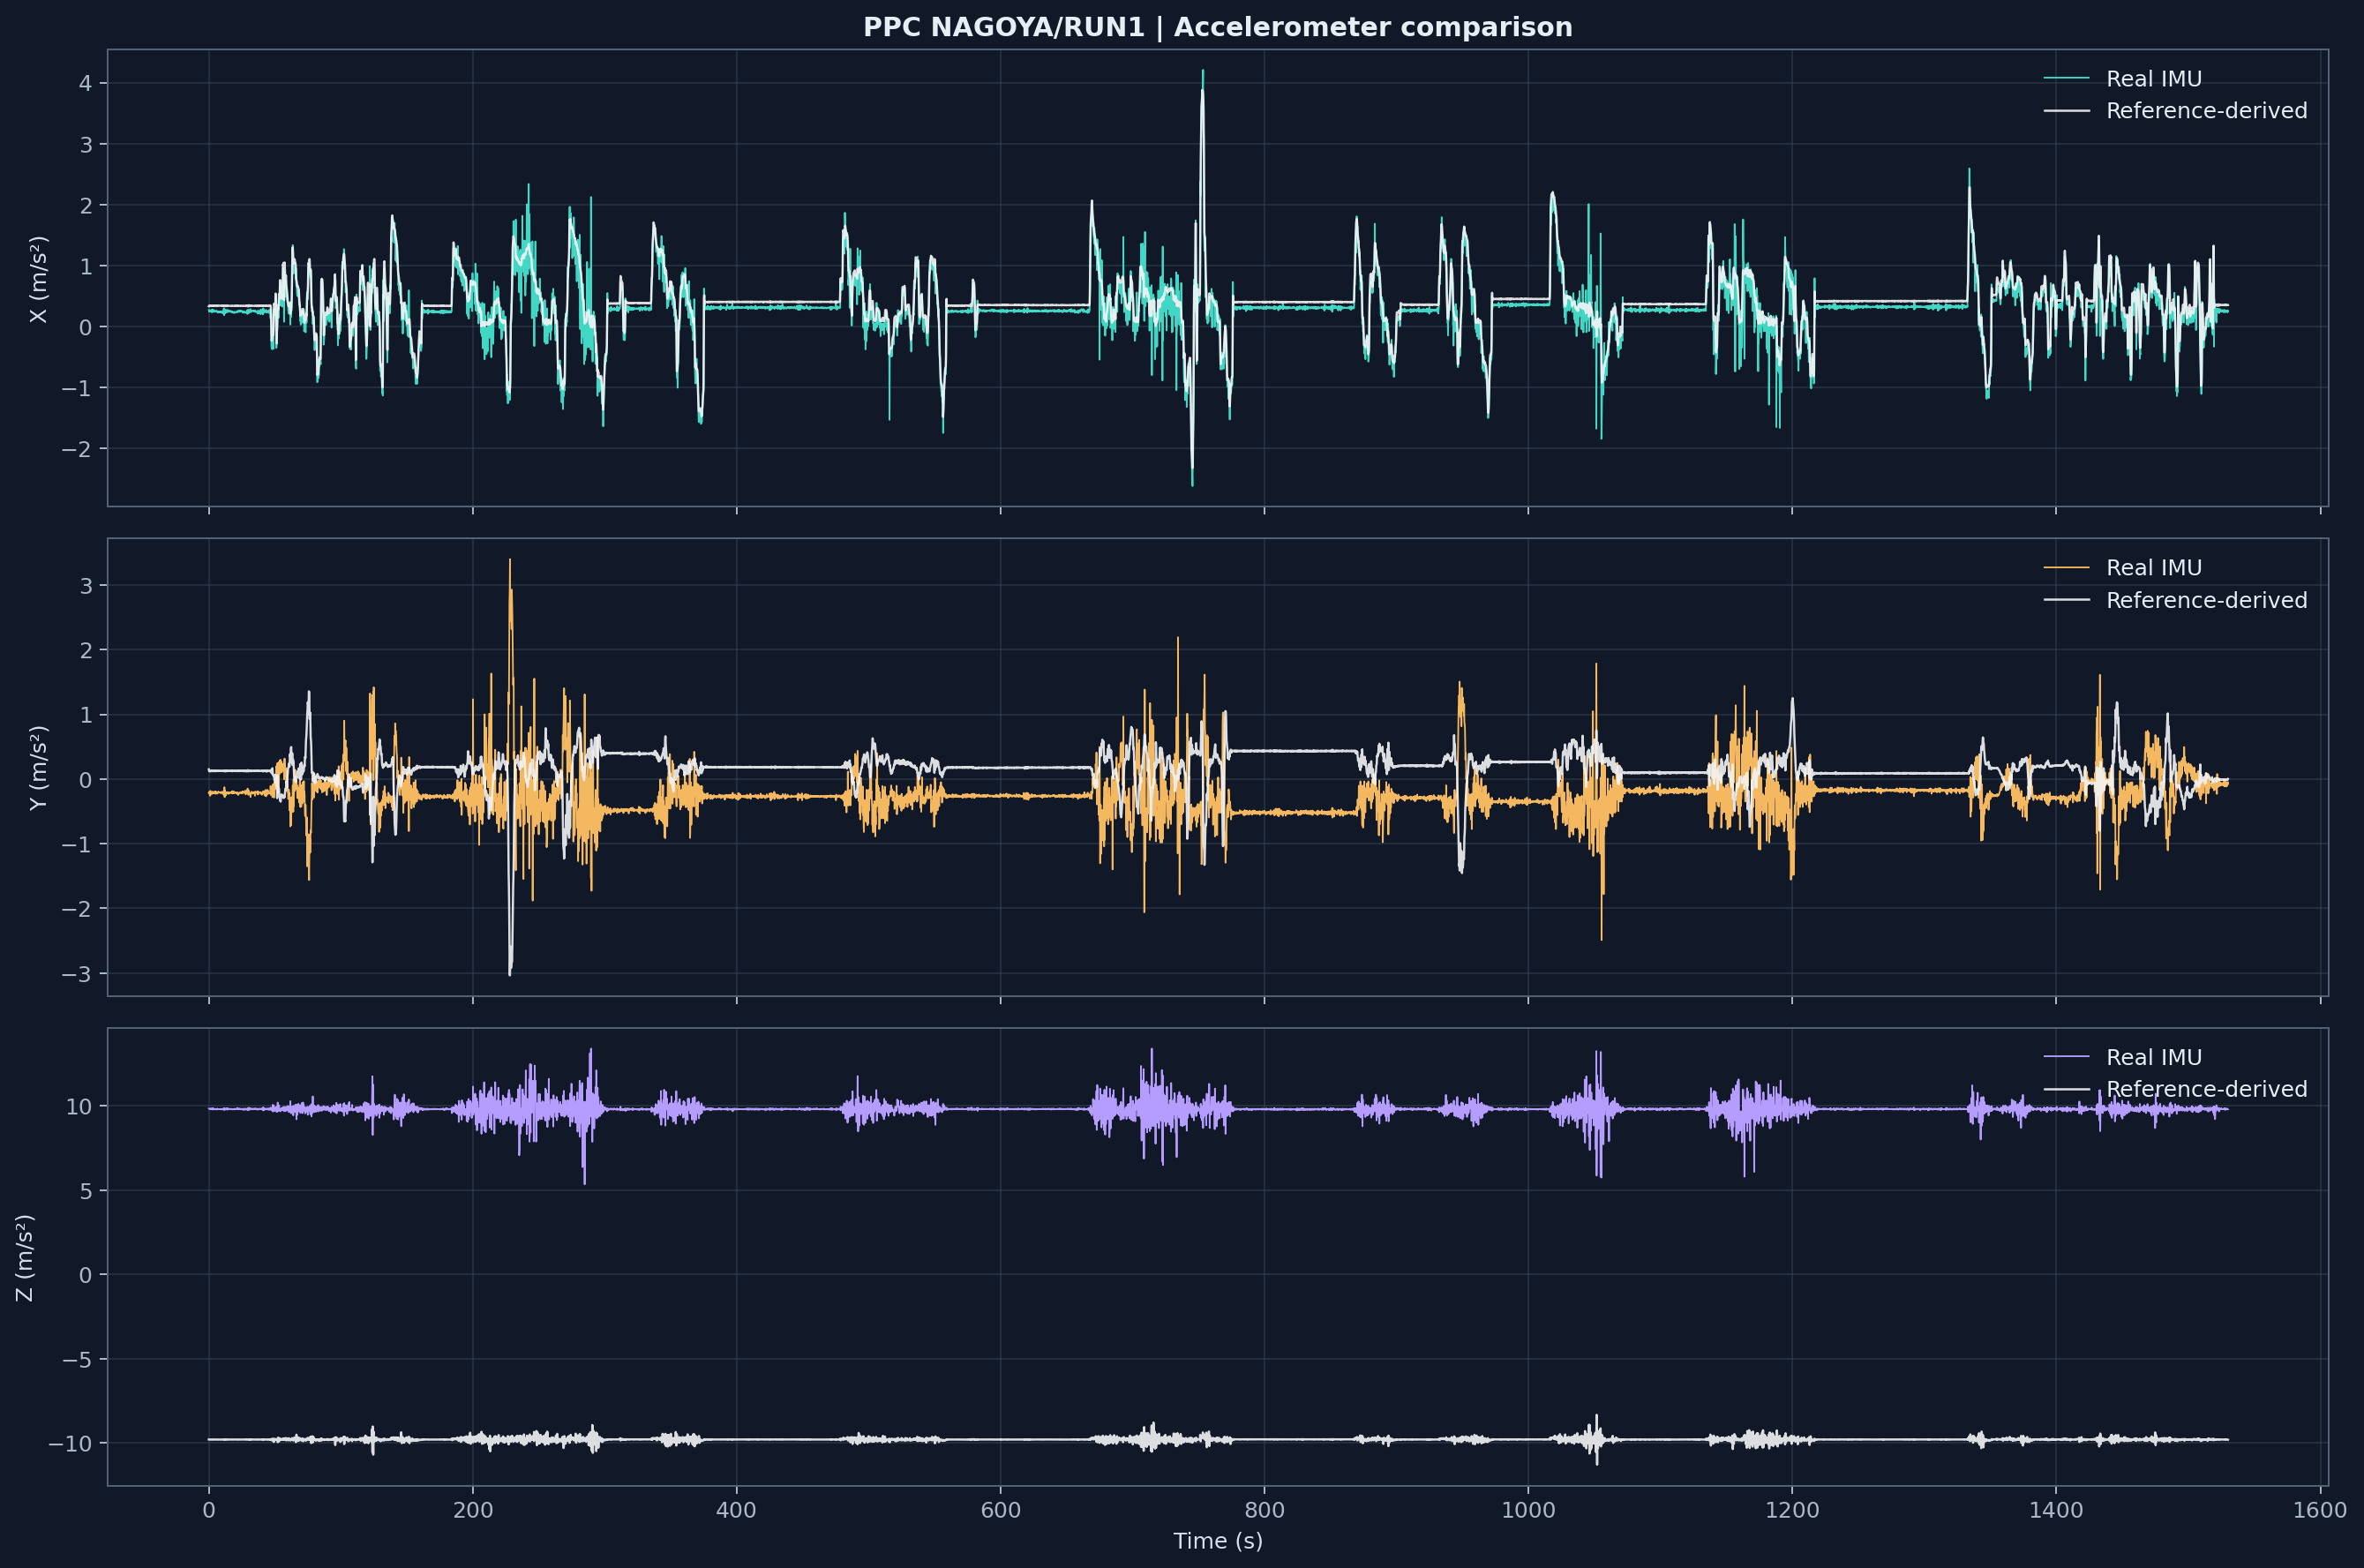


 02_gyroscope_comparison.png


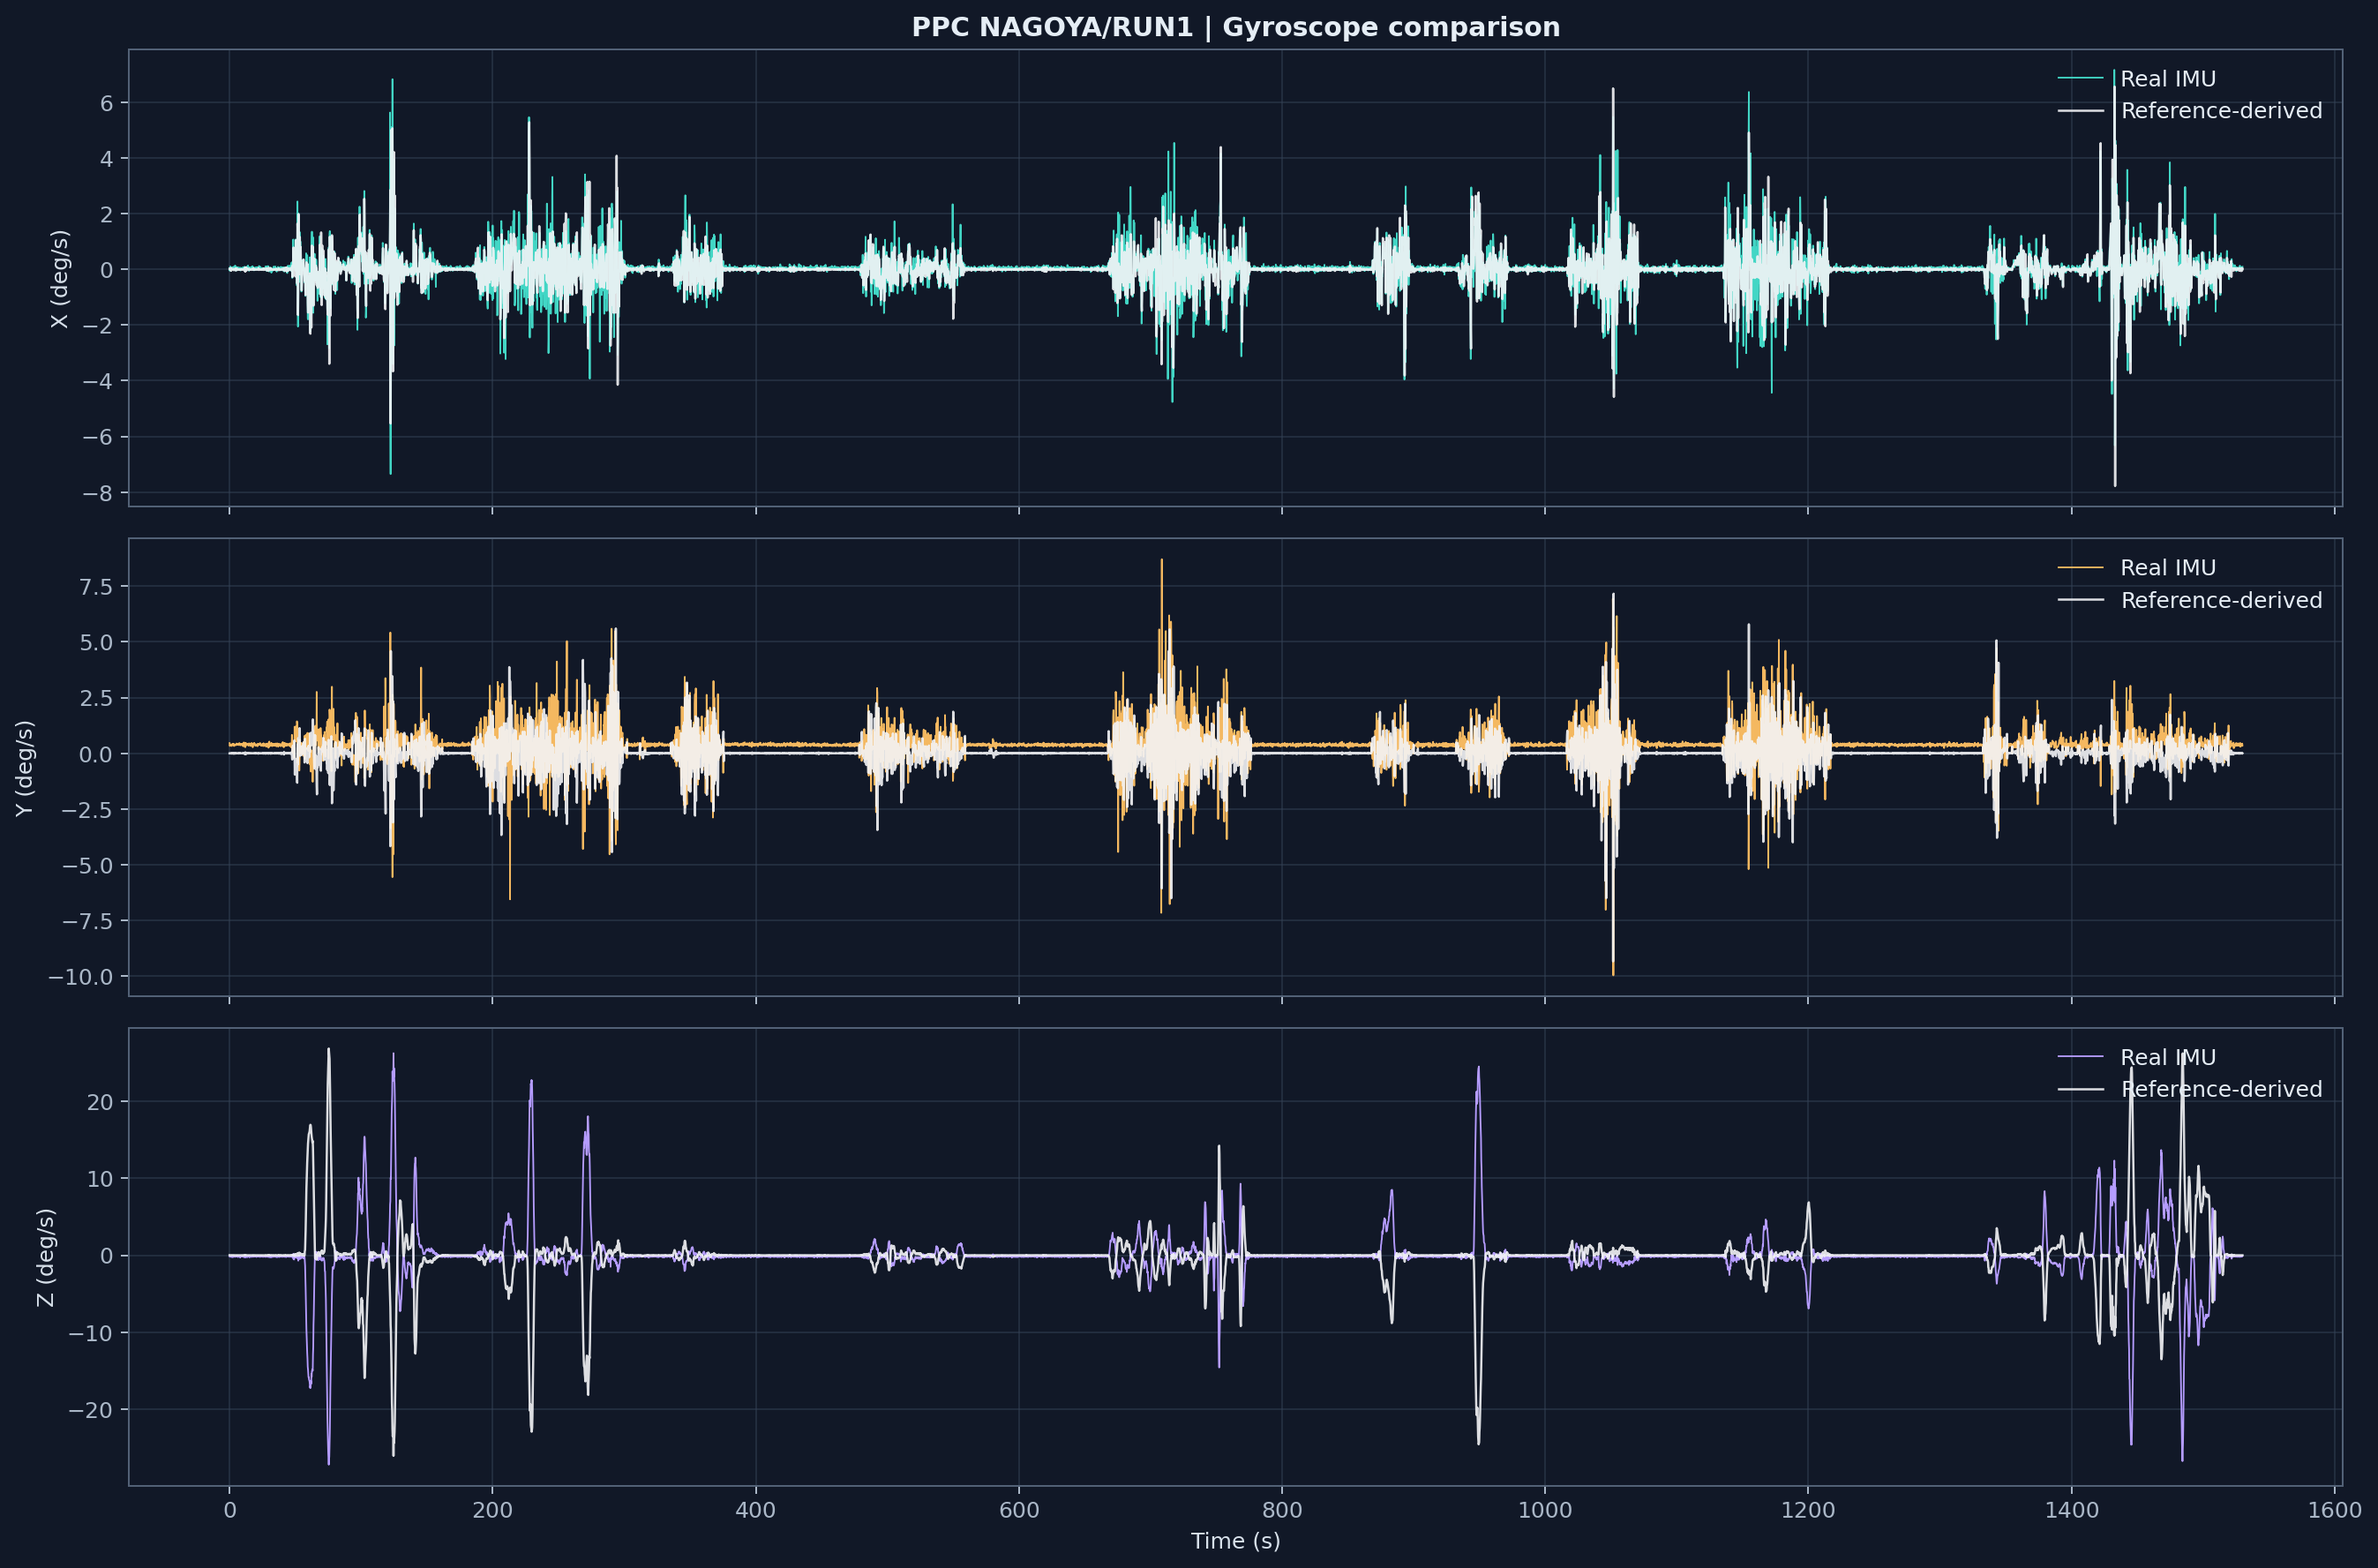


 03_reference_trajectory_enu.png


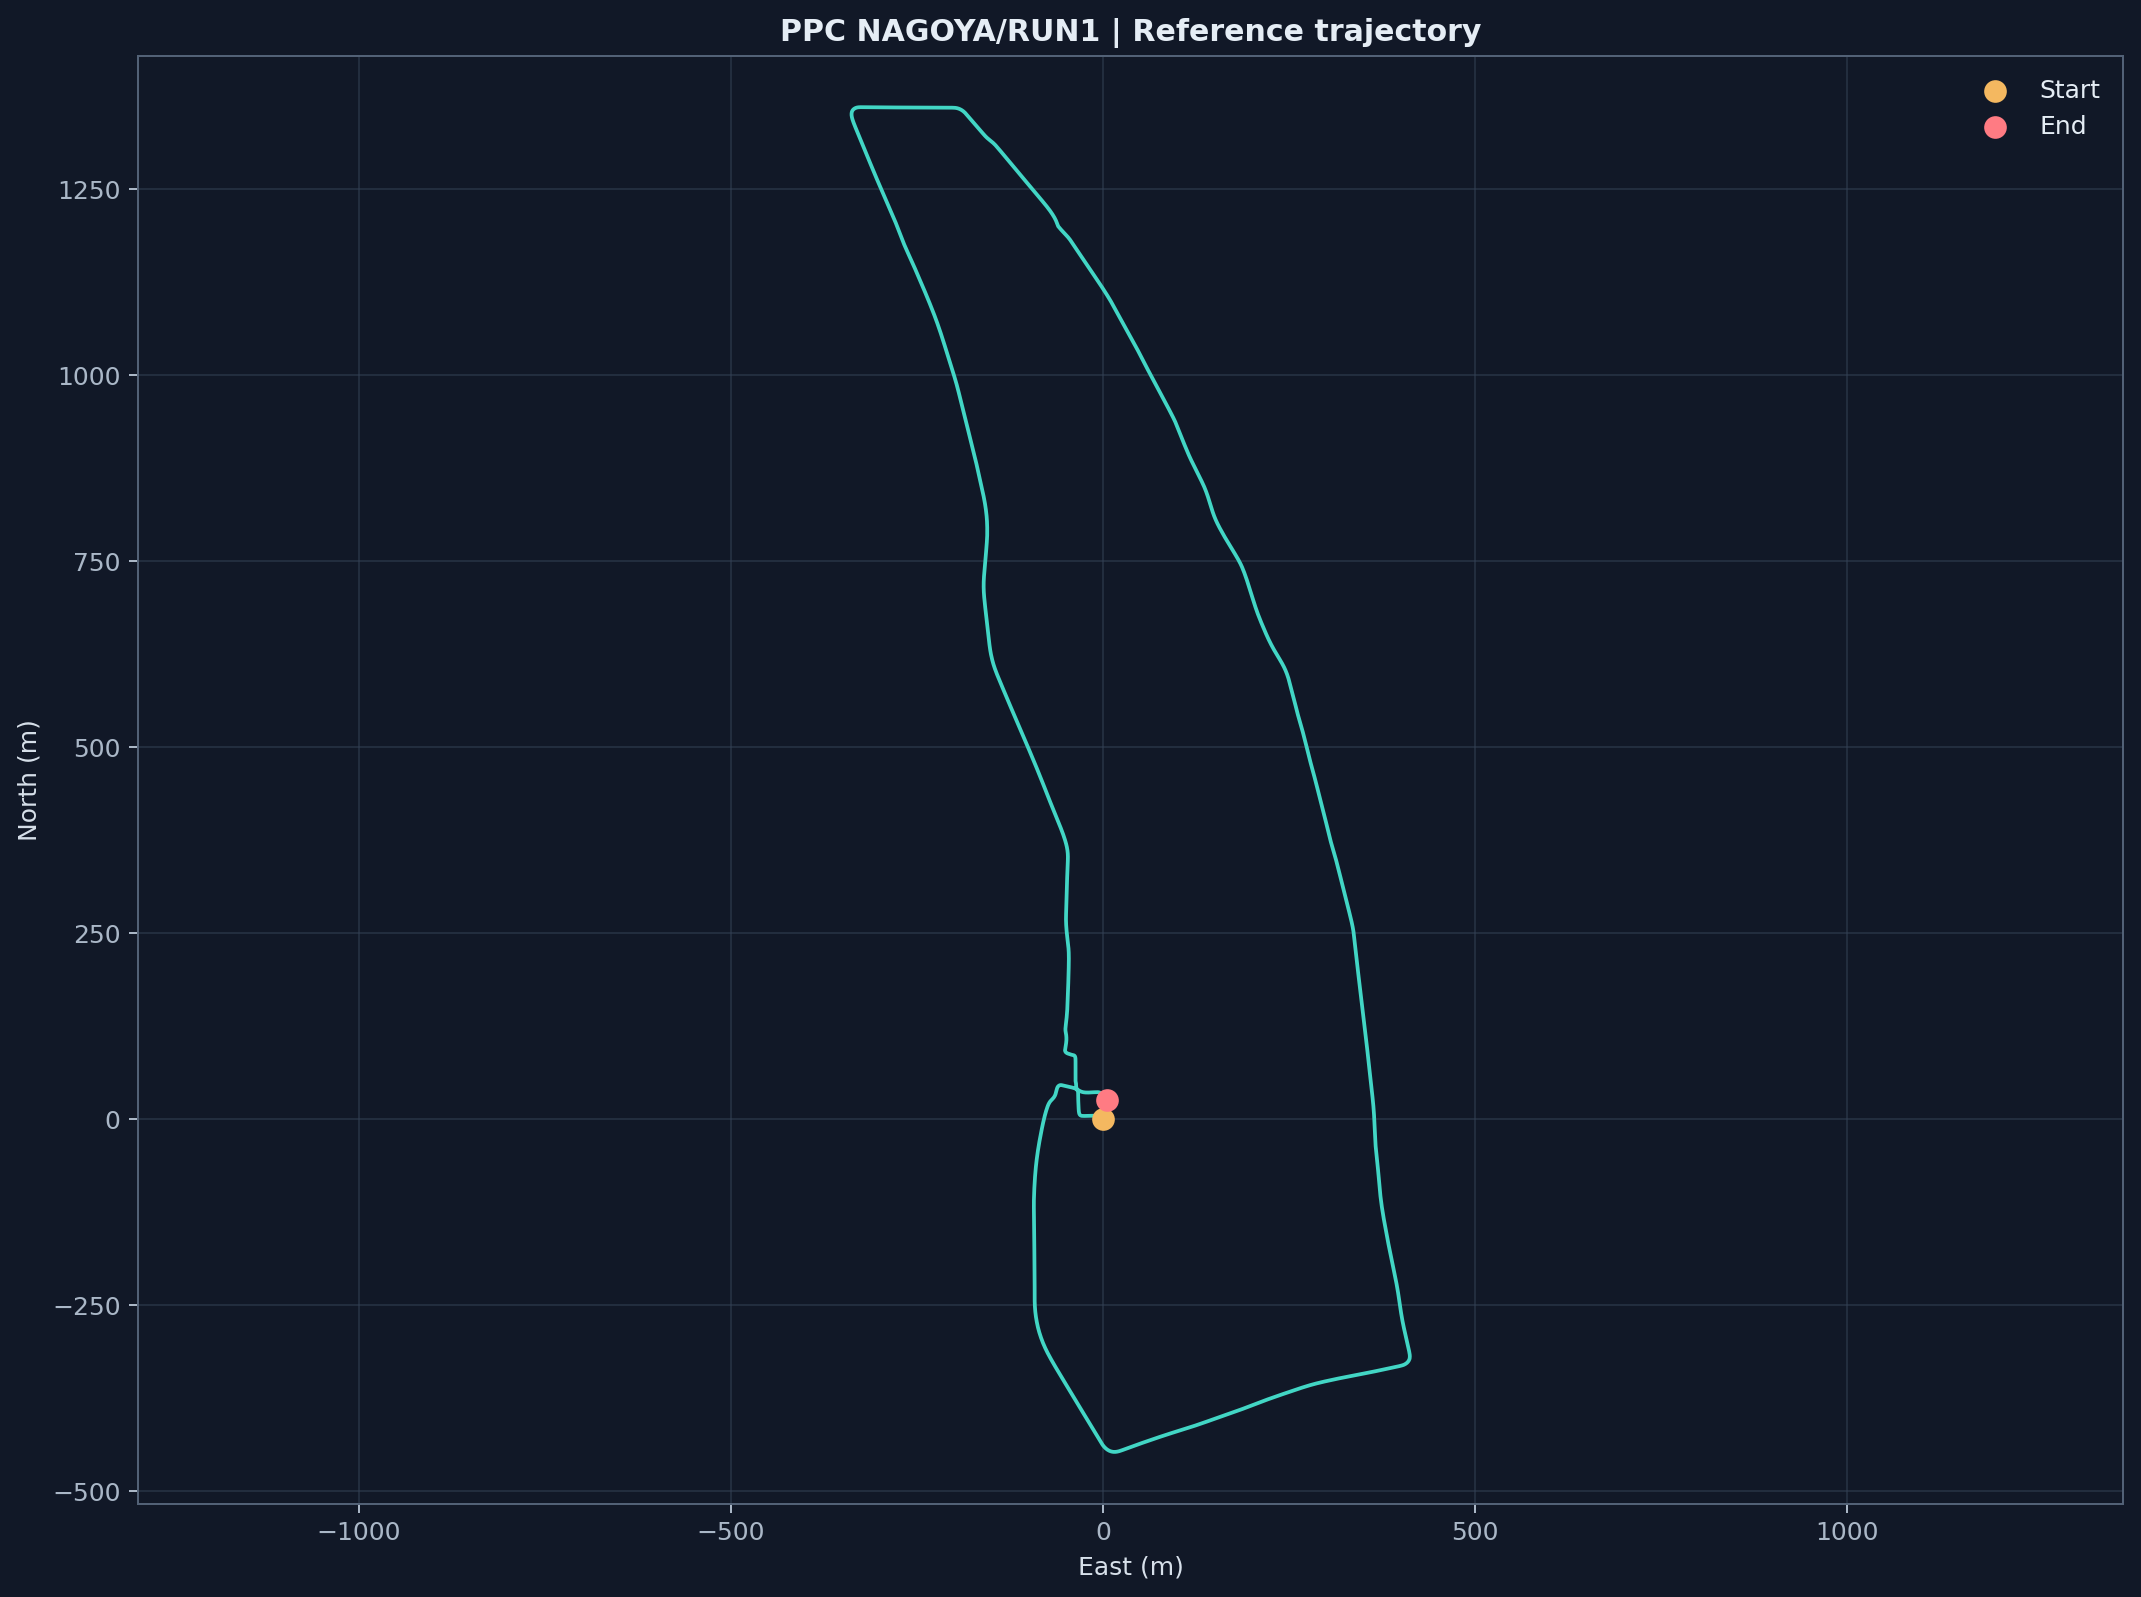


 04_reference_velocity.png


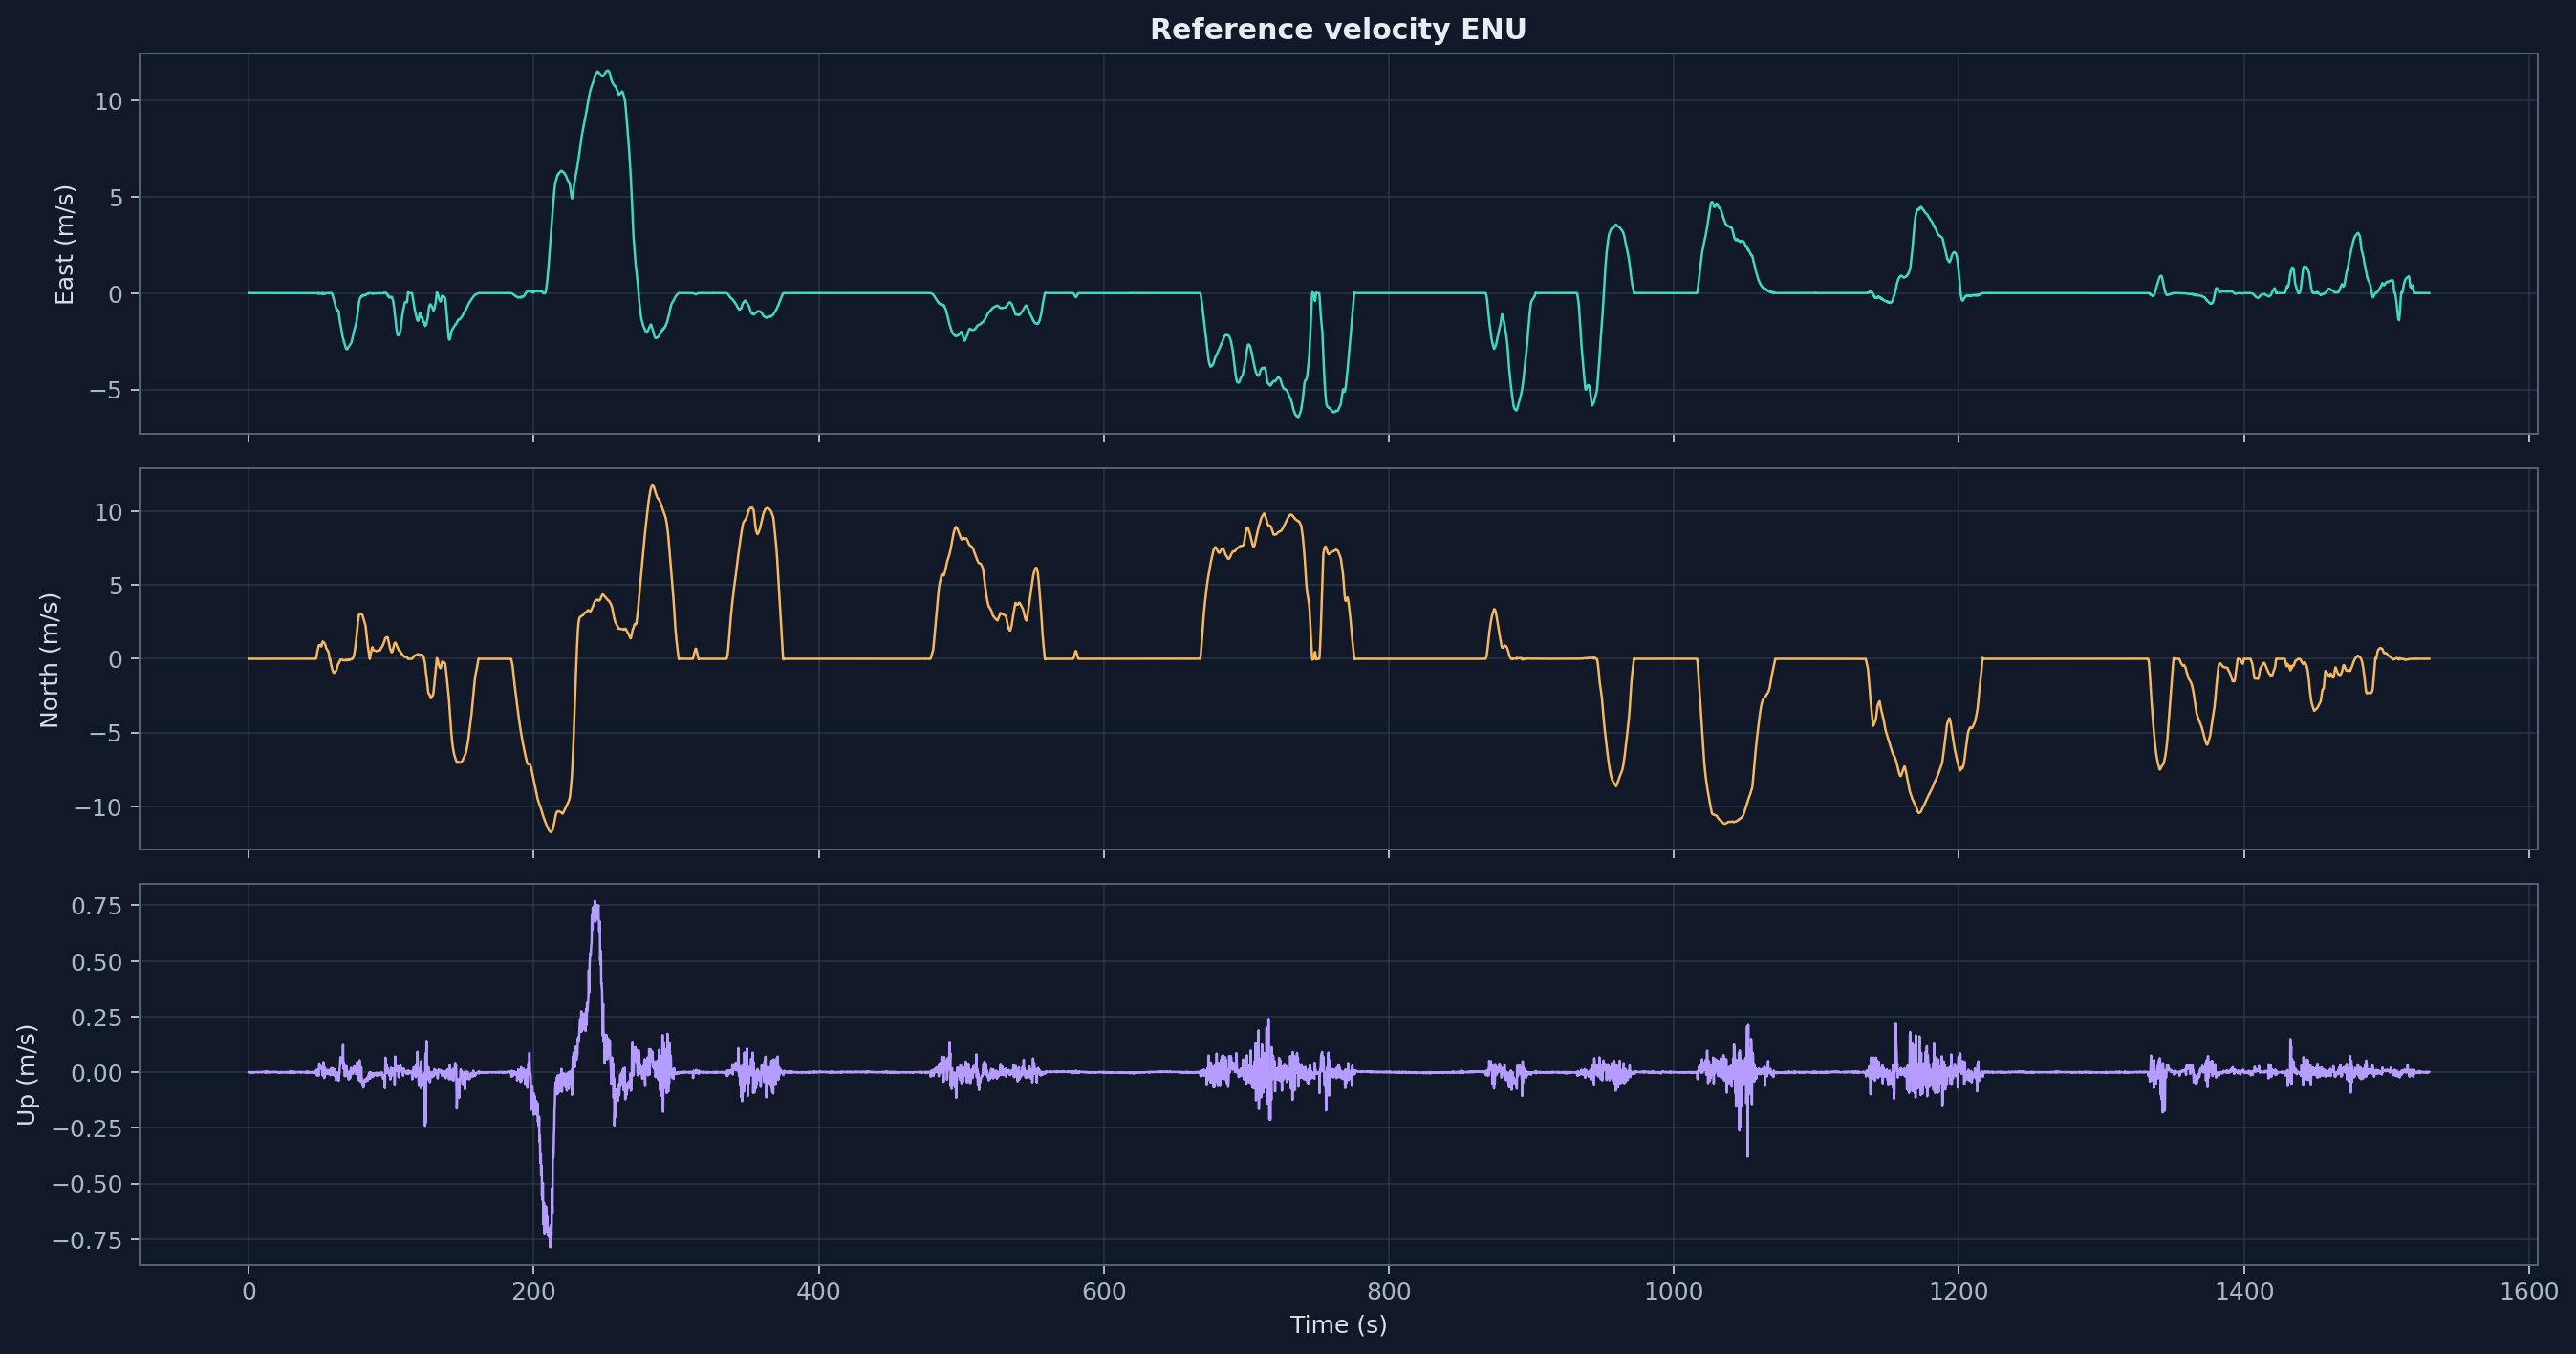


 05_sensor_residual_distributions.png


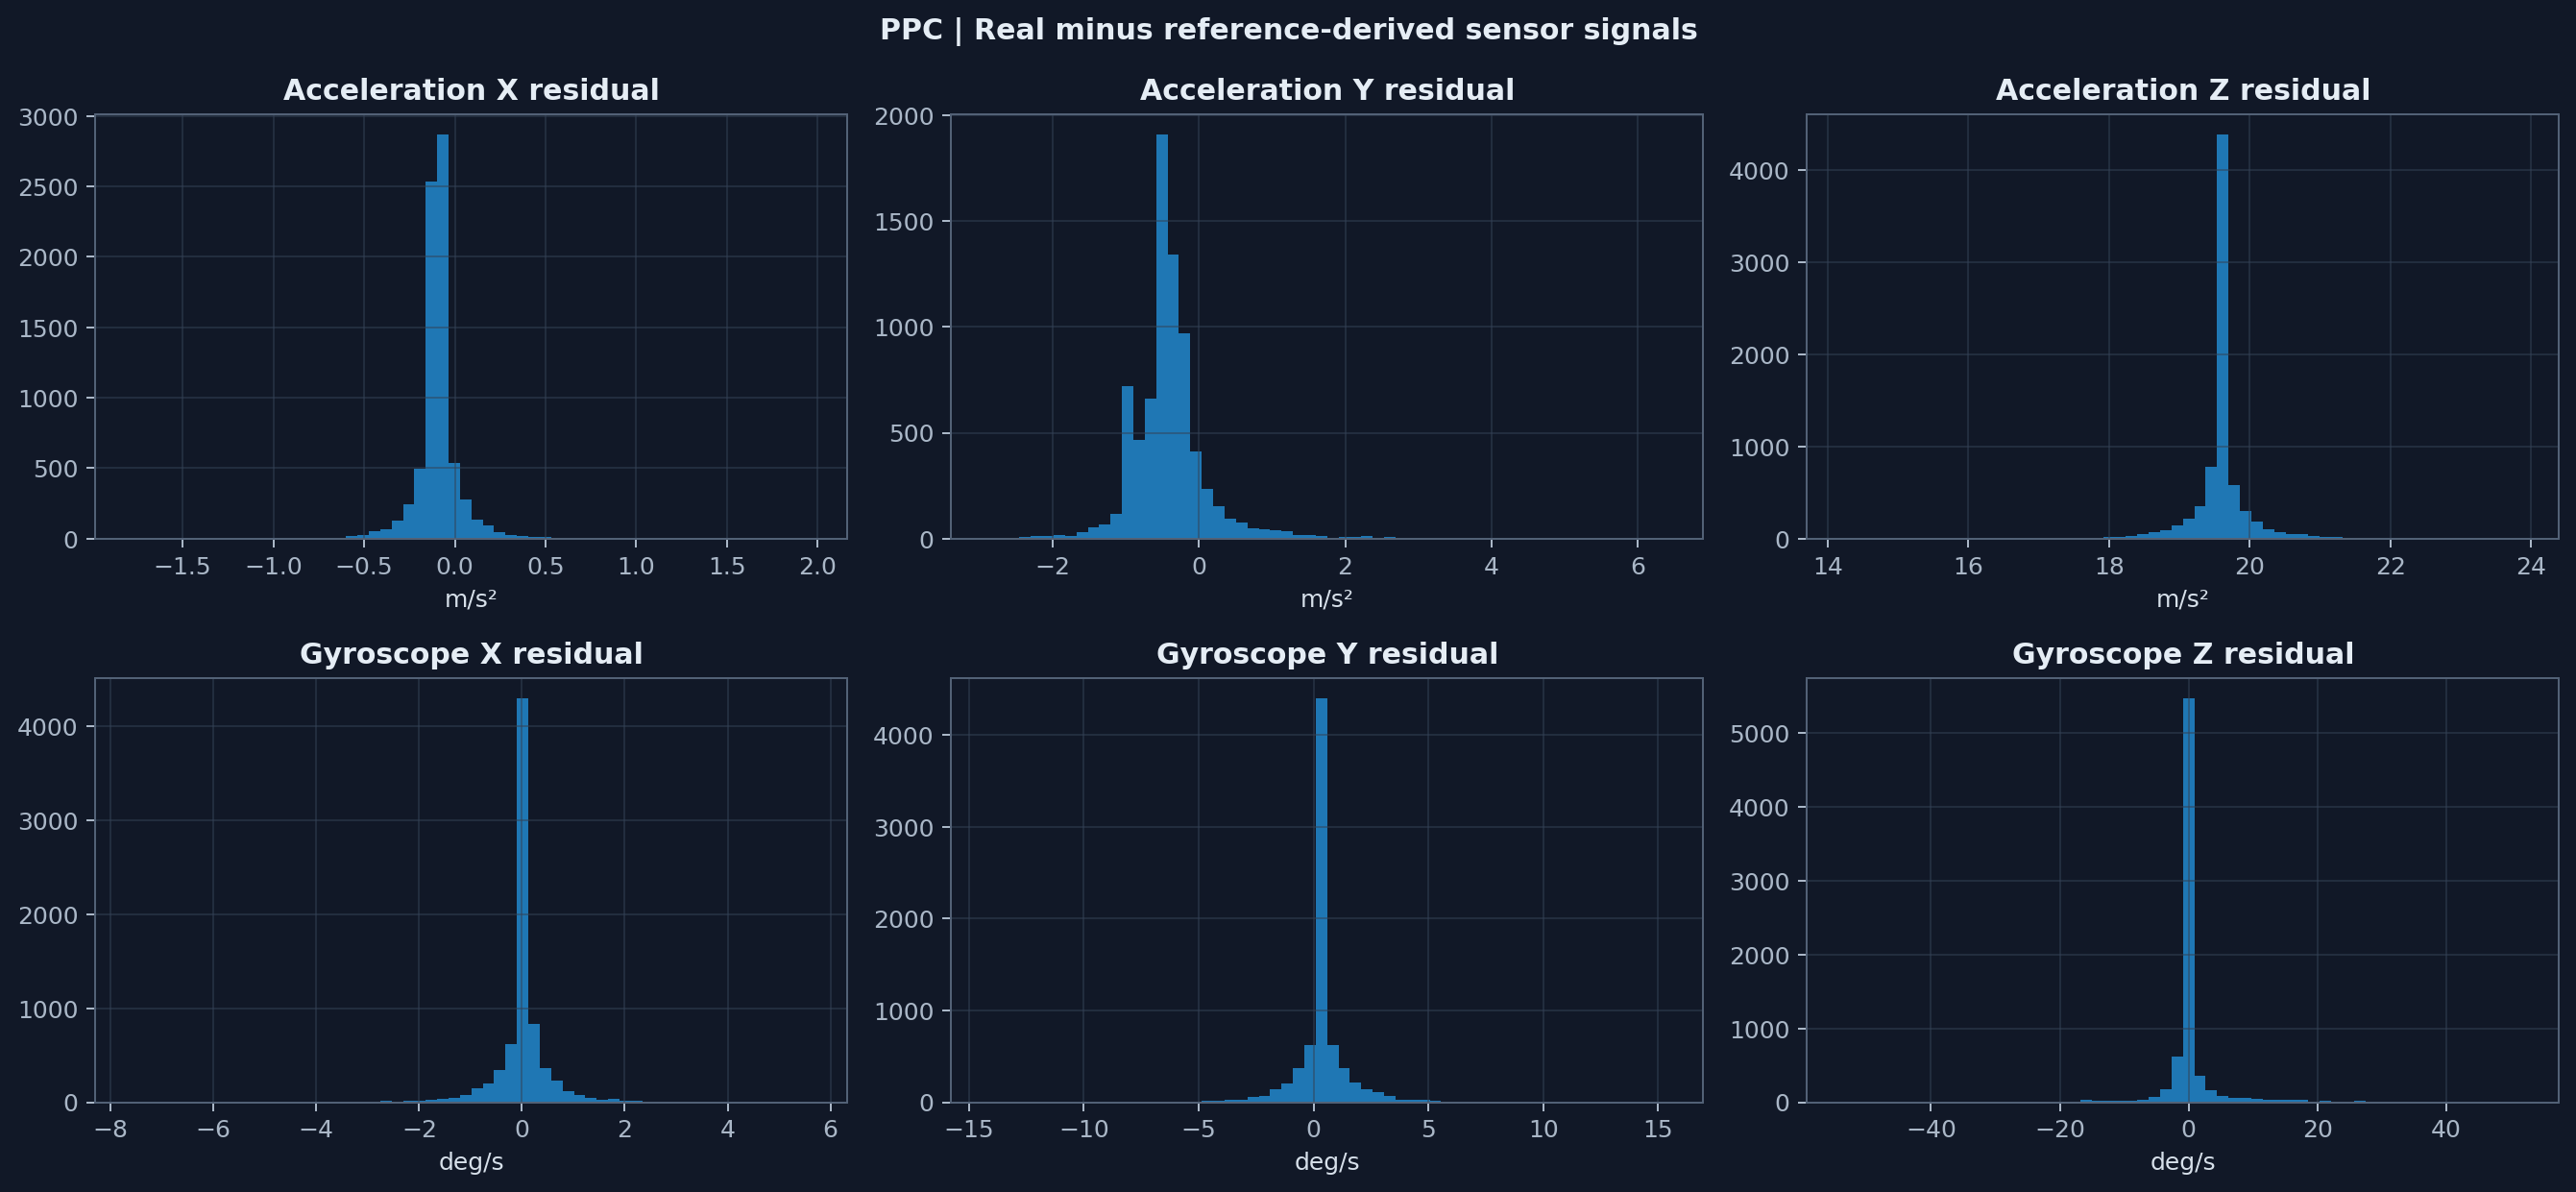


 06_reference_attitude.png


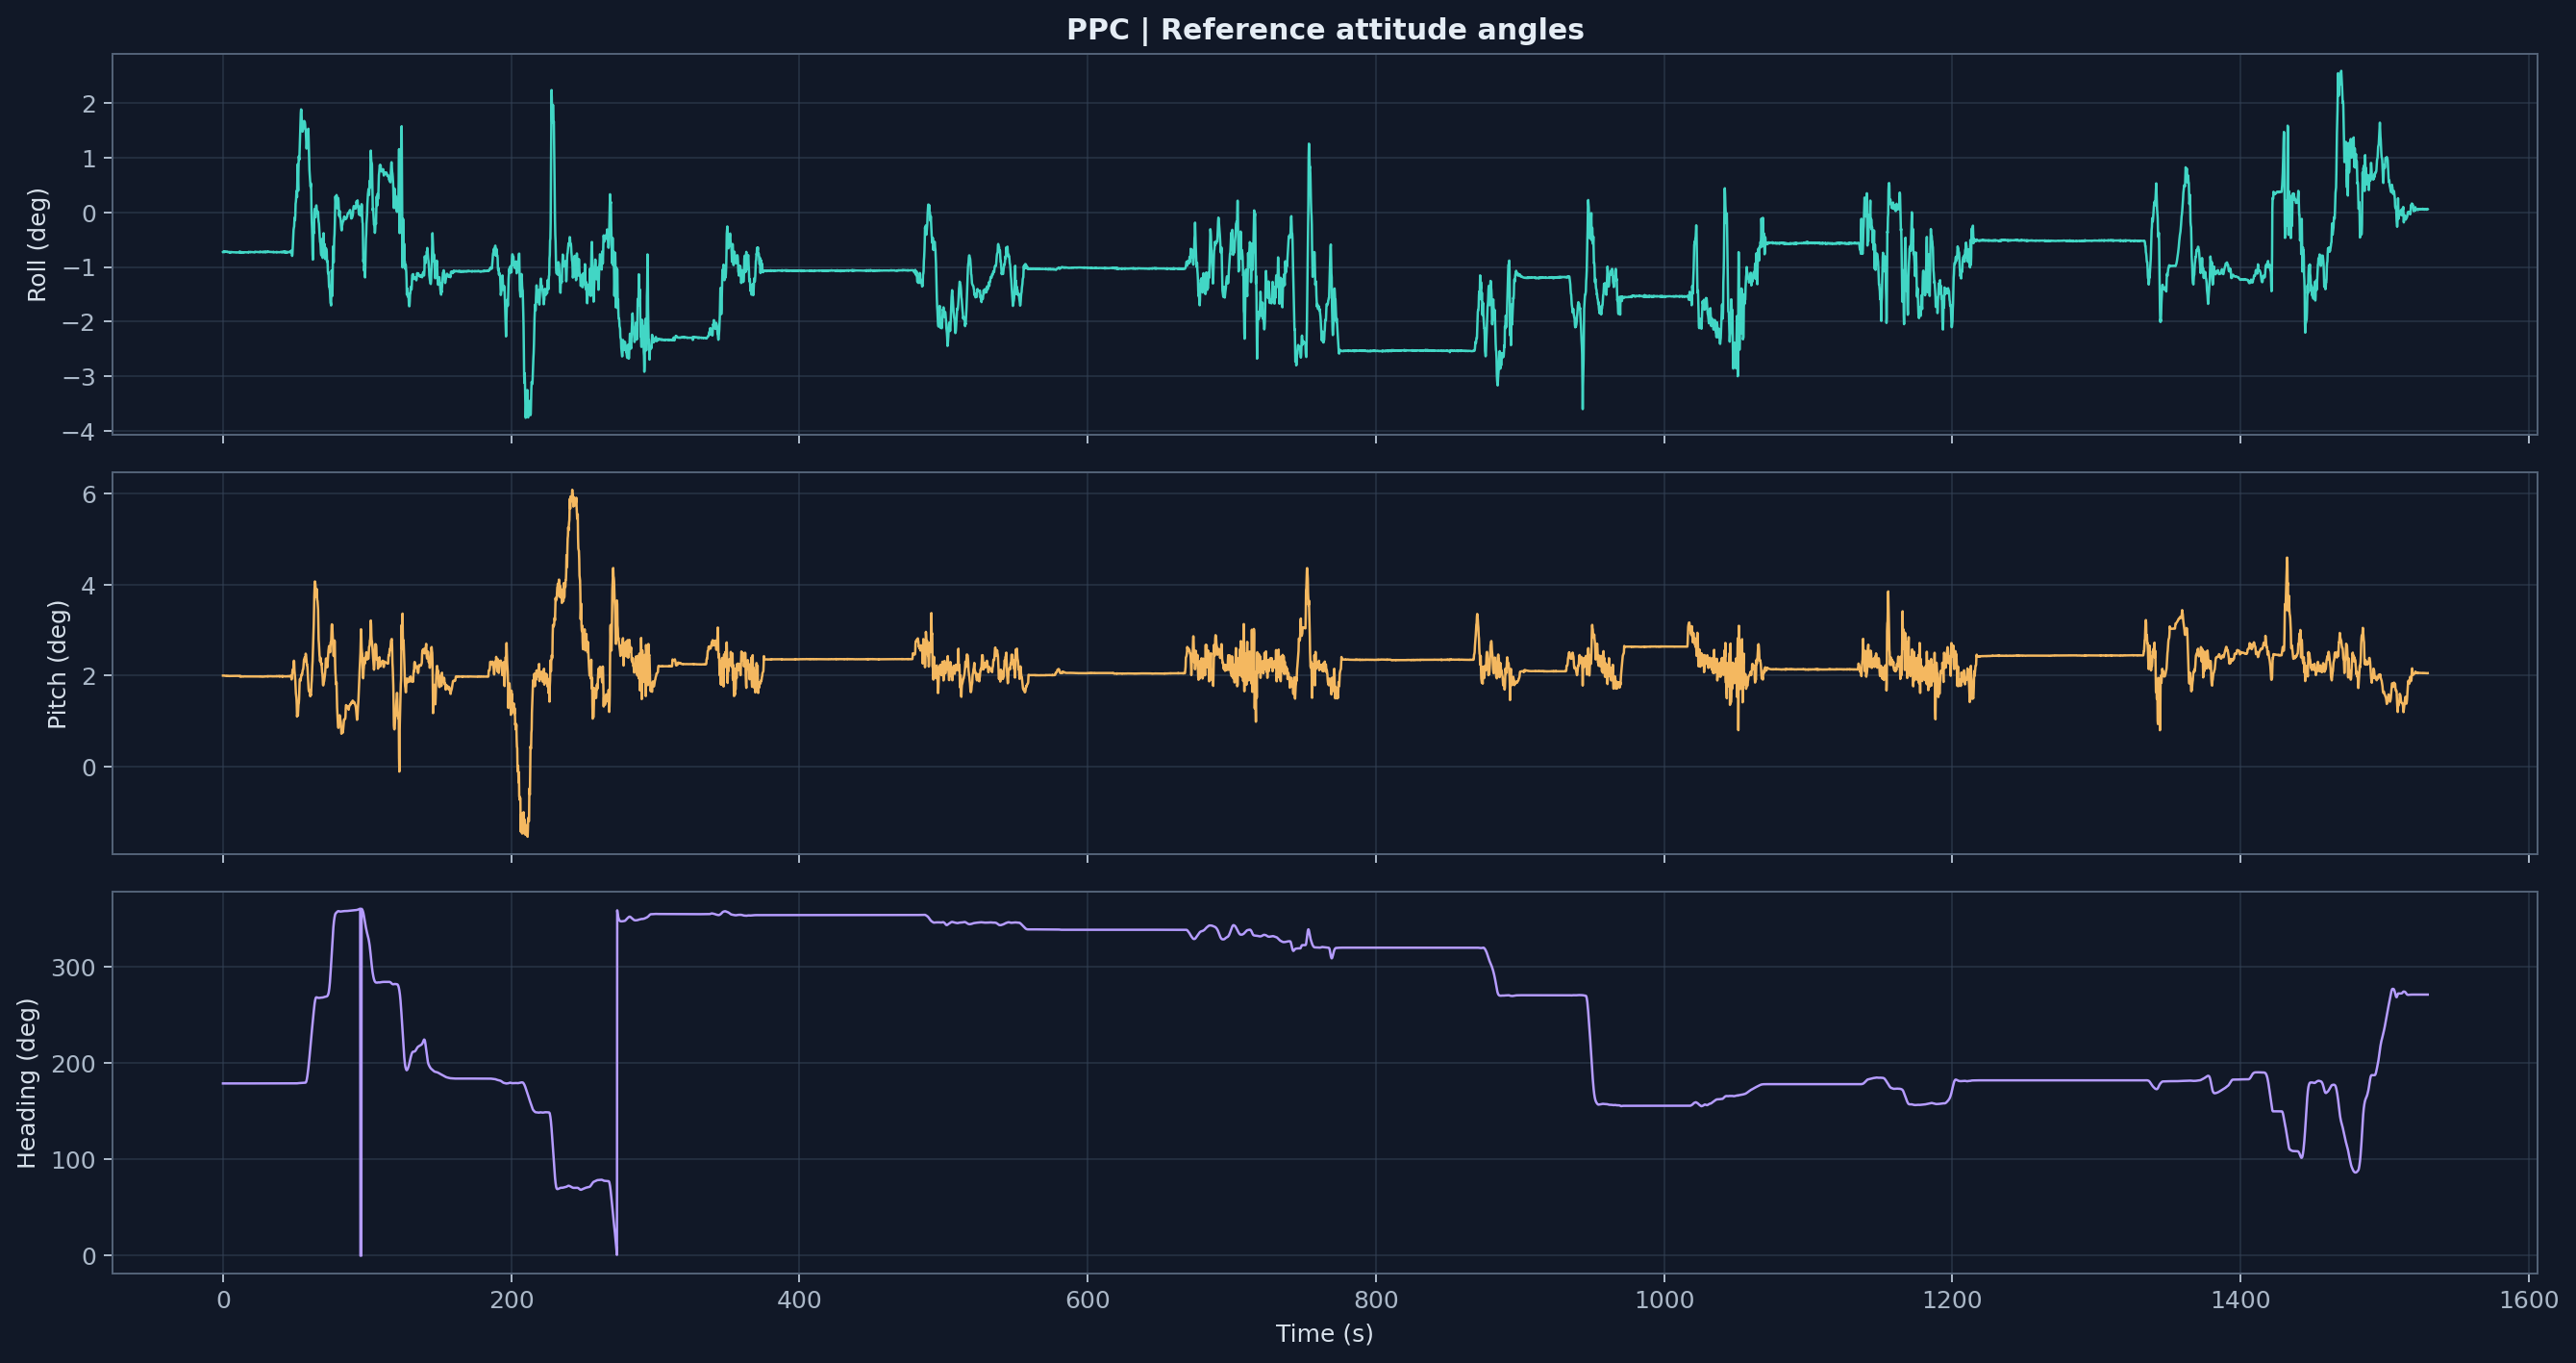


Visualização concluída.


In [ ]:


from pathlib import Path
from IPython.display import display, Image

OUT = Path("/content/vyra_ppc_frame_audit")

plots = [
    "01_accelerometer_comparison.png",
    "02_gyroscope_comparison.png",
    "03_reference_trajectory_enu.png",
    "04_reference_velocity.png",
    "05_sensor_residual_distributions.png",
    "06_reference_attitude.png"
]

print("VYRA | PPC FRAME AUDIT — VISUAL REPORT")
print("=" * 55)

for filename in plots:
    path = OUT / filename

    if not path.exists():
        print("[MISSING]", filename)
        continue

    print("\n", filename)
    display(Image(filename=str(path)))

print("\nVisualização concluída.")

In [ ]:


# ======================================================================
# ARQTECH LABS | VYRA
# PPC FRAME AUDIT v1.2 — ENGINEERING VERIFICATION
#
# Objetivo:
#   1. Confirmar schema e integridade temporal.
#   2. Aplicar a montagem FRD documentada pelo PPC.
#   3. Auditar a transformação FRD -> NED -> ENU.
#   4. Comparar acelerômetro e giroscópio com a referência.
#   5. Registrar resíduos, métricas e evidências.
#
# RESTRIÇÕES:
#   - Não altera os dados originais.
#   - Não inverte eixos automaticamente.
#   - Não escolhe convenções por melhor correlação.
#   - Não aplica lever arm nesta etapa.
#   - Não executa ESKF, treinamento ou benchmark.
# ======================================================================

from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.transform import Rotation

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ----------------------------------------------------------------------
# 0. CONFIGURAÇÃO
# ----------------------------------------------------------------------

ROOT = Path("/content/vyra_real_vs_synthetic/dataset")
IMU_PATH = ROOT / "imu.csv"
REF_PATH = ROOT / "reference.csv"

OUT = Path("/content/vyra_ppc_frame_audit_v1_2")
OUT.mkdir(parents=True, exist_ok=True)

G = 9.80665

# Montagem declarada no README PPC:
# X = Forward, Y = Right, Z = Down
BODY_FRAME = "FRD"

# Transformação de navegação adotada para esta hipótese:
# NED = North, East, Down
# ENU = East, North, Up
C_NED_TO_ENU = np.array([
    [0., 1.,  0.],
    [1., 0.,  0.],
    [0., 0., -1.]
])

print("=" * 72)
print("ARQTECH LABS | VYRA — PPC FRAME AUDIT v1.2")
print("=" * 72)

if not IMU_PATH.exists() or not REF_PATH.exists():
    raise FileNotFoundError(
        f"Arquivos não encontrados.\nIMU: {IMU_PATH}\nREF: {REF_PATH}"
    )

# ----------------------------------------------------------------------
# 1. CARREGAMENTO
# ----------------------------------------------------------------------

imu = pd.read_csv(IMU_PATH)
ref = pd.read_csv(REF_PATH)

imu.columns = [str(c).strip() for c in imu.columns]
ref.columns = [str(c).strip() for c in ref.columns]

print("\n[1] DATASETS")
print("IMU:", imu.shape)
print("REF:", ref.shape)

# ----------------------------------------------------------------------
# 2. RESOLUÇÃO DE COLUNAS
# ----------------------------------------------------------------------

def norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def find_col(df, aliases, required=True):
    normalized = {norm(c): c for c in df.columns}

    for alias in aliases:
        a = norm(alias)
        if a in normalized:
            return normalized[a]

    for alias in aliases:
        a = norm(alias)
        matches = [c for c in df.columns if a in norm(c)]
        if len(matches) == 1:
            return matches[0]

    if required:
        raise KeyError(
            f"Coluna não encontrada. Aliases: {aliases}\n"
            f"Disponíveis: {list(df.columns)}"
        )
    return None

# IMU
C = {
    "imu_tow": find_col(imu, ["GPS TOW (s)", "GPS TOW"]),
    "imu_week": find_col(imu, ["GPS Week"], required=False),
    "ax": find_col(imu, ["Acc X (m/s^2)", "Acc X"]),
    "ay": find_col(imu, ["Acc Y (m/s^2)", "Acc Y"]),
    "az": find_col(imu, ["Acc Z (m/s^2)", "Acc Z"]),
    "gx": find_col(imu, ["Ang Rate X (deg/s)", "Ang Rate X"]),
    "gy": find_col(imu, ["Ang Rate Y (deg/s)", "Ang Rate Y"]),
    "gz": find_col(imu, ["Ang Rate Z (deg/s)", "Ang Rate Z"]),
}

# Referência
R = {
    "ref_tow": find_col(ref, ["GPS TOW (s)", "GPS TOW"]),
    "ref_week": find_col(ref, ["GPS Week"], required=False),
    "roll": find_col(ref, ["Roll (deg)", "Roll"]),
    "pitch": find_col(ref, ["Pitch (deg)", "Pitch"]),
    "heading": find_col(ref, ["Heading (deg)", "Heading"]),
    "ve": find_col(ref, ["Velocity East (m/s)", "Vel East", "East Velocity"]),
    "vn": find_col(ref, ["Velocity North (m/s)", "Vel North", "North Velocity"]),
    "vu": find_col(ref, ["Velocity Up (m/s)", "Vel Up", "Up Velocity"]),
}

print("[PASS] Mapeamento das colunas")

# ----------------------------------------------------------------------
# 3. TEMPO GPS
# ----------------------------------------------------------------------

def gps_seconds(df, tow_col, week_col):
    tow = pd.to_numeric(df[tow_col], errors="coerce").to_numpy()

    if week_col:
        week = pd.to_numeric(df[week_col], errors="coerce").to_numpy()
        return week * 604800.0 + tow

    return tow

t_imu = gps_seconds(imu, C["imu_tow"], C["imu_week"])
t_ref = gps_seconds(ref, R["ref_tow"], R["ref_week"])

if not np.isfinite(t_imu).all() or not np.isfinite(t_ref).all():
    raise ValueError("Tempo GPS contém valores inválidos.")

if np.any(np.diff(t_imu) <= 0) or np.any(np.diff(t_ref) <= 0):
    raise ValueError("Tempo GPS não é estritamente crescente.")

dt_imu = np.median(np.diff(t_imu))
dt_ref = np.median(np.diff(t_ref))

fs_imu = 1.0 / dt_imu
fs_ref = 1.0 / dt_ref

start = max(t_imu[0], t_ref[0])
end = min(t_imu[-1], t_ref[-1])

if end <= start:
    raise ValueError("Não existe intervalo temporal comum.")

mask = (t_ref >= start) & (t_ref <= end)

ref = ref.loc[mask].reset_index(drop=True)
t_ref = t_ref[mask]

# Tempo relativo para estabilidade numérica
ti = t_imu - start
tr = t_ref - start

duration = tr[-1] - tr[0]

print("\n[2] TEMPORAL")
print(f"IMU frequency: {fs_imu:.4f} Hz")
print(f"REF frequency: {fs_ref:.4f} Hz")
print(f"Overlap: {duration:.2f} s")
print(f"IMU samples: {len(imu)}")
print(f"REF aligned samples: {len(ref)}")

# ----------------------------------------------------------------------
# 4. EXTRAÇÃO DOS SINAIS
# ----------------------------------------------------------------------

def numeric(df, col):
    return pd.to_numeric(df[col], errors="coerce").to_numpy(dtype=float)

acc_raw = np.column_stack([
    numeric(imu, C["ax"]),
    numeric(imu, C["ay"]),
    numeric(imu, C["az"])
])

gyro_deg = np.column_stack([
    numeric(imu, C["gx"]),
    numeric(imu, C["gy"]),
    numeric(imu, C["gz"])
])

gyro_raw = np.deg2rad(gyro_deg)

vel_enu = np.column_stack([
    numeric(ref, R["ve"]),
    numeric(ref, R["vn"]),
    numeric(ref, R["vu"])
])

roll = np.deg2rad(numeric(ref, R["roll"]))
pitch = np.deg2rad(numeric(ref, R["pitch"]))
heading = np.deg2rad(numeric(ref, R["heading"]))

if not all(np.isfinite(x).all() for x in [
    acc_raw, gyro_raw, vel_enu, roll, pitch, heading
]):
    raise ValueError("Dados numéricos contêm NaN ou infinito.")

# ----------------------------------------------------------------------
# 5. INTERPOLAÇÃO IMU -> ÉPOCAS DA REFERÊNCIA
# ----------------------------------------------------------------------

def interp_matrix(source_t, values, target_t):
    return np.column_stack([
        np.interp(target_t, source_t, values[:, i])
        for i in range(values.shape[1])
    ])

acc_meas = interp_matrix(ti, acc_raw, tr)
gyro_meas = interp_matrix(ti, gyro_raw, tr)

# ----------------------------------------------------------------------
# 6. ACELERAÇÃO DE REFERÊNCIA
# ----------------------------------------------------------------------

# Derivada da velocidade ENU.
# Não é uma medição independente: deriva da referência de trajetória.
acc_enu = np.gradient(vel_enu, tr, axis=0, edge_order=2)

gravity_enu = np.array([0.0, 0.0, -G])

# ----------------------------------------------------------------------
# 7. MATRIZES DE ATITUDE — HIPÓTESE DOCUMENTADA
# ----------------------------------------------------------------------

def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([
        [1, 0, 0],
        [0, c, -s],
        [0, s, c]
    ])

def Ry(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([
        [c, 0, s],
        [0, 1, 0],
        [-s, 0, c]
    ])

def Rz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([
        [c, -s, 0],
        [s, c, 0],
        [0, 0, 1]
    ])

# Hipótese:
# heading positivo horário a partir do Norte;
# roll/pitch na sequência Rz(heading) Ry(pitch) Rx(roll);
# matriz resultante corpo FRD -> NED.
#
# Esta convenção ainda precisa ser confirmada no manual da referência.

C_body_to_enu = []

for r, p, h in zip(roll, pitch, heading):
    C_b_ned = Rz(h) @ Ry(p) @ Rx(r)
    C_b_enu = C_NED_TO_ENU @ C_b_ned
    C_body_to_enu.append(C_b_enu)

C_body_to_enu = np.asarray(C_body_to_enu)

# Verificação matemática das matrizes
orth_errors = []
det_errors = []

for mat in C_body_to_enu:
    orth_errors.append(
        np.linalg.norm(mat.T @ mat - np.eye(3), ord="fro")
    )
    det_errors.append(abs(np.linalg.det(mat) - 1.0))

max_orth_error = float(np.max(orth_errors))
max_det_error = float(np.max(det_errors))

if max_orth_error > 1e-8 or max_det_error > 1e-8:
    raise ValueError("Matrizes de rotação inválidas.")

print("\n[3] ROTATION MATRICES")
print("Max orthogonality error:", max_orth_error)
print("Max determinant error:", max_det_error)
print("[PASS] Matrizes SO(3) numericamente válidas")

# ----------------------------------------------------------------------
# 8. FORÇA ESPECÍFICA ESPERADA NO CORPO
# ----------------------------------------------------------------------

# a_nav = C_b_n f_body + g_nav
# portanto:
# f_body = C_b_n.T (a_nav - g_nav)

specific_force_enu = acc_enu - gravity_enu

acc_expected = np.einsum(
    "nij,nj->ni",
    np.transpose(C_body_to_enu, (0, 2, 1)),
    specific_force_enu
)

# ----------------------------------------------------------------------
# 9. VELOCIDADE ANGULAR ESPERADA
# ----------------------------------------------------------------------

# Rotação relativa entre matrizes corpo->ENU consecutivas.
# O vetor de rotação incremental é expresso no corpo anterior.
rotations = Rotation.from_matrix(C_body_to_enu)

relative_rotations = (
    rotations[:-1].inv() * rotations[1:]
)

gyro_expected = (
    relative_rotations.as_rotvec() /
    np.diff(tr)[:, None]
)

# Associar cada incremento ao ponto médio temporal
t_gyro = (tr[:-1] + tr[1:]) / 2

gyro_meas_mid = interp_matrix(tr, gyro_meas, t_gyro)

# ----------------------------------------------------------------------
# 10. MÉTRICAS
# ----------------------------------------------------------------------

def metrics(measured, expected):
    rows = []

    for i, axis in enumerate(["X", "Y", "Z"]):
        x = measured[:, i]
        y = expected[:, i]

        valid = np.isfinite(x) & np.isfinite(y)
        x, y = x[valid], y[valid]

        if len(x) < 10:
            raise ValueError("Amostras insuficientes para métricas.")

        corr = np.corrcoef(x, y)[0, 1]

        slope = (
            np.polyfit(y, x, 1)[0]
            if np.std(y) > 1e-10 else np.nan
        )

        residual = x - y

        rows.append({
            "axis": axis,
            "correlation": float(corr),
            "slope_measured_vs_expected": float(slope),
            "bias": float(np.mean(residual)),
            "rmse": float(np.sqrt(np.mean(residual ** 2))),
            "residual_std": float(np.std(residual))
        })

    return rows

acc_metrics = metrics(acc_meas, acc_expected)
gyro_metrics = metrics(gyro_meas_mid, gyro_expected)

# ----------------------------------------------------------------------
# 11. ESTATÍSTICAS BRUTAS E GRAVIDADE
# ----------------------------------------------------------------------

acc_norm = np.linalg.norm(acc_raw, axis=1)
gyro_norm = np.linalg.norm(gyro_raw, axis=1)

raw_stats = {
    "acceleration_axis_mean": np.mean(acc_raw, axis=0).tolist(),
    "acceleration_axis_std": np.std(acc_raw, axis=0).tolist(),
    "acceleration_norm_median": float(np.median(acc_norm)),
    "acceleration_norm_p95": float(np.percentile(acc_norm, 95)),
    "gyro_axis_mean_rad_s": np.mean(gyro_raw, axis=0).tolist(),
    "gyro_axis_std_rad_s": np.std(gyro_raw, axis=0).tolist(),
    "gyro_norm_median_rad_s": float(np.median(gyro_norm))
}

# ----------------------------------------------------------------------
# 12. TESTE DE LEVER ARM — SOMENTE REGISTRO DOCUMENTAL
# ----------------------------------------------------------------------

lever_arm_nagoya_body_m = [0.593, -0.670, -1.216]

lever_arm_status = (
    "DOCUMENTED_VALUE_AVAILABLE_BUT_NOT_APPLIED"
)

# Não sabemos ainda se reference.csv representa:
# - centro da IMU;
# - antena GNSS;
# - outro ponto de referência do sistema Applanix.
#
# Portanto não aplicar correção geométrica nesta versão.

# ----------------------------------------------------------------------
# 13. GRÁFICOS
# ----------------------------------------------------------------------

def save_comparison(measured, expected, labels, filename, ylabel):
    fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

    for i, axis in enumerate(["X", "Y", "Z"]):
        axes[i].plot(
            labels, expected[:, i],
            label="Expected from reference",
            linewidth=1.0
        )
        axes[i].plot(
            labels, measured[:, i],
            label="Measured IMU",
            linewidth=0.8,
            alpha=0.8
        )
        axes[i].set_ylabel(f"{axis} ({ylabel})")
        axes[i].grid(True, alpha=0.3)
        axes[i].legend(loc="upper right")

    axes[-1].set_xlabel("Time (s)")
    fig.suptitle(filename.replace("_", " "))
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=150)
    plt.close(fig)

save_comparison(
    acc_meas,
    acc_expected,
    tr,
    "01_accelerometer_v1_2.png",
    "m/s²"
)

save_comparison(
    gyro_meas_mid,
    gyro_expected,
    t_gyro,
    "02_gyroscope_v1_2.png",
    "rad/s"
)

# Trajetória ENU
fig, ax = plt.subplots(figsize=(9, 8))
ax.plot(vel_enu[:, 0] * 0 + np.cumsum(vel_enu[:, 0]) * np.median(np.diff(tr)),
        vel_enu[:, 1] * 0 + np.cumsum(vel_enu[:, 1]) * np.median(np.diff(tr)))
ax.set_title("Reference trajectory — integrated velocity preview")
ax.set_xlabel("East (relative m)")
ax.set_ylabel("North (relative m)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "03_trajectory_preview.png", dpi=150)
plt.close(fig)

# Velocidade
fig, ax = plt.subplots(figsize=(14, 5))
for i, label in enumerate(["East", "North", "Up"]):
    ax.plot(tr, vel_enu[:, i], label=label)
ax.set_title("Reference velocity — ENU")
ax.set_xlabel("Time (s)")
ax.set_ylabel("m/s")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "04_reference_velocity.png", dpi=150)
plt.close(fig)

# Resíduos
acc_residual = acc_meas - acc_expected
gyro_residual = gyro_meas_mid - gyro_expected

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, axis in enumerate(["X", "Y", "Z"]):
    axes[0, i].hist(acc_residual[:, i], bins=60)
    axes[0, i].set_title(f"Accel {axis} residual")
    axes[0, i].grid(True, alpha=0.2)

    axes[1, i].hist(gyro_residual[:, i], bins=60)
    axes[1, i].set_title(f"Gyro {axis} residual")
    axes[1, i].grid(True, alpha=0.2)

fig.tight_layout()
fig.savefig(OUT / "05_residual_distributions.png", dpi=150)
plt.close(fig)

# Atitude
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

for ax, values, label in zip(
    axes,
    [roll, pitch, heading],
    ["Roll", "Pitch", "Heading"]
):
    ax.plot(tr, np.rad2deg(values))
    ax.set_ylabel(f"{label} (deg)")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")
fig.tight_layout()
fig.savefig(OUT / "06_reference_attitude.png", dpi=150)
plt.close(fig)

# ----------------------------------------------------------------------
# 14. RELATÓRIO
# ----------------------------------------------------------------------

report = {
    "project": "ARQTECH LABS | VYRA",
    "audit": "PPC Frame Audit v1.2",
    "status": "FRAME_AUDIT_REQUIRES_REVIEW",
    "execution_scope": {
        "data_modified": False,
        "training_executed": False,
        "eskf_executed": False,
        "benchmark_executed": False,
        "automatic_axis_flips": False,
        "lever_arm_applied": False
    },
    "dataset": {
        "imu_path": str(IMU_PATH),
        "reference_path": str(REF_PATH),
        "imu_samples": int(len(imu)),
        "reference_samples": int(len(ref)),
        "imu_frequency_hz": float(fs_imu),
        "reference_frequency_hz": float(fs_ref),
        "overlap_seconds": float(duration)
    },
    "documented_mounting": {
        "body_frame": BODY_FRAME,
        "x": "Forward",
        "y": "Right",
        "z": "Down",
        "source": "PPC Dataset README",
        "lever_arm_nagoya_body_m": lever_arm_nagoya_body_m,
        "lever_arm_status": lever_arm_status
    },
    "rotation_hypothesis": {
        "body_to_navigation": "Rz(heading) @ Ry(pitch) @ Rx(roll)",
        "navigation_conversion": "NED -> ENU",
        "heading_convention": "Clockwise from North — not yet independently confirmed",
        "rotation_validation": "PASS",
        "max_orthogonality_error": max_orth_error,
        "max_determinant_error": max_det_error
    },
    "raw_sensor_statistics": raw_stats,
    "accelerometer_metrics": acc_metrics,
    "gyroscope_metrics": gyro_metrics,
    "limitations": [
        "Euler convention has not been independently confirmed.",
        "Reference position physical origin has not been confirmed.",
        "Lever arm has not been applied.",
        "Reference acceleration is differentiated from 5 Hz velocity.",
        "Angular rates are derived from discrete reference attitude.",
        "Correlation is not proof of physical frame correctness.",
        "No automatic sign or axis correction was performed."
    ],
    "outputs": [
        "01_accelerometer_v1_2.png",
        "02_gyroscope_v1_2.png",
        "03_trajectory_preview.png",
        "04_reference_velocity.png",
        "05_residual_distributions.png",
        "06_reference_attitude.png"
    ]
}

report_path = OUT / "ppc_frame_audit_v1_2_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)

# ----------------------------------------------------------------------
# 15. RESUMO
# ----------------------------------------------------------------------

print("\n" + "=" * 72)
print("PPC FRAME AUDIT v1.2 | SUMMARY")
print("=" * 72)

print("\nRAW SENSOR STATISTICS")
print(json.dumps(raw_stats, indent=2))

print("\nACCELEROMETER")
print(pd.DataFrame(acc_metrics).to_string(index=False))

print("\nGYROSCOPE")
print(pd.DataFrame(gyro_metrics).to_string(index=False))

print("\nROTATION VALIDATION")
print("Orthogonality error:", max_orth_error)
print("Determinant error:", max_det_error)

print("\nLEVER ARM")
print("Nagoya:", lever_arm_nagoya_body_m)
print("Status:", lever_arm_status)

print("\nOUTPUT DIRECTORY:", OUT)
print("REPORT:", report_path)

print("\nSTATUS: FRAME_AUDIT_REQUIRES_REVIEW")
print("No automatic correction or ESKF execution.")
print("=" * 72)

ARQTECH LABS | VYRA — PPC FRAME AUDIT v1.2

[1] DATASETS
IMU: (153001, 8)
REF: (7651, 14)
[PASS] Mapeamento das colunas

[2] TEMPORAL
IMU frequency: 100.0001 Hz
REF frequency: 5.0000 Hz
Overlap: 1530.00 s
IMU samples: 153001
REF aligned samples: 7651

[3] ROTATION MATRICES
Max orthogonality error: 5.515410169596886e-16
Max determinant error: 6.661338147750939e-16
[PASS] Matrizes SO(3) numericamente válidas

PPC FRAME AUDIT v1.2 | SUMMARY

RAW SENSOR STATISTICS
{
  "acceleration_axis_mean": [
    0.29020122776974,
    -0.2438984135397621,
    9.797603892442071
  ],
  "acceleration_axis_std": [
    0.4939596969721912,
    0.3254410475993516,
    0.40303219428165227
  ],
  "acceleration_norm_median": 9.810031689462386,
  "acceleration_norm_p95": 10.371485372236044,
  "gyro_axis_mean_rad_s": [
    0.0006135823159374396,
    0.006651833224539949,
    0.00021650439717237915
  ],
  "gyro_axis_std_rad_s": [
    0.012372329825943804,
    0.014142594417359655,
    0.05854636596708791
  ],
  "gyr

In [ ]:


from pathlib import Path
import shutil
from google.colab import files

source = Path("/content/vyra_ppc_frame_audit_v1_2")

required = [
    "ppc_frame_audit_v1_2_report.json",
    "01_accelerometer_v1_2.png",
    "02_gyroscope_v1_2.png",
    "03_trajectory_preview.png",
    "04_reference_velocity.png",
    "05_residual_distributions.png",
    "06_reference_attitude.png",
]

missing = [f for f in required if not (source / f).exists()]

if missing:
    raise FileNotFoundError(f"Arquivos ausentes: {missing}")

archive = shutil.make_archive(
    "/content/ppc_frame_audit_v1_2_artifacts",
    "zip",
    root_dir=source
)

print("Pacote criado:", archive)
print("Arquivos:", len(required))

files.download(archive)

Pacote criado: /content/ppc_frame_audit_v1_2_artifacts.zip
Arquivos: 7


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
import shutil

from google.colab import drive

drive.mount("/content/drive")

source = Path("/content/ppc_frame_audit_v1_2_artifacts.zip")
destination = Path(
    "/content/drive/MyDrive/ppc_frame_audit_v1_2_artifacts.zip"
)

if not source.exists():
    raise FileNotFoundError(source)

shutil.copy2(source, destination)

print("PACOTE PRESERVADO NO GOOGLE DRIVE")
print("Arquivo:", destination)
print("Tamanho:", round(destination.stat().st_size / 1024 / 1024, 2), "MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PACOTE PRESERVADO NO GOOGLE DRIVE
Arquivo: /content/drive/MyDrive/ppc_frame_audit_v1_2_artifacts.zip
Tamanho: 1.04 MB


In [ ]:
from pathlib import Path
import shutil

from google.colab import drive

drive.mount("/content/drive")

# Localiza os notebooks disponíveis no ambiente
notebooks = list(Path("/content").glob("*.ipynb"))

print("NOTEBOOKS ENCONTRADOS:")
for i, notebook in enumerate(notebooks):
    print(f"[{i}] {notebook.name}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NOTEBOOKS ENCONTRADOS:
